In [ ]:
# 0.1 Settings: the notebook can be copied into any scenario folder
from pathlib import Path
import re
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

SCENARIO_DIR = Path.cwd()                              # folder containing this notebook
RUN_DIR  = SCENARIO_DIR / "model"                      # folder containing the results GDX
# Chronohour comparison within this folder: scenario = new CHRONOHOUR (1 h/step), base = old default (168/card(T))
RESULTS      = "MainResults_chrono.gdx"                # results file name of this scenario
BASE_RESULTS = "MainResults_refchrono.gdx"             # results file name of the base scenario
SCENARIO      = SCENARIO_DIR.name + "_chrono"          # scenario label
BASE_SCENARIO = SCENARIO_DIR.name + "_refchrono"       # base label

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from pybalmorel import MainResults
from IPython.display import display

res = MainResults(files=RESULTS, paths=str(RUN_DIR), scenario_names=[SCENARIO])

# Load the comparison/base results once; all later sections reuse base_res.
BASE_DIR = SCENARIO_DIR                                # base inputs (data/) live in this same folder
BASE_RESULTS_DIR = RUN_DIR                             # both GDX files live in model/
if not (BASE_RESULTS_DIR / BASE_RESULTS).exists():
    raise FileNotFoundError(f"Base scenario results {BASE_RESULTS} not found in {BASE_RESULTS_DIR}")
base_res = MainResults(files=BASE_RESULTS, paths=str(BASE_RESULTS_DIR), scenario_names=[BASE_SCENARIO])

In [3]:
# 0.2 Helpers shared by all sections

# pybalmorel returns some symbols with the raw GAMS column names; map them to one naming scheme
RENAME = {"Y": "Year", "C": "Country", "RRR": "Region", "AAA": "Area", "G": "Generation", "FFF": "Fuel",
          "TECH_TYPE": "Technology", "COMMODITY": "Commodity", "CATEGORY": "Category",
          "SUBCATEGORY": "Subcategory", "UNITS": "Unit"}

def get(symbol):
    """Result symbol for SCENARIO as a DataFrame with standard column names."""
    df = res.get_result(symbol).rename(columns=RENAME)
    return df[df["Scenario"] == SCENARIO]

# Technology types folded into groups (8 colours + grey for anything else)
TECH_GROUP = {
    "WIND-ON": "Wind-on", "WIND-OFF": "Wind-off",
    "SOLAR-PV": "Solar", "SOLAR-HEATING": "Solar",
    "HYDRO-RESERVOIRS": "Hydro", "HYDRO-RUN-OF-RIVER": "Hydro",
    "GNR_ST_NUCL_CND_E-33": "Nuclear",
    "GNR_BO_HYDROGEN_E-90": "Hydrogen", "GNR_ST_HYDROGEN_BP_CB-30": "Hydrogen",
    "CHP-BACK-PRESSURE": "CHP", "CHP-EXTRACTION": "CHP",
    "CONDENSING": "Condensing",
    "BOILERS": "Boilers",
    "ELECT-TO-HEAT": "Conversion", "ELECTROLYZER": "Conversion",
    "STEAMREFORMING": "Conversion", "BIOGASUPGRADING": "Conversion",
    "INTRASEASONAL-HEAT-STORAGE": "Storage", "INTERSEASONAL-HEAT-STORAGE": "Storage",
    "INTRASEASONAL-ELECT-STORAGE": "Storage", "H2-STORAGE": "Storage",
}
GROUP_COLORS = {"Wind-on": "#2a78d6", "Wind-off": "#1769aa", "Solar": "#eb6834", "Hydro": "#1baf7a", "Nuclear": "#6f42c1",
                "Biogas": "#8c6bb1", "Biomass": "#5a9e3d", "Heat": "#d1495b", "Hydrogen": "#00a6a6", "Natgas-CCS": "#7f7f7f", "CHP": "#eda100",
                "Condensing": "#e87ba4", "Boilers": "#008300", "Conversion": "#4a3aa7", "Storage": "#e34948",
                "Other": "#9a9992"}

# The members of the "Conversion" group, unpacked into their own segments (used by the hydrogen charts)
CONVERSION_TECH = {"ELECTROLYZER": "Electrolyzer", "STEAMREFORMING": "Steam reforming",
                   "BIOGASUPGRADING": "Biogas upgrading", "ELECT-TO-HEAT": "Electric-to-heat"}
CONVERSION_COLORS = {"Electrolyzer": "#4a3aa7", "Steam reforming": "#a24fb8",
                     "Biogas upgrading": "#7fb5e0", "Electric-to-heat": "#3aa7a0"}
GROUP_COLORS_UNPACKED = {**{g: c for g, c in GROUP_COLORS.items() if g != "Conversion"}, **CONVERSION_COLORS}

def tech_group(df, unpack=False):
    """Technology group per row; with unpack=True the Conversion technologies keep their own name."""
    technology = df["Technology"].fillna("").astype(str).str.upper()
    group = df["Technology"].map(TECH_GROUP).fillna("Other")
    group = group.mask(technology.str.contains("NGASCCS|NATGASCCS"), "Natgas-CCS")
    group = group.mask(technology.str.contains("WIND_OFF|WIND-OFF"), "Wind-off")
    group = group.mask(technology.str.contains("WIND_ON|WIND-ON"), "Wind-on")
    group = group.mask(technology.str.contains("BGAS|BIOGAS"), "Biogas")
    group = group.mask(technology.str.contains("WOOD|STRAW|BIOIL|BIOFUEL|PELLET|CHIP"), "Biomass")
    group = group.mask(technology.str.contains("HYDROGEN|GH2"), "Hydrogen")
    group = group.mask(technology.str.contains("HEAT") & ~technology.str.contains("STORAGE"), "Heat")
    if unpack:
        group = df["Technology"].map(CONVERSION_TECH).fillna(group)
    return group

def xrot(n_years):
    """Year tick-label rotation: horizontal for a few years, vertical when many years are solved."""
    return 0 if n_years <= 8 else 90

def stacked_bar(table, colors, title, ylabel, ax=None):
    """Stacked bar chart: one bar per row of `table` (years), one stack segment per column."""
    ax = ax or plt.subplots(figsize=(max(9, 0.5 * len(table) + 5), 4.5))[1]     # wider when many years are solved
    cols = [c for c in colors if c in table.columns]
    table[cols].plot.bar(stacked=True, ax=ax, color=[colors[c] for c in cols], width=0.7, edgecolor="#fcfcfb", linewidth=1)
    ax.set_title(title, loc="left"); ax.set_ylabel(ylabel); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=xrot(len(table)))
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    return ax

def mix_by_year(df, commodity, unpack=False):
    """Year x technology-group table of df['Value'] for one commodity (unpack=True splits out Conversion)."""
    d = df[df["Commodity"] == commodity]
    return d.assign(Group=tech_group(d, unpack)).groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)


# One fixed colour order for everything that is not a technology group (years, fuels, countries)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GREY = "#9a9992"

def year_colors(n):
    """One colour per simulated year: the fixed palette for up to 8 years, a sequential colormap beyond that."""
    return PALETTE[:n] if n <= len(PALETTE) else [plt.cm.viridis(i / (n - 1)) for i in range(n)]

def clean_name(s):
    return str(s).replace("_", " ").title()

def country_bars(table, title, unit, n=10, ax=None):
    """Horizontal grouped bars: the n largest countries (by total over the years), one bar per year."""
    t = table.loc[table.sum(axis=1).sort_values(ascending=False).head(n).index].iloc[::-1]   # largest on top
    ax = ax or plt.subplots(figsize=(8, max(5, 0.12 * t.shape[1] * len(t) + 2)))[1]          # taller when many years
    t.plot.barh(ax=ax, color=year_colors(t.shape[1]), width=0.8, edgecolor="#fcfcfb", linewidth=1)
    ax.set_yticklabels([clean_name(c) for c in t.index])
    ax.set_title(title, loc="left"); ax.set_xlabel(unit); ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], title="Year", frameon=False, loc="lower right", ncol=1 if t.shape[1] <= 10 else 2)
    return ax

def stacked_by_label(table, title, ylabel, n=7, ax=None):
    """Stacked bars per year; the n largest columns keep their own colour, the rest is summed as 'Other'."""
    order = table.sum().sort_values(ascending=False).index
    t = table[order[:n]].copy()
    if len(order) > n:
        t["Other"] = table[order[n:]].sum(axis=1)
    colors = dict(zip(t.columns, PALETTE[:n] + [GREY]))
    return stacked_bar(t, colors, title, ylabel, ax=ax)


## 1. Total demand
Annual demand per carrier, split by the `Category` column of each result:
`EXOGENOUS` is the final demand given as input, the `ENDO_*` categories are demand created inside the model
(EV charging, electric heating, electrolysis, CCS, storage charging, fuel cells), and the `*_LOSSES` categories are network losses.
EV charging is part of the electricity demand (`ENDO_EV`) and is also shown on its own.

In [4]:
# 1.0 Demand categories folded into groups (shared colours across the carriers)
DEMAND_GROUP = {
    "EXOGENOUS": "Final demand",
    "ENDO_EV": "EV charging",
    "ENDOGENOUS_ELECT2HEAT": "Electric heating",
    "ENDO_H2": "Electrolysis",
    "ENDO_CCS": "CCS",
    "ENDO_INTRASTO": "Storage charging", "ENDO_INTERSTO": "Storage charging",
    "ENDO_FUELCELL": "Fuel cell / other", "ENDO_OTHERTRANS": "Fuel cell / other",
    "DIST_LOSSES": "Losses", "TRANS_LOSSES": "Losses",
}
DEMAND_COLORS = {"Final demand": "#2a78d6", "EV charging": "#eb6834", "Electric heating": "#1baf7a",
                 "Electrolysis": "#eda100", "CCS": "#e87ba4", "Storage charging": "#008300",
                 "Fuel cell / other": "#4a3aa7", "Losses": "#9a9992", "Data centers": "#6f42c1"}

In [5]:
# 1.1 Load and aggregate demand by carrier and category
demand_sources = {
    "Electricity": get("EL_DEMAND_YCR"),
    "Heat": get("H_DEMAND_YCRA"),
    "Hydrogen": get("H2_DEMAND_YCR"),
}

demand = {}
for name, df in demand_sources.items():
    demand[name] = (
        df.assign(Group=df["Category"].map(DEMAND_GROUP))
          .groupby(["Year", "Group"])["Value"]
          .sum()
          .unstack("Group")
          .fillna(0)
    )

# Split data-center demand out of EXOGENOUS electricity demand
dc_input = SCENARIO_DIR / "data" / "DE_DATACENTER.inc"
if not dc_input.exists():
    raise FileNotFoundError(f"Data-center input file not found: {dc_input}")
dc_text = dc_input.read_text(encoding="utf-8", errors="ignore")
header = re.search(r"(?m)^\s*((?:20\d{2}\s+){2,}20\d{2})\s*$", dc_text)
if header is None:
    raise ValueError(f"Could not find year columns in {dc_input}")
dc_years = [int(year) for year in header.group(1).split()]
dc_rows = []
for line in dc_text[header.end():].splitlines():
    parts = line.split()
    if len(parts) < len(dc_years) + 1 or not re.fullmatch(r"[A-Za-z][\w\-]*", parts[0]):    # region names may contain - or _ (e.g. DE4-E)
        continue
    try:
        values = [float(value) for value in parts[1:len(dc_years) + 1]]
    except ValueError:
        continue
    dc_rows.append(values)
if not dc_rows:
    raise ValueError(f"No data-center demand rows found in {dc_input}")
dc_by_year = pd.Series(pd.DataFrame(dc_rows, columns=dc_years).sum(axis=0) / 1e6, name="Data centers")
dc_input_years = pd.to_numeric(pd.Index(demand["Electricity"].index), errors="raise")
dc_by_year = dc_by_year.reindex(dc_input_years, fill_value=0)
dc_by_year.index = demand["Electricity"].index
demand["Electricity"]["Final demand"] = demand["Electricity"]["Final demand"] - dc_by_year
demand["Electricity"]["Data centers"] = dc_by_year
ev = (
    demand_sources["Electricity"]
    .loc[lambda d: d["Category"] == "ENDO_EV"]
    .groupby("Year")["Value"]
    .sum()
    .rename("EV charging")
    .reindex(demand["Electricity"].index, fill_value=0)      # years without EV demand count as 0
)

summary_demand = pd.DataFrame({
    name: table.sum(axis=1)
    for name, table in demand.items()
})
summary_demand["EV charging (part of electricity)"] = ev

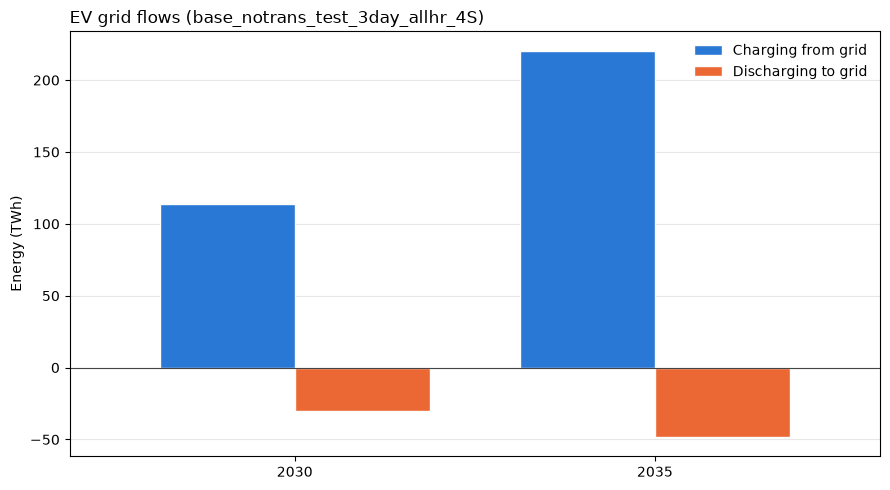

In [6]:
# 1.2 EV grid exchange components: charging from the grid, discharging to the grid, and net exchange
EV_COMPONENTS = {"Charging from grid": ("EV_G2V_Y", 1), "Discharging to grid": ("EV_V2G_Y", -1), "Net grid exchange": ("EV_NET_Y", 1)}
ev_components = {}
missing_ev_components = []
for label, (symbol, sign) in EV_COMPONENTS.items():
    try:
        table = get(symbol)
    except Exception as exc:
        missing_ev_components.append(f"{symbol}: {exc}")
        continue
    if table.empty:
        missing_ev_components.append(f"{symbol}: no rows for scenario {SCENARIO}")
        continue
    ev_components[label] = sign * table.groupby("Year")["Value"].sum()
if missing_ev_components:
    raise RuntimeError("Missing EV component outputs. Rerun the scenario after updating OUTPUT_SUMMARY.inc: " + "; ".join(missing_ev_components))
ev_components = pd.DataFrame(ev_components).sort_index()
ev_grid_flows = ev_components[["Charging from grid", "Discharging to grid"]]
ax = ev_grid_flows.plot.bar(figsize=(max(9, 0.5 * len(ev_grid_flows) + 5), 5), color=["#2a78d6", "#eb6834"], width=0.75, edgecolor="#fcfcfb")
ax.axhline(0, color="#444444", linewidth=0.8)
ax.set_title(f"EV grid flows ({SCENARIO})", loc="left")
ax.set_ylabel("Energy (TWh)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=xrot(len(ev_grid_flows)))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

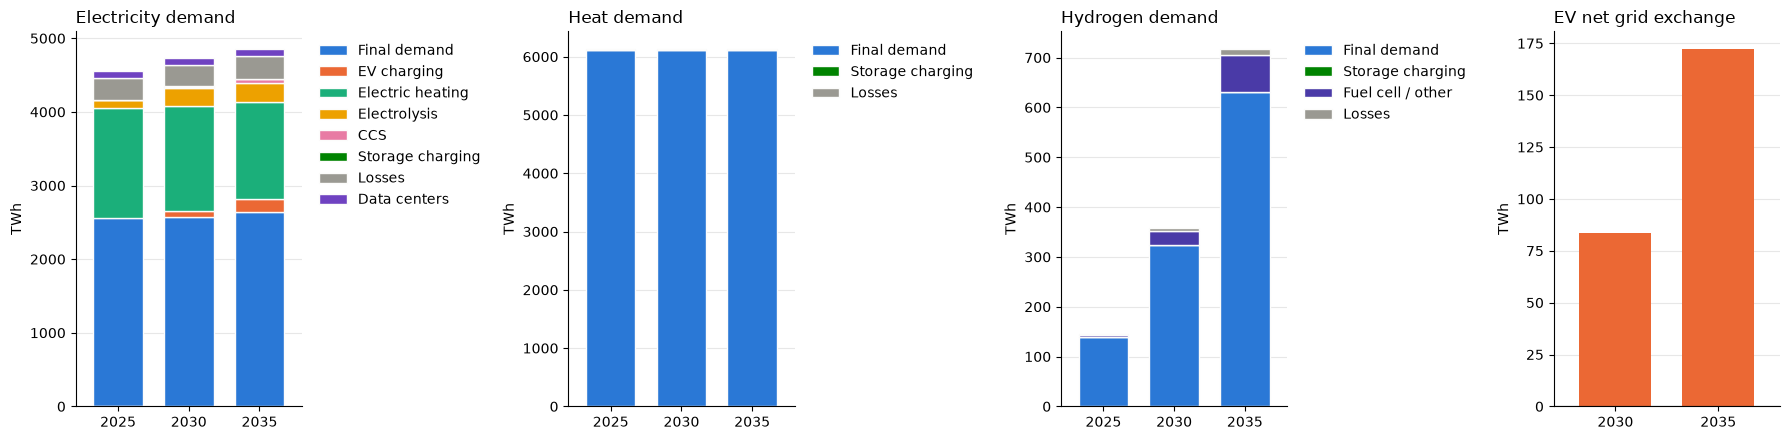

In [7]:
# 1.3 Total demand per carrier and category (TWh), plus net EV grid exchange
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (name, table) in zip(axes[:3], demand.items()):
    stacked_bar(table, DEMAND_COLORS, f"{name} demand", "TWh", ax=ax)
ev_components["Net grid exchange"].plot.bar(ax=axes[3], color=DEMAND_COLORS["EV charging"], width=0.7)
axes[3].axhline(0, color="#444444", linewidth=0.8)
axes[3].set_title("EV net grid exchange", loc="left"); axes[3].set_ylabel("TWh"); axes[3].set_xlabel("")
axes[3].tick_params(axis="x", rotation=xrot(len(ev_components))); axes[3].grid(axis="y", alpha=0.3); axes[3].set_axisbelow(True)
for side in ("top", "right"): axes[3].spines[side].set_visible(False)
plt.tight_layout()
plt.show()

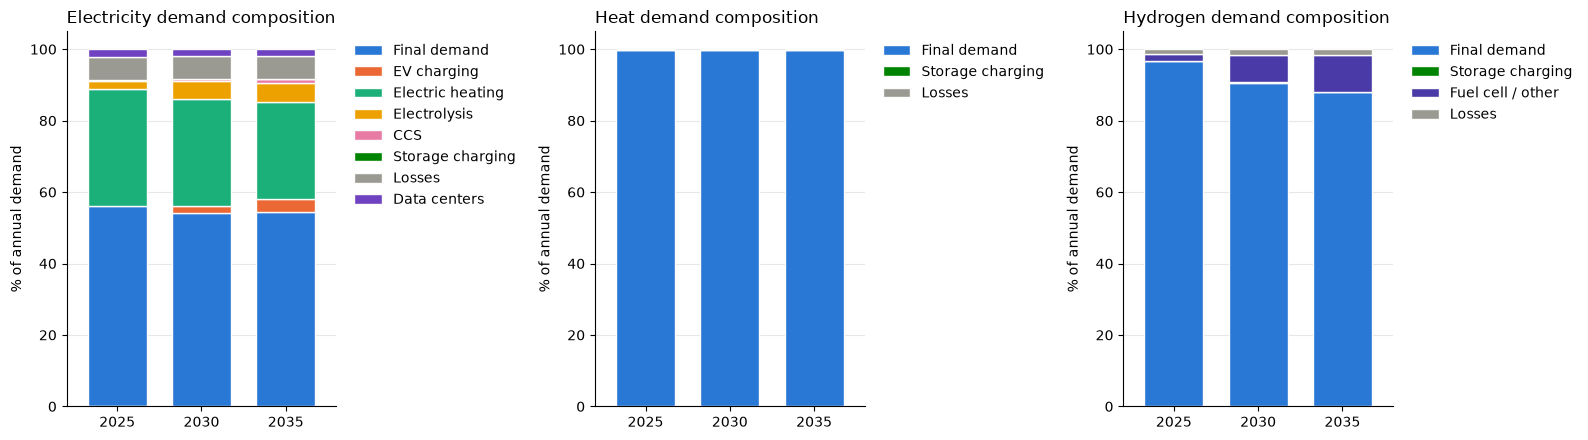

In [8]:
# 1.4 Demand composition (% of each carrier's annual demand)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, table) in zip(axes, demand.items()):
    share = table.div(table.sum(axis=1), axis=0) * 100
    stacked_bar(share, DEMAND_COLORS, f"{name} demand composition", "% of annual demand", ax=ax)
plt.tight_layout(); plt.show()

### 1.5 Data-center demand over time

Annual data-center electricity demand aggregated across all regions.

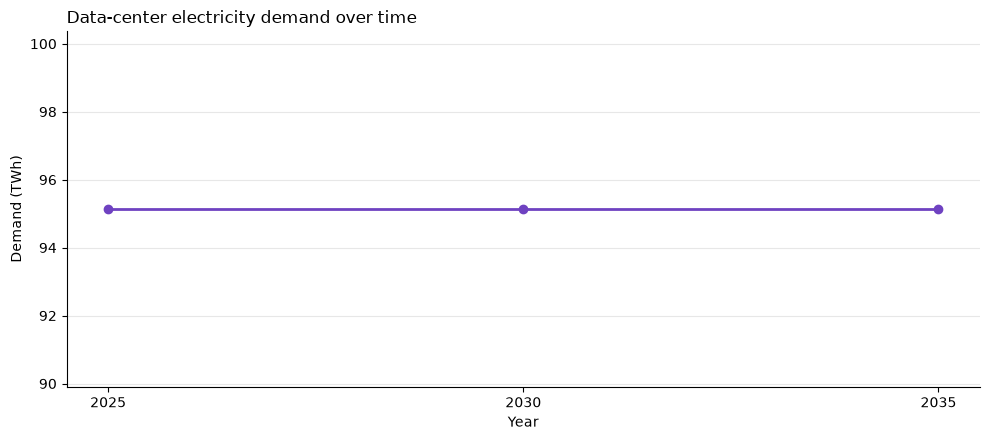

Data-center demand: 95.13 TWh in 2025, 95.13 TWh in 2035, change +0.00 TWh (+0.0 %)


In [9]:
# 1.5 Data-center electricity demand (TWh)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(dc_by_year.index, dc_by_year.values, marker="o", linewidth=2, color=DEMAND_COLORS["Data centers"])
ax.set_title("Data-center electricity demand over time", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Demand (TWh)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

# Change in yearly data-center demand between 2025 and 2035 (years are matched as text, whatever the index type)
dc_years = pd.Series(dc_by_year.values, index=dc_by_year.index.astype(str))
if {"2025", "2035"} <= set(dc_years.index):
    dc_change = dc_years["2035"] - dc_years["2025"]
    print(f"Data-center demand: {dc_years['2025']:.2f} TWh in 2025, {dc_years['2035']:.2f} TWh in 2035, "
          f"change {dc_change:+.2f} TWh ({dc_change / dc_years['2025'] * 100:+.1f} %)")
else:
    print("Data-center demand change 2025-2035 not available: 2025 and/or 2035 is not a solved year")


In [10]:
# 1.6 Annual energy-balance Sankey diagram (TWh)
# Technology groups feed carriers, which feed final demand.
SANKEY_YEAR = max(get("PRO_YCRAGF")["Year"])
sankey_carriers = ["ELECTRICITY", "HEAT", "HYDROGEN"]
sankey_names = {"ELECTRICITY": "Electricity", "HEAT": "Heat", "HYDROGEN": "Hydrogen"}

sankey_pro = get("PRO_YCRAGF").query("Year == @SANKEY_YEAR and Commodity in @sankey_carriers").copy()
sankey_pro["Source"] = tech_group(sankey_pro, unpack=True)
sankey_pro = sankey_pro.groupby(["Commodity", "Source"])["Value"].sum().reset_index()

sankey_dem = pd.concat([
    get("EL_DEMAND_YCR").assign(Commodity="ELECTRICITY"),
    get("H_DEMAND_YCRA").assign(Commodity="HEAT"),
    get("H2_DEMAND_YCR").assign(Commodity="HYDROGEN"),
], ignore_index=True).query("Year == @SANKEY_YEAR and Commodity in @sankey_carriers")
sankey_dem = sankey_dem.groupby("Commodity")["Value"].sum()

source_labels = [f"{row.Commodity.title()}: {row.Source}" for row in sankey_pro.itertuples()]
carrier_labels = [sankey_names[c] for c in sankey_carriers]
sink_labels = [f"{sankey_names[c]} final demand" for c in sankey_carriers]
labels = source_labels + carrier_labels + sink_labels
carrier_index = {c: len(source_labels) + i for i, c in enumerate(sankey_carriers)}
sink_index = {c: len(source_labels) + len(carrier_labels) + i for i, c in enumerate(sankey_carriers)}
source_index = {(row.Commodity, row.Source): i for i, row in enumerate(sankey_pro.itertuples())}

links = [(source_index[(row.Commodity, row.Source)], carrier_index[row.Commodity], row.Value) for row in sankey_pro.itertuples() if row.Value > 0]
for commodity in sankey_carriers:
    supply = sankey_pro.loc[sankey_pro["Commodity"] == commodity, "Value"].sum()
    demand_value = float(sankey_dem.get(commodity, 0))
    if demand_value > 0:
        links.append((carrier_index[commodity], sink_index[commodity], demand_value))
    residual = supply - demand_value
    if residual > 1e-9:
        labels.append(f"{sankey_names[commodity]} surplus / exports")
        links.append((carrier_index[commodity], len(labels) - 1, residual))
    elif residual < -1e-9:
        labels.append(f"{sankey_names[commodity]} net imports")
        links.append((len(labels) - 1, carrier_index[commodity], -residual))

fig = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(label=labels, pad=18, thickness=18, line=dict(color="rgba(80,80,80,0.35)", width=0.5)),
    link=dict(source=[x[0] for x in links], target=[x[1] for x in links], value=[x[2] for x in links]),
))
fig.update_layout(title=f"Annual energy balance, {SANKEY_YEAR} ({SCENARIO})", height=720, width=1250,
                  font=dict(size=11), margin=dict(l=10, r=10, t=55, b=10))
fig.show()


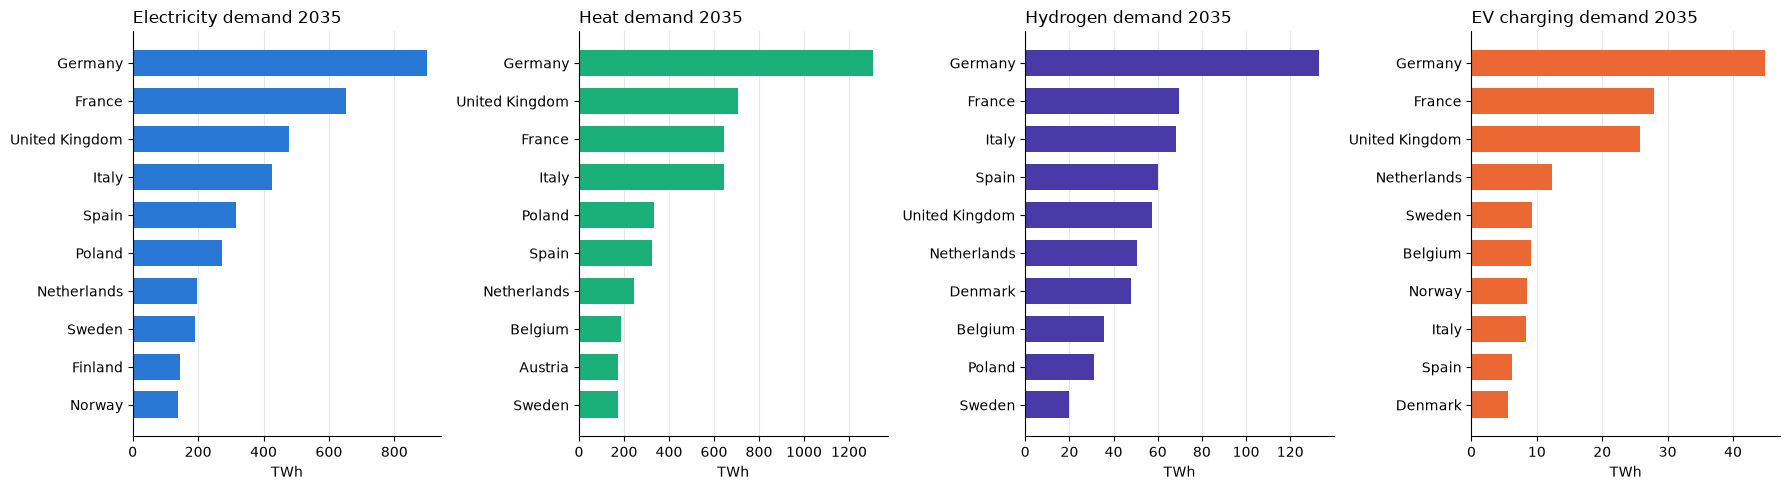

In [11]:
# 1.7 Demand per country in the last solved year (TWh): the 10 largest countries for each carrier
el_d, h_d, h2_d = get("EL_DEMAND_YCR"), get("H_DEMAND_YCRA"), get("H2_DEMAND_YCR")
last = el_d["Year"].max()
per_country = {
    "Electricity": (el_d[el_d["Year"] == last].groupby("Country")["Value"].sum(), "#2a78d6"),
    "Heat": (h_d[h_d["Year"] == last].groupby("Country")["Value"].sum(), "#1baf7a"),
    "Hydrogen": (h2_d[h2_d["Year"] == last].groupby("Country")["Value"].sum(), "#4a3aa7"),
    "EV charging": (el_d[(el_d["Year"] == last) & (el_d["Category"] == "ENDO_EV")].groupby("Country")["Value"].sum(),
                    DEMAND_COLORS["EV charging"]),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (name, (series, color)) in zip(axes, per_country.items()):
    s = series.sort_values(ascending=False).head(10).iloc[::-1]          # largest on top
    ax.barh([clean_name(c) for c in s.index], s.values, color=color, height=0.7)
    ax.set_title(f"{name} demand {last}", loc="left"); ax.set_xlabel("TWh")
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

## 2. Total capacity mix
`G_CAP_YCRAF` splits capacity into `EXOGENOUS` (existing / given), `ENDOGENOUS` (investments) and `DECOMMISSIONING` (negative).
The installed capacity of a year is the sum of the three. One chart per output commodity.

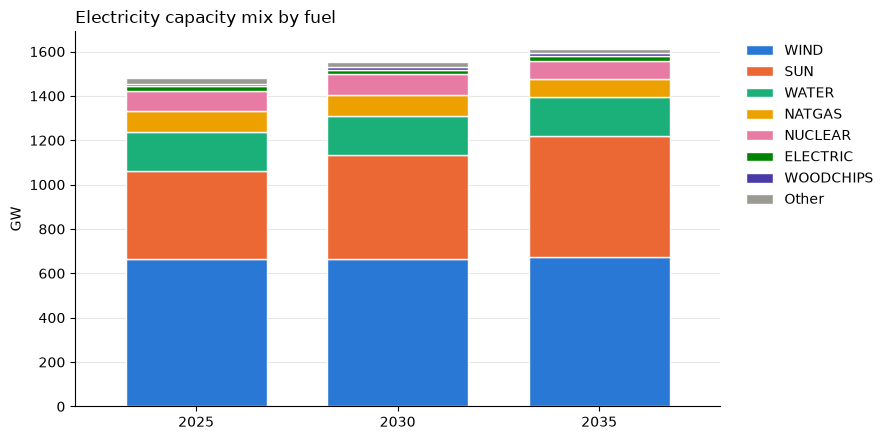

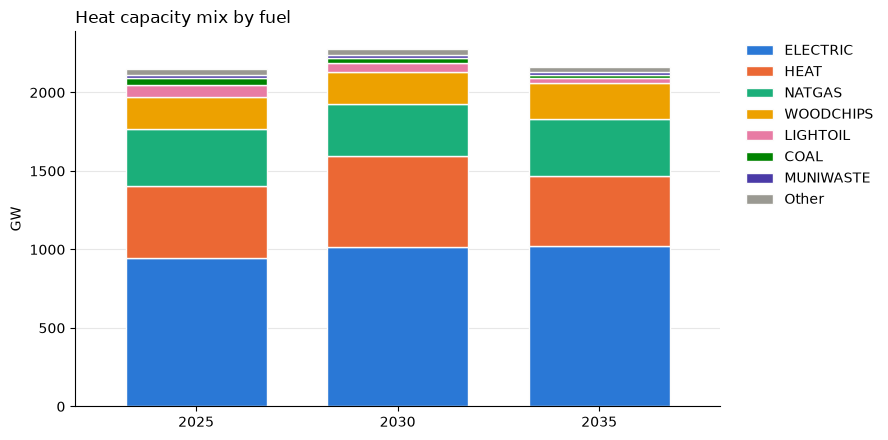

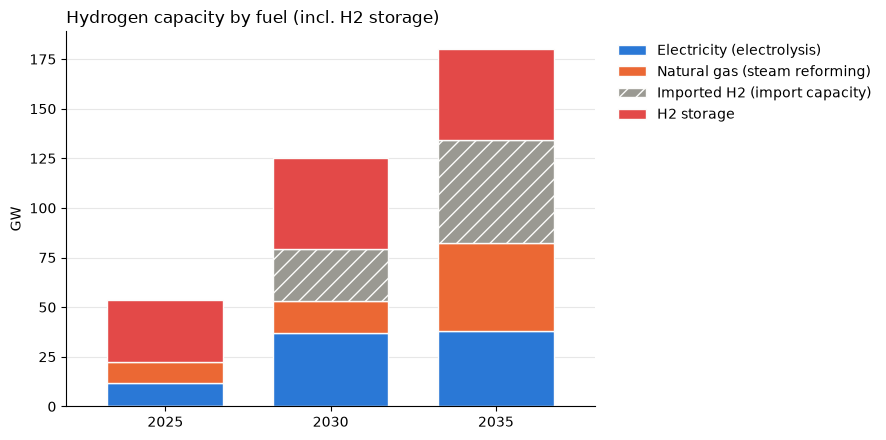

Label,Electricity (electrolysis),H2 storage,Imported H2 (import capacity),Natural gas (steam reforming)
Year,,,,
2025,11.90,31.23,0.00,10.55
2030,36.75,45.73,26.29,16.23
2035,37.93,45.73,51.72,44.62


In [12]:
# 2.1 Installed capacity per fuel per year = exogenous + endogenous + decommissioning (GW)
cap = get("G_CAP_YCRAF")
for commodity in ["ELECTRICITY", "HEAT"]:
    table = cap[cap["Commodity"] == commodity].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
    stacked_by_label(table, f"{commodity.title()} capacity mix by fuel", "GW")
    plt.tight_layout(); plt.show()

# Hydrogen: capacity labelled by its input fuel, with H2 storage (fuel HYDROGEN) as its own segment.
# and the IMPORT_H2 capacity (modelled as an ELECTROLYZER, but it does not produce H2 in the model) is shown separately.
H2_STORAGE_TECH = ["H2-STORAGE"]
H2_FUEL_LABEL = {"ELECTRIC": "Electricity (electrolysis)", "NATGAS": "Natural gas (steam reforming)", "IMPORT_H2": "Imported H2 (import capacity)"}

def h2_label(df):
    """Input-fuel label per hydrogen row; H2 storage rows are labelled 'H2 storage'."""
    label = df["Fuel"].map(H2_FUEL_LABEL).fillna(df["Fuel"].map(clean_name) + " (" + df["Technology"].str.lower() + ")")
    return label.mask(df["Technology"].isin(H2_STORAGE_TECH), "H2 storage")

h2 = cap[cap["Commodity"] == "HYDROGEN"]
h2_table = (h2.assign(Label=h2_label(h2))
              .groupby(["Year", "Label"])["Value"].sum().unstack("Label").fillna(0))
h2_colors = {"Electricity (electrolysis)": "#2a78d6", "Natural gas (steam reforming)": "#eb6834", "Imported H2 (import capacity)": GREY,
             "H2 storage": "#e34948"}
h2_colors.update({l: c for l, c in zip([l for l in h2_table.columns if l not in h2_colors], PALETTE[2:])})
ax = stacked_bar(h2_table, h2_colors, "Hydrogen capacity by fuel (incl. H2 storage)", "GW")
h2_cols = [c for c in h2_colors if c in h2_table.columns]                  # stack order used by stacked_bar
if "Imported H2 (import capacity)" in h2_cols:
    for patch in ax.containers[h2_cols.index("Imported H2 (import capacity)")]:
        patch.set_hatch("//")                                               # imports are not domestic production
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout(); plt.show()
display(h2_table.round(2))


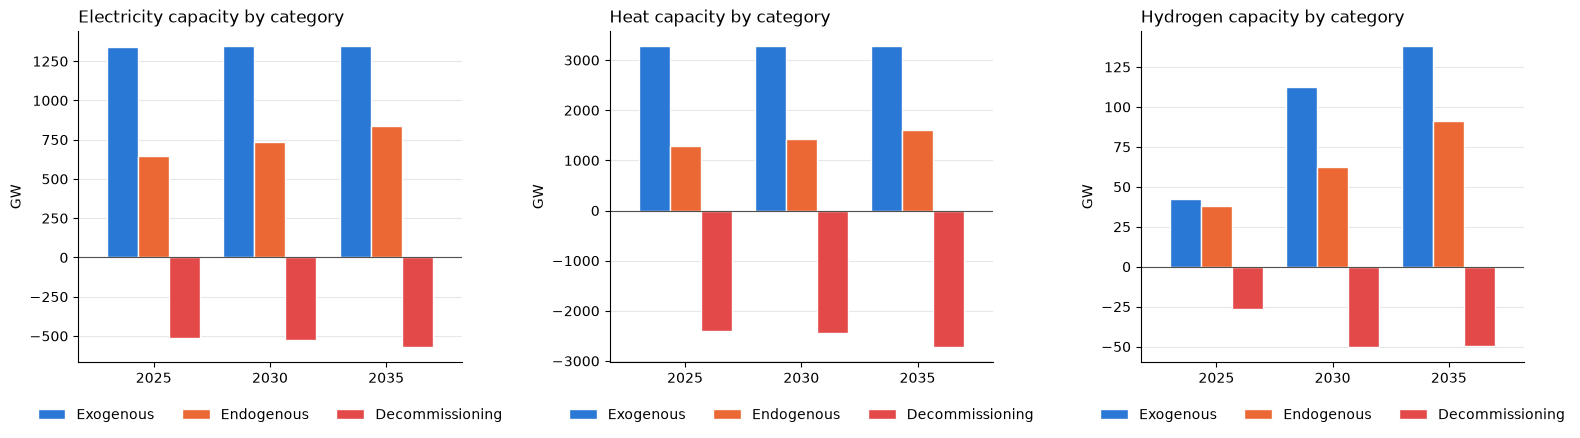

In [13]:
# 2.2 Where does the capacity come from? Exogenous, endogenous (investments) and decommissioning (GW)
CAT_COLORS = {"EXOGENOUS": "#2a78d6", "ENDOGENOUS": "#eb6834", "DECOMMISSIONING": "#e34948"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, commodity in zip(axes, ["ELECTRICITY", "HEAT", "HYDROGEN"]):
    t = cap[cap["Commodity"] == commodity].groupby(["Year", "Category"])["Value"].sum().unstack("Category").fillna(0)
    t = t[[c for c in CAT_COLORS if c in t.columns]]
    t.plot.bar(ax=ax, color=[CAT_COLORS[c] for c in t.columns], width=0.8, edgecolor="#fcfcfb", linewidth=1)
    ax.set_title(f"{commodity.title()} capacity by category", loc="left"); ax.set_ylabel("GW"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=xrot(len(t))); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    ax.legend([clean_name(c) for c in t.columns], frameon=False, loc="upper center",
              bbox_to_anchor=(0.5, -0.1), ncol=3)
    ax.axhline(0, color="#52514e", linewidth=0.8)          # zero line drawn after the legend exists
plt.tight_layout(); plt.show()

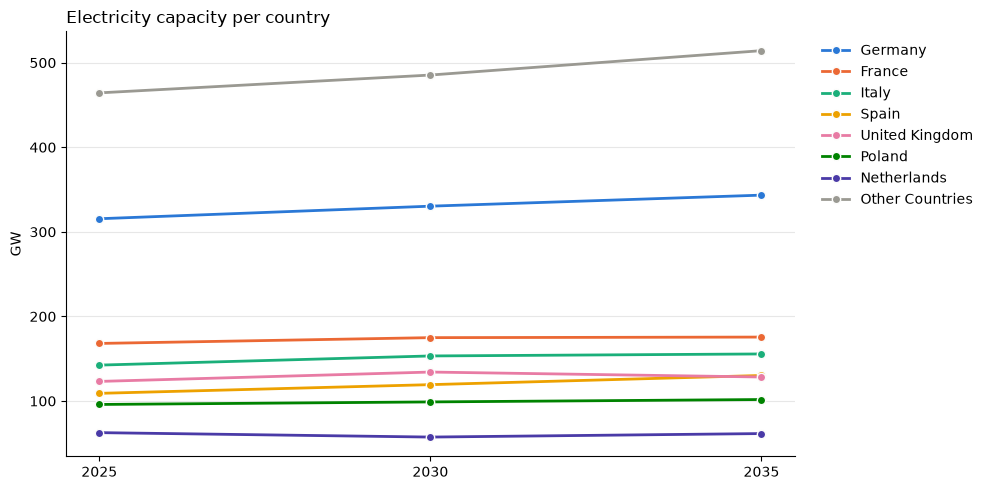

In [14]:
# 2.3 Electricity capacity per country (GW): line plot of the 7 largest countries, the rest summed as "Other countries"
cap_el = cap[cap["Commodity"] == "ELECTRICITY"]
by_country = cap_el.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0)
by_country = by_country.sort_values(by_country.columns[-1], ascending=False)

other = by_country.iloc[7:].sum().to_frame("Other countries").T
plot_df = pd.concat([by_country.head(7), other]).T            # rows = years, columns = lines

palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#9a9992"]
fig, ax = plt.subplots(figsize=(10, 5))
for name, color in zip(plot_df.columns, palette):
    ax.plot(plot_df.index, plot_df[name], marker="o", markersize=6, linewidth=2, color=color,
            markeredgecolor="#fcfcfb", label=name.replace("_", " ").title())
ax.set_title("Electricity capacity per country", loc="left")
ax.set_ylabel("GW"); ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout(); plt.show()


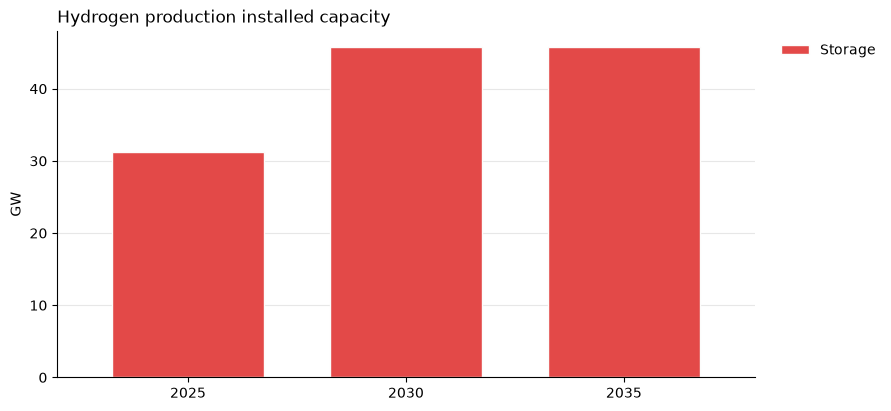

In [15]:
# 2.4 Hydrogen production capacity
cap = get("G_CAP_YCRAF")
hydrogen_cap = cap[cap["Commodity"] == "HYDROGEN"].copy()
hydrogen_cap["Technology group"] = hydrogen_cap["Technology"].map(TECH_GROUP).fillna("Other")
hydrogen_cap = hydrogen_cap.groupby(["Year", "Technology group"])["Value"].sum().unstack("Technology group").fillna(0)
stacked_bar(hydrogen_cap, GROUP_COLORS_UNPACKED, "Hydrogen production installed capacity", "GW")
plt.show()

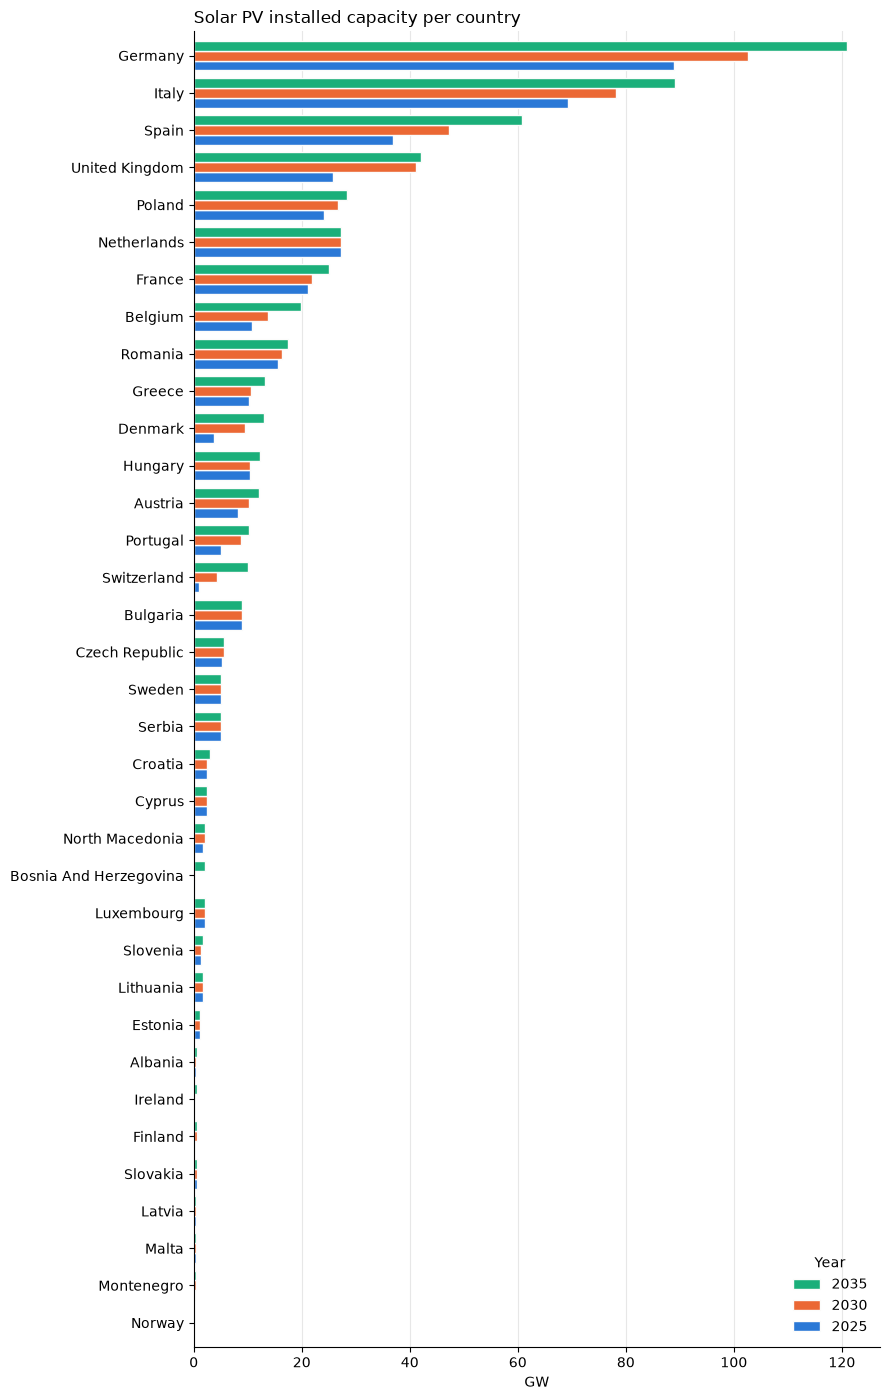

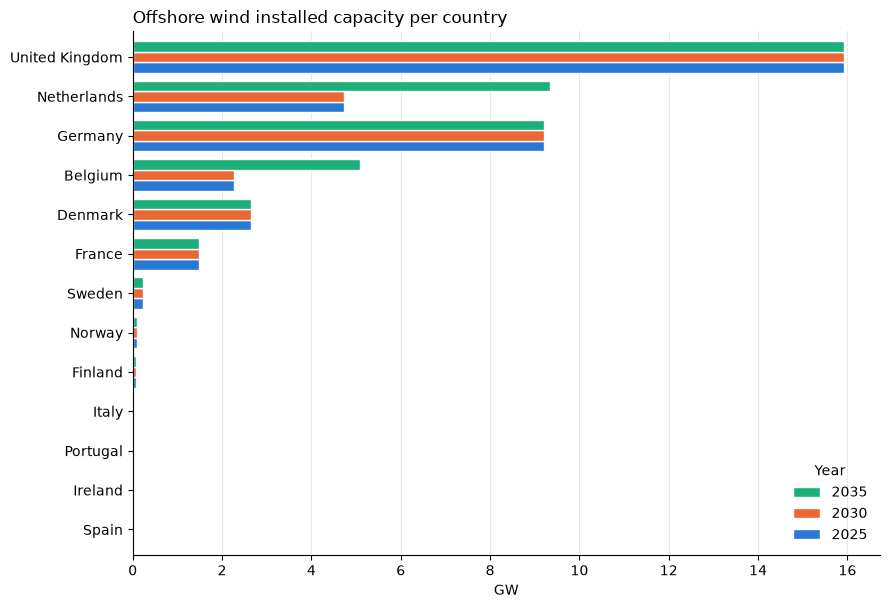

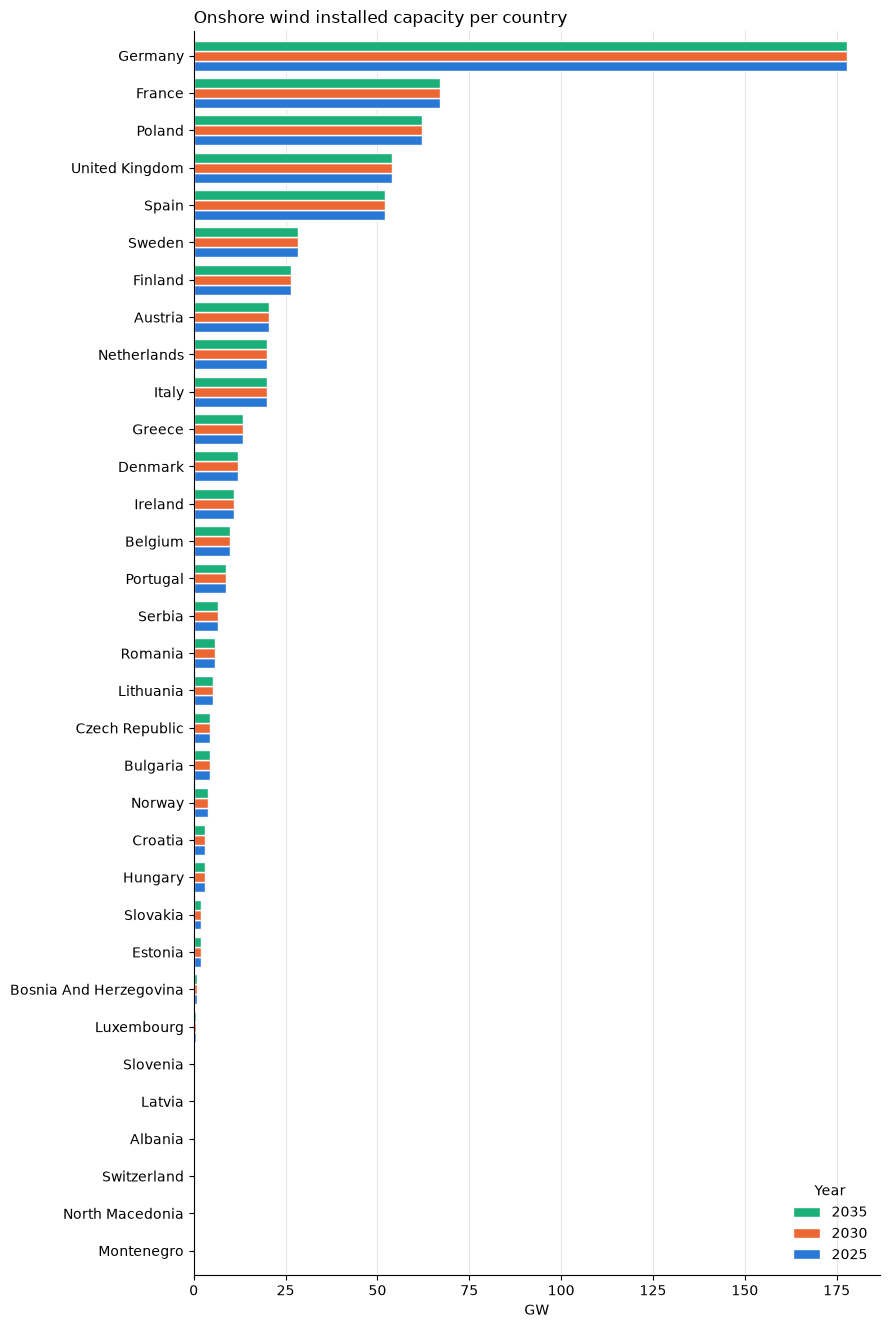

In [16]:
# 2.5 Installed solar PV, offshore wind and onshore wind capacity per country (GW), one chart per technology
# Countries sorted by capacity in the last year; countries without any capacity of the technology are left out
VRE_TECH = {"SOLAR-PV": "Solar PV", "WIND-OFF": "Offshore wind", "WIND-ON": "Onshore wind"}
vre_cap = cap[(cap["Commodity"] == "ELECTRICITY") & cap["Technology"].isin(VRE_TECH)]
vre_cap = vre_cap.groupby(["Technology", "Country", "Year"])["Value"].sum().unstack("Year").fillna(0)

for tech, label in VRE_TECH.items():
    t = vre_cap.loc[tech] if tech in vre_cap.index.get_level_values("Technology") else pd.DataFrame()
    t = t[t.abs().sum(axis=1) > 1e-6].sort_values(t.columns[-1]) if len(t) else t   # largest on top
    if t.empty:
        print(f"No {label} capacity in {SCENARIO}"); continue
    fig, ax = plt.subplots(figsize=(9, max(3, 0.12 * t.shape[1] * len(t) + 1.5)))
    t.plot.barh(ax=ax, color=year_colors(t.shape[1]), width=0.8, edgecolor="#fcfcfb", linewidth=1)
    ax.set_yticklabels([clean_name(c) for c in t.index])
    ax.set_title(f"{label} installed capacity per country", loc="left"); ax.set_xlabel("GW"); ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], title="Year", frameon=False, loc="lower right")
    plt.tight_layout(); plt.show()

## 3. Total energy dispatched mix
`PRO_YCRAGF` is the annual production per generator (TWh), split by output commodity.

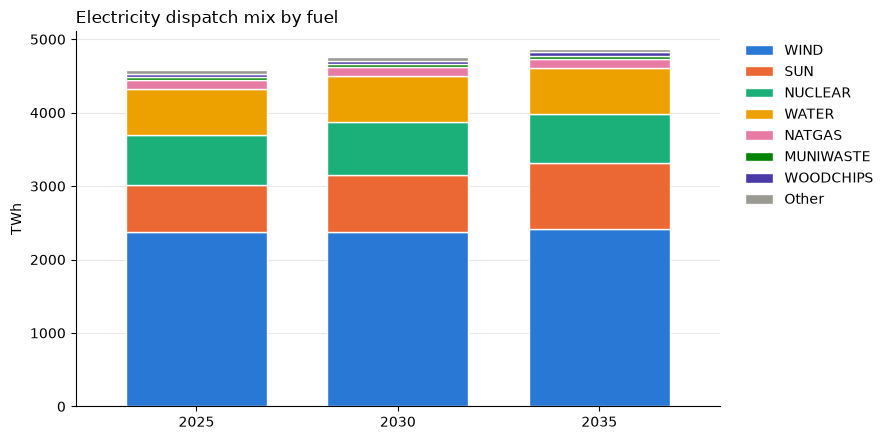

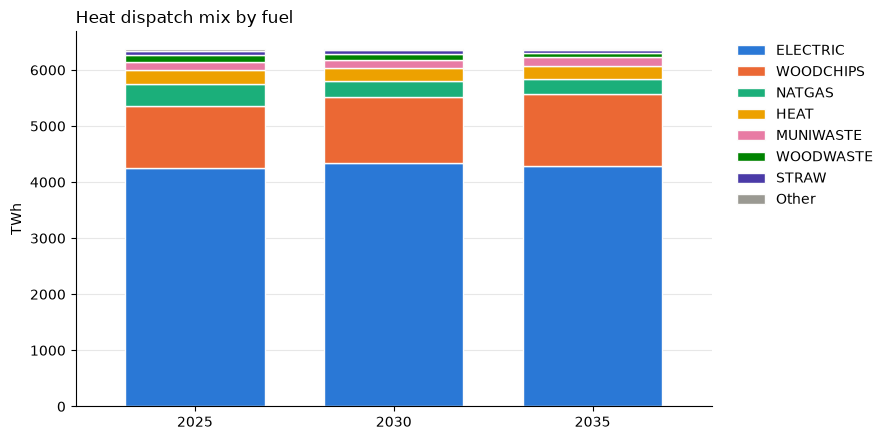

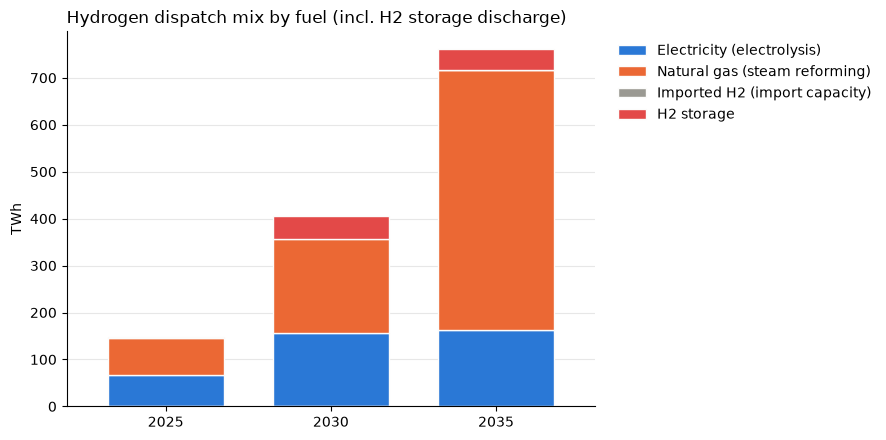

Label,Electricity (electrolysis),H2 storage,Imported H2 (import capacity),Natural gas (steam reforming)
Year,,,,
2025,67.89,3.19,0.00,77.00
2030,157.21,47.55,0.00,200.43
2035,163.49,44.12,0.02,553.38


In [17]:
# 3.1 Annual production by fuel (TWh) for each commodity
pro = get("PRO_YCRAGF")
for commodity in ["ELECTRICITY", "HEAT"]:
    table = pro[pro["Commodity"] == commodity].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
    stacked_by_label(table, f"{commodity.title()} dispatch mix by fuel", "TWh")
    plt.tight_layout(); plt.show()

# Hydrogen dispatch, labelled by input fuel as in 2.1 (h2_label, h2_colors); H2 storage discharge is its own segment.
h2_pro = pro[pro["Commodity"] == "HYDROGEN"]
h2_pro_table = (h2_pro.assign(Label=h2_label(h2_pro))
                      .groupby(["Year", "Label"])["Value"].sum().unstack("Label").fillna(0))
h2_pro_colors = {**h2_colors, **{l: c for l, c in zip([l for l in h2_pro_table.columns if l not in h2_colors], PALETTE[2:])}}
stacked_bar(h2_pro_table, h2_pro_colors, "Hydrogen dispatch mix by fuel (incl. H2 storage discharge)", "TWh")
plt.tight_layout(); plt.show()
display(h2_pro_table.round(2))


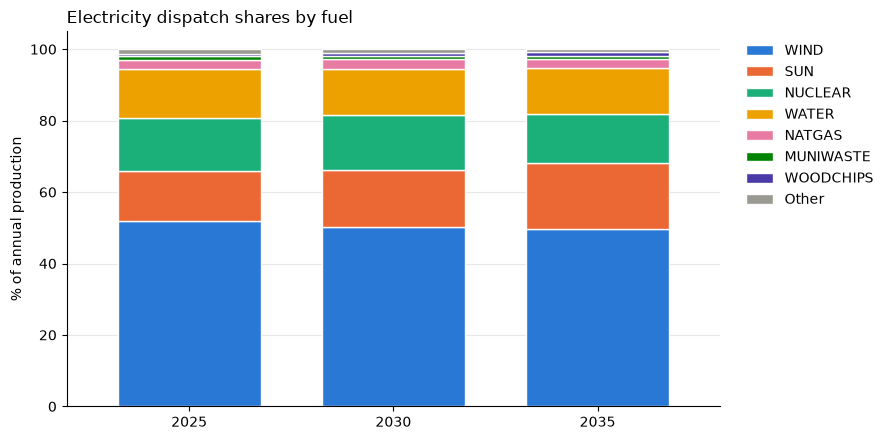

In [18]:
# 3.2 Electricity dispatch shares by fuel (% of annual electricity production)
el = pro[pro["Commodity"] == "ELECTRICITY"].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
stacked_by_label(el.div(el.sum(axis=1), axis=0) * 100, "Electricity dispatch shares by fuel", "% of annual production")
plt.tight_layout(); plt.show()

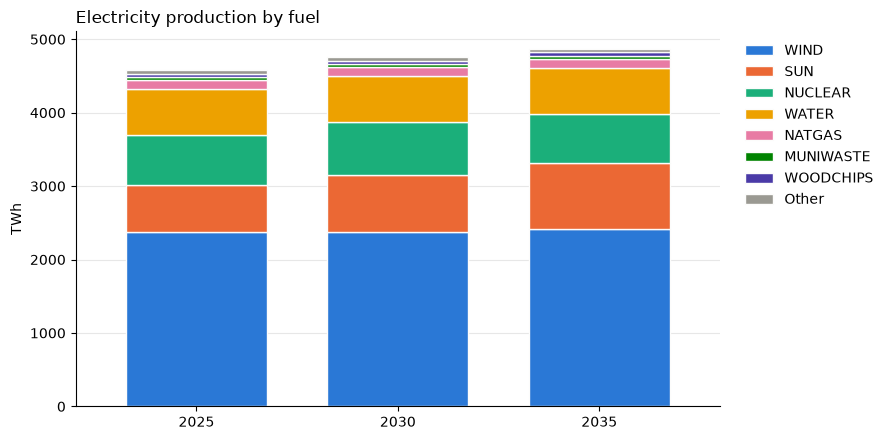

In [19]:
# 3.3 Electricity production by fuel (TWh): the 7 largest fuels, the rest summed as "Other"
fuel = pro[pro["Commodity"] == "ELECTRICITY"].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
stacked_by_label(fuel, "Electricity production by fuel", "TWh")
plt.tight_layout(); plt.show()

Found MainResults in /zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S/model/MainResults_reference_chronohour.gdx


/zhome/3d/c/214482/venvs/pybalmorel/lib/python3.11/site-packages/pybalmorel/plotting/maps_balmorel.py:840: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_line_new = pd.concat([df_line_new, df_line.loc[[k]]], ignore_index=True)
/zhome/3d/c/214482/venvs/pybalmorel/lib/python3.11/site-packages/pybalmorel/plotting/maps_balmorel.py:1095: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_background_netexport = pd.concat([df_background_netexport, pd.DataFrame([{'RRR': rrr, 'Value': net_export}])], ign

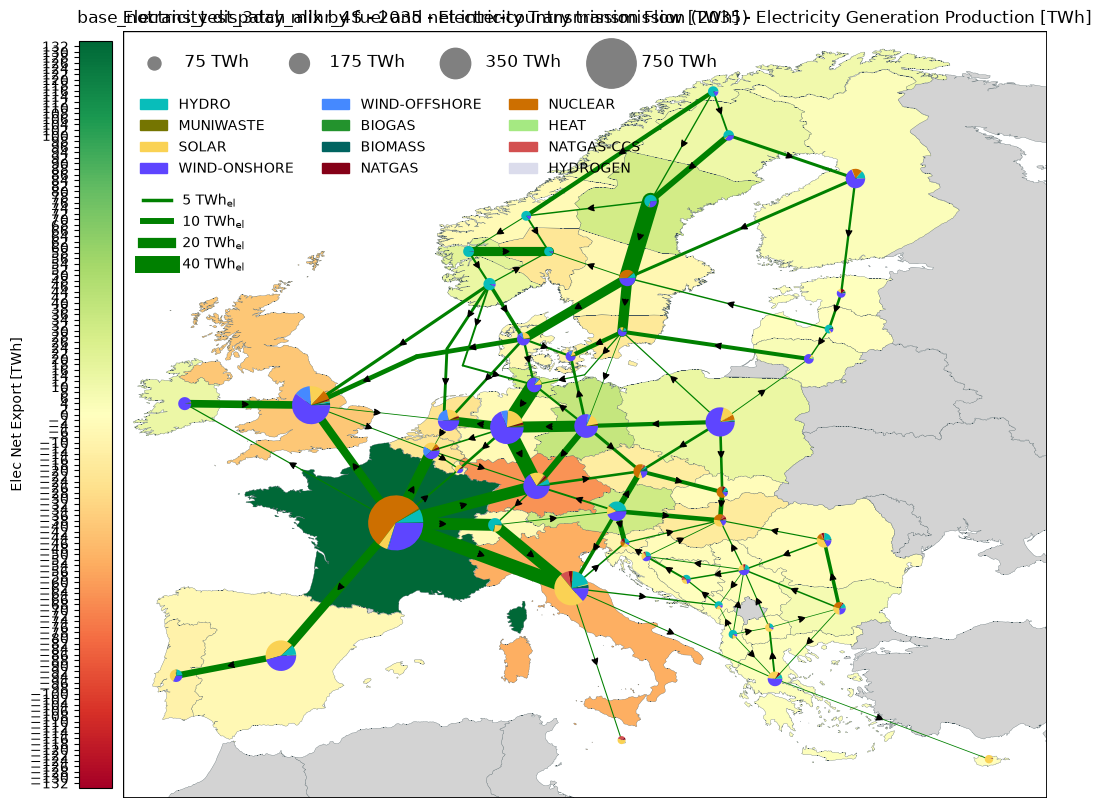

In [20]:
# 3.4 Electricity dispatch mix by fuel per country and net inter-country transmission
# FlowYear shows the annual net flow on each electricity transmission line.
# Compatibility for pybalmorel 1.2.3 with Matplotlib versions where cm.get_cmap was removed.
if not hasattr(plt.cm, "get_cmap"):
    plt.cm.get_cmap = plt.colormaps.get_cmap
MAP_YEAR = int(max(pro["Year"]))
fig, ax = res.plot_map(
    scenario=SCENARIO,
    year=MAP_YEAR,
    commodity="Electricity",
    lines="FlowYear",
    generation="Production",
    generation_var="FFF",
    background="Elec Net Export",
)
ax.set_title(f"Electricity dispatch mix by fuel and net inter-country transmission ({MAP_YEAR})", loc="left")
plt.show()

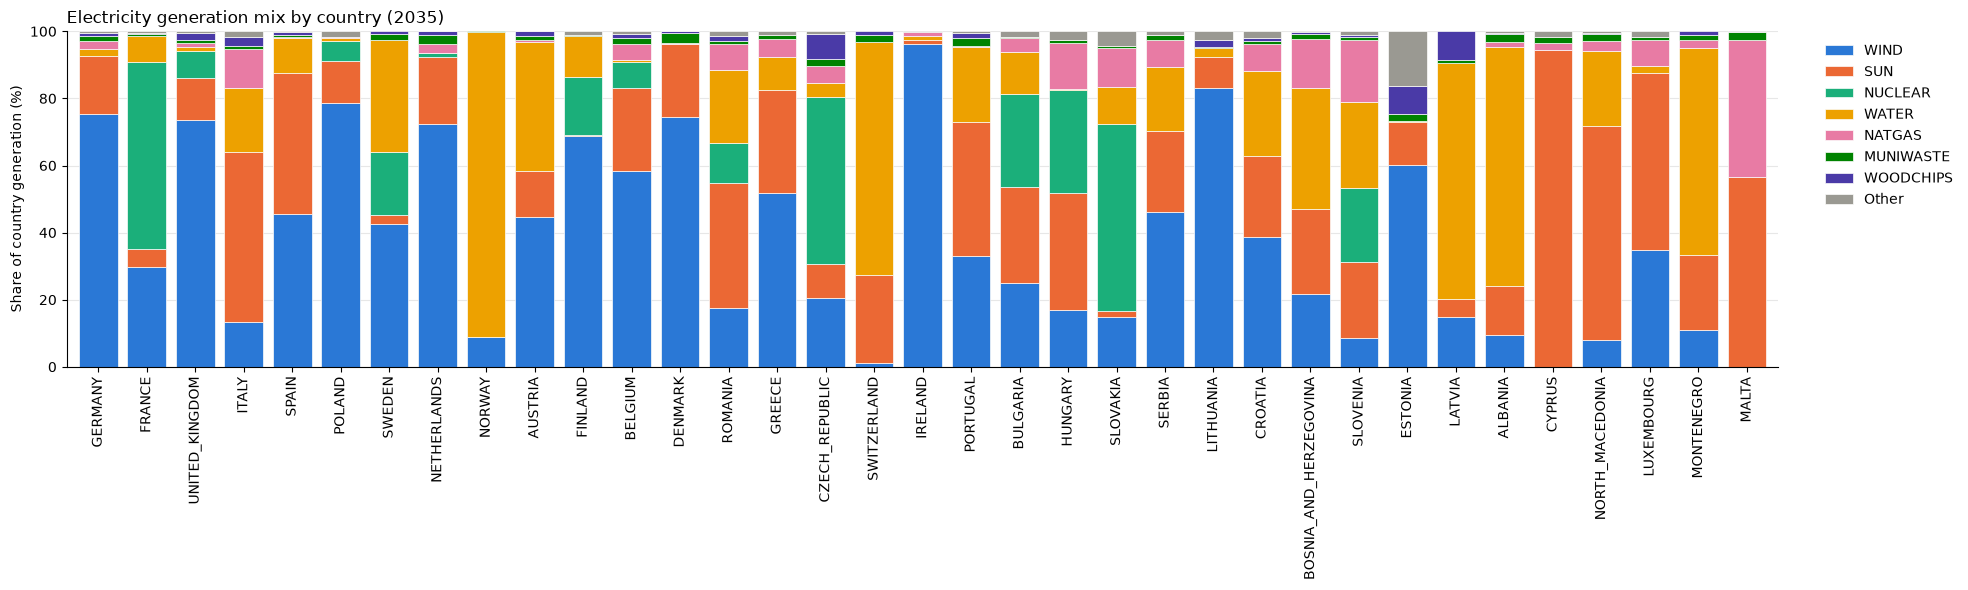

In [21]:
# 3.5 Electricity generation mix by country in the last solved year
# Regions belonging to the same country are aggregated before calculating the mix.
COUNTRY_MIX_YEAR = pro["Year"].max()
country_el = pro[(pro["Year"] == COUNTRY_MIX_YEAR) & (pro["Commodity"] == "ELECTRICITY")].copy()
country_mix = country_el.groupby(["Country", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
country_mix = country_mix.loc[country_mix.sum(axis=1).sort_values(ascending=False).index]
country_mix = country_mix.loc[:, country_mix.sum().sort_values(ascending=False).index]
country_mix = country_mix.iloc[:, :7].assign(Other=country_mix.iloc[:, 7:].sum(axis=1))
country_mix_pct = country_mix.div(country_mix.sum(axis=1), axis=0).mul(100)
fuel_colors = dict(zip(country_mix_pct.columns, PALETTE[:7] + [GREY]))
ax = country_mix_pct.plot.bar(stacked=True, figsize=(max(12, 0.45 * len(country_mix_pct) + 4), 6), color=[fuel_colors[c] for c in country_mix_pct.columns], width=0.8, edgecolor="#fcfcfb", linewidth=0.5)
ax.set_title(f"Electricity generation mix by country ({COUNTRY_MIX_YEAR})", loc="left")
ax.set_ylabel("Share of country generation (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 4. Curtailment
`CURT_YCRAGF` gives the curtailed energy per generator (TWh). Wind and solar values are positive curtailment.
Hydro-reservoir rows contain entries of both signs that net to about zero (reservoir balancing), so they do not add curtailment.

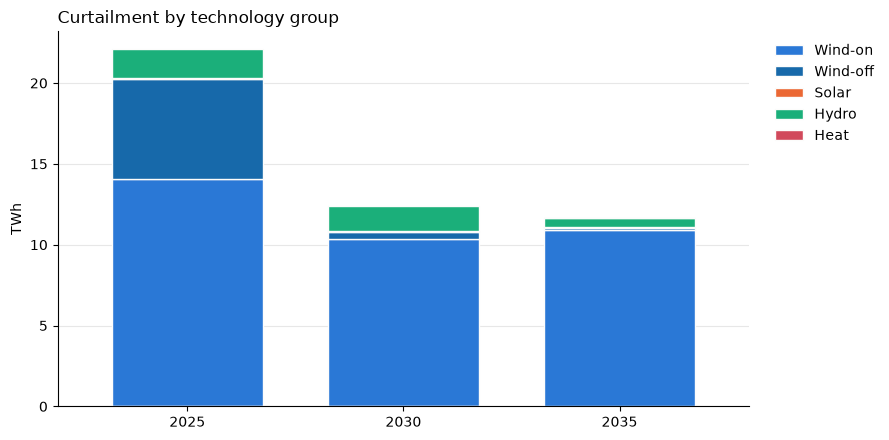

In [22]:
# 4.1 Curtailed energy by technology group (TWh)
curt = get("CURT_YCRAGF")
table = curt.assign(Group=tech_group(curt)).groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)
stacked_bar(table, GROUP_COLORS, "Curtailment by technology group", "TWh")
plt.tight_layout(); plt.show()


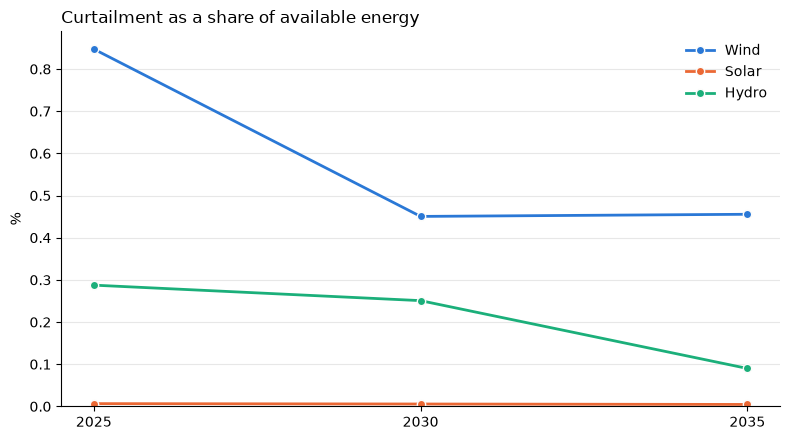

In [23]:
# 4.2 Curtailment as a share of the available energy (dispatched + curtailed), per technology group
prod_g = pro.assign(Group=tech_group(pro)).groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)
share = table / (prod_g.reindex_like(table).fillna(0) + table) * 100      # `table` = curtailment by group from 4.1

fig, ax = plt.subplots(figsize=(8, 4.5))
wind_available = prod_g.reindex(columns=["Wind-on", "Wind-off"], fill_value=0) + table.reindex(columns=["Wind-on", "Wind-off"], fill_value=0)
wind_curtailment = table.reindex(columns=["Wind-on", "Wind-off"], fill_value=0).sum(axis=1)
wind_available = wind_available.sum(axis=1)
wind_share = wind_curtailment.div(wind_available.replace(0, float("nan"))).mul(100)
for g, series in [("Wind", wind_share), ("Solar", share.get("Solar")), ("Hydro", share.get("Hydro"))]:
    if series is not None:
        ax.plot(series.index, series, marker="o", markersize=6, linewidth=2, color=GROUP_COLORS.get(g, GROUP_COLORS["Wind-on"]),
                markeredgecolor="#fcfcfb", label=g)
ax.set_title("Curtailment as a share of available energy", loc="left"); ax.set_ylabel("%"); ax.set_xlabel("")
ax.set_ylim(bottom=0); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

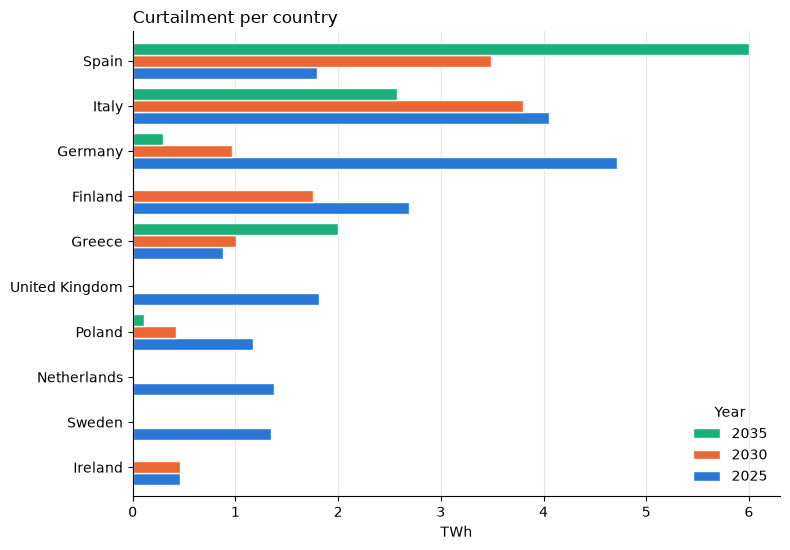

In [24]:
# 4.3 Curtailment per country (TWh): the 10 largest countries
country_bars(curt.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0),
             "Curtailment per country", "TWh")
plt.tight_layout(); plt.show()

## 5. Total costs
`OBJ_YCR` holds the objective-function cost terms per year and region (Mmoney, the currency of the input data).
Cost terms are folded into five groups.

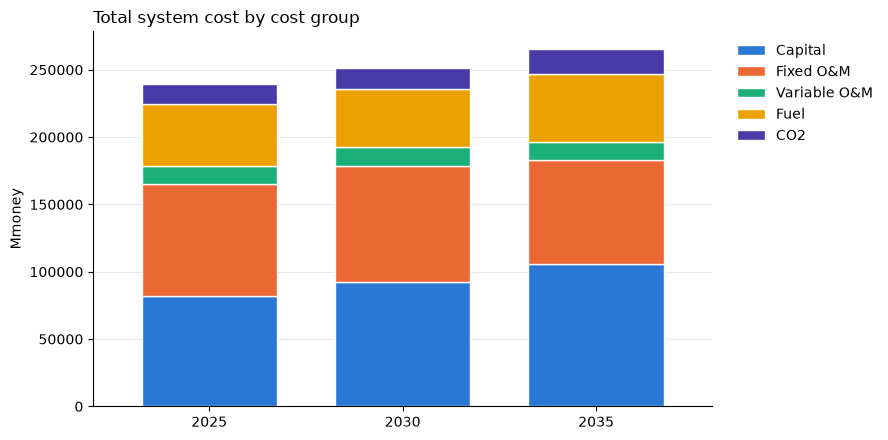

In [25]:
# 5.1 Total system cost per year and cost group (Mmoney)
obj = get("OBJ_YCR")
COST_GROUP = {
    "GENERATION_CAPITAL_COSTS": "Capital", "TRANSMISSION_CAPITAL_COSTS": "Capital", "H2_TRANSMISSION_CAPITAL_COSTS": "Capital",
    "GENERATION_FIXED_COSTS": "Fixed O&M",
    "GENERATION_OPERATIONAL_COSTS": "Variable O&M", "TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M",
    "HEAT_TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M", "H2_TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M",
    "GENERATION_FUEL_COSTS": "Fuel",
    "GENERATION_CO2_TAX": "CO2", "GENERATION_CO2_TRANSPORT": "CO2",
}
COST_COLORS = {"Capital": "#2a78d6", "Fixed O&M": "#eb6834", "Variable O&M": "#1baf7a", "Fuel": "#eda100", "CO2": "#4a3aa7"}

costs = obj.assign(Group=obj["Category"].map(COST_GROUP).fillna("Other")) \
           .groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)
stacked_bar(costs, COST_COLORS, "Total system cost by cost group", "Mmoney")
plt.tight_layout(); plt.show()


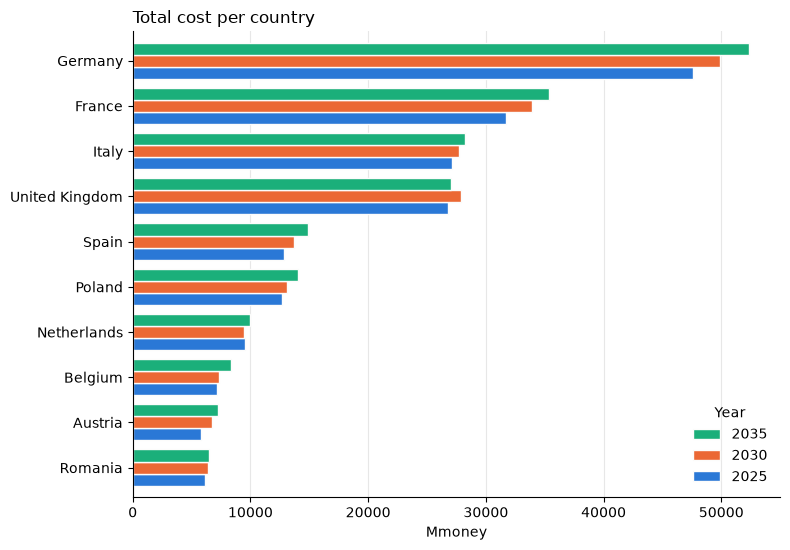

In [26]:
# 5.2 Total cost per country (Mmoney): the 10 largest countries
country_bars(obj.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0),
             "Total cost per country", "Mmoney")
plt.tight_layout(); plt.show()

## 6. Total CO2 emissions
`EMI_YCRAG` holds annual CO2 emissions per generator (kton).

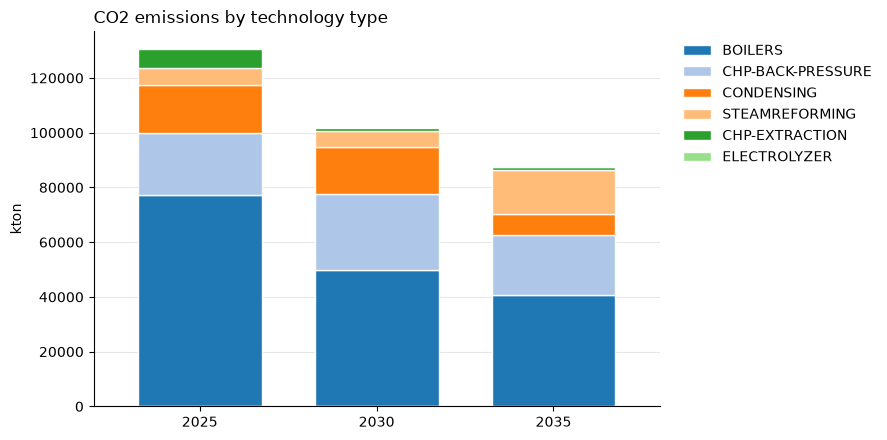

In [27]:
# 6.1 Total CO2 emissions per year by technology type (kton)
emi = get("EMI_YCRAG")
table = emi.groupby(["Year", "Technology"])["Value"].sum().unstack("Technology").fillna(0)
table = table.loc[:, table.sum(axis=0).sort_values(ascending=False).index]
emission_colors = {technology: plt.cm.tab20(i % 20) for i, technology in enumerate(table.columns)}
stacked_bar(table, emission_colors, "CO2 emissions by technology type", "kton")
plt.tight_layout(); plt.show()


#### 6.1.1 What the emitting technologies are used for
The emissions of each technology type (`EMI_YCRAG`) split by the commodity they serve: each generator's emissions are allocated to electricity, heat and hydrogen in proportion to its output (`PRO_YCRAGF`), so CHP emissions are shared between power and heat. One panel per solved year; the table gives the same split in kton.

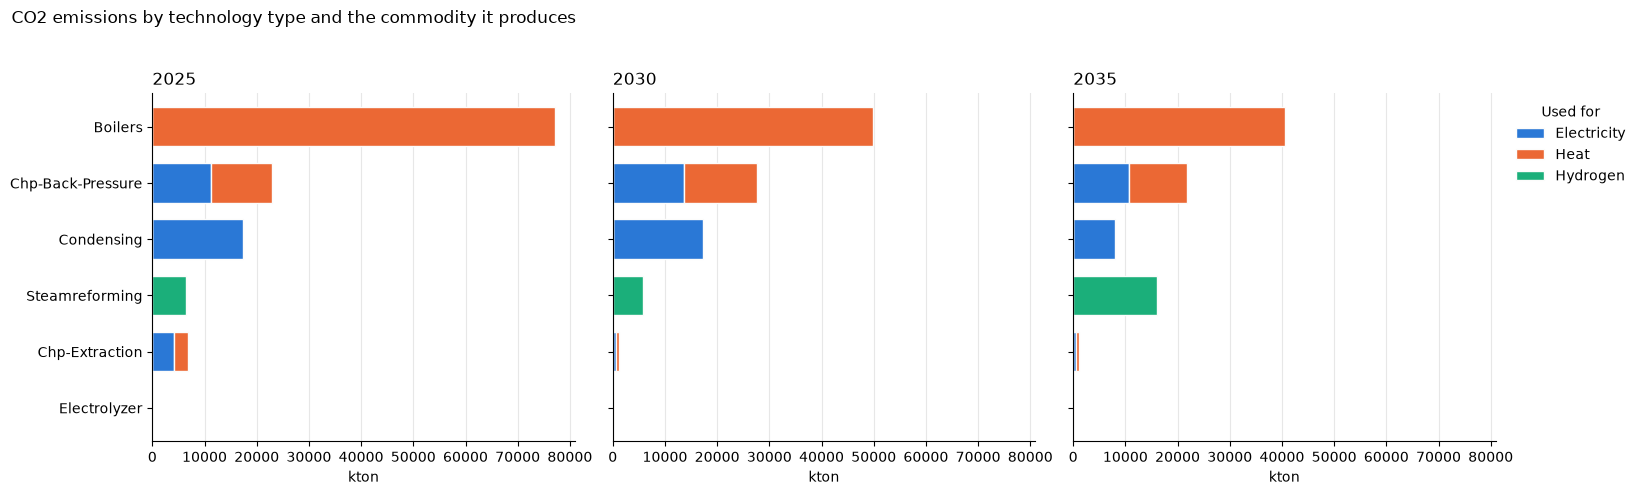

Year                     2025                          2030                    \
Use               Electricity     Heat Hydrogen Electricity     Heat Hydrogen   
Technology                                                                      
Boilers                   0.0  77066.4      0.0         0.0  49874.8      0.0   
Chp-Back-Pressure     11261.7  11574.2      0.0     13562.3  14107.7      0.0   
Condensing            17367.5      0.0      0.0     17321.2      0.0      0.0   
Steamreforming            0.0      0.0   6356.8         0.0      0.0   5782.7   
Chp-Extraction         4240.6   2634.4      0.0       710.9    528.4      0.0   
Electrolyzer              NaN      NaN      NaN         NaN      NaN      NaN   

Year                     2035                    
Use               Electricity     Heat Hydrogen  
Technology                                       
Boilers                   0.0  40671.7      0.0  
Chp-Back-Pressure     10706.6  11130.9      0.0  
Condensing             7924.6      0.0      0.0  
Steamreforming            0.0      0.0  15965.7  
Chp-Extraction          532.8    528.4      0.0  
Electrolyzer              0.0      0.0      0.4

In [28]:
# 6.1.1 CO2 emissions per technology type, split by the commodity it produces (kton)
EMI_KEYS = ["Year", "Region", "Area", "Generation"]
USE_COLORS = {"Electricity": "#2a78d6", "Heat": "#eb6834", "Hydrogen": "#1baf7a", "Other": GREY}

pro_all = get("PRO_YCRAGF").groupby(EMI_KEYS + ["Commodity"])["Value"].sum()
use_share = (pro_all / pro_all.groupby(level=EMI_KEYS).transform("sum").replace(0, np.nan)).rename("Share").reset_index()
emi_use = emi.merge(use_share, on=EMI_KEYS, how="left")
emi_use["Use"] = emi_use["Commodity"].fillna("OTHER").str.title()           # generators without output -> Other
emi_use["Value"] = emi_use["Value"] * emi_use["Share"].fillna(1)
tech_use = emi_use.groupby(["Year", "Technology", "Use"])["Value"].sum().unstack("Use", fill_value=0)
uses = [u for u in USE_COLORS if u in tech_use.columns]
techs = tech_use.groupby(level="Technology").sum().sum(axis=1).sort_values().index    # largest emitter on top

years = list(tech_use.index.get_level_values("Year").unique())
fig, axes = plt.subplots(1, len(years), figsize=(4.5 * len(years) + 3, 0.5 * len(techs) + 2), sharex=True, sharey=True, squeeze=False)
for ax, year in zip(axes.ravel(), years):
    t = tech_use.xs(year, level="Year").reindex(index=techs, columns=uses, fill_value=0)
    t.plot.barh(stacked=True, ax=ax, color=[USE_COLORS[u] for u in uses], width=0.7, edgecolor="#fcfcfb", linewidth=1, legend=False)
    ax.set_title(str(year), loc="left"); ax.set_xlabel("kton"); ax.set_ylabel("")
    ax.set_yticklabels([clean_name(c) for c in techs])
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
axes.ravel()[-1].legend(*axes.ravel()[0].get_legend_handles_labels(), title="Used for", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.suptitle("CO2 emissions by technology type and the commodity it produces", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

display(tech_use.reindex(columns=uses).unstack("Year").swaplevel(axis=1).sort_index(axis=1, level=0)
        .reindex(techs[::-1]).rename(index=clean_name).round(1))


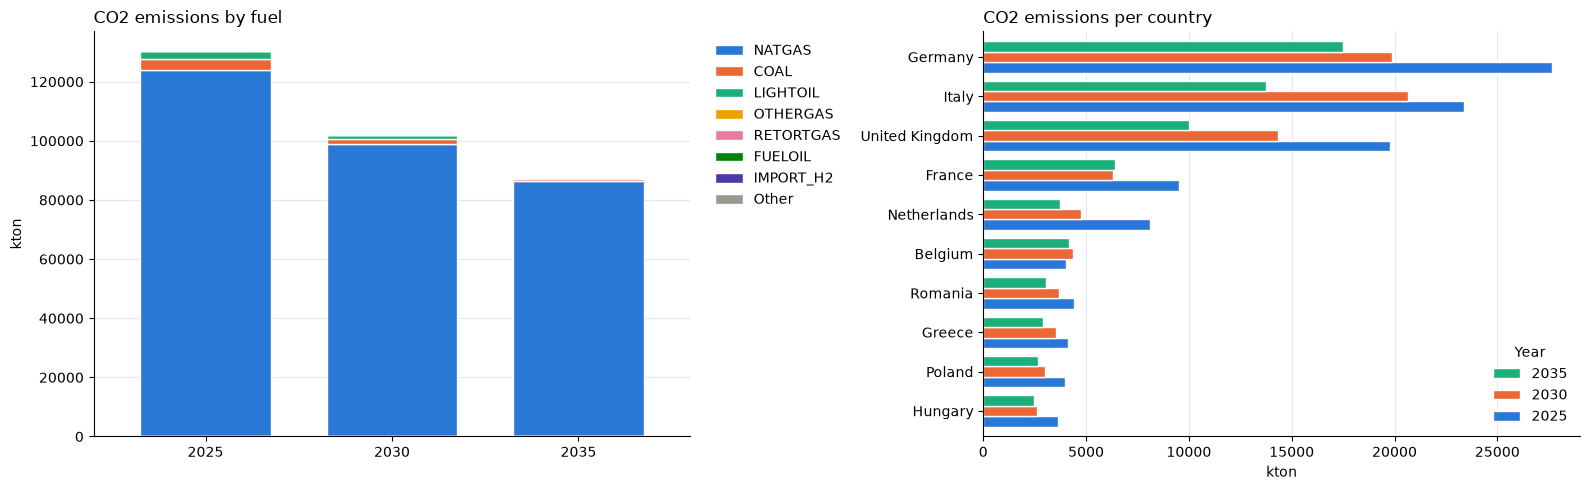

In [29]:
# 6.2 CO2 emissions by fuel (kton) and per country (kton)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fuel_e = emi.groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
stacked_by_label(fuel_e, "CO2 emissions by fuel", "kton", ax=axes[0])
country_bars(emi.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0),
             "CO2 emissions per country", "kton", ax=axes[1])
plt.tight_layout(); plt.show()

## 7. Validation: do the results make sense?
Checks that the solution is internally consistent and physically plausible. Every check is recorded as `PASS`, `WARN`, `FAIL` or `INFO` and collected in the summary table of 7.8.

| Section | What is checked |
|---|---|
| 7.1 Run | years and time resolution of the results |
| 7.2 - 7.4 Balance | supply = demand + net export for electricity (per region and time slice) and heat (per country and year); the electricity demand of every country is served |
| 7.5 Energy | annual energy dispatched = energy demand for electricity, heat, hydrogen and EV charging (net of storage and network losses, listed per year) |
| 7.6 Limits | no negative capacity or production, dispatch within capacity x 8760 h, transmission within capacity, storage levels within bounds, no negative wind/solar curtailment |
| 7.7 Plausibility | price range, implied plant efficiencies, missing values |

`FAIL` means the results are inconsistent and should not be used. `WARN` means something deserves a look but may be a property of the input data. Thresholds are set in each cell.

In [30]:
# 7.1 Run configuration (years and time resolution)
CHECKS = []          # every validation result is collected here and summarised in 7.8

def record(section, check, status, detail=""):
    """Register one validation result; status is PASS, WARN, FAIL or INFO."""
    CHECKS.append({"Section": section, "Check": check, "Status": status, "Detail": detail})

def grade(value, warn, fail):
    """PASS up to `warn`, WARN up to `fail`, FAIL above (value = size of the violation)."""
    return "PASS" if value <= warn else "WARN" if value <= fail else "FAIL"

MIN_SLICES = 24      # fewer time slices per year than this is flagged as a (probably test) coarse resolution

years = sorted(get("EL_DEMAND_YCR")["Year"].unique())
slices = get("EL_DEMAND_YCRST")[["Season", "Time"]].drop_duplicates()
resolution = f"{slices['Season'].nunique()} seasons x {slices['Time'].nunique()} time steps = {len(slices)} slices per year"
print(f"Years in the results : {', '.join(map(str, years))}")
print(f"Time resolution      : {resolution}")
record("Run", "Time resolution", "WARN" if len(slices) < MIN_SLICES else "INFO",
       resolution + (" - very coarse, compare only with runs at the same resolution" if len(slices) < MIN_SLICES else ""))

Years in the results : 2025, 2030, 2035
Time resolution      : 4 seasons x 72 time steps = 288 slices per year


In [31]:
# 7.2 Electricity balance per region and time slice (MWh): supply = demand + net export, so no demand is left unserved
def balance(df, area):
    """Per area and time slice (MWh): Supply, Demand, NetExport and Residual = Supply - Demand - NetExport.
    CURTAILMENT rows are informational (wind/solar are reported net of curtailment) and PRICE rows are skipped."""
    df = df[df["Unit"] == "MWh"]
    t = df["Technology"]
    is_dem, is_exp, is_curt = t.str.startswith("DEMAND"), t.eq("NETEXPORT"), t.eq("CURTAILMENT")
    keys = ["Year", "Country", area, "Season", "Time"]
    out = df[keys].assign(Supply=df["Value"].where(~(is_dem | is_exp | is_curt), 0),
                          Demand=df["Value"].where(is_dem, 0),
                          NetExport=df["Value"].where(is_exp, 0)).groupby(keys).sum()
    out["Residual"] = out["Supply"] - out["Demand"] - out["NetExport"]
    return out

el_bal = balance(get("EL_BALANCE_YCRST"), "Region")
rel = el_bal["Residual"].abs() / el_bal[["Supply", "Demand"]].max(axis=1).clip(lower=1)
record("Balance", "Electricity: supply = demand + net export in every region and time slice",
       grade(rel.max(), 1e-6, 1e-3), f"largest residual {el_bal['Residual'].abs().max():.3g} MWh ({rel.max():.1e} of the flow)")
unmet = el_bal["Residual"] < -1          # demand + exports larger than supply by more than 1 MWh
record("Balance", "Electricity: no region-slice with unmet demand", "FAIL" if unmet.any() else "PASS",
       f"{unmet.sum()} of {len(el_bal)} region-slices short of supply")


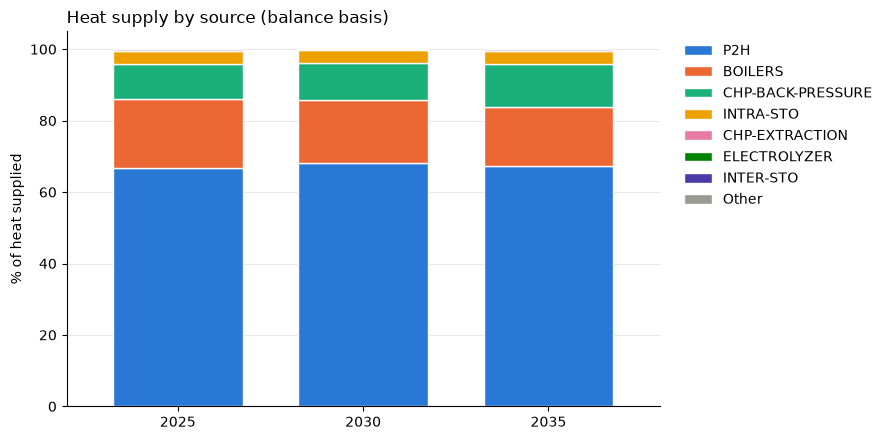

In [32]:
# 7.3 Heat balance per area and time slice (MWh): supply = demand + net export
# H_BALANCE_YCRAST has no row for the waste heat of electrolysers (a heat producer in PRO_YCRAGFST), so it is added to
# the supply here. Without it the balance is short by 1 - 3 % of the heat in countries with electrolysis.
h_bal = balance(get("H_BALANCE_YCRAST"), "Area")
elz = get("PRO_YCRAGFST").query("Commodity == 'HEAT' and Technology == 'ELECTROLYZER'")
elz = elz.groupby(["Year", "Country", "Area", "Season", "Time"])["Value"].sum()
h_bal["Supply"] += elz.reindex(h_bal.index).fillna(0)
h_bal["Residual"] = h_bal["Supply"] - h_bal["Demand"] - h_bal["NetExport"]
orphan = (~elz.index.isin(h_bal.index)).sum()                  # electrolyser heat in an area with no balance row

rel = h_bal["Residual"].abs() / h_bal[["Supply", "Demand"]].max(axis=1).clip(lower=1)
record("Balance", "Heat: supply (incl. electrolyser waste heat) = demand + net export in every area and time slice",
       "FAIL" if orphan else grade(rel.max(), 1e-6, 1e-3),
       f"largest residual {h_bal['Residual'].abs().max():.3g} MWh ({rel.max():.1e} of the flow)"
       + (f"; {orphan} electrolyser heat entries have no matching balance row" if orphan else ""))
unmet = h_bal["Residual"] < -1          # demand + exports larger than supply by more than 1 MWh
record("Balance", "Heat: no area-slice with unmet demand", "FAIL" if unmet.any() else "PASS",
       f"{unmet.sum()} of {len(h_bal)} area-slices short of supply")

# Heat supply by source on the balance basis (% of all heat supplied); the balance closes, so this is also the demand mix
h_raw = get("H_BALANCE_YCRAST")
h_raw = h_raw[(h_raw["Unit"] == "MWh") & ~h_raw["Technology"].str.startswith("DEMAND")
              & ~h_raw["Technology"].isin(["NETEXPORT", "CURTAILMENT"])]
h_src = h_raw.groupby(["Year", "Technology"])["Value"].sum().unstack("Technology").fillna(0)
h_src["ELECTROLYZER"] = elz.groupby("Year").sum().reindex(h_src.index).fillna(0)       # the source missing in the table
stacked_by_label(h_src.div(h_src.sum(axis=1), axis=0) * 100, "Heat supply by source (balance basis)", "% of heat supplied", n=7)
plt.tight_layout(); plt.show()


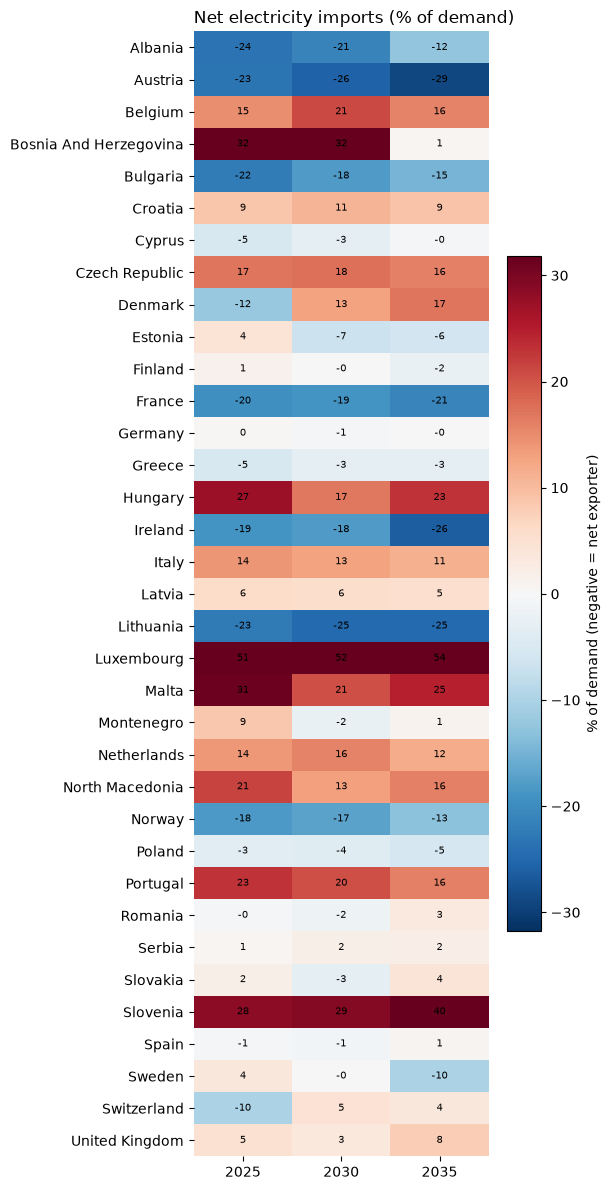

In [33]:
# 7.4 Is the electricity demand of every country supplied? Coverage = (domestic supply - net export) / demand
el_cy = el_bal.groupby(["Year", "Country"])[["Supply", "Demand", "NetExport"]].sum()
coverage = ((el_cy["Supply"] - el_cy["NetExport"]) / el_cy["Demand"] * 100).unstack("Year")        # % of demand served
imports = (-el_cy["NetExport"] / el_cy["Demand"] * 100).unstack("Year")                           # >0 net importer, <0 net exporter
record("Balance", "Electricity: demand of every country served (domestic supply + net imports)",
       grade((coverage - 100).abs().max().max() / 100, 1e-6, 1e-3),
       f"coverage {coverage.min().min():.4f} - {coverage.max().max():.4f} % across {len(coverage)} countries and {coverage.shape[1]} years")

# Net import dependence per country and year (% of electricity demand): red = importer, blue = exporter
fig, ax = plt.subplots(figsize=(max(6, 1.0 * imports.shape[1] + 3), 0.3 * len(imports) + 1.5))
lim = max(10, np.nanpercentile(imports.abs().values, 95))
im = ax.imshow(imports.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(imports.shape[1])); ax.set_xticklabels(imports.columns)
ax.set_yticks(range(len(imports))); ax.set_yticklabels([clean_name(c) for c in imports.index])
for i in range(imports.shape[0]):
    for j in range(imports.shape[1]):
        ax.text(j, i, f"{imports.values[i, j]:.0f}", ha="center", va="center", fontsize=7)
ax.set_title("Net electricity imports (% of demand)", loc="left")
for side in ax.spines.values(): side.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="% of demand (negative = net exporter)")
plt.tight_layout(); plt.show()


In [34]:
# 7.5 Energy dispatched = energy demand per carrier and year (TWh): electricity, heat, hydrogen and EV charging
# Dispatched = production of the carrier in PRO_YCRAGF without storage discharge. Demand = every category of the
# annual demand table (final demand, endogenous demand, net storage loss = charging - discharging, network losses). Net export is not added: the
# system-wide NETEXPORT of the balance tables is the transmission loss, which is already a demand category.
ENERGY_WARN, ENERGY_FAIL = 1e-3, 1e-2        # relative gap (of the larger of dispatch and demand) for PASS / WARN; above is FAIL

def annual(symbol):
    """Annual total per year of a result symbol, or None when the symbol is missing or empty in this run."""
    try:
        table = get(symbol)
    except Exception:
        return None
    return table.groupby("Year")["Value"].sum() if len(table) else None

dispatch = get("PRO_YCRAGF")
CARRIERS = {"Electricity": ("ELECTRICITY", "EL_DEMAND_YCR"), "Heat": ("HEAT", "H_DEMAND_YCRA"), "Hydrogen": ("HYDROGEN", "H2_DEMAND_YCR")}
parts = {}
for name, (commodity, symbol) in CARRIERS.items():
    p = dispatch[dispatch["Commodity"] == commodity]
    is_sto = p["Technology"].str.contains("STORAGE")
    parts[name] = pd.DataFrame({"Dispatched": p[~is_sto].groupby("Year")["Value"].sum(),
                                "Demand": get(symbol).groupby("Year")["Value"].sum(),
                                "Storage output": p[is_sto].groupby("Year")["Value"].sum()}).fillna(0)

# EV: energy delivered to the vehicles from the grid (charging minus discharging back) = EV charging demand (ENDO_EV)
ev_demand = get("EL_DEMAND_YCR").query("Category == 'ENDO_EV'").groupby("Year")["Value"].sum()
g2v, v2g, ev_net = annual("EV_G2V_Y"), annual("EV_V2G_Y"), annual("EV_NET_Y")
if g2v is None:
    ev_status = "INFO" if ev_demand.abs().max() < 1e-9 else "WARN"
    record("Energy", "EV: grid energy delivered = EV charging demand", ev_status,
           "no EV demand in this run" if ev_status == "INFO" else "EV_G2V_Y is missing - rerun the scenario after updating OUTPUT_SUMMARY.inc")
else:
    delivered = g2v.sub(v2g if v2g is not None else 0, fill_value=0)
    parts["EV charging"] = pd.DataFrame({"Dispatched": delivered, "Demand": ev_demand, "Storage output": 0.0}).fillna(0)

energy = pd.concat(parts, names=["Carrier"])
energy["Residual"] = energy["Dispatched"] - energy["Demand"]
energy["Gap"] = energy["Residual"].abs() / energy[["Dispatched", "Demand"]].max(axis=1).clip(lower=1e-9)

for name in CARRIERS:
    e = energy.loc[name]
    worst = e["Gap"].idxmax()
    detail = f"largest gap {e.loc[worst, 'Residual']:+.2f} TWh ({e['Gap'].max():.2%} of the flow, {worst})"
    if e["Gap"].max() > 1e-6 and ((e["Residual"] - e["Storage output"]).abs() <= 1e-3 * e[["Dispatched", "Demand"]].max(axis=1)).all():
        detail += (" - equals the storage discharge in every year, so the storage charging in the annual demand table looks incomplete"
                   " (the time-sliced balances in 7.2 / 7.3 close)")
    record("Energy", f"{name}: energy dispatched = energy demand (all years)", grade(e["Gap"].max(), ENERGY_WARN, ENERGY_FAIL), detail)

if "EV charging" in energy.index.get_level_values("Carrier"):
    e = energy.loc["EV charging"]
    net_gap = (ev_net.reindex(e.index).fillna(0) - e["Demand"]).abs().max() if ev_net is not None else np.nan
    record("Energy", "EV: grid energy delivered (charging - discharging) = EV charging demand",
           grade(max(e["Gap"].max(), 0 if np.isnan(net_gap) else net_gap / max(e["Demand"].max(), 1e-9)), 1e-6, 1e-3),
           f"largest gap {e['Residual'].abs().max():.3g} TWh on {e['Demand'].sum():.1f} TWh of EV demand"
           + ("" if ev_net is not None else "; EV_NET_Y missing, net exchange not cross-checked"))

display(energy.drop(columns="Gap").assign(**{"Residual %": energy["Residual"] / energy[["Dispatched", "Demand"]].max(axis=1).clip(lower=1e-9) * 100}).round(3))

Dispatched    Demand  Storage output  Residual  Residual %
Carrier     Year                                                            
Electricity 2025    4558.987  4558.987          18.397       0.0         0.0
            2030    4738.059  4738.059          14.408      -0.0        -0.0
            2035    4852.000  4852.000          12.837       0.0         0.0
Heat        2025    6128.170  6128.170         242.638       0.0         0.0
            2030    6127.848  6127.848         237.667       0.0         0.0
            2035    6128.966  6128.966         239.105      -0.0        -0.0
Hydrogen    2025     144.885   144.885           3.193       0.0         0.0
            2030     357.637   357.637          47.547       0.0         0.0
            2035     716.884   716.884          44.115       0.0         0.0
EV charging 2030      83.692    83.692           0.000      -0.0        -0.0
            2035     172.157   172.157           0.000      -0.0        -0.0

In [35]:
# 7.6 Physical limits: capacity, dispatch, transmission, storage and curtailment must respect their bounds
cap, pro = get("G_CAP_YCRAF"), get("PRO_YCRAGF")

cap_gen = cap.groupby(["Year", "Generation", "Region", "Area"])["Value"].sum()
record("Limits", "Installed capacity never negative", "FAIL" if (cap_gen < -1e-6).any() else "PASS",
       f"{(cap_gen < -1e-6).sum()} generators below zero (smallest {cap_gen.min():.2g} GW)")
record("Limits", "Production never negative", "FAIL" if (pro["Value"] < -1e-6).any() else "PASS",
       f"{(pro['Value'] < -1e-6).sum()} generator rows below zero")

# Annual production <= installed capacity x 8760 h. Hydrogen is skipped: reforming capacity is stated on a fuel basis
for commodity in ["ELECTRICITY", "HEAT"]:
    c = cap[cap["Commodity"] == commodity].groupby(["Year", "Generation"])["Value"].sum()
    p = pro[pro["Commodity"] == commodity].groupby(["Year", "Generation"])["Value"].sum()
    c = c.reindex(p.index).fillna(0)
    no_cap = ((p > 1e-6) & (c <= 1e-9)).sum()
    util = (p[c > 1e-9] / (c[c > 1e-9] * 8.76))                       # TWh / (GW x 8.76 TWh per GW-year)
    record("Limits", f"{commodity.title()}: production within capacity x 8760 h",
           "FAIL" if no_cap else grade(util.max() - 1, 1e-3, 5e-2),
           f"highest utilisation {util.max():.1%}; {no_cap} generators produce without installed capacity")

# Transmission: annual flow <= capacity x 8760 h (electricity lines and hydrogen pipelines)
for label, flow_sym, cap_sym in [("Electricity", "X_FLOW_YCR", "X_CAP_YCR"), ("Hydrogen", "XH2_FLOW_YCR", "XH2_CAP_YCR")]:
    f = get(flow_sym).groupby(["Year", "From", "To"])["Value"].sum()
    c = get(cap_sym).groupby(["Year", "From", "To"])["Value"].sum().reindex(f.index)
    u = f / (c * 8.76)
    no_cap = (f.gt(1e-6) & c.fillna(0).le(1e-9)).sum()
    record("Limits", f"{label} transmission: flow within capacity x 8760 h",
           "FAIL" if no_cap else grade(u[c > 1e-9].max() - 1, 1e-3, 5e-2),
           f"highest line utilisation {u[c > 1e-9].max():.1%}; {no_cap} links carry flow without capacity")

# Storage: level between zero and the installed storage capacity (level in MWh, capacity in GWh)
lvl = get("STORAGE_LEVEL").groupby(["Year", "Generation", "Area"])["Value"].agg(["min", "max"])
sto = get("G_STO_YCRAF").groupby(["Year", "Generation", "Area"])["Value"].sum() * 1000
lvl["cap"] = sto.reindex(lvl.index).fillna(0)                         # no capacity record = zero capacity
over = lvl["max"] > lvl["cap"] * 1.001 + 1e-3                         # 1e-3 MWh absorbs solver round-off
below = lvl["min"] < -1e-3
record("Limits", "Storage level between zero and capacity", "FAIL" if (over | below).any() else "PASS",
       f"{over.sum()} storages above capacity, {below.sum()} below zero, of {len(lvl)}")

# Curtailment of wind and solar is a positive quantity (hydro reservoirs net to about zero and are excluded)
curt_vre = get("CURT_YCRAGF").query("Technology in ['WIND-ON', 'WIND-OFF', 'SOLAR-PV']")
record("Limits", "Wind and solar curtailment not negative", "FAIL" if (curt_vre["Value"] < -1e-6).any() else "PASS",
       f"{(curt_vre['Value'] < -1e-6).sum()} rows below zero")


In [36]:
# 7.7 Plausibility: prices, plant efficiencies and missing values
price = get("EL_PRICE_YCR")
ok = price["Value"].between(-50, 500)
record("Plausibility", "Electricity prices in -50 .. 500 Money/MWh", "PASS" if ok.all() else "WARN",
       f"range {price['Value'].min():.1f} .. {price['Value'].max():.1f}, mean {price['Value'].mean():.1f}; "
       f"{(~ok).sum()} of {len(price)} region-years outside")

# Implied efficiency of combustion plants = output (all commodities) / fuel input. Above 100 % is a WARN, not a FAIL:
# it repeats identically in every year and area, so it comes from the technology input data, not from the solution
COMBUSTION = ["CONDENSING", "CHP-BACK-PRESSURE", "CHP-EXTRACTION", "BOILERS"]
out = pro.groupby(["Year", "Generation", "Technology"])["Value"].sum()
fuel_in = get("F_CONS_YCRA").groupby(["Year", "Generation", "Technology"])["Value"].sum()
eff = (out / fuel_in).replace([np.inf], np.nan).dropna()
eff = eff[eff.index.get_level_values("Technology").isin(COMBUSTION)]
above = sorted(set(eff[eff > 1.001].index.get_level_values("Generation")))
record("Plausibility", "Combustion plants: output / fuel input <= 100 %", "WARN" if above else "PASS",
       f"highest implied efficiency {eff.max():.1%} ({eff.idxmax()[1]}, {eff.idxmax()[0]}); median {eff.median():.1%}"
       + (f"; above 100 %: {', '.join(above[:5])}{' ...' if len(above) > 5 else ''} - check the technology data (condensing boilers can exceed 100 % on an LHV basis)" if above else ""))

# Missing values in the result tables used above
frames = {"production": pro, "capacity": cap, "price": price, "electricity balance": el_bal.reset_index(),
          "heat balance": h_bal.reset_index()}
numeric = ["Value", "Supply", "Demand", "NetExport", "Residual"]
nans = {k: int(v[[c for c in numeric if c in v]].isna().sum().sum()) for k, v in frames.items()}
record("Plausibility", "No missing values in the result tables", "FAIL" if any(nans.values()) else "PASS",
       ", ".join(f"{k}: {n}" for k, n in nans.items() if n) or "none found")


In [37]:
# 7.8 Summary of all validation checks
checks = pd.DataFrame(CHECKS)
print(checks["Status"].value_counts().reindex(["PASS", "INFO", "WARN", "FAIL"]).dropna().astype(int).to_dict())
colors = {"PASS": "#d8f0e3", "INFO": "#e6e6e6", "WARN": "#fbe9b7", "FAIL": "#f6c9c8"}
styler = checks.style.hide(axis="index").set_properties(subset=["Check", "Detail"], **{"text-align": "left"})
paint = getattr(styler, "map", None) or styler.applymap                  # Styler.map needs pandas >= 2.1
display(paint(lambda s: f"background-color: {colors.get(s, '')}", subset=["Status"]))


{'PASS': 19, 'INFO': 1, 'WARN': 1}


Section,Check,Status,Detail
Run,Time resolution,INFO,4 seasons x 72 time steps = 288 slices per year
Balance,Electricity: supply = demand + net export in every region and time slice,PASS,largest residual 1.31e-06 MWh (4.4e-09 of the flow)
Balance,Electricity: no region-slice with unmet demand,PASS,0 of 39744 region-slices short of supply
Balance,Heat: supply (incl. electrolyser waste heat) = demand + net export in every area and time slice,PASS,largest residual 8.44e-08 MWh (4.0e-08 of the flow)
Balance,Heat: no area-slice with unmet demand,PASS,0 of 356807 area-slices short of supply
Balance,Electricity: demand of every country served (domestic supply + net imports),PASS,coverage 100.0000 - 100.0000 % across 35 countries and 3 years
Energy,Electricity: energy dispatched = energy demand (all years),PASS,"largest gap +0.00 TWh (0.00% of the flow, 2025)"
Energy,Heat: energy dispatched = energy demand (all years),PASS,"largest gap +0.00 TWh (0.00% of the flow, 2025)"
Energy,Hydrogen: energy dispatched = energy demand (all years),PASS,"largest gap +0.00 TWh (0.00% of the flow, 2035)"
Energy,EV: grid energy delivered (charging - discharging) = EV charging demand,PASS,largest gap 3.69e-13 TWh on 255.8 TWh of EV demand


## 8. Summary across the topics
The main metrics of sections 1 - 6 per solved year (8.1) and their development over the years (8.2).

In [38]:
# 8.1 Summary across the topics, per solved year
# Curtailment rate = curtailed / (dispatched + curtailed) wind and solar electricity (%). Hydro-reservoir rows of CURT_YCRAGF
# net to about zero (see section 4) and are left out.
VRE_CURT_TECH = ["WIND-ON", "WIND-OFF", "SOLAR-PV"]
vre = "Technology in @VRE_CURT_TECH and Commodity == 'ELECTRICITY'"
vre_curt = curt.query(vre).groupby("Year")["Value"].sum()
vre_pro = pro.query(vre).groupby("Year")["Value"].sum()
vre_curt_rate = vre_curt / vre_curt.add(vre_pro, fill_value=0).replace(0, np.nan) * 100

summary = pd.DataFrame({
    "Electricity demand (TWh)": summary_demand["Electricity"],
    "Heat demand (TWh)": summary_demand["Heat"],
    "Hydrogen demand (TWh)": summary_demand["Hydrogen"],
    "EV charging (TWh)": ev,
    "Electricity capacity (GW)": cap[cap["Commodity"] == "ELECTRICITY"].groupby("Year")["Value"].sum(),
    "Electricity dispatched (TWh)": pro[pro["Commodity"] == "ELECTRICITY"].groupby("Year")["Value"].sum(),
    "Curtailment (% of wind & solar available)": vre_curt_rate,
    "Total cost (Mmoney)": obj.groupby("Year")["Value"].sum(),
    "CO2 emissions (kton)": emi.groupby("Year")["Value"].sum(),
}).round(1)
summary["Curtailment (% of wind & solar available)"] = vre_curt_rate.round(2)      # small shares: keep two decimals


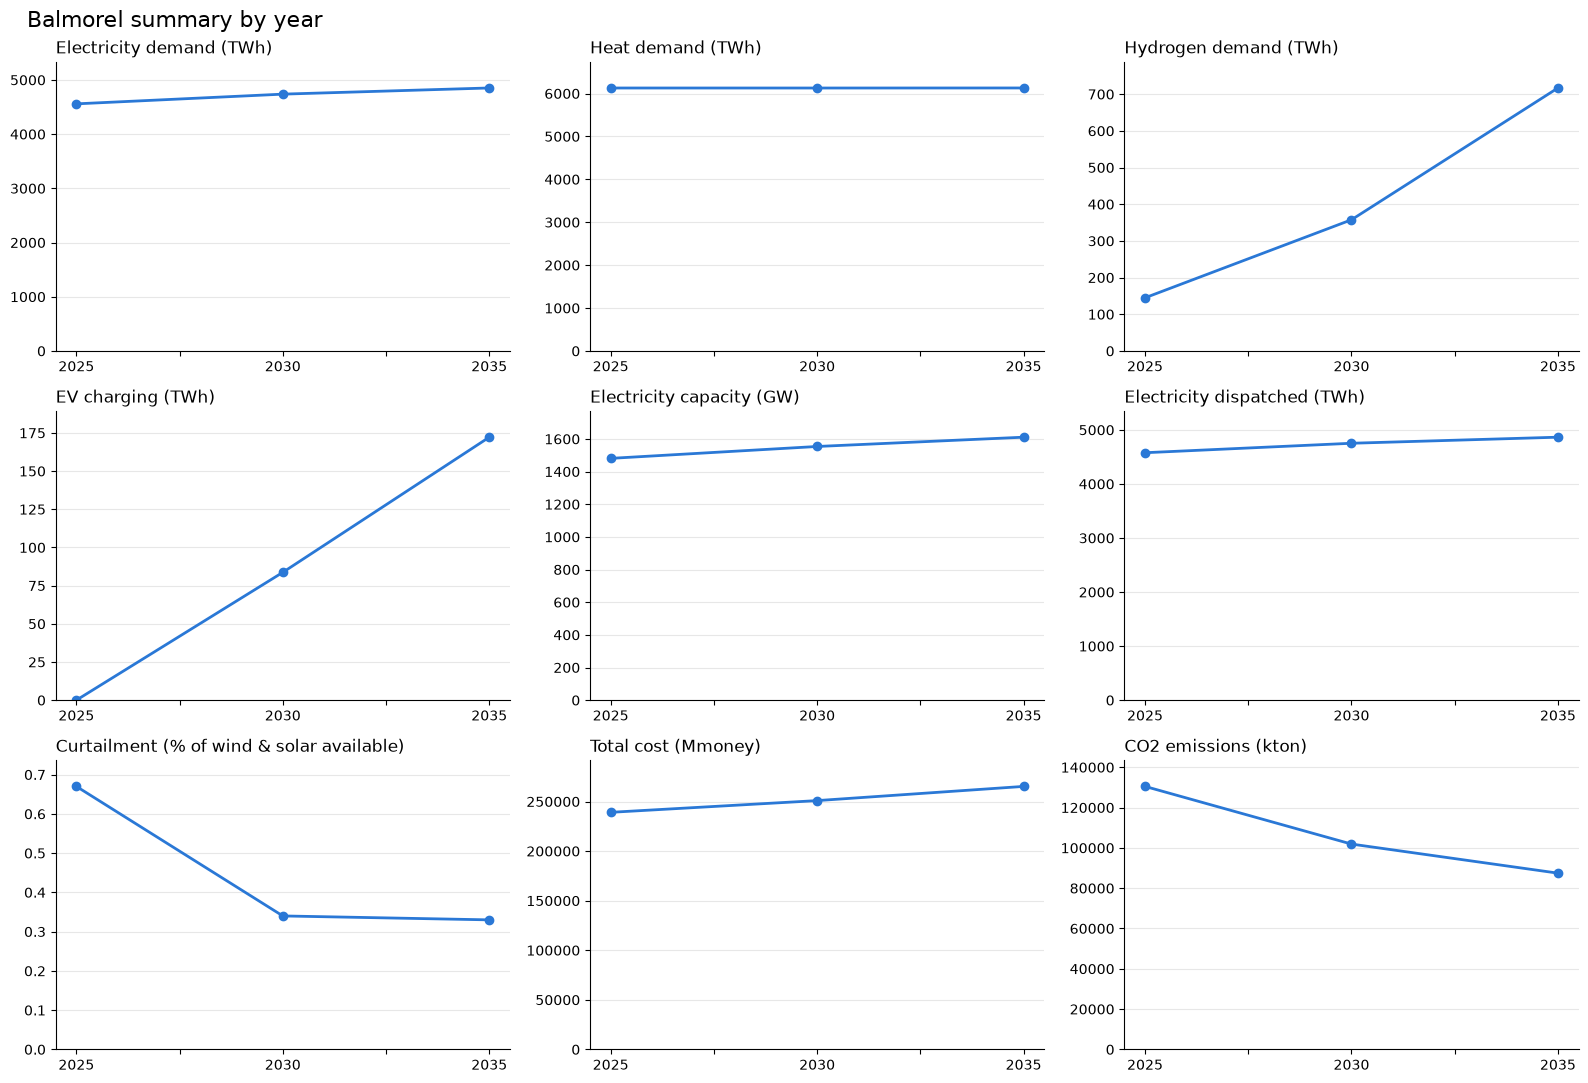

In [39]:
# 8.2 Plot the summary metrics by year
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.ravel()

for ax, column in zip(axes, summary.columns):
    summary[column].plot(
        ax=ax,
        marker="o",
        linewidth=2,
        color="#2a78d6"
    )
    ax.set_ylim(0, summary[column].max() * 1.1)
    ax.ticklabel_format(style="plain", axis="y")
    ax.set_title(column, loc="left")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

for ax in axes[len(summary.columns):]:
    ax.remove()

plt.suptitle("Balmorel summary by year", fontsize=16, x=0.02, ha="left")
plt.tight_layout()
plt.show()

## 9. Comparison with the base scenario

This part compares the scenario containing this notebook with the base scenario named by `BASE_SCENARIO` in 0.1 for every common solved year. The notebook can be copied into another scenario folder without changing these paths.

| Section | Content |
|---|---|
| 9 | Summary of the changes and helpers for the comparison charts |
| 10 System level | 10.1 capacity, 10.2 dispatch (with the response of the flexible demands, heat and hydrogen, curtailment, the `FOCUS_YEAR` mix and the hour-by-hour balance), 10.3 total system cost, 10.4 CO2 emissions |
| 11 Country level | 11.1 capacity, 11.2 dispatch, 11.3 CO2 emissions, 11.4 total system cost and marginal electricity cost |
| 12 Bottlenecks | shadow prices of the full model, scenario vs base |

### 9.1 Summary of the changes per year

Comparing base_notrans_test_3day_allhr_4S with the base scenario /zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S


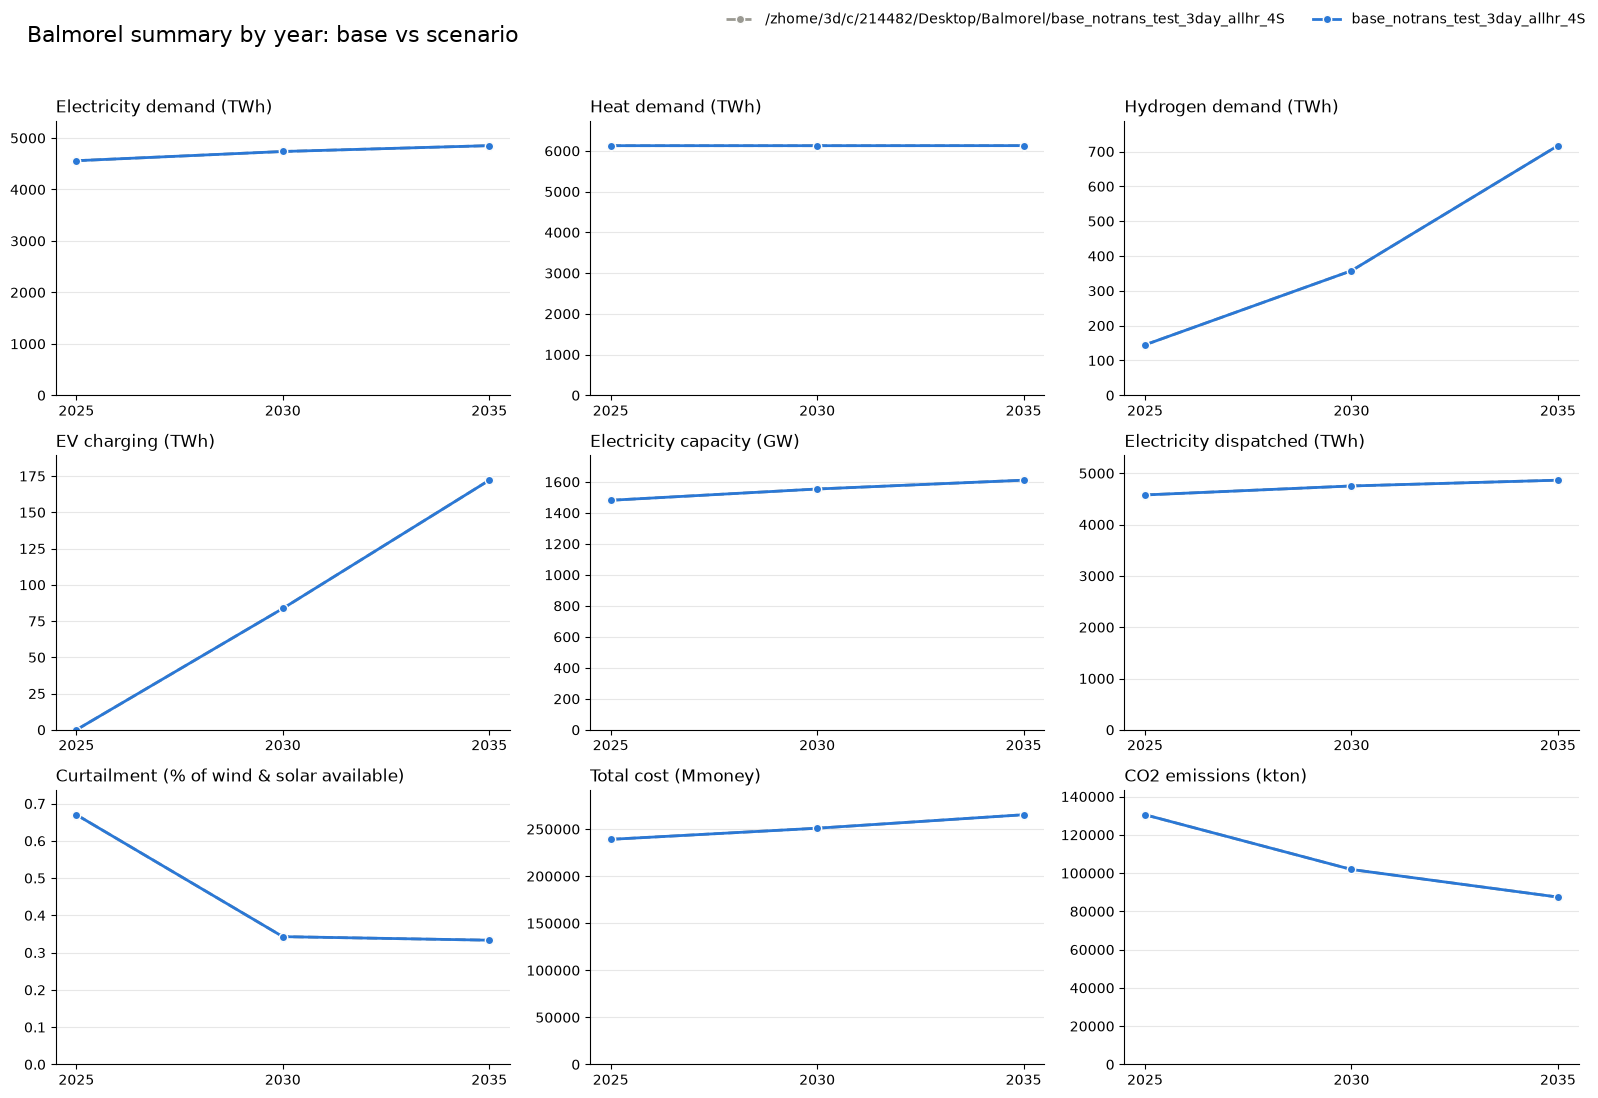

,Year,Metric,Base,Scenario,Change,Change (%)
0,2025,Total cost (Mmoney),239116.75,239116.75,0.0,0.0
1,2030,Total cost (Mmoney),250940.82,250940.82,0.0,0.0
2,2035,Total cost (Mmoney),265255.40,265255.40,0.0,0.0
3,2025,Electricity demand (TWh),4558.99,4558.99,0.0,0.0
4,2030,Electricity demand (TWh),4738.06,4738.06,0.0,0.0
5,2035,Electricity demand (TWh),4852.00,4852.00,0.0,0.0
6,2025,Transmission expansion (GW),0.00,0.00,0.0,NaN
7,2030,Transmission expansion (GW),0.00,0.00,0.0,NaN
8,2035,Transmission expansion (GW),0.00,0.00,0.0,NaN
9,2025,CO2 emissions (kton),130501.65,130501.65,0.0,0.0


/zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S: 4 seasons x 72 time steps, 8760 h represented per year
base_notrans_test_3day_allhr_4S: 4 seasons x 72 time steps, 8760 h represented per year
Weighted seasonal sum / annual EL_DEMAND_YCR (should be close to 1):


Scenario,/zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S,base_notrans_test_3day_allhr_4S
Year,,
2025,1.0040,1.0040
2030,1.0030,1.0030
2035,1.0026,1.0026


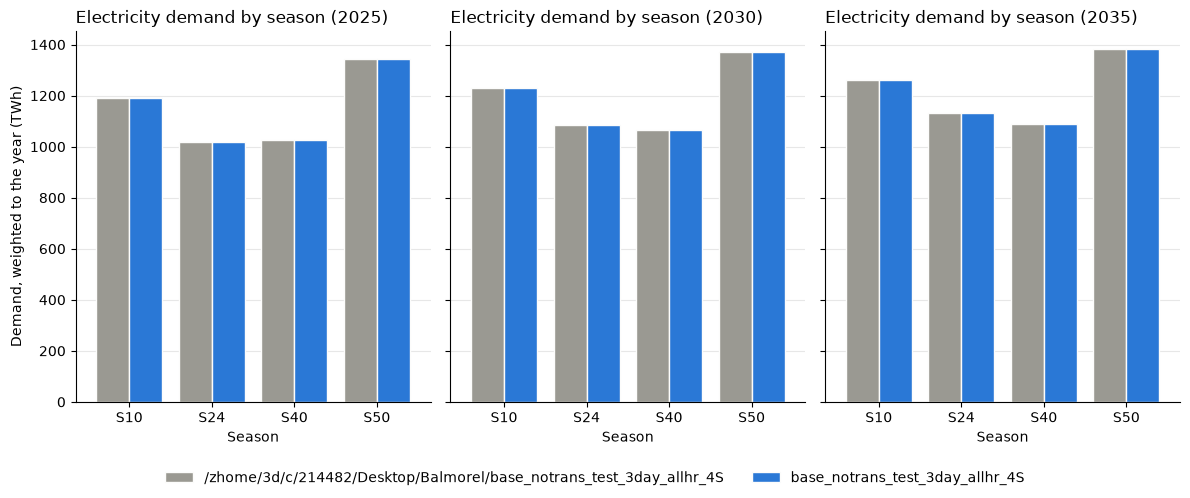

Electricity generation mix: percentage-point change (scenario minus base)


Fuel,BIOGAS,DUMMY,ELECTRIC,FUELOIL,HEAT,HYDROGEN,MUNIWASTE,NATGAS,NUCLEAR,OTHERGAS,RETORTGAS,STRAW,SUN,WASTEHEAT,WATER,WIND,WOOD,WOODCHIPS,WOODPELLETS,WOODWASTE
Year,,,,,,,,,,,,,,,,,,,,
2025,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2030,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2035,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


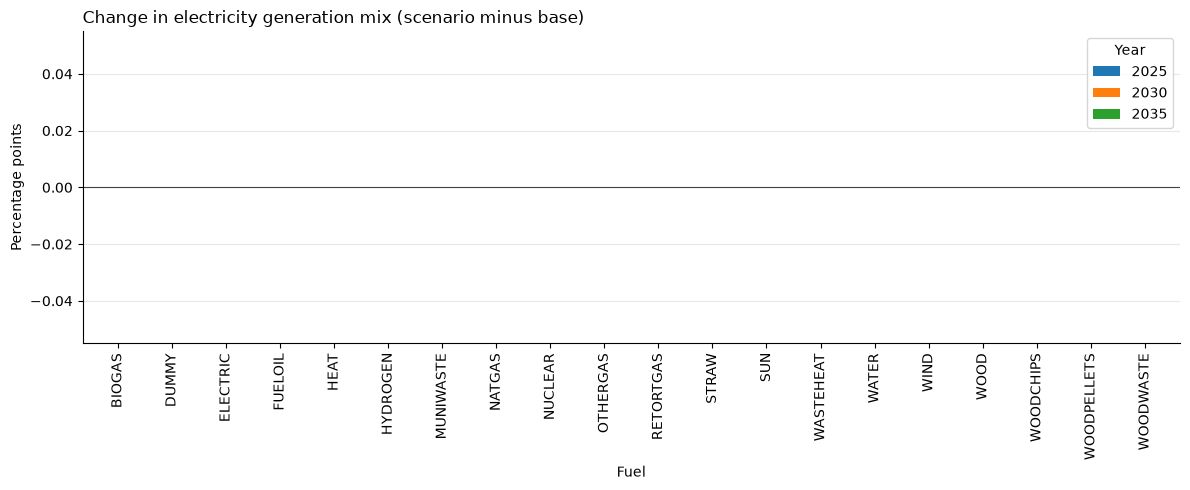

Electricity capacity mix: percentage-point change (scenario minus base)


Fuel,BIOGAS,BIOOIL,COAL,DUMMY,ELECTRIC,FUELOIL,HEAT,HYDROGEN,LIGHTOIL,LIGNITE,...,SHALE,STRAW,SUN,WASTEHEAT,WATER,WIND,WOOD,WOODCHIPS,WOODPELLETS,WOODWASTE
Year,,,,,,,,,,,,,,,,,,,,,
2025,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2030,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2035,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


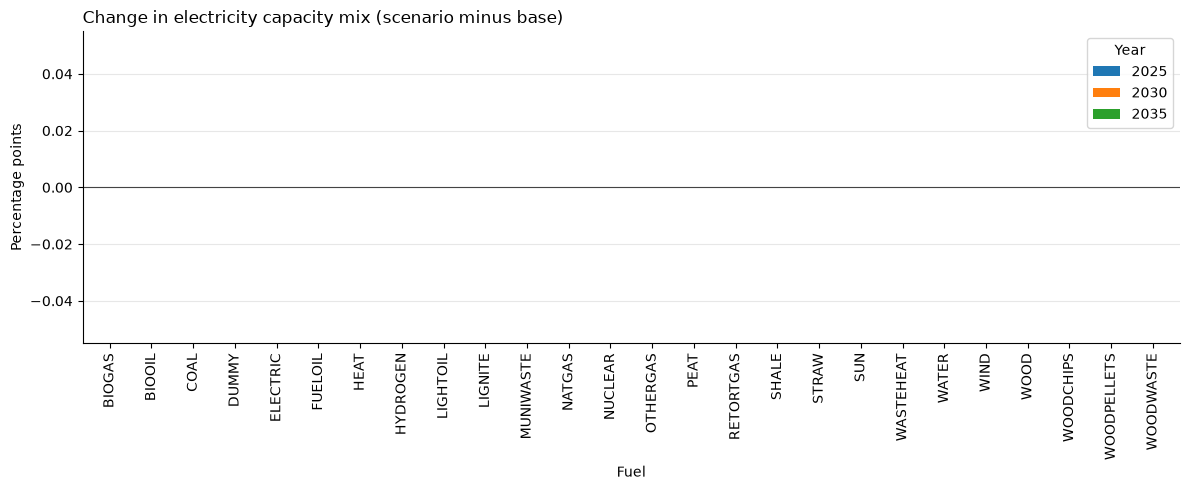

In [40]:
# 9.1 Summary comparison and changes in electricity generation/capacity mix
print(f"Comparing {SCENARIO} with the base scenario {BASE_SCENARIO}")

def scenario_result(results, scenario, symbol):
    table = results.get_result(symbol).rename(columns=RENAME)
    return table.loc[table["Scenario"].eq(scenario)].copy()

def solved_years(results, scenario, symbol="OBJ_YCR"):
    years = scenario_result(results, scenario, symbol)["Year"].astype(str)
    return sorted(years.drop_duplicates(), key=int)

COMPARISON_YEARS = sorted(set(solved_years(res, SCENARIO)).intersection(solved_years(base_res, BASE_SCENARIO)), key=int)
if not COMPARISON_YEARS:
    raise ValueError("No common solved years found for the scenario comparison")

def curtailment_rate(results, scenario):
    """Wind and solar curtailment per comparison year (% of available energy = dispatched + curtailed), as in 6.3."""
    def vre(symbol):
        t = scenario_result(results, scenario, symbol)
        t = t.loc[t["Technology"].isin(VRE_CURT_TECH) & t["Commodity"].eq("ELECTRICITY")]
        return t.assign(Year=t["Year"].astype(str)).groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0)
    curtailed = vre("CURT_YCRAGF")
    return curtailed / (curtailed + vre("PRO_YCRAGF")).replace(0, np.nan) * 100

def summary_by_year(results, scenario):
    """The metrics of 6.3 for one scenario, per comparison year (annual results, so independent of the time resolution)."""
    def total(symbol, query=None):
        t = scenario_result(results, scenario, symbol)
        if query is not None:
            t = t.query(query)
        return t.assign(Year=t["Year"].astype(str)).groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0)
    in_groups = "Category in @DEMAND_GROUP"                     # same demand categories as section 1 / 8.1
    return pd.DataFrame({
        "Electricity demand (TWh)": total("EL_DEMAND_YCR", in_groups),
        "Heat demand (TWh)": total("H_DEMAND_YCRA", in_groups),
        "Hydrogen demand (TWh)": total("H2_DEMAND_YCR", in_groups),
        "EV charging (TWh)": total("EL_DEMAND_YCR", "Category == 'ENDO_EV'"),
        "Electricity capacity (GW)": total("G_CAP_YCRAF", "Commodity == 'ELECTRICITY'"),
        "Electricity dispatched (TWh)": total("PRO_YCRAGF", "Commodity == 'ELECTRICITY'"),
        "Curtailment (% of wind & solar available)": curtailment_rate(results, scenario),
        "Total cost (Mmoney)": total("OBJ_YCR"),
        "CO2 emissions (kton)": total("EMI_YCRAG"),
    })

summary_cmp = {BASE_SCENARIO: summary_by_year(base_res, BASE_SCENARIO), SCENARIO: summary_by_year(res, SCENARIO)}
CMP_STYLE = {BASE_SCENARIO: dict(color="#9a9992", linestyle="--"), SCENARIO: dict(color="#2a78d6", linestyle="-")}

# Balmorel summary by year (as 8.2): base dashed grey, this scenario solid blue
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.ravel()
for ax, column in zip(axes, summary_cmp[SCENARIO].columns):
    for name, table in summary_cmp.items():
        ax.plot(table.index, table[column], marker="o", linewidth=2, markeredgecolor="#fcfcfb", label=name, **CMP_STYLE[name])
    top = max(t[column].max() for t in summary_cmp.values())
    ax.set_ylim(0, top * 1.1 if top > 0 else 1)
    ax.ticklabel_format(style="plain", axis="y")
    ax.set_title(column, loc="left"); ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
for ax in axes[len(summary_cmp[SCENARIO].columns):]:
    ax.remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False)
plt.suptitle("Balmorel summary by year: base vs scenario", fontsize=16, x=0.02, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

def yearly_total(results, scenario, symbol):
    table = scenario_result(results, scenario, symbol)
    return (table.assign(Year=table["Year"].astype(str)).groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0))

def transmission_expansion(results, scenario):
    table = scenario_result(results, scenario, "X_CAP_YCR")
    table = table.loc[table["Category"].eq("ENDOGENOUS")]
    return (table.assign(Year=table["Year"].astype(str)).groupby("Year")["Value"].sum().reindex(COMPARISON_YEARS, fill_value=0))

def fuel_mix(results, scenario, symbol):
    table = scenario_result(results, scenario, symbol)
    table = table.loc[table["Commodity"].eq("ELECTRICITY")].copy()
    table["Year"] = table["Year"].astype(str)
    return (table.groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel", fill_value=0).reindex(COMPARISON_YEARS, fill_value=0))

def price_by(results, scenario, by):
    """Demand-weighted average marginal electricity cost (Money/MWh) per year and `by` (None = whole system).
    EL_PRICE_YCR (AVERAGE) is the time-averaged marginal cost of the electricity balance per region; each region is
    weighted by its annual electricity demand (EL_DEMAND_YCR, all categories)."""
    price = scenario_result(results, scenario, "EL_PRICE_YCR")
    price = price.loc[price["Category"].eq("AVERAGE")].assign(Year=lambda d: d["Year"].astype(str))
    dem = scenario_result(results, scenario, "EL_DEMAND_YCR").assign(Year=lambda d: d["Year"].astype(str))
    dem = dem.groupby(["Year", "Region"])["Value"].sum().rename("Demand")
    t = price.set_index(["Year", "Region"]).join(dem, how="left").fillna({"Demand": 0}).reset_index()
    keys = ["Year"] + ([by] if by else [])
    t = t.assign(PxD=t["Value"] * t["Demand"]).groupby(keys)[["PxD", "Demand"]].sum()
    out = t["PxD"] / t["Demand"].replace(0, np.nan)
    return out.reindex(COMPARISON_YEARS) if by is None else out

metrics = {"Total cost (Mmoney)": "OBJ_YCR", "Electricity demand (TWh)": "EL_DEMAND_YCR", "Transmission expansion (GW)": None, "CO2 emissions (kton)": "EMI_YCRAG", "Curtailment (% of wind & solar available)": "CURT_RATE",
           "Electricity marginal cost (Money/MWh, demand-weighted)": "PRICE"}
rows = []
for metric, symbol in metrics.items():
    if symbol is None:
        scenario_values = transmission_expansion(res, SCENARIO)
        base_values = transmission_expansion(base_res, BASE_SCENARIO)
    elif symbol == "CURT_RATE":
        scenario_values = curtailment_rate(res, SCENARIO)
        base_values = curtailment_rate(base_res, BASE_SCENARIO)
    elif symbol == "PRICE":
        scenario_values = price_by(res, SCENARIO, None)
        base_values = price_by(base_res, BASE_SCENARIO, None)
    else:
        scenario_values = yearly_total(res, SCENARIO, symbol)
        base_values = yearly_total(base_res, BASE_SCENARIO, symbol)
    for year in COMPARISON_YEARS:
        base_value = float(base_values.loc[year])
        scenario_value = float(scenario_values.loc[year])
        rows.append({"Year": int(year), "Metric": metric, "Base": base_value, "Scenario": scenario_value, "Change": scenario_value - base_value, "Change (%)": ((scenario_value - base_value) / base_value * 100 if base_value else float("nan"))})

comparison = pd.DataFrame(rows).round(2)
display(comparison)

# Seasonal electricity demand. The runs can have a different time resolution (e.g. 4 seasons x 72 h vs 4 seasons x 168 h),
# and EL_DEMAND_YCRST holds the MWh of one represented hour per slice. Summing the slices therefore scales with the number of
# hours in the run. Each slice is weighted with IHOURSINST (hours of the year it represents, sum = 8760), which gives the
# annual energy per season on the same basis as EL_DEMAND_YCR.
def slice_hours(run_dir):
    """Hours represented by each (Season, Time) slice, read from IHOURSINST in all_endofmodel.gdx (None if unavailable)."""
    try:
        import gams.transfer as gt
        container = gt.Container()
        container.read(str(Path(run_dir) / "all_endofmodel.gdx"), symbols=["IHOURSINST"])
        w = container["IHOURSINST"].records
        return pd.Series(w["value"].to_numpy(), index=pd.MultiIndex.from_arrays(
            [w.iloc[:, 0].astype(str), w.iloc[:, 1].astype(str)], names=["Season", "Time"]), name="Hours")
    except Exception as exc:
        print(f"IHOURSINST not readable in {run_dir} ({exc}); assuming 8760 h spread evenly over the slices")
        return None

def seasonal_electricity_demand(results, scenario, run_dir):
    """Annual electricity demand per year and season (TWh) = sum over slices of MWh x hours represented."""
    table = scenario_result(results, scenario, "EL_DEMAND_YCRST")
    if "Unit" in table.columns:
        table = table.loc[table["Unit"].eq("MWh")]
    table = table.assign(Year=table["Year"].astype(str), Season=table["Season"].astype(str), Time=table["Time"].astype(str))
    slices = table.groupby(["Year", "Season", "Time"])["Value"].sum().reset_index()
    hours = slice_hours(run_dir)
    if hours is None:
        n = slices.groupby("Year")["Time"].transform("size")
        slices["Hours"] = 8760 / n
    else:
        slices = slices.join(hours, on=["Season", "Time"])
        if slices["Hours"].isna().any():
            raise ValueError(f"{scenario}: {slices['Hours'].isna().sum()} demand slices have no IHOURSINST weight")
    resolution = f"{slices['Season'].nunique()} seasons x {slices['Time'].nunique()} time steps"
    print(f"{scenario}: {resolution}, {slices.groupby('Year')['Hours'].sum().iloc[0]:.0f} h represented per year")
    out = (slices.assign(Energy=slices["Value"] * slices["Hours"] / 1e6)
                 .groupby(["Year", "Season"])["Energy"].sum().rename("Demand (TWh)"))
    seasons = sorted(slices["Season"].unique())
    index = pd.MultiIndex.from_product([COMPARISON_YEARS, seasons], names=["Year", "Season"])
    return out.reindex(index, fill_value=0).reset_index()

seasonal_demand = pd.concat([
    seasonal_electricity_demand(base_res, BASE_SCENARIO, BASE_RESULTS_DIR).assign(Scenario=BASE_SCENARIO),
    seasonal_electricity_demand(res, SCENARIO, RUN_DIR).assign(Scenario=SCENARIO),
], ignore_index=True)

# Consistency check: the weighted seasons add up to the annual demand of EL_DEMAND_YCR
check = seasonal_demand.groupby(["Scenario", "Year"])["Demand (TWh)"].sum().unstack("Scenario")[[BASE_SCENARIO, SCENARIO]]
annual_el = pd.DataFrame({BASE_SCENARIO: yearly_total(base_res, BASE_SCENARIO, "EL_DEMAND_YCR"),
                          SCENARIO: yearly_total(res, SCENARIO, "EL_DEMAND_YCR")})
print("Weighted seasonal sum / annual EL_DEMAND_YCR (should be close to 1):")
display((check / annual_el).round(4))

fig, axes = plt.subplots(1, len(COMPARISON_YEARS), figsize=(max(12, 4 * len(COMPARISON_YEARS)), 5), squeeze=False, sharey=True)
for ax, year in zip(axes.ravel(), COMPARISON_YEARS):
    plot_data = seasonal_demand.loc[seasonal_demand["Year"].eq(year)]
    plot_data = plot_data.pivot(index="Season", columns="Scenario", values="Demand (TWh)")[[BASE_SCENARIO, SCENARIO]]
    plot_data.plot.bar(ax=ax, width=0.8, color=[CMP_STYLE[BASE_SCENARIO]["color"], CMP_STYLE[SCENARIO]["color"]], edgecolor="#fcfcfb")
    ax.set_title(f"Electricity demand by season ({year})", loc="left")
    ax.set_ylabel("Demand, weighted to the year (TWh)")
    ax.set_xlabel("Season")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.get_legend().remove()
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
for title, symbol in [("Electricity generation mix", "PRO_YCRAGF"), ("Electricity capacity mix", "G_CAP_YCRAF")]:
    scenario_mix = fuel_mix(res, SCENARIO, symbol)
    base_mix = fuel_mix(base_res, BASE_SCENARIO, symbol)
    fuels = scenario_mix.columns.union(base_mix.columns)
    scenario_mix = scenario_mix.reindex(columns=fuels, fill_value=0)
    base_mix = base_mix.reindex(columns=fuels, fill_value=0)
    scenario_pct = scenario_mix.div(scenario_mix.sum(axis=1).replace(0, float("nan")), axis=0) * 100
    base_pct = base_mix.div(base_mix.sum(axis=1).replace(0, float("nan")), axis=0) * 100
    change_pct = (scenario_pct - base_pct).fillna(0).round(2)
    print(f"{title}: percentage-point change (scenario minus base)")
    display(change_pct)
    ax = change_pct.T.plot.bar(figsize=(max(12, 0.5 * len(COMPARISON_YEARS) + 5), 5), width=0.8)
    ax.axhline(0, color="#444444", linewidth=0.8)
    ax.set_title(f"Change in {title.lower()} (scenario minus base)", loc="left")
    ax.set_ylabel("Percentage points")
    ax.set_xlabel("Fuel")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()

In [41]:
# 9.2 Helpers for the base-vs-scenario charts of sections 10 and 11
VRE_TECH = {"WIND-ON": "Wind-on", "WIND-OFF": "Wind-off", "SOLAR-PV": "Solar"}     # curtailment is only meaningful for these
SCEN_COLORS = {BASE_SCENARIO: "#9a9992", SCENARIO: "#2a78d6"}                      # base = grey, this scenario = blue

def by_year(results, scenario, symbol, by, commodity=None):
    """Year x `by` table of Value for the comparison years (optionally one output commodity)."""
    table = scenario_result(results, scenario, symbol)
    if commodity is not None:
        table = table.loc[table["Commodity"].eq(commodity)]
    table = table.assign(Year=table["Year"].astype(str))
    return table.groupby(["Year", by])["Value"].sum().unstack(by, fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)

def align(base_t, scen_t, n=7):
    """Same columns in both tables: the n largest (summed over both scenarios) keep their name, the rest is 'Other'."""
    cols = base_t.columns.union(scen_t.columns)
    base_t, scen_t = base_t.reindex(columns=cols, fill_value=0), scen_t.reindex(columns=cols, fill_value=0)
    order = (base_t.abs().sum() + scen_t.abs().sum()).sort_values(ascending=False).index
    keep, rest = list(order[:n]), list(order[n:])
    def fold(t):
        return t[keep].assign(Other=t[rest].sum(axis=1)) if rest else t[keep]
    base_t, scen_t = fold(base_t), fold(scen_t)
    colors = dict(zip(base_t.columns, PALETTE[:len(keep)] + [GREY]))
    return base_t, scen_t, colors

def style(ax, title, ylabel, axis="y"):
    ax.set_title(title, loc="left"); ax.set_ylabel(ylabel); ax.set_xlabel("")
    ax.grid(axis=axis, alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)

def paired_stacked(base_t, scen_t, colors, title, unit):
    """Left: per year a base bar (hatched) next to a scenario bar, stacked by column.
    Right: change per column (scenario - base), one bar per year."""
    years = list(base_t.index)
    x = np.arange(len(years))
    w = 0.38
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(max(14, 1.6 * len(years) + 10), 5), gridspec_kw={"width_ratios": [1.2, 1]})
    for offset, t, hatch in [(-w / 2 - 0.01, base_t, "//"), (w / 2 + 0.01, scen_t, None)]:
        pos, neg = np.zeros(len(years)), np.zeros(len(years))
        for col in t.columns:
            v = t[col].to_numpy(dtype=float)
            bottom = np.where(v >= 0, pos, neg)
            ax.bar(x + offset, v, w, bottom=bottom, color=colors[col], edgecolor="#fcfcfb", linewidth=0.8, hatch=hatch,
                   label=clean_name(col) if hatch is None else None)
            pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
    ax.set_xticks(x); ax.set_xticklabels([f"{y}\nbase | scen." for y in years])
    ax.axhline(0, color="#52514e", linewidth=0.8)
    style(ax, f"{title}: base (hatched) vs {SCENARIO}", unit)
    ax.legend(bbox_to_anchor=(1.0, 1), loc="upper left", frameon=False, fontsize=9)

    diff = scen_t - base_t
    diff.T.plot.bar(ax=ax2, color=year_colors(len(years)), width=0.8, edgecolor="#fcfcfb", linewidth=0.8)
    ax2.set_xticklabels([clean_name(c) for c in diff.columns], rotation=45, ha="right")
    ax2.axhline(0, color="#52514e", linewidth=0.8)
    style(ax2, f"Change: {title} (scenario - base)", unit)
    ax2.legend(title="Year", frameon=False)
    plt.tight_layout(); plt.show()
    return diff

def country_change(base_c, scen_c, title, unit, n=10):
    """Horizontal bars of the change per country (scenario - base) in the last common year, the n largest absolute changes."""
    d = scen_c.sub(base_c, fill_value=0)
    d = d.loc[d.abs().sort_values(ascending=False).head(n).index].iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(d) + 1.5))
    ax.barh([clean_name(c) for c in d.index], d.values, color=np.where(d.values >= 0, "#e34948", "#2a78d6"), height=0.7)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    style(ax, title, "", axis="x"); ax.set_xlabel(unit)
    plt.tight_layout(); plt.show()

LAST_YEAR = COMPARISON_YEARS[-1]

def last_year_by_country(results, scenario, symbol, commodity=None, technologies=None):
    table = scenario_result(results, scenario, symbol)
    table = table.loc[table["Year"].astype(str).eq(LAST_YEAR)]
    if commodity is not None:
        table = table.loc[table["Commodity"].eq(commodity)]
    if technologies is not None:
        table = table.loc[table["Technology"].isin(technologies)]
    return table.groupby("Country")["Value"].sum()

def datacenter_demand(folder, year, region_country):
    """Data-center demand (TWh) per country in `year` from the DE_DATACENTER.inc used by a run (its own data folder,
    else base/data, as in DE.inc). `region_country` maps region -> country."""
    for path in [folder / "data" / "DE_DATACENTER.inc", folder.parent / "base" / "data" / "DE_DATACENTER.inc"]:
        if path.exists():
            text = path.read_text(encoding="utf-8", errors="ignore")
            header = re.search(r"(?m)^\s*((?:20\d{2}\s+){2,}20\d{2})\s*$", text)
            years = header.group(1).split()
            rows = {}
            for line in text[header.end():].splitlines():
                parts = line.split()
                if len(parts) == len(years) + 1 and parts[0] in region_country.index:
                    rows[parts[0]] = float(parts[1 + years.index(year)]) if year in years else 0.0
            return pd.Series(rows, dtype=float).groupby(region_country).sum() / 1e6
    return pd.Series(dtype=float)

# Year of the focus charts (10.2.4, 10.4.2, 11.3, 11.4): 2035, or the last common year if 2035 is not solved
FOCUS_YEAR = "2035" if "2035" in COMPARISON_YEARS else COMPARISON_YEARS[-1]


## 10. System level: base vs scenario
Totals over all countries, in the order capacity, dispatch, cost and CO2 emissions.

### 10.1 Installed capacity per fuel: base vs scenario
`G_CAP_YCRAF` (GW), installed capacity = exogenous + endogenous + decommissioning, for the commodities in `COMPARE_COMMODITIES`.
The 7 largest fuels (over both scenarios) keep their own colour, the rest is `Other`; colours are the same in both scenarios.

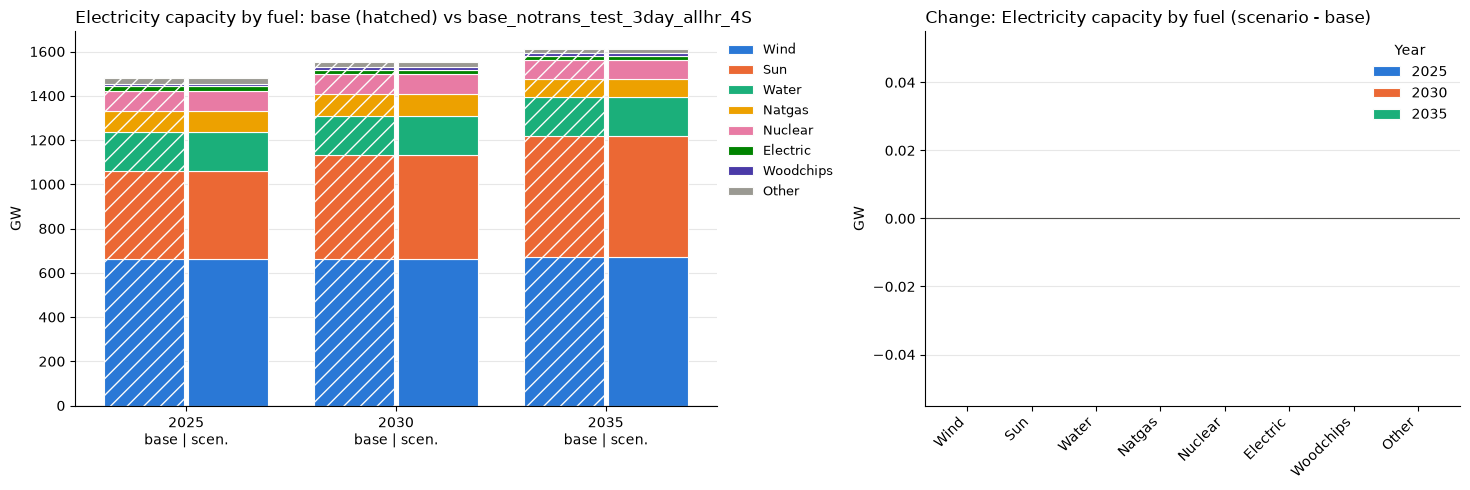

Electricity capacity: change per fuel (GW, scenario - base)


Fuel,WIND,SUN,WATER,NATGAS,NUCLEAR,ELECTRIC,WOODCHIPS,Other,Total
Year,,,,,,,,,
2025,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2030,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2035,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [42]:
# 10.1 Installed capacity per fuel (GW)
COMPARE_COMMODITIES = ["ELECTRICITY"]          # add "HEAT" / "HYDROGEN" to compare those capacity mixes as well
for commodity in COMPARE_COMMODITIES:
    base_t, scen_t, colors = align(by_year(base_res, BASE_SCENARIO, "G_CAP_YCRAF", "Fuel", commodity),
                                   by_year(res, SCENARIO, "G_CAP_YCRAF", "Fuel", commodity))
    diff = paired_stacked(base_t, scen_t, colors, f"{commodity.title()} capacity by fuel", "GW")
    print(f"{commodity.title()} capacity: change per fuel (GW, scenario - base)")
    display(diff.assign(Total=diff.sum(axis=1)).round(2))

### 10.2 Dispatch: electricity generated per fuel, base vs scenario
`PRO_YCRAGF` (TWh) for the commodities in `COMPARE_COMMODITIES` (set in 10.1), plus the countries whose electricity generation changes most in the last common year.

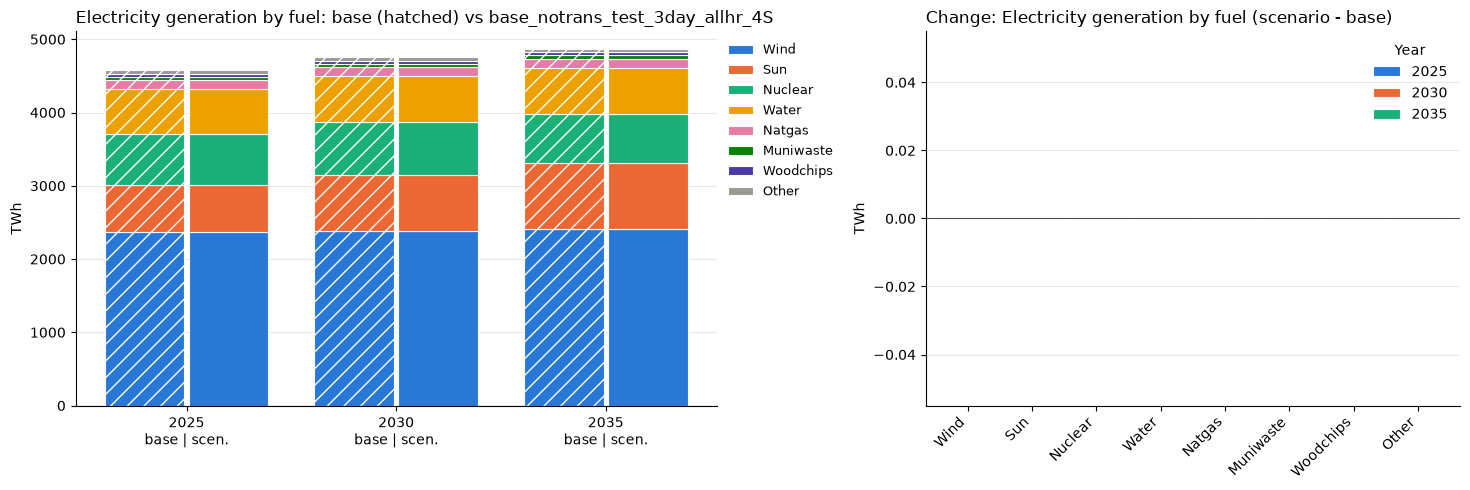

Electricity generation: change per fuel (TWh, scenario - base)


Fuel,WIND,SUN,NUCLEAR,WATER,NATGAS,MUNIWASTE,WOODCHIPS,Other,Total
Year,,,,,,,,,
2025,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2030,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2035,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


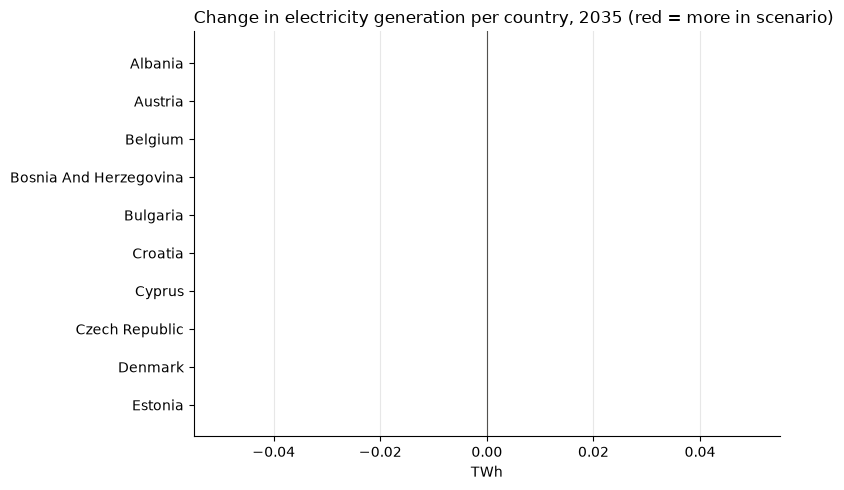

In [43]:
# 10.2 Generation per fuel (TWh)
for commodity in COMPARE_COMMODITIES:
    base_t, scen_t, colors = align(by_year(base_res, BASE_SCENARIO, "PRO_YCRAGF", "Fuel", commodity),
                                   by_year(res, SCENARIO, "PRO_YCRAGF", "Fuel", commodity))
    diff = paired_stacked(base_t, scen_t, colors, f"{commodity.title()} generation by fuel", "TWh")
    print(f"{commodity.title()} generation: change per fuel (TWh, scenario - base)")
    display(diff.assign(Total=diff.sum(axis=1)).round(2))

country_change(last_year_by_country(base_res, BASE_SCENARIO, "PRO_YCRAGF", "ELECTRICITY"),
               last_year_by_country(res, SCENARIO, "PRO_YCRAGF", "ELECTRICITY"),
               f"Change in electricity generation per country, {LAST_YEAR} (red = more in scenario)", "TWh")

#### 10.2.1 Response of the flexible electricity demands
The data-center demand is exogenous, but most of the other electricity demand in `EL_DEMAND_YCR` is chosen by the model (power-to-heat, electrolysis, storage charging, EV charging, CCS) or follows from it (grid losses). The waterfall starts from the change in exogenous demand (scenario - base, essentially the additional data-center demand) and shows how each flexible demand responds, ending at the net change in annual electricity demand of 9.1. Red bars add demand, green bars are demand reductions.

In [44]:
# 10.2.1 Waterfall of the change in annual electricity demand (TWh): exogenous demand -> flexible demand response -> net change
DEMAND_RESPONSE_LABEL = {"EXOGENOUS": "Exogenous demand\n(incl. data centres)", "ENDOGENOUS_ELECT2HEAT": "Power-to-heat",
                         "ENDO_H2": "Electrolysis (H2)", "ENDO_INTRASTO": "Storage charging", "ENDO_EV": "EV charging",
                         "ENDO_CCS": "CCS", "DIST_LOSSES": "Grid losses", "TRANS_LOSSES": "Grid losses"}

def demand_by_category(results, scenario):
    t = scenario_result(results, scenario, "EL_DEMAND_YCR").assign(Year=lambda d: d["Year"].astype(str))
    t["Label"] = t["Category"].map(DEMAND_RESPONSE_LABEL).fillna(t["Category"].map(clean_name))
    return t.groupby(["Year", "Label"])["Value"].sum().unstack("Label", fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)

d_dem = demand_by_category(res, SCENARIO).sub(demand_by_category(base_res, BASE_SCENARIO), fill_value=0).fillna(0)
first = DEMAND_RESPONSE_LABEL["EXOGENOUS"]
flexible = [c for c in d_dem.columns if c != first]
response_years = [y for y in COMPARISON_YEARS if d_dem.loc[y].abs().max() > 1e-6]

if not response_years:
    print("The electricity demand is identical in both scenarios in all comparison years")
else:
    fig, axes = plt.subplots(1, len(response_years), figsize=(6.5 * len(response_years) + 1, 5), sharey=True, squeeze=False)
    for ax, year in zip(axes.ravel(), response_years):
        row = d_dem.loc[year]
        steps = [first] + sorted([c for c in flexible if abs(row[c]) >= 0.05], key=lambda c: row[c])   # largest reduction first; < 0.05 TWh only in the table
        level, x = 0.0, 0
        for x, label in enumerate(steps):
            v = row[label]
            ax.bar(x, v, bottom=level, color="#e34948" if v >= 0 else "#1baf7a", width=0.7, edgecolor="#fcfcfb")
            ax.annotate(f"{v:+.1f}", (x, level + max(v, 0)), ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
            if x:                                                     # connector from the previous bar
                ax.plot([x - 0.65, x - 0.35], [level, level], color="#8a8984", linewidth=0.8)
            level += v
        ax.bar(x + 1, level, color="#2a78d6", width=0.7, edgecolor="#fcfcfb")
        ax.plot([x + 0.35, x + 0.65], [level, level], color="#8a8984", linewidth=0.8)
        ax.annotate(f"{level:+.1f}", (x + 1, max(level, 0)), ha="center", va="bottom", fontsize=8, fontweight="bold", xytext=(0, 2), textcoords="offset points")
        ax.set_xticks(range(len(steps) + 1))
        ax.set_xticklabels(steps + ["Net change\n(8.1)"], rotation=45, ha="right", fontsize=8)
        ax.axhline(0, color="#52514e", linewidth=0.8)
        reduction = row[flexible].clip(upper=0).sum()
        ax.set_title(f"{year}: flexible demand offsets {-reduction:.1f} TWh ({-reduction / row[first] * 100:.0f} % of the exogenous increase)"
                     if row[first] > 0 else str(year), loc="left", fontsize=9)
        ax.set_ylabel("Change in electricity demand (TWh)")
        ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
    lo, hi = axes.ravel()[0].get_ylim()                       # headroom for the value labels (shared y-axis)
    axes.ravel()[0].set_ylim(lo, hi + 0.1 * (hi - lo))
    fig.suptitle(f"Change in annual electricity demand, {SCENARIO} minus {BASE_SCENARIO}", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

    table = d_dem.loc[response_years, [first] + flexible].T
    table.index = [i.replace("\n", " ") for i in table.index]
    table.loc["Net change"] = table.sum()
    print("Change in annual electricity demand by category (TWh, scenario - base)")
    display(table.round(2))


The electricity demand is identical in both scenarios in all comparison years


#### 10.2.2 Change in heat and hydrogen dispatch
What replaces the electricity-based heat and hydrogen that is no longer produced (10.2.1): the change (scenario - base) in annual heat and hydrogen dispatch (`PRO_YCRAGF`, TWh) per fuel and technology, one bar per year. Storage discharge is included as dispatch (it shifts production in time). Items changing by less than `MIN_DISPATCH_CHANGE` TWh in every year are summed as "Other".

In [45]:
# 10.2.2 Change (scenario - base) in heat and hydrogen dispatch per fuel and technology (TWh)
MIN_DISPATCH_CHANGE = 0.5            # TWh; smaller items are summed as "Other"

def dispatch_by_source(results, scenario, commodity):
    t = scenario_result(results, scenario, "PRO_YCRAGF")
    t = t.loc[t["Commodity"].eq(commodity)].assign(Year=lambda d: d["Year"].astype(str))
    t["Source"] = t["Fuel"].map(clean_name) + " (" + t["Technology"].str.lower() + ")"
    return t.groupby(["Year", "Source"])["Value"].sum().unstack("Source", fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)

dispatch_change = {}
for commodity in ["HEAT", "HYDROGEN"]:
    d = dispatch_by_source(res, SCENARIO, commodity).sub(dispatch_by_source(base_res, BASE_SCENARIO, commodity), fill_value=0).fillna(0)
    d = d.loc[response_years] if response_years else d.iloc[:0]
    small = d.columns[d.abs().max() < MIN_DISPATCH_CHANGE]
    d = d.drop(columns=small).assign(**({"Other": d[small].sum(axis=1)} if len(small) else {}))
    dispatch_change[commodity] = d.loc[:, d.iloc[-1].sort_values().index] if len(d) else d          # largest increase on top

if not response_years:
    print("Heat and hydrogen dispatch are identical in both scenarios in all comparison years")
else:
    heights = [max(len(d.columns), 1) for d in dispatch_change.values()]
    fig, axes = plt.subplots(1, 2, figsize=(16, 0.4 * max(heights) * len(response_years) / 2 + 2.5))
    for ax, (commodity, d) in zip(axes, dispatch_change.items()):
        d.T.plot.barh(ax=ax, color=year_colors(len(COMPARISON_YEARS))[-len(d):], width=0.8, edgecolor="#fcfcfb", linewidth=0.8)
        ax.axvline(0, color="#52514e", linewidth=0.8)
        net = d.sum(axis=1)
        ax.set_title(f"{commodity.title()} dispatch change (net: " + ", ".join(f"{y} {v:+.1f}" for y, v in net.items()) + " TWh)", loc="left", fontsize=10)
        ax.set_xlabel("Change in annual dispatch (TWh)"); ax.set_ylabel("")
        ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], title="Year", frameon=False, loc="lower right")
    fig.suptitle(f"Change in heat and hydrogen dispatch, {SCENARIO} minus {BASE_SCENARIO}", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

    for commodity, d in dispatch_change.items():
        table = d.T.iloc[::-1]
        table.loc["Net change"] = table.sum()
        print(f"Change in {commodity.lower()} dispatch (TWh, scenario - base)")
        display(table.round(2))


Heat and hydrogen dispatch are identical in both scenarios in all comparison years


#### 10.2.3 Curtailment: base vs scenario
`CURT_YCRAGF` (TWh) for wind and solar PV only: hydro-reservoir rows net to about zero (see section 4) and are left out.
The curtailment rate is curtailed / (dispatched + curtailed) energy of the same technologies.

,/zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S (TWh),base_notrans_test_3day_allhr_4S (TWh),Change (TWh),/zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S rate (%),base_notrans_test_3day_allhr_4S rate (%),Change (pp)
Year,,,,,,
2025,20.31,20.31,0.0,0.67,0.67,0.0
2030,10.82,10.82,0.0,0.34,0.34,0.0
2035,11.09,11.09,0.0,0.33,0.33,0.0


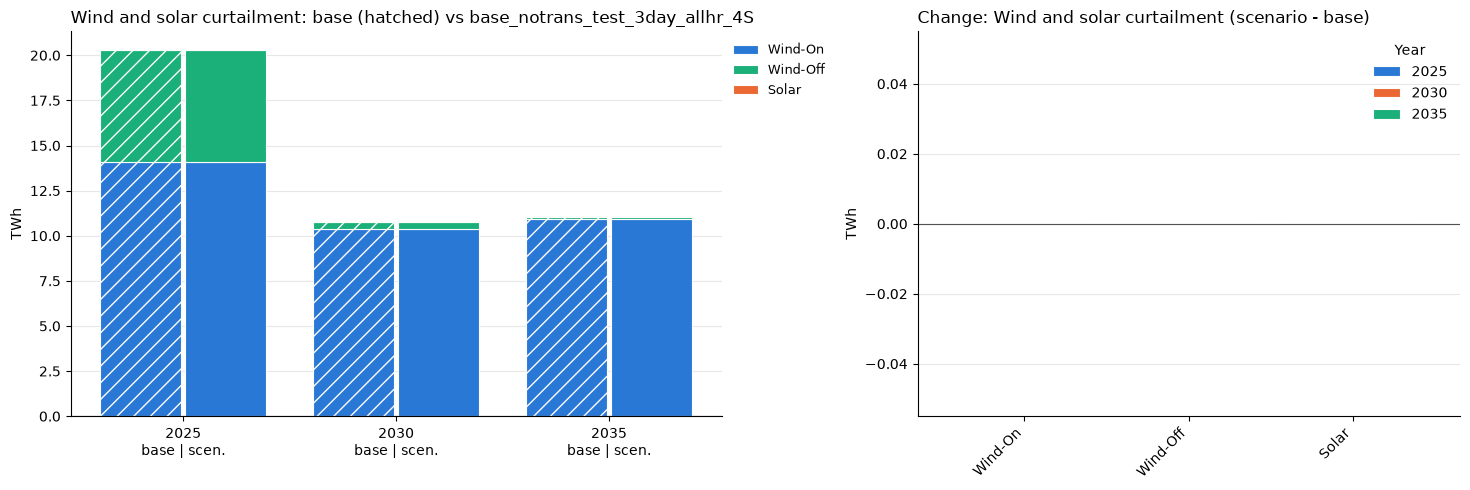

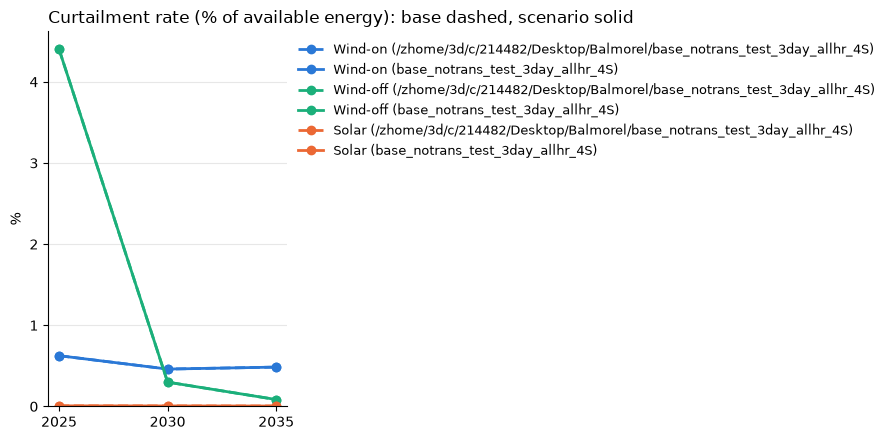

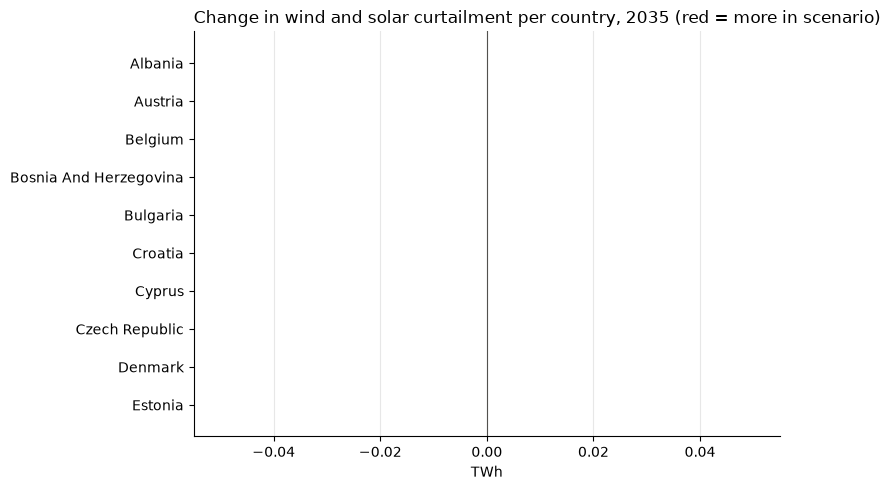

In [46]:
# 10.2.3 Wind and solar curtailment (TWh and % of available energy)
def vre_by_year(results, scenario, symbol):
    table = scenario_result(results, scenario, symbol)
    table = table.loc[table["Technology"].isin(VRE_TECH)]
    if "Commodity" in table:
        table = table.loc[table["Commodity"].eq("ELECTRICITY")]
    table = table.assign(Year=table["Year"].astype(str), Group=table["Technology"].map(VRE_TECH))
    return table.groupby(["Year", "Group"])["Value"].sum().unstack("Group", fill_value=0).reindex(
        index=COMPARISON_YEARS, columns=list(dict.fromkeys(VRE_TECH.values())), fill_value=0)

curt_b, curt_s = vre_by_year(base_res, BASE_SCENARIO, "CURT_YCRAGF"), vre_by_year(res, SCENARIO, "CURT_YCRAGF")
prod_b, prod_s = vre_by_year(base_res, BASE_SCENARIO, "PRO_YCRAGF"), vre_by_year(res, SCENARIO, "PRO_YCRAGF")
rate_b = curt_b.sum(axis=1) / (curt_b.sum(axis=1) + prod_b.sum(axis=1)).replace(0, np.nan) * 100
rate_s = curt_s.sum(axis=1) / (curt_s.sum(axis=1) + prod_s.sum(axis=1)).replace(0, np.nan) * 100

curt_cmp = pd.DataFrame({f"{BASE_SCENARIO} (TWh)": curt_b.sum(axis=1), f"{SCENARIO} (TWh)": curt_s.sum(axis=1),
                         "Change (TWh)": curt_s.sum(axis=1) - curt_b.sum(axis=1),
                         f"{BASE_SCENARIO} rate (%)": rate_b, f"{SCENARIO} rate (%)": rate_s,
                         "Change (pp)": rate_s - rate_b})
display(curt_cmp.round(2))

VRE_COLORS = {"Wind-on": "#2a78d6", "Wind-off": "#1baf7a", "Solar": "#eb6834"}        # distinct colours (the GROUP_COLORS winds are near-identical)
paired_stacked(curt_b, curt_s, VRE_COLORS, "Wind and solar curtailment", "TWh")

# Curtailment rate per technology group: base dashed, scenario solid
fig, ax = plt.subplots(figsize=(9, 4.5))
for g in curt_b.columns:
    for label, c, p, ls in [(BASE_SCENARIO, curt_b, prod_b, "--"), (SCENARIO, curt_s, prod_s, "-")]:
        r = c[g] / (c[g] + p[g]).replace(0, np.nan) * 100
        ax.plot(r.index, r.values, ls, marker="o", linewidth=2, color=VRE_COLORS[g], label=f"{g} ({label})")
ax.set_ylim(bottom=0)
style(ax, "Curtailment rate (% of available energy): base dashed, scenario solid", "%")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1), fontsize=9)
plt.tight_layout(); plt.show()

country_change(last_year_by_country(base_res, BASE_SCENARIO, "CURT_YCRAGF", technologies=list(VRE_TECH)),
               last_year_by_country(res, SCENARIO, "CURT_YCRAGF", technologies=list(VRE_TECH)),
               f"Change in wind and solar curtailment per country, {LAST_YEAR} (red = more in scenario)", "TWh")

#### 10.2.4 Installed capacity and dispatch by fuel in `FOCUS_YEAR`: electricity, heat and hydrogen
Change (scenario - base) in installed capacity (`G_CAP_YCRAF`, GW) and dispatch (`PRO_YCRAGF`, TWh) by fuel in `FOCUS_YEAR` (2035, or the last common year if 2035 is not solved), in absolute terms; the tables also list the base and scenario values. H2 storage is included and shown as its own fuel ("H2 storage").

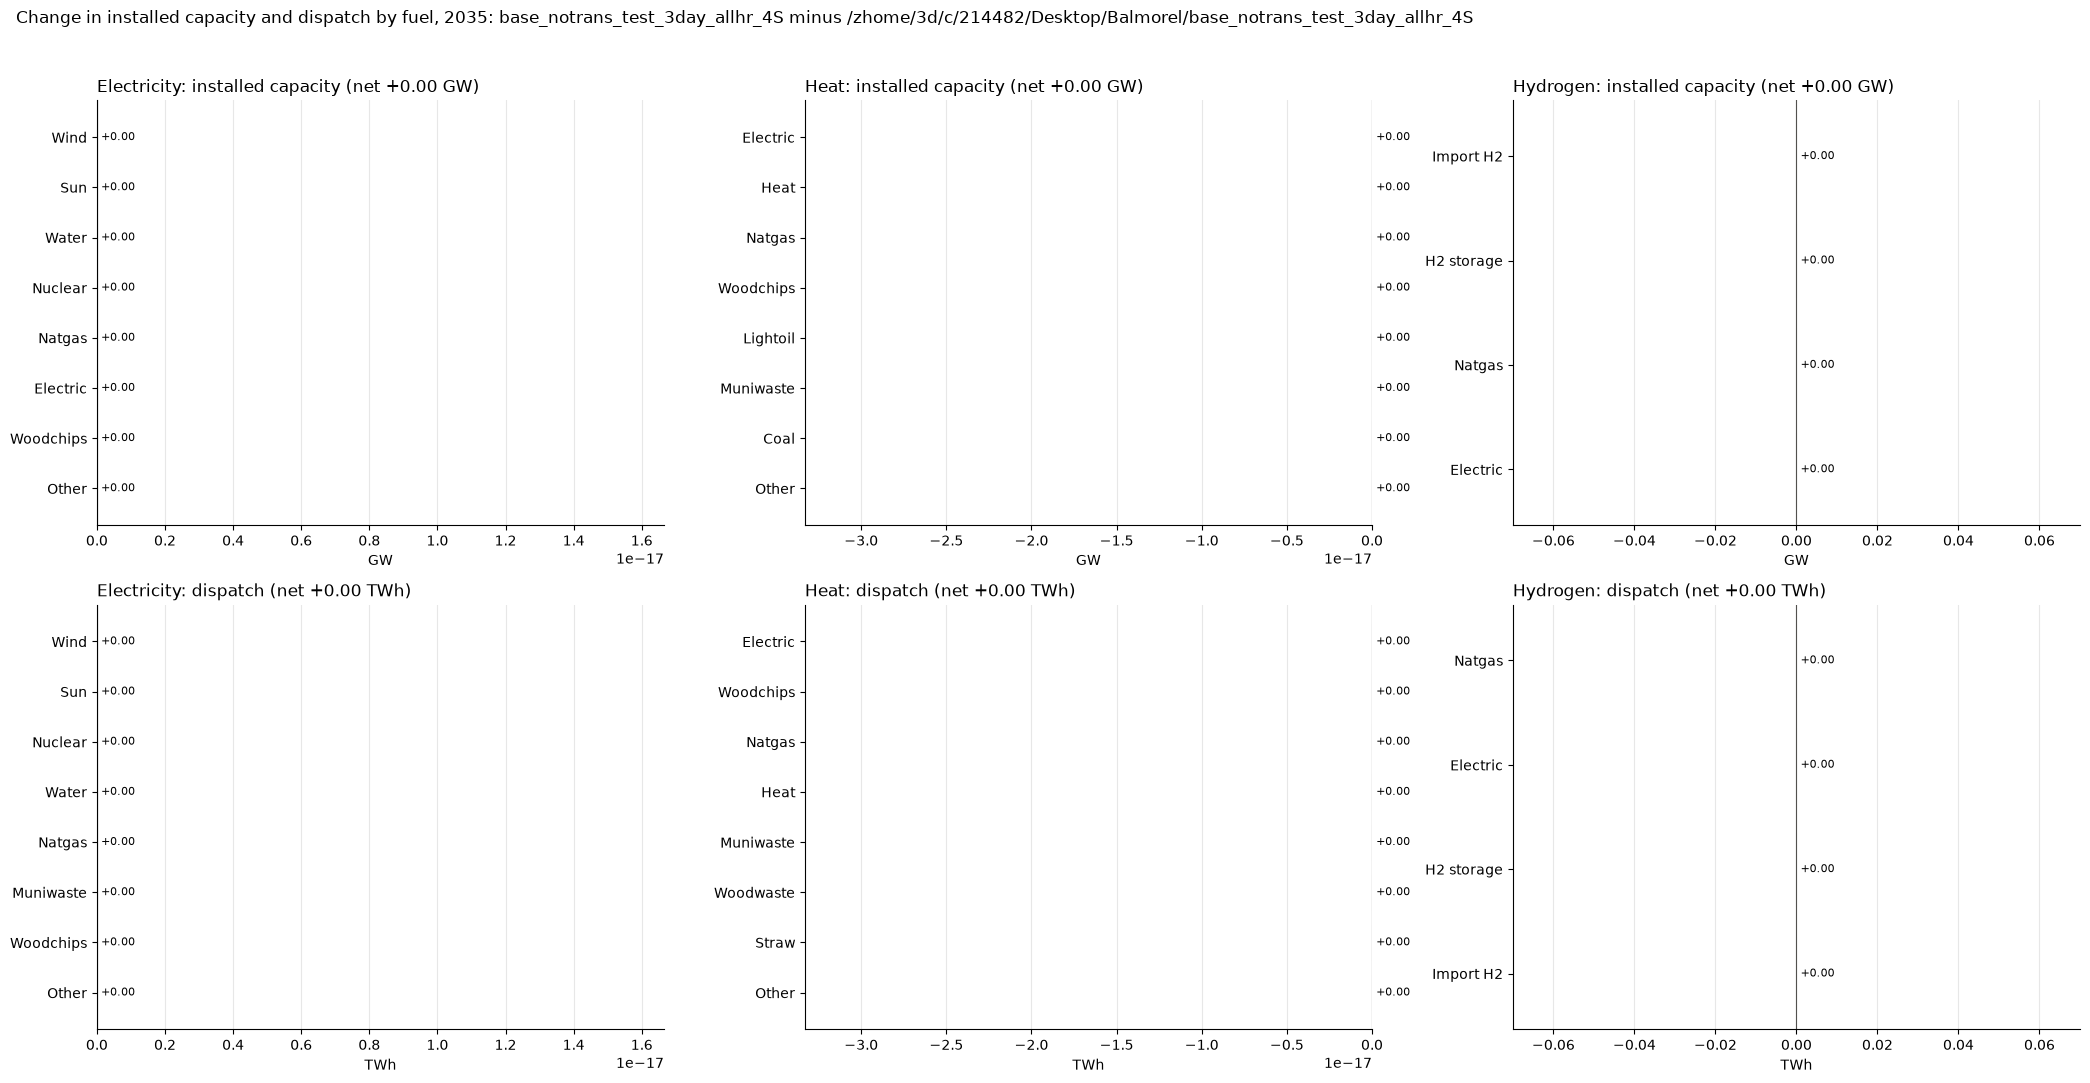

Electricity installed capacity by fuel, 2035 (GW)


,Base,Scenario,Change,Change (%)
Wind,671.55,671.55,0.0,0.0
Sun,546.14,546.14,0.0,0.0
Water,176.21,176.21,0.0,0.0
Nuclear,83.98,83.98,0.0,0.0
Natgas,81.86,81.86,0.0,0.0
Electric,19.50,19.50,0.0,0.0
Woodchips,12.79,12.79,0.0,0.0
Other,18.73,18.73,0.0,0.0
Total,1610.76,1610.76,0.0,0.0


Heat installed capacity by fuel, 2035 (GW)


,Base,Scenario,Change,Change (%)
Electric,1023.68,1023.68,0.0,0.0
Heat,445.21,445.21,0.0,0.0
Natgas,365.23,365.23,0.0,0.0
Woodchips,226.77,226.77,0.0,0.0
Lightoil,32.56,32.56,0.0,0.0
Muniwaste,22.13,22.13,0.0,0.0
Coal,17.23,17.23,0.0,0.0
Other,29.64,29.64,0.0,0.0
Total,2162.44,2162.44,0.0,0.0


Hydrogen installed capacity by fuel, 2035 (GW)


...

,Base,Scenario,Change,Change (%)
Wind,2414.95,2414.95,0.0,0.0
Sun,901.61,901.61,0.0,0.0
Nuclear,669.55,669.55,0.0,0.0
Water,619.10,619.10,0.0,0.0
Natgas,121.08,121.08,0.0,0.0
Muniwaste,52.00,52.00,0.0,0.0
Woodchips,50.68,50.68,0.0,0.0
Other,35.85,35.85,0.0,0.0
Total,4864.84,4864.84,0.0,0.0


Heat dispatch by fuel, 2035 (TWh)


,Base,Scenario,Change,Change (%)
Electric,4281.37,4281.37,0.0,0.0
Woodchips,1299.04,1299.04,0.0,0.0
Natgas,259.73,259.73,0.0,0.0
Heat,239.54,239.54,0.0,0.0
Muniwaste,150.25,150.25,0.0,0.0
Woodwaste,68.25,68.25,0.0,0.0
Straw,62.12,62.12,0.0,0.0
Other,7.77,7.77,0.0,0.0
Total,6368.07,6368.07,0.0,0.0


Hydrogen dispatch by fuel, 2035 (TWh)


,Base,Scenario,Change,Change (%)
Fuel,,,,
Natgas,553.38,553.38,0.0,0.0
Electric,163.49,163.49,0.0,0.0
H2 storage,44.12,44.12,0.0,0.0
Import H2,0.02,0.02,0.0,0.0
Total,761.00,761.00,0.0,0.0


In [47]:
# 10.2.4 Change (scenario - base) in installed capacity (GW) and dispatch (TWh) by fuel in FOCUS_YEAR for electricity, heat and hydrogen
FOCUS_COMMODITIES = ["ELECTRICITY", "HEAT", "HYDROGEN"]
FOCUS_QUANTITIES = {"Installed capacity": ("G_CAP_YCRAF", "GW"), "Dispatch": ("PRO_YCRAGF", "TWh")}
FOCUS_N_FUELS = 7                    # the largest fuels per panel keep their name, the rest is "Other"
FUEL_PALETTE = PALETTE + ["#8c6bb1", "#5a9e3d", "#d1495b", "#00a6a6", "#7fb5e0", "#a24fb8", "#c9a227", "#52514e"]

def focus_by_fuel(results, scenario, symbol, commodity):
    """Value per fuel in FOCUS_YEAR for one commodity; H2 storage (fuel HYDROGEN) is labelled as its own fuel."""
    t = scenario_result(results, scenario, symbol)
    t = t.loc[t["Year"].astype(str).eq(FOCUS_YEAR) & t["Commodity"].eq(commodity)]
    fuel = t["Fuel"].mask(t["Technology"].eq("H2-STORAGE"), "H2_STORAGE")
    return t.groupby(fuel)["Value"].sum()

# Base and scenario per panel, with the small fuels folded into "Other" (same columns in both runs)
focus_tables = {}
for quantity, (symbol, unit) in FOCUS_QUANTITIES.items():
    for commodity in FOCUS_COMMODITIES:
        t = pd.DataFrame({"Base": focus_by_fuel(base_res, BASE_SCENARIO, symbol, commodity),
                          "Scenario": focus_by_fuel(res, SCENARIO, symbol, commodity)}).fillna(0)
        t = t.loc[t.abs().sum(axis=1) > 1e-6]
        order = t.abs().sum(axis=1).sort_values(ascending=False).index
        keep_f, rest_f = list(order[:FOCUS_N_FUELS]), list(order[FOCUS_N_FUELS:])
        t = pd.concat([t.loc[keep_f], t.loc[rest_f].sum().to_frame("Other").T]) if rest_f else t.loc[keep_f]
        focus_tables[(quantity, commodity)] = t

# One colour per fuel in all six panels (the fuel largest over all panels gets the first colour)
fuel_rank = pd.concat([t.abs().sum(axis=1) for t in focus_tables.values()]).groupby(level=0).sum().drop("Other", errors="ignore")
FOCUS_FUEL_COLORS = dict(zip(fuel_rank.sort_values(ascending=False).index, FUEL_PALETTE))
FOCUS_FUEL_COLORS.update({f: GREY for f in fuel_rank.index[len(FUEL_PALETTE):]}, Other=GREY)
fuel_label = lambda f: "H2 storage" if f == "H2_STORAGE" else clean_name(f)

# Change per fuel (scenario - base) in absolute terms: one bar per fuel, net change of the panel in the title
fig, axes = plt.subplots(2, 3, figsize=(21, 11))
for (row, (quantity, (symbol, unit))) in enumerate(FOCUS_QUANTITIES.items()):
    for col, commodity in enumerate(FOCUS_COMMODITIES):
        ax, t = axes[row, col], focus_tables[(quantity, commodity)]
        change = (t["Scenario"] - t["Base"]).iloc[::-1]                        # largest fuel on top
        y = np.arange(len(change))
        ax.barh(y, change.values, 0.7, color=[FOCUS_FUEL_COLORS[f] for f in change.index], edgecolor="#fcfcfb", linewidth=0.8)
        for yi, v in zip(y, change.values):
            ax.annotate(f"{v:+,.2f}", (v, yi), ha="left" if v >= 0 else "right", va="center", fontsize=8,
                        xytext=(3 if v >= 0 else -3, 0), textcoords="offset points")
        ax.set_yticks(y); ax.set_yticklabels([fuel_label(f) for f in change.index])
        ax.axvline(0, color="#52514e", linewidth=0.8); ax.margins(x=0.2)
        style(ax, f"{commodity.title()}: {quantity.lower()} (net {change.sum():+,.2f} {unit})", "", axis="x"); ax.set_xlabel(unit)
fig.suptitle(f"Change in installed capacity and dispatch by fuel, {FOCUS_YEAR}: {SCENARIO} minus {BASE_SCENARIO}", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

# Tables: base, scenario and change per fuel for each of the six panels
for (quantity, commodity), t in focus_tables.items():
    unit = FOCUS_QUANTITIES[quantity][1]
    t = t.rename(index=fuel_label)
    t.loc["Total"] = t.sum()
    print(f"{commodity.title()} {quantity.lower()} by fuel, {FOCUS_YEAR} ({unit})")
    display(t.assign(Change=t["Scenario"] - t["Base"], **{"Change (%)": (t["Scenario"] - t["Base"]) / t["Base"].replace(0, np.nan) * 100}).round(2))

#### 10.2.5 How the extra electricity demand is met, hour by hour
Change (scenario - base) in every modelled hour of `FOCUS_YEAR`, summed over all regions (GW). The stacked areas are the change in generation per fuel group (`PRO_YCRAGFST`) plus the flexible demands that are reduced (`EL_DEMAND_YCRST`, shown as supply: less electrolysis, less electric heating). In every hour they add up to the dashed line, the change in exogenous demand (in the data-centre scenarios: the extra data-centre load). EV charging and storage are moved in time, so they appear above and below zero; "Other" holds nuclear, onshore wind, biomass and waste, CCS and grid losses. The table gives the averages per season.

Largest gap between the stacked areas and the change in exogenous demand: 0.000 GW


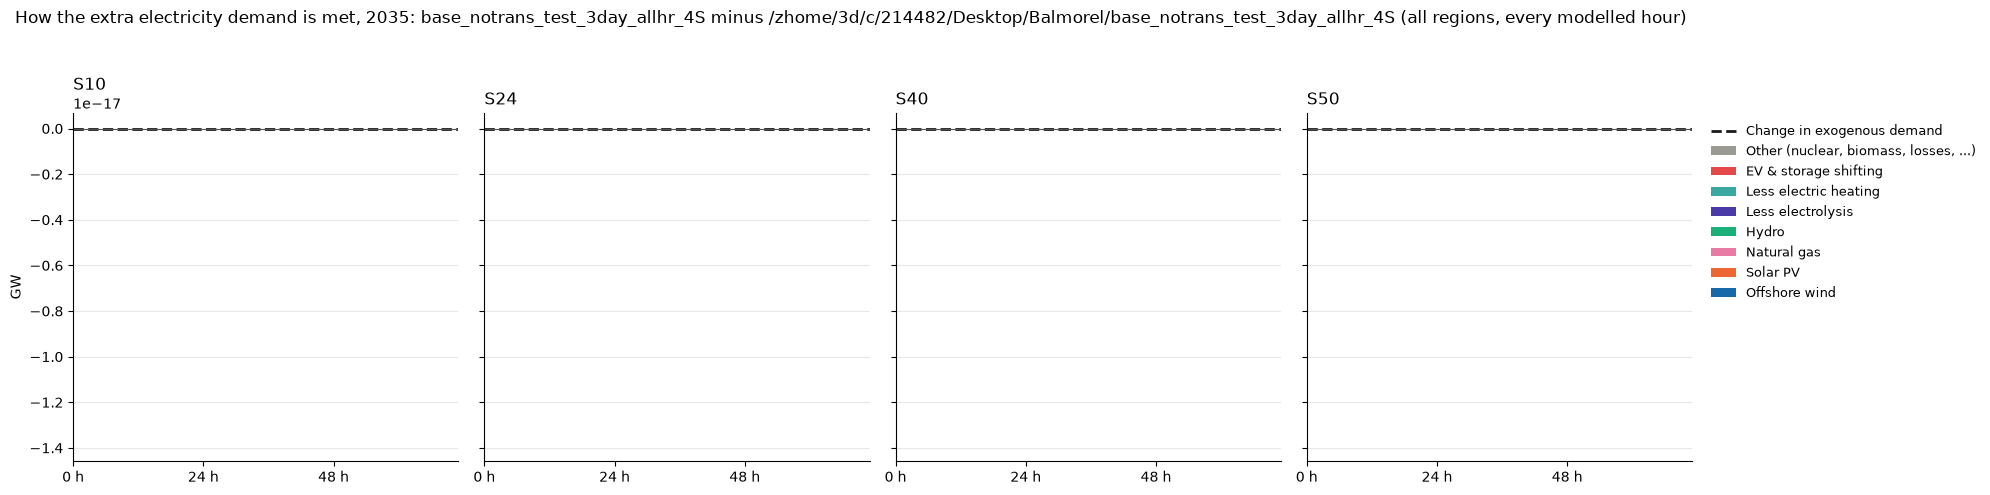

,Offshore wind,Solar PV,Natural gas,Hydro,Less electrolysis,Less electric heating,EV & storage shifting,"Other (nuclear, biomass, losses, ...)",Change in exogenous demand
S10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
S24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
S40,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
S50,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
All,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [48]:
# 10.2.5 How the extra exogenous electricity demand is met in every modelled hour of FOCUS_YEAR (GW, sum over all regions)
# Change (scenario - base) in generation by fuel group, plus the flexible demands that are reduced (shown as supply);
# EV charging and storage are moved in time (net about zero over the year), so they appear above and below zero.
# Balance per hour: sum of the stacked areas = change in exogenous demand (mostly data centres; dashed line).
HOURLY_GEN_GROUPS = {"WIND-OFF": "Offshore wind", "SOLAR-PV": "Solar PV", "NATGAS": "Natural gas", "WATER": "Hydro",
                     "INTRASEASONAL-ELECT-STORAGE": "EV & storage shifting"}
HOURLY_DEMAND_GROUPS = {"ENDO_H2": "Less electrolysis", "ENDOGENOUS_ELECT2HEAT": "Less electric heating",
                        "ENDO_EV": "EV & storage shifting", "ENDO_INTRASTO": "EV & storage shifting"}
HOURLY_OTHER = "Other (nuclear, biomass, losses, ...)"
HOURLY_COLORS = {"Offshore wind": "#1769aa", "Solar PV": "#eb6834", "Natural gas": "#e87ba4", "Hydro": "#1baf7a",
                 "Less electrolysis": "#4a3aa7", "Less electric heating": "#3aa7a0", "EV & storage shifting": "#e34948",
                 HOURLY_OTHER: GREY}

def hourly_supply(results, scenario):
    """Season x Time table (GW, all regions): electricity generation by group and minus the flexible demands."""
    pro = scenario_result(results, scenario, "PRO_YCRAGFST")
    pro = pro.loc[pro["Year"].astype(str).eq(FOCUS_YEAR) & pro["Commodity"].eq("ELECTRICITY")]
    key = pro["Technology"].where(pro["Technology"].isin(HOURLY_GEN_GROUPS), pro["Fuel"])
    group = key.map(HOURLY_GEN_GROUPS).fillna(HOURLY_OTHER)
    gen = pro.groupby(["Season", "Time", group])["Value"].sum().unstack(fill_value=0)
    dem = scenario_result(results, scenario, "EL_DEMAND_YCRST")
    dem = dem.loc[dem["Year"].astype(str).eq(FOCUS_YEAR) & dem["Category"].ne("EXOGENOUS")]
    dgroup = dem["Category"].map(HOURLY_DEMAND_GROUPS).fillna(HOURLY_OTHER)
    flex = -dem.groupby(["Season", "Time", dgroup])["Value"].sum().unstack(fill_value=0)      # less demand = supply
    exo = scenario_result(results, scenario, "EL_DEMAND_YCRST")
    exo = exo.loc[exo["Year"].astype(str).eq(FOCUS_YEAR) & exo["Category"].eq("EXOGENOUS")].groupby(["Season", "Time"])["Value"].sum()
    return gen.add(flex, fill_value=0) / 1e3, exo / 1e3                                         # MWh per hour -> GW

supply_s, exo_s = hourly_supply(res, SCENARIO)
supply_b, exo_b = hourly_supply(base_res, BASE_SCENARIO)
if not supply_s.index.sort_values().equals(supply_b.index.sort_values()):
    raise SystemExit(f"10.2.5 skipped: the two runs model different hours ({len(supply_s)} vs {len(supply_b)} time slices), "
                     "so an hour-by-hour difference is not meaningful.")
d_supply = supply_s.sub(supply_b, fill_value=0).fillna(0)
d_supply = d_supply[[g for g in HOURLY_COLORS if g in d_supply.columns]]
d_exo = exo_s.sub(exo_b, fill_value=0).reindex(d_supply.index, fill_value=0)
closure = (d_supply.sum(axis=1) - d_exo).abs().max()
print(f"Largest gap between the stacked areas and the change in exogenous demand: {closure:.3f} GW")

seasons = list(dict.fromkeys(d_supply.index.get_level_values("Season")))
fig, axes = plt.subplots(1, len(seasons), figsize=(4.5 * len(seasons) + 2, 5), sharey=True, squeeze=False)
for ax, season in zip(axes.ravel(), seasons):
    t = d_supply.xs(season, level="Season")
    x = np.arange(len(t))
    pos, neg = np.zeros(len(t)), np.zeros(len(t))
    for g in t.columns:                                  # increases stacked up from 0, decreases stacked down from 0
        v = t[g].to_numpy(dtype=float)
        up, down = np.clip(v, 0, None), np.clip(v, None, 0)
        ax.fill_between(x, pos, pos + up, color=HOURLY_COLORS[g], linewidth=0, label=g)
        ax.fill_between(x, neg, neg + down, color=HOURLY_COLORS[g], linewidth=0)
        pos, neg = pos + up, neg + down
    ax.plot(x, d_exo.xs(season, level="Season").to_numpy(), color="#1a1a1a", linewidth=2, linestyle="--", label="Change in exogenous demand")
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.set_xticks(range(0, len(t) + 1, 24)); ax.set_xticklabels([f"{h} h" for h in range(0, len(t) + 1, 24)])
    ax.set_xlim(0, len(t) - 1)
    style(ax, f"{season}", "GW" if ax is axes.ravel()[0] else "")
handles, labels = axes.ravel()[0].get_legend_handles_labels()
axes.ravel()[-1].legend(handles[::-1], labels[::-1], bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=9)
fig.suptitle(f"How the extra electricity demand is met, {FOCUS_YEAR}: {SCENARIO} minus {BASE_SCENARIO} (all regions, every modelled hour)", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

# Average over the modelled hours (GW), per season and in total
display(pd.concat([d_supply.groupby(level="Season").mean(), d_supply.mean().to_frame("All").T]).assign(**{"Change in exogenous demand": pd.concat([d_exo.groupby(level="Season").mean(), pd.Series({"All": d_exo.mean()})])}).round(2))

### 10.3 Why does the total system cost change?
The change in total system cost (`OBJ_YCR`, scenario - base, Mmoney) as a waterfall over the cost groups of 5.1 (capital, fixed O&M, variable O&M, fuel, CO2 tax and transport), ending at the net change of 9.1. The panel title relates the net change to the additional exogenous electricity demand of 10.2.1 (Mmoney/TWh = Money/MWh), i.e. the average system cost of serving the new data-center demand.

The second chart splits the same change by technology type, using the generator-level costs of `ECO_G_YCRAG`; costs that are not attributed to a generator there (transmission, and the small difference in fuel cost accounting between `ECO_G_YCRAG` and `OBJ_YCR`) are shown as "Transmission & unallocated", so the bars add up to the change in `OBJ_YCR`.

In [49]:
# 10.3 Decomposition of the change in total system cost (Mmoney): by cost group (waterfall) and by technology type
COST_ORDER = ["Capital", "Fixed O&M", "Variable O&M", "Fuel", "CO2", "Other"]
ECO_SUBCATEGORY = {"GENERATION_CAPITAL_COSTS": "Capital", "GENERATION_FIXED_COSTS": "Fixed O&M", "GENERATION_OPERATIONAL_COSTS": "Variable O&M",
                   "GENERATION_FUEL_COSTS": "Fuel", "GENERATION_CO2_TAX": "CO2", "GENERATION_CO2_TRANSPORT": "CO2"}

def cost_by_group(results, scenario):
    t = scenario_result(results, scenario, "OBJ_YCR").assign(Year=lambda d: d["Year"].astype(str))
    t["Group"] = t["Category"].map(COST_GROUP).fillna("Other")
    return t.groupby(["Year", "Group"])["Value"].sum().unstack("Group", fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)

def cost_by_technology(results, scenario):
    t = scenario_result(results, scenario, "ECO_G_YCRAG").assign(Year=lambda d: d["Year"].astype(str))
    t = t.loc[t["Category"].eq("COSTS")]
    t["Group"] = t["Subcategory"].map(ECO_SUBCATEGORY).fillna("Other")
    return t.groupby(["Year", "Technology", "Group"])["Value"].sum()

d_cost = cost_by_group(res, SCENARIO).sub(cost_by_group(base_res, BASE_SCENARIO), fill_value=0).fillna(0)
groups = [g for g in COST_ORDER if g in d_cost.columns]
cost_years = [y for y in COMPARISON_YEARS if d_cost.loc[y].abs().max() > 1e-6]
group_colors = {**COST_COLORS, "Other": GREY}

if not cost_years:
    print("The total system cost is identical in both scenarios in all comparison years")
else:
    # --- Waterfall by cost group -----------------------------------------------------------------------------------
    fig, axes = plt.subplots(1, len(cost_years), figsize=(5.5 * len(cost_years) + 1, 5), sharey=True, squeeze=False)
    for ax, year in zip(axes.ravel(), cost_years):
        row = d_cost.loc[year, groups]
        steps = sorted([g for g in groups if abs(row[g]) >= 0.5], key=lambda g: -row[g])    # largest increase first
        level, x = 0.0, -1
        for x, g in enumerate(steps):
            v = row[g]
            ax.bar(x, v, bottom=level, color="#e34948" if v >= 0 else "#1baf7a", width=0.7, edgecolor="#fcfcfb")
            ax.annotate(f"{v:+,.0f}", (x, level + max(v, 0)), ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
            if x:
                ax.plot([x - 0.65, x - 0.35], [level, level], color="#8a8984", linewidth=0.8)
            level += v
        ax.plot([x + 0.35, x + 0.65], [level, level], color="#8a8984", linewidth=0.8)
        ax.bar(x + 1, level, color="#2a78d6", width=0.7, edgecolor="#fcfcfb")
        ax.annotate(f"{level:+,.0f}", (x + 1, max(level, 0)), ha="center", va="bottom", fontsize=8, fontweight="bold", xytext=(0, 2), textcoords="offset points")
        ax.set_xticks(range(len(steps) + 1))
        ax.set_xticklabels(steps + ["Net change\n(8.1)"], rotation=45, ha="right", fontsize=8)
        ax.axhline(0, color="#52514e", linewidth=0.8)
        base_total = cost_by_group(base_res, BASE_SCENARIO).loc[year].sum()
        d_exo = d_dem.loc[year, first] if year in d_dem.index else 0
        per_mwh = f"\n= {level / d_exo:.1f} Money per MWh of additional exogenous demand" if abs(d_exo) > 1e-6 else ""
        ax.set_title(f"{year}: {level:+,.0f} Mmoney ({level / base_total * 100:+.1f} %){per_mwh}", loc="left", fontsize=9)
        ax.set_ylabel("Change in total system cost (Mmoney)")
        ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
    lo, hi = axes.ravel()[0].get_ylim()
    axes.ravel()[0].set_ylim(min(lo, 0), hi + 0.1 * (hi - lo))
    fig.suptitle(f"Change in total system cost by cost group, {SCENARIO} minus {BASE_SCENARIO}", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

    table = d_cost.loc[cost_years, groups].T
    table.loc["Net change"] = table.sum()
    table.loc["Additional exogenous demand (TWh)"] = [d_dem.loc[y, first] if y in d_dem.index else np.nan for y in cost_years]
    table.loc["Net change per MWh of additional exogenous demand (Money/MWh)"] = table.loc["Net change"] / table.loc["Additional exogenous demand (TWh)"].replace(0, np.nan)
    print("Change in total system cost by cost group (Mmoney, scenario - base)")
    display(table.round(1))

    # --- By technology type (generator-level costs) ------------------------------------------------------------------
    d_tech = cost_by_technology(res, SCENARIO).sub(cost_by_technology(base_res, BASE_SCENARIO), fill_value=0)
    fig, axes = plt.subplots(1, len(cost_years), figsize=(6.5 * len(cost_years) + 2, 6), sharey=True, squeeze=False)
    tech_tables = {}
    for year in cost_years:
        t = d_tech.xs(year, level="Year").unstack("Group", fill_value=0).reindex(columns=groups, fill_value=0)
        t.index = [clean_name(i) for i in t.index]
        t.loc["Transmission & unallocated"] = d_cost.loc[year, groups] - t.sum()                 # closes to OBJ_YCR
        tech_tables[year] = t
    techs = pd.Index(sorted(set().union(*[t.index[t.abs().sum(axis=1) >= 1] for t in tech_tables.values()])))
    techs = sum(t.reindex(techs, fill_value=0).sum(axis=1) for t in tech_tables.values()).sort_values().index   # largest increase on top
    y = np.arange(len(techs))
    for ax, year in zip(axes.ravel(), cost_years):
        t = tech_tables[year].reindex(techs, fill_value=0)
        pos, neg = np.zeros(len(t)), np.zeros(len(t))
        for g in groups:
            v = t[g].to_numpy(dtype=float)
            ax.barh(y, v, left=np.where(v >= 0, pos, neg), height=0.7, color=group_colors[g], edgecolor="#fcfcfb", linewidth=0.6, label=g)
            pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
        ax.scatter(t.sum(axis=1), y, color="#1a1a1a", s=14, zorder=3, label="Net change")
        ax.axvline(0, color="#52514e", linewidth=0.8)
        ax.set_yticks(y); ax.set_yticklabels(techs)
        ax.set_title(str(year), loc="left"); ax.set_xlabel("Change in cost (Mmoney)")
        ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
    axes.ravel()[-1].legend(*axes.ravel()[0].get_legend_handles_labels(), bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    fig.suptitle("Change in system cost by technology type and cost group (scenario - base)", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

    last = cost_years[-1]
    t = tech_tables[last].reindex(techs[::-1], fill_value=0)
    print(f"Change in system cost by technology type, {last} (Mmoney, scenario - base)")
    display(t.assign(Net=t.sum(axis=1)).round(1))


The total system cost is identical in both scenarios in all comparison years


### 10.4 CO2 emissions: base vs scenario
`EMI_YCRAG` (kton): total emissions per year, the split by fuel, and the countries with the largest change in the last common year.

,/zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S,base_notrans_test_3day_allhr_4S,Change,Change (%)
Year,,,,
2025,130501.6,130501.6,0.0,0.0
2030,101888.0,101888.0,0.0,0.0
2035,87461.2,87461.2,0.0,0.0


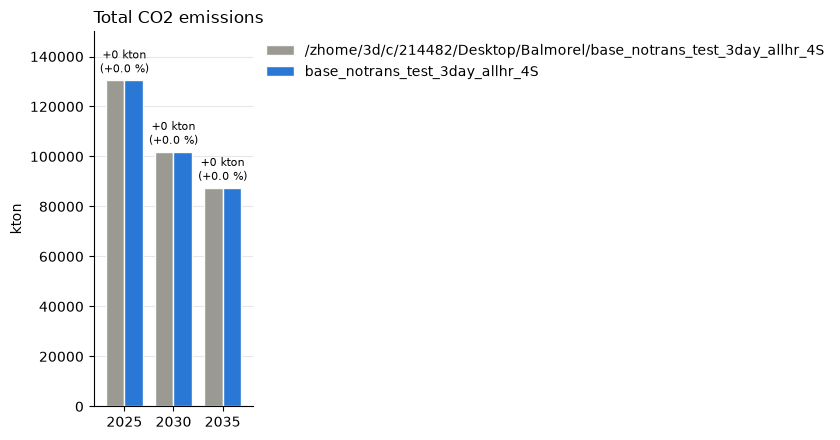

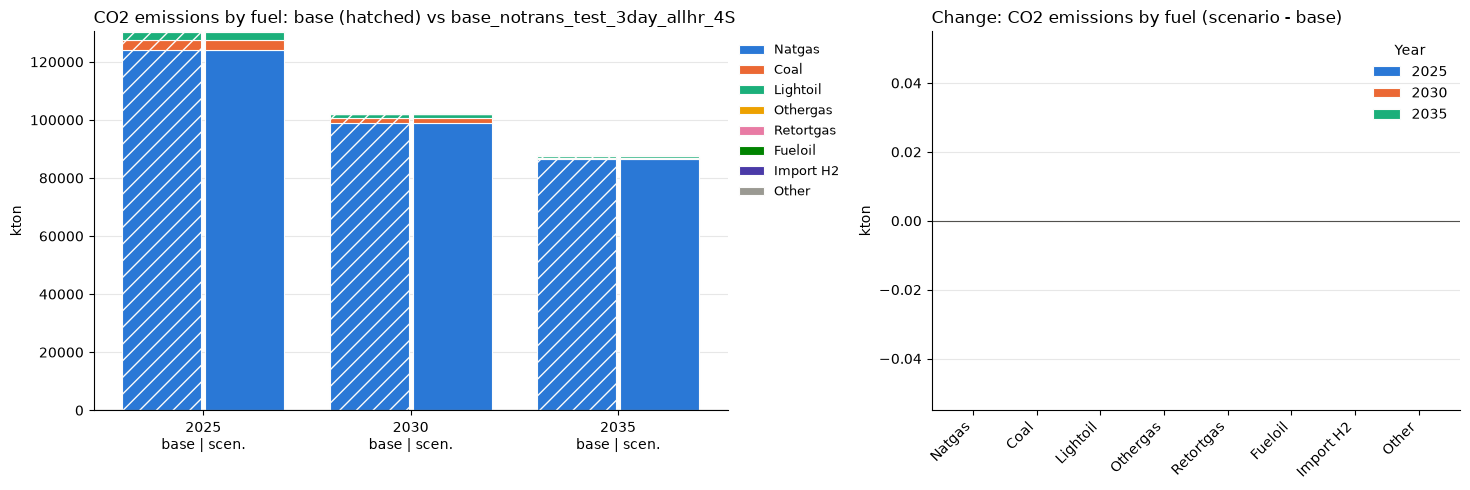

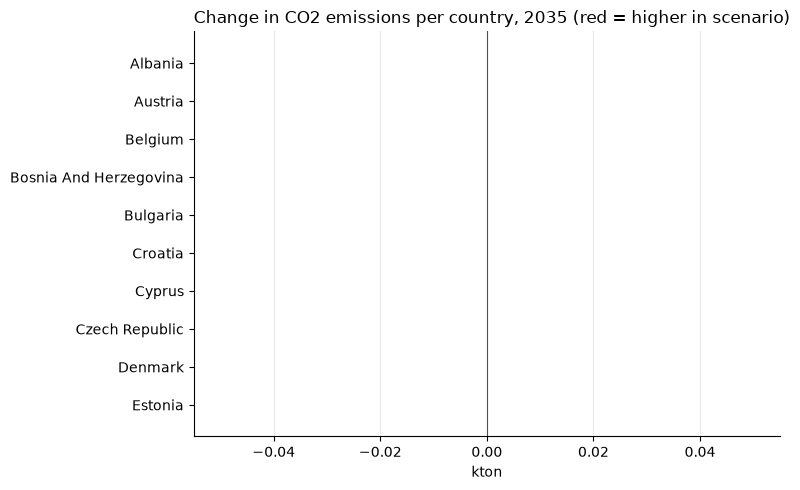

In [50]:
# 10.4 CO2 emissions comparison (kton)
emi_cmp = pd.DataFrame({BASE_SCENARIO: yearly_total(base_res, BASE_SCENARIO, "EMI_YCRAG"),
                        SCENARIO: yearly_total(res, SCENARIO, "EMI_YCRAG")})
emi_cmp["Change"] = emi_cmp[SCENARIO] - emi_cmp[BASE_SCENARIO]
emi_cmp["Change (%)"] = emi_cmp["Change"] / emi_cmp[BASE_SCENARIO].replace(0, np.nan) * 100
display(emi_cmp.round(1))

fig, ax = plt.subplots(figsize=(max(8, 1.5 * len(COMPARISON_YEARS) + 4), 4.5))
emi_cmp[[BASE_SCENARIO, SCENARIO]].plot.bar(ax=ax, color=[SCEN_COLORS[BASE_SCENARIO], SCEN_COLORS[SCENARIO]], width=0.75, edgecolor="#fcfcfb")
for i, (change, pct) in enumerate(zip(emi_cmp["Change"], emi_cmp["Change (%)"])):
    top = emi_cmp[[BASE_SCENARIO, SCENARIO]].iloc[i].max()
    ax.annotate(f"{change:+,.0f} kton\n({pct:+.1f} %)", (i, top), ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
ax.tick_params(axis="x", rotation=0); ax.margins(y=0.15)
style(ax, "Total CO2 emissions", "kton")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1))
plt.tight_layout(); plt.show()

base_t, scen_t, colors = align(by_year(base_res, BASE_SCENARIO, "EMI_YCRAG", "Fuel"), by_year(res, SCENARIO, "EMI_YCRAG", "Fuel"))
paired_stacked(base_t, scen_t, colors, "CO2 emissions by fuel", "kton")
country_change(last_year_by_country(base_res, BASE_SCENARIO, "EMI_YCRAG"), last_year_by_country(res, SCENARIO, "EMI_YCRAG"),
               f"Change in CO2 emissions per country, {LAST_YEAR} (red = higher in scenario)", "kton")

#### 10.4.1 Why do the emissions change?
The change in `EMI_YCRAG` (scenario - base, kton) is traced back in four steps:
1. **By end use**: each generator's emissions are allocated to the commodities it produces (electricity, heat, hydrogen) in proportion to its output (`PRO_YCRAGF`), so CHP emissions are shared between power and heat. The parts add up to the change in 10.4.
2. **By technology and fuel**: which plants emit more, next to the change in their fuel use (`F_CONS_YCRA`, TWh). A change in emissions with the same fuel use would point to a change in emission intensity (e.g. CCS), otherwise it is a change in activity.
3. **How the extra electricity was supplied** (system-wide): the change in electricity generation per fuel, the CO2 intensity of each fuel's electricity in the scenario (kg/MWh = kton/TWh) and the resulting change in CO2, with the average CO2 content of the additional electricity demand.
4. **By country** (last common year): where the emissions change, with the change in electricity demand, the part from data centres and the change in fossil electricity generation.

1. Change in CO2 emissions by end use (kton, scenario - base)


,Electricity,Heat,Hydrogen,Total,Total (8.3)
Year,,,,,
2025,0.0,0.0,0.0,0.0,0.0
2030,0.0,0.0,0.0,0.0,0.0
2035,0.0,0.0,0.0,0.0,0.0


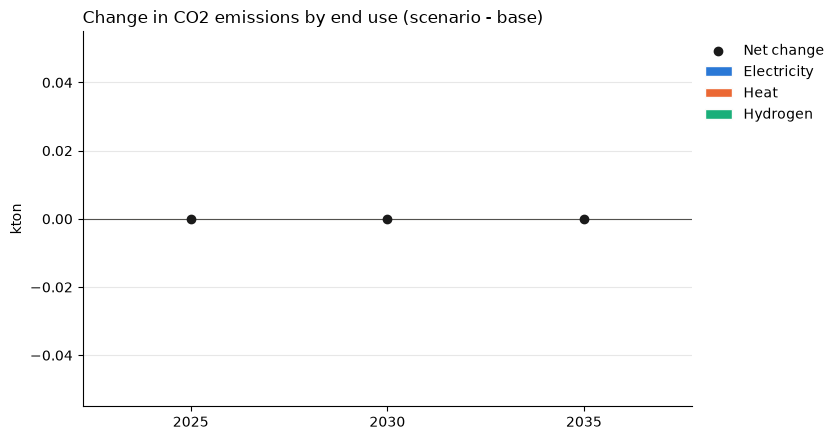

2. Change in CO2 emissions and fuel use by technology and fuel (scenario - base), largest changes in the last year first


Empty DataFrame
Columns: [(CO2 (kton), 2025), (CO2 (kton), 2030), (CO2 (kton), 2035), (Fuel use (TWh), 2025), (Fuel use (TWh), 2030), (Fuel use (TWh), 2035)]
Index: []

3. How the change in electricity demand was supplied, 2025: demand +0.00 TWh, generation +0.00 TWh, CO2 from electricity +0.0 kton


,Generation change (TWh),"CO2 intensity, scenario (kg/MWh)",CO2 change (kton)
Total,0.0,NaN,0.0


3. How the change in electricity demand was supplied, 2030: demand +0.00 TWh, generation +0.00 TWh, CO2 from electricity +0.0 kton


,Generation change (TWh),"CO2 intensity, scenario (kg/MWh)",CO2 change (kton)
Total,0.0,NaN,0.0


3. How the change in electricity demand was supplied, 2035: demand +0.00 TWh, generation +0.00 TWh, CO2 from electricity +0.0 kton


,Generation change (TWh),"CO2 intensity, scenario (kg/MWh)",CO2 change (kton)
Total,0.0,NaN,0.0


4. Change in CO2 emissions per country, 2035 (scenario - base), the 15 largest absolute changes


,CO2 total (kton),CO2 electricity (kton),CO2 heat (kton),CO2 hydrogen (kton),Electricity demand (TWh),of which data centres (TWh),Fossil electricity (TWh)
Albania,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Austria,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Belgium,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bosnia And Herzegovina,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bulgaria,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Croatia,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Cyprus,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Czech Republic,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Denmark,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Estonia,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [51]:
# 10.4.1 Decomposition of the change in CO2 emissions (kton): end use, technology and fuel, electricity supply, country
FOSSIL_FUELS = ["NATGAS", "COAL", "LIGHTOIL", "FUELOIL", "LIGNITE", "OTHERGAS"]
KEYS = ["Year", "Region", "Area", "Generation"]

def emissions_by_use(results, scenario):
    """EMI_YCRAG allocated to the output commodities of each generator, in proportion to its output (kton)."""
    e = scenario_result(results, scenario, "EMI_YCRAG").assign(Year=lambda d: d["Year"].astype(str))
    pro = scenario_result(results, scenario, "PRO_YCRAGF").assign(Year=lambda d: d["Year"].astype(str))
    pro = pro.groupby(KEYS + ["Commodity"])["Value"].sum()
    share = (pro / pro.groupby(level=KEYS).transform("sum").replace(0, np.nan)).rename("Share").reset_index()
    out = e.merge(share, on=KEYS, how="left")
    out["Commodity"] = out["Commodity"].fillna("OTHER")
    out["Value"] = out["Value"] * out["Share"].fillna(1)
    return out.loc[out["Year"].isin(COMPARISON_YEARS)]

emi_use = {BASE_SCENARIO: emissions_by_use(base_res, BASE_SCENARIO), SCENARIO: emissions_by_use(res, SCENARIO)}
def emi_change(by):
    return (emi_use[SCENARIO].groupby(by)["Value"].sum().sub(emi_use[BASE_SCENARIO].groupby(by)["Value"].sum(), fill_value=0))

# --- 1. End use --------------------------------------------------------------------------------------------------
by_use = emi_change(["Year", "Commodity"]).unstack("Commodity", fill_value=0).reindex(COMPARISON_YEARS, fill_value=0)
by_use.columns = [c.title() for c in by_use.columns]
by_use["Total"] = by_use.sum(axis=1)
by_use["Total (8.3)"] = emi_cmp["Change"].reindex(by_use.index)
print("1. Change in CO2 emissions by end use (kton, scenario - base)")
display(by_use.round(1))

fig, ax = plt.subplots(figsize=(max(8, 1.5 * len(COMPARISON_YEARS) + 4), 4.5))
use_cols = [c for c in by_use.columns if c not in ("Total", "Total (8.3)")]
use_colors = {"Electricity": "#2a78d6", "Heat": "#eb6834", "Hydrogen": "#1baf7a", "Other": GREY}
by_use[use_cols].plot.bar(ax=ax, stacked=True, color=[use_colors.get(c, GREY) for c in use_cols], width=0.6, edgecolor="#fcfcfb")
ax.scatter(range(len(by_use)), by_use["Total"], color="#1a1a1a", zorder=3, label="Net change")
ax.axhline(0, color="#52514e", linewidth=0.8); ax.tick_params(axis="x", rotation=0)
style(ax, "Change in CO2 emissions by end use (scenario - base)", "kton")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1))
plt.tight_layout(); plt.show()

# --- 2. Technology and fuel ----------------------------------------------------------------------------------------
fuel_use = lambda r, s: (scenario_result(r, s, "F_CONS_YCRA").assign(Year=lambda d: d["Year"].astype(str))
                         .groupby(["Year", "Technology", "Fuel"])["Value"].sum())
d_fuel = fuel_use(res, SCENARIO).sub(fuel_use(base_res, BASE_SCENARIO), fill_value=0)
tech_fuel = pd.concat({"CO2 (kton)": emi_change(["Year", "Technology", "Fuel"]).unstack("Year"),
                       "Fuel use (TWh)": d_fuel.unstack("Year")}, axis=1).fillna(0)
tech_fuel = tech_fuel.loc[tech_fuel["CO2 (kton)"].abs().max(axis=1) > 0.05]
tech_fuel = tech_fuel.reindex(tech_fuel[("CO2 (kton)", COMPARISON_YEARS[-1])].abs().sort_values(ascending=False).index)
tech_fuel = tech_fuel.reindex(columns=[(q, y) for q in ("CO2 (kton)", "Fuel use (TWh)") for y in COMPARISON_YEARS], fill_value=0)
print("2. Change in CO2 emissions and fuel use by technology and fuel (scenario - base), largest changes in the last year first")
display(tech_fuel.round(2))

# --- 3. How the additional electricity was supplied (system-wide) ---------------------------------------------------
def el_generation(results, scenario):
    t = scenario_result(results, scenario, "PRO_YCRAGF")
    t = t.loc[t["Commodity"].eq("ELECTRICITY")].assign(Year=lambda d: d["Year"].astype(str))
    return t.groupby(["Year", "Fuel"])["Value"].sum()

el_emi = lambda s: emi_use[s].loc[emi_use[s]["Commodity"].eq("ELECTRICITY")].groupby(["Year", "Fuel"])["Value"].sum()
gen_s, gen_b = el_generation(res, SCENARIO), el_generation(base_res, BASE_SCENARIO)
supply = pd.DataFrame({"Generation change (TWh)": gen_s.sub(gen_b, fill_value=0),
                       "CO2 intensity, scenario (kg/MWh)": el_emi(SCENARIO).reindex(gen_s.index).fillna(0) / gen_s.replace(0, np.nan),
                       "CO2 change (kton)": el_emi(SCENARIO).sub(el_emi(BASE_SCENARIO), fill_value=0)}).fillna(0)
d_demand = yearly_total(res, SCENARIO, "EL_DEMAND_YCR") - yearly_total(base_res, BASE_SCENARIO, "EL_DEMAND_YCR")
for year in COMPARISON_YEARS:
    t = supply.xs(year, level="Year")
    t = t.loc[(t["Generation change (TWh)"].abs() > 0.01) | (t["CO2 change (kton)"].abs() > 0.05)]
    t = t.sort_values("Generation change (TWh)", ascending=False)
    t.index = [clean_name(f) for f in t.index]
    t.loc["Total"] = [t["Generation change (TWh)"].sum(), np.nan, t["CO2 change (kton)"].sum()]
    d_el_co2 = t.loc["Total", "CO2 change (kton)"]
    print(f"3. How the change in electricity demand was supplied, {year}: demand {d_demand[year]:+.2f} TWh, "
          f"generation {t.loc['Total', 'Generation change (TWh)']:+.2f} TWh, "
          f"CO2 from electricity {d_el_co2:+.1f} kton"
          + (f" = {d_el_co2 / d_demand[year]:.0f} kg CO2 per additional MWh of demand" if abs(d_demand[year]) > 1e-6 else ""))
    display(t.round(2))

# --- 4. Country (last common year) ---------------------------------------------------------------------------------
region_country = scenario_result(res, SCENARIO, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
last = lambda t: t.xs(LAST_YEAR, level="Year") if LAST_YEAR in t.index.get_level_values("Year") else t.iloc[:0].droplevel("Year")
emi_country = last(emi_change(["Year", "Country", "Commodity"])).unstack("Commodity", fill_value=0)
emi_country.columns = [f"CO2 {c.lower()} (kton)" for c in emi_country.columns]
fossil_gen = lambda r, s: (scenario_result(r, s, "PRO_YCRAGF")
                          .loc[lambda d: d["Year"].astype(str).eq(LAST_YEAR) & d["Commodity"].eq("ELECTRICITY") & d["Fuel"].isin(FOSSIL_FUELS)]
                          .groupby("Country")["Value"].sum())
country_emi = pd.concat([
    emi_country.sum(axis=1).rename("CO2 total (kton)"),
    emi_country,
    (last_year_by_country(res, SCENARIO, "EL_DEMAND_YCR") - last_year_by_country(base_res, BASE_SCENARIO, "EL_DEMAND_YCR")).rename("Electricity demand (TWh)"),
    datacenter_demand(SCENARIO_DIR, LAST_YEAR, region_country).sub(datacenter_demand(BASE_DIR, LAST_YEAR, region_country), fill_value=0).rename("of which data centres (TWh)"),
    fossil_gen(res, SCENARIO).sub(fossil_gen(base_res, BASE_SCENARIO), fill_value=0).rename("Fossil electricity (TWh)"),
], axis=1).fillna(0)
country_emi = country_emi.loc[country_emi["CO2 total (kton)"].abs().sort_values(ascending=False).index].head(15)
country_emi.index = [clean_name(c) for c in country_emi.index]
print(f"4. Change in CO2 emissions per country, {LAST_YEAR} (scenario - base), the 15 largest absolute changes")
display(country_emi.round(2))


#### 10.4.2 CO2 emissions per technology type and the commodity it produces (6.1.1) in `FOCUS_YEAR`: base vs scenario

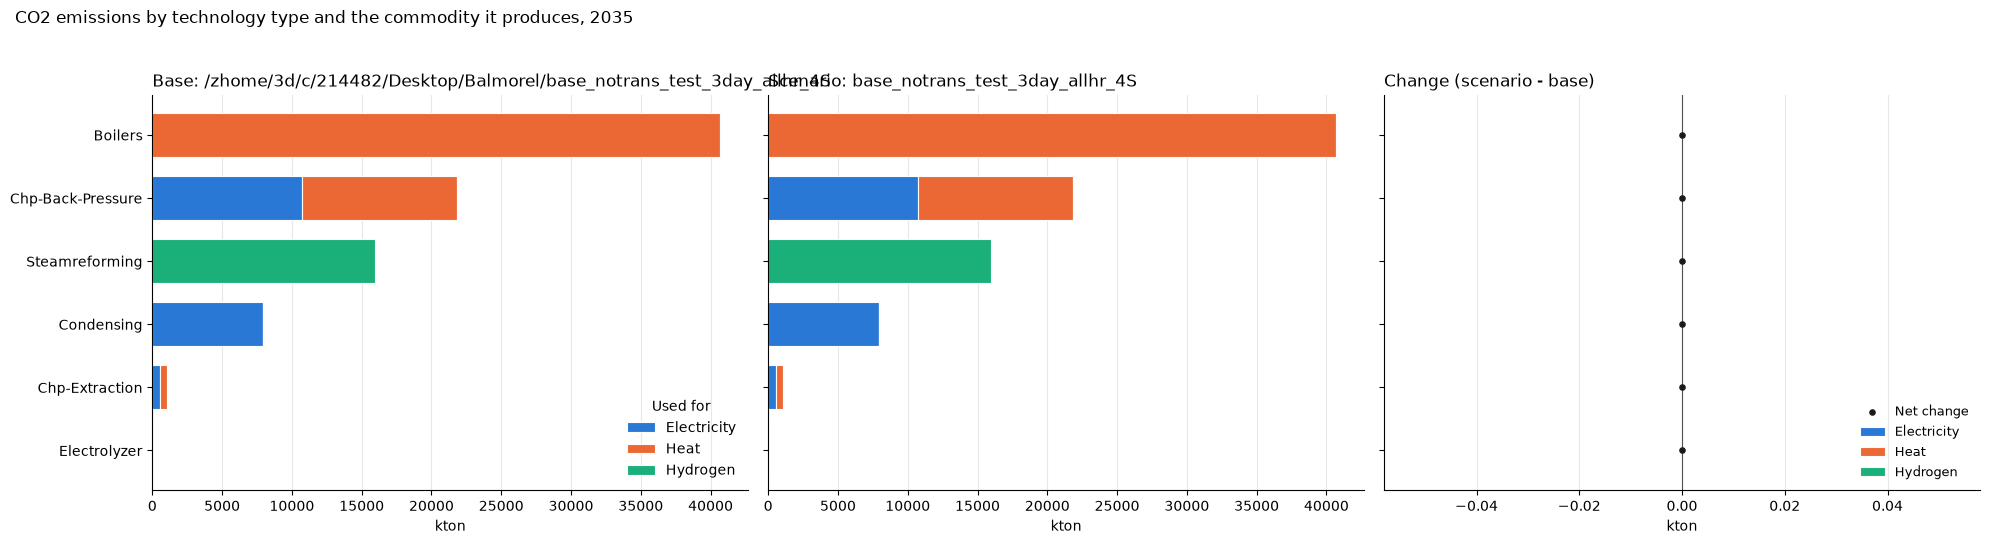

CO2 emissions by technology type and use, 2035 (kton)


Base                               Scenario           \
Use               Electricity     Heat Hydrogen    Total Electricity     Heat   
Technology                                                                      
Boilers                   0.0  40671.7      0.0  40671.7         0.0  40671.7   
Chp-Back-Pressure     10706.6  11130.9      0.0  21837.5     10706.6  11130.9   
Steamreforming            0.0      0.0  15965.7  15965.7         0.0      0.0   
Condensing             7924.6      0.0      0.0   7924.6      7924.6      0.0   
Chp-Extraction          532.8    528.4      0.0   1061.2       532.8    528.4   
Electrolyzer              0.0      0.0      0.4      0.4         0.0      0.0   
Total                 19164.0  52331.1  15966.1  87461.2     19164.0  52331.1   

                                         Change                      
Use               Hydrogen    Total Electricity Heat Hydrogen Total  
Technology                                                           
Boilers                0.0  40671.7         0.0  0.0      0.0   0.0  
Chp-Back-Pressure      0.0  21837.5         0.0  0.0      0.0   0.0  
Steamreforming     15965.7  15965.7         0.0  0.0      0.0   0.0  
Condensing             0.0   7924.6         0.0  0.0      0.0   0.0  
Chp-Extraction         0.0   1061.2         0.0  0.0      0.0   0.0  
Electrolyzer           0.4      0.4         0.0  0.0      0.0   0.0  
Total              15966.1  87461.2         0.0  0.0      0.0   0.0

In [52]:
# 10.4.2 CO2 emissions per technology type, split by the commodity it produces (as 6.1.1), in FOCUS_YEAR: base vs scenario (kton)
# Uses emissions_by_use of 10.4.1 (emissions allocated to the output commodities in proportion to the output) and USE_COLORS of 6.1.1
def tech_by_use(results, scenario):
    e = emissions_by_use(results, scenario)
    e = e.loc[e["Year"].eq(FOCUS_YEAR)].assign(Use=lambda d: d["Commodity"].str.title())
    return e.groupby(["Technology", "Use"])["Value"].sum().unstack("Use", fill_value=0)

use_b, use_s = tech_by_use(base_res, BASE_SCENARIO), tech_by_use(res, SCENARIO)
techs = use_b.index.union(use_s.index)
uses = [u for u in USE_COLORS if u in use_b.columns.union(use_s.columns)]
use_b, use_s = use_b.reindex(index=techs, columns=uses, fill_value=0), use_s.reindex(index=techs, columns=uses, fill_value=0)
use_d = use_s - use_b
techs = pd.concat([use_b.sum(axis=1), use_s.sum(axis=1)], axis=1).max(axis=1).sort_values().index    # largest emitter on top
y = np.arange(len(techs))

fig, axes = plt.subplots(1, 3, figsize=(20, 0.5 * len(techs) + 2.5), sharey=True)
x_max = max(use_b.sum(axis=1).max(), use_s.sum(axis=1).max()) * 1.05
panels = [(axes[0], use_b, f"Base: {BASE_SCENARIO}", False), (axes[1], use_s, f"Scenario: {SCENARIO}", False),
          (axes[2], use_d, "Change (scenario - base)", True)]
for ax, t, title, is_change in panels:
    t = t.reindex(techs)
    pos, neg = np.zeros(len(t)), np.zeros(len(t))
    for u in uses:
        v = t[u].to_numpy(dtype=float)
        ax.barh(y, v, left=np.where(v >= 0, pos, neg), height=0.7, color=USE_COLORS[u], edgecolor="#fcfcfb", linewidth=0.8, label=u)
        pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
    if is_change:
        ax.scatter(t.sum(axis=1), y, color="#1a1a1a", s=14, zorder=3, label="Net change")
        ax.axvline(0, color="#52514e", linewidth=0.8); ax.margins(x=0.08)
    else:
        ax.set_xlim(0, x_max)                                                # base and scenario on the same scale
    ax.set_yticks(y); ax.set_yticklabels([clean_name(c) for c in techs])
    style(ax, title, "", axis="x"); ax.set_xlabel("kton")
axes[0].legend(*axes[0].get_legend_handles_labels(), title="Used for", loc="lower right", frameon=False)
axes[2].legend(*axes[2].get_legend_handles_labels(), loc="lower right", frameon=False, fontsize=9)
fig.suptitle(f"CO2 emissions by technology type and the commodity it produces, {FOCUS_YEAR}", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

table = pd.concat({"Base": use_b, "Scenario": use_s, "Change": use_d}, axis=1).reindex(techs[::-1])
for run, t in [("Base", use_b), ("Scenario", use_s), ("Change", use_d)]:
    table[(run, "Total")] = t.reindex(techs[::-1]).sum(axis=1)
table = table.reindex(columns=[(run, u) for run in ("Base", "Scenario", "Change") for u in uses + ["Total"]])
table.loc["Total"] = table.sum()
print(f"CO2 emissions by technology type and use, {FOCUS_YEAR} (kton)")
display(table.rename(index=clean_name).round(1))

## 11. Country level: base vs scenario
Where the changes happen, in the order capacity, dispatch, CO2 emissions and cost.

### 11.1 Map of the changes in installed capacity and transmission
The geographical counterpart of 3.4, showing scenario - base in `MAP_YEAR` (default: last common year) for `MAP_COMMODITY`:
- **Background**: net change in installed capacity per region (GW, red = more capacity in the scenario).
- **Pies**: gross change per region by fuel. Pie area is proportional to the sum of the absolute changes; each wedge is one fuel's share of it, and hatched wedges are decreases. Fuel colours are those of 10.1.
- **Lines**: change in transmission. With `MAP_LINES = "auto"` the map shows the change in transmission capacity, or, when the capacities are identical in both runs (e.g. no transmission investment), the change in the annual net flow between the two regions, with the arrow pointing in the direction of the additional flow.
Lines are drawn straight between region centres (pybalmorel's `coordinates_RRR.csv`), without the bypass hooks of 3.4.

Lines show the change in transmission annual net flow (TWh); 0 region pairs changed, 0 drawn (>= 5% of the largest change)


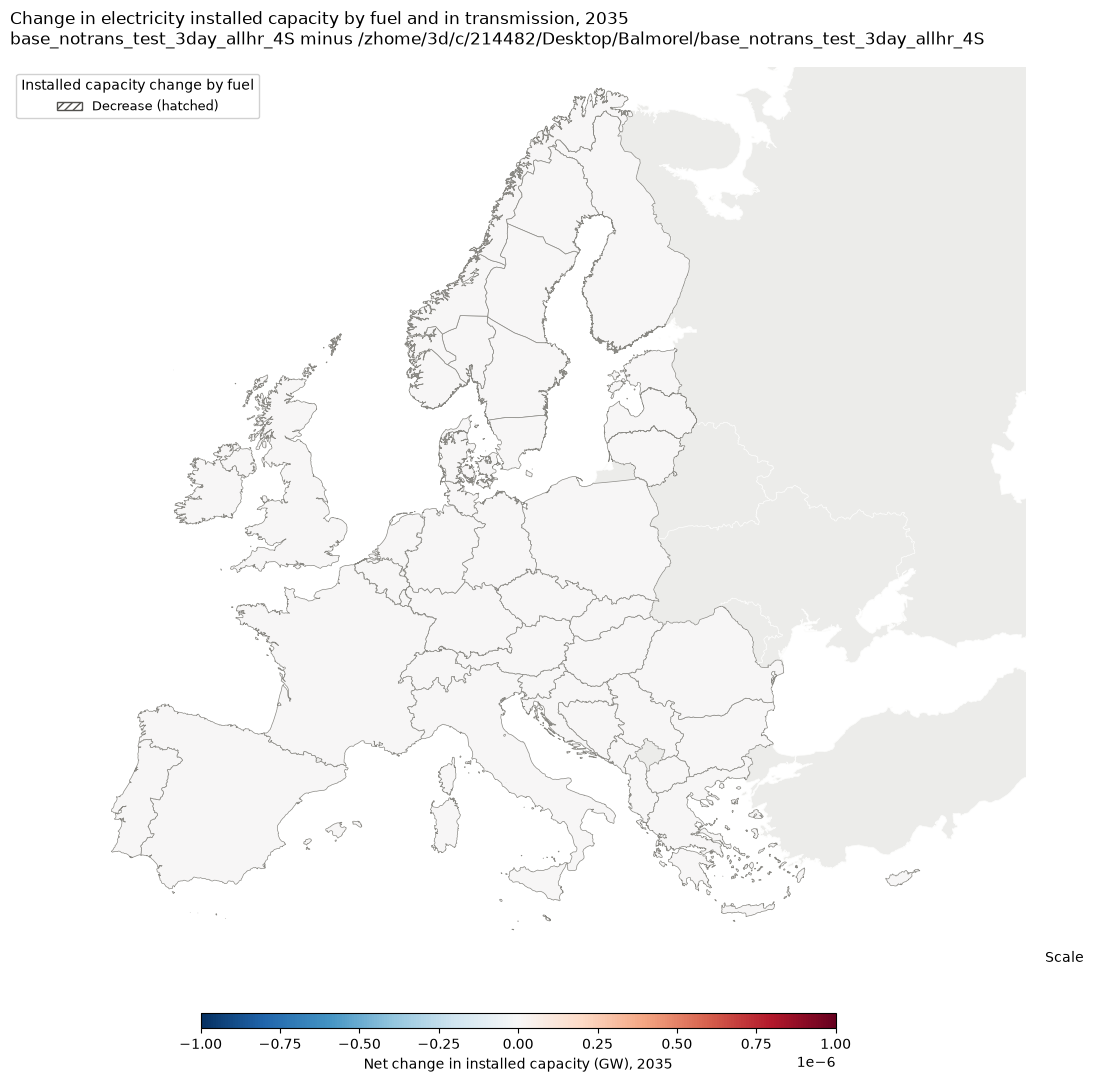

Fuel,WIND,SUN,WATER,NATGAS,NUCLEAR,ELECTRIC,WOODCHIPS,Other,Net,Gross
Region,,,,,,,,,,
AL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BA,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BE,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BG,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CH,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CY,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CZ,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DE4-E,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [53]:
# 11.1 Map of the changes (scenario - base) in installed capacity by fuel and in transmission
import geopandas as gpd
import pybalmorel
from matplotlib.patches import Wedge, Patch, FancyArrowPatch
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm

MAP_YEAR = LAST_YEAR                 # any of COMPARISON_YEARS, as a string
MAP_COMMODITY = "ELECTRICITY"        # "ELECTRICITY" or "HYDROGEN" (selects X_* or XH2_* for the lines)
MAP_LINES = "auto"                   # "Capacity", "Flow" or "auto"
MIN_CHANGE = 0.05                    # GW of gross change below which a region gets no pie
MIN_LINE_SHARE = 0.05                # lines changing less than this share of the largest line change are not drawn
CRS = "EPSG:3035"                    # equal-area projection for Europe, so pies stay round

GEO_DIR = Path(pybalmorel.__file__).parent / "geofiles"
polygons = gpd.read_file(GEO_DIR / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs(CRS)
centres = pd.read_csv(GEO_DIR / "coordinates_RRR.csv").drop_duplicates("RRR")
centres = gpd.GeoSeries(gpd.points_from_xy(centres["Lon"], centres["Lat"]), index=centres["RRR"], crs="EPSG:4326").to_crs(CRS)
xy = {r: (p.x, p.y) for r, p in centres.items()}

# Capacity change per region and fuel, with the fuels folded as in 10.1 (same colours)
def region_capacity(results, scenario):
    t = scenario_result(results, scenario, "G_CAP_YCRAF")
    t = t.loc[t["Year"].astype(str).eq(MAP_YEAR) & t["Commodity"].eq(MAP_COMMODITY)]
    return t.groupby(["Region", "Fuel"])["Value"].sum().unstack("Fuel", fill_value=0)

cap_change = region_capacity(res, SCENARIO).sub(region_capacity(base_res, BASE_SCENARIO), fill_value=0)
_, _, fuel_colors = align(by_year(base_res, BASE_SCENARIO, "G_CAP_YCRAF", "Fuel", MAP_COMMODITY),
                          by_year(res, SCENARIO, "G_CAP_YCRAF", "Fuel", MAP_COMMODITY))
keep = [f for f in fuel_colors if f != "Other"]
cap_change = cap_change.reindex(columns=cap_change.columns.union(keep), fill_value=0)
cap_change = cap_change[keep].assign(Other=cap_change.drop(columns=keep).sum(axis=1)) if "Other" in fuel_colors else cap_change[keep]
net_change = cap_change.sum(axis=1)
gross_change = cap_change.abs().sum(axis=1)

# Transmission change per region pair: capacity (largest of the two directions) or net flow from the first to the second region
X_SYMBOLS = {"ELECTRICITY": ("X_CAP_YCR", "X_FLOW_YCR"), "HYDROGEN": ("XH2_CAP_YCR", "XH2_FLOW_YCR")}[MAP_COMMODITY]

def pair_values(results, scenario, symbol, net):
    t = scenario_result(results, scenario, symbol)
    t = t.loc[t["Year"].astype(str).eq(MAP_YEAR)].groupby(["From", "To"])["Value"].sum()
    out = {}
    for (a, b), v in t.items():
        key, sign = ((a, b), 1) if a < b else ((b, a), -1)
        out[key] = out.get(key, 0) + sign * v if net else max(out.get(key, 0), v)
    return pd.Series(out, dtype=float)

def pair_change(symbol, net):
    s, b = pair_values(res, SCENARIO, symbol, net), pair_values(base_res, BASE_SCENARIO, symbol, net)
    return s.sub(b, fill_value=0)

line_mode = MAP_LINES
if line_mode == "auto":
    line_mode = "Capacity" if pair_change(X_SYMBOLS[0], net=False).abs().max() > 1e-3 else "Flow"
line_change = pair_change(X_SYMBOLS[0], net=False) if line_mode == "Capacity" else pair_change(X_SYMBOLS[1], net=True)
line_unit = "GW" if line_mode == "Capacity" else "TWh"
n_changed = int((line_change.abs() > 1e-3).sum())
line_change = line_change[line_change.abs() >= MIN_LINE_SHARE * line_change.abs().max()] if n_changed else line_change.iloc[:0]
print(f"Lines show the change in transmission {'capacity' if line_mode == 'Capacity' else 'annual net flow'} ({line_unit}); "
      f"{n_changed} region pairs changed, {len(line_change)} drawn (>= {MIN_LINE_SHARE:.0%} of the largest change)")

# --- Map (also used for the change in dispatch in 11.2) ------------------------------------------------------
def pie_change_map(change, unit, min_change, lines, line_mode, line_unit, what):
    """Map of a change per region and fuel (`change`: region x fuel, in `unit`): background = net change,
    pies = gross change by fuel (hatched = decrease), lines = change in transmission (`lines`, as above)."""
    net, gross = change.sum(axis=1), change.abs().sum(axis=1)
    fig, ax = plt.subplots(figsize=(13, 12))
    in_model = polygons["id"].isin(net.index)
    polygons[~in_model].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)
    lim = max(net.abs().max(), 1e-6)
    norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    model_polys = polygons[in_model].assign(net=lambda d: d["id"].map(net).fillna(0))
    model_polys.plot(ax=ax, column="net", cmap="RdBu_r", norm=norm, edgecolor="#8a8984", linewidth=0.5)

    # Transmission: width proportional to the change, solid = increase, dashed = decrease (capacity);
    # for flows the arrow points to where the additional net flow goes
    max_line = lines.abs().max() if len(lines) else 1
    for (a, b), v in lines.items():
        if a not in xy or b not in xy:
            continue
        width = 1 + 6 * abs(v) / max_line
        (x0, y0), (x1, y1) = xy[a], xy[b]
        if line_mode == "Flow" and v < 0:                    # more net flow from b to a
            (x0, y0), (x1, y1) = (x1, y1), (x0, y0)
        style_kw = dict(color="#1a1a1a", linewidth=width, alpha=0.8, zorder=3)
        if line_mode == "Capacity":
            ax.plot([x0, x1], [y0, y1], linestyle="-" if v > 0 else "--", solid_capstyle="round", **style_kw)
        else:
            ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle=f"-|>,head_length={0.3 + 0.08 * width},head_width={0.15 + 0.05 * width}",
                                         shrinkA=12, shrinkB=12, mutation_scale=10, **style_kw))

    # Pies of the gross change by fuel (area proportional to the gross change)
    R_MAX = 160e3                                            # radius in metres of the largest pie
    g_max = gross.max()
    for region, row in change.iterrows():
        if gross[region] < min_change or region not in xy:
            continue
        r = R_MAX * np.sqrt(gross[region] / g_max)
        start = 90.0
        for fuel, v in row.items():
            if abs(v) < 1e-9:
                continue
            sweep = 360 * abs(v) / gross[region]
            ax.add_patch(Wedge(xy[region], r, start, start + sweep, facecolor=fuel_colors[fuel], edgecolor="#fcfcfb",
                               linewidth=0.6, hatch="////" if v < 0 else None, zorder=4))
            start += sweep

    # Extent: the centres of the modelled regions plus a margin (polygon bounds would include e.g. the Azores)
    model_xy = np.array([xy[r] for r in model_polys["id"] if r in xy])
    ax.set_xlim(model_xy[:, 0].min() - 6e5, model_xy[:, 0].max() + 6e5); ax.set_ylim(model_xy[:, 1].min() - 4e5, model_xy[:, 1].max() + 4e5)
    ax.set_axis_off()
    ax.set_title(f"Change in {MAP_COMMODITY.lower()} {what} by fuel and in transmission, {MAP_YEAR}\n"
                 f"{SCENARIO} minus {BASE_SCENARIO}", loc="left")

    # Legends: fuels, pie size, lines, background
    fuel_handles = [Patch(facecolor=fuel_colors[f], label=clean_name(f)) for f in change.columns if change[f].abs().max() > 1e-9]
    fuel_handles.append(Patch(facecolor="white", edgecolor="#52514e", hatch="////", label="Decrease (hatched)"))
    leg1 = ax.legend(handles=fuel_handles, title=f"{what.capitalize()} change by fuel", loc="upper left", frameon=True, framealpha=0.9, fontsize=9)
    ax.add_artist(leg1)
    plt.tight_layout()
    pt_per_m = (ax.transData.transform((R_MAX, 0))[0] - ax.transData.transform((0, 0))[0]) * 72 / fig.dpi / R_MAX   # pies drawn to scale in the legend
    size_refs = [v for v in (g_max, g_max / 4) if v >= min_change]
    size_handles = [Line2D([], [], marker="o", linestyle="", markerfacecolor="#d0d0cc", markeredgecolor="#52514e",
                           markersize=2 * R_MAX * np.sqrt(v / g_max) * pt_per_m, label=f"{v:.1f} {unit} gross") for v in size_refs]
    if len(lines):
        for v in (max_line, max_line / 2):
            size_handles.append(Line2D([], [], color="#1a1a1a", linewidth=1 + 6 * v / max_line,
                                       label=f"{v:.1f} {line_unit} {'capacity' if line_mode == 'Capacity' else 'net flow'}"))
        if line_mode == "Capacity":
            size_handles.append(Line2D([], [], color="#1a1a1a", linestyle="--", linewidth=2, label="Decrease (dashed)"))
    max_marker = max([h.get_markersize() for h in size_handles if h.get_marker() == "o"], default=10)       # points
    ax.legend(handles=size_handles, title="Scale", loc="lower left", bbox_to_anchor=(1.0, 0.0), frameon=False, fontsize=9,
              labelspacing=max(1.4, 0.8 * max_marker / 9), handlelength=max(2, max_marker / 9), borderpad=1)
    sm = plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm)
    fig.colorbar(sm, ax=ax, orientation="horizontal", shrink=0.5, pad=0.01, aspect=40, label=f"Net change in {what} ({unit}), {MAP_YEAR}")
    plt.tight_layout(); plt.show()

pie_change_map(cap_change, "GW", MIN_CHANGE, line_change, line_mode, line_unit, "installed capacity")

# The regions with the largest gross change, for reference
top = cap_change.loc[gross_change.sort_values(ascending=False).head(10).index]
display(top.assign(Net=net_change, Gross=gross_change).round(2))
if len(line_change):
    print(f"Largest transmission changes ({line_unit}, positive = first region -> second region for flows):")
    display(line_change.reindex(line_change.abs().sort_values(ascending=False).index).head(10).round(2).rename("Change").to_frame())

#### 11.1.1 Change in installed capacity by fuel per country (2030 and 2035)
Scenario - base installed capacity (GW) per country and fuel for `MAP_COMMODITY`, with the fuels folded and coloured as in the map above (and 10.1). Bars to the right are increases, bars to the left decreases; the black dot is the net change. Only countries with a change of at least `MIN_COUNTRY_CHANGE` GW (gross) are shown.

In [54]:
# 11.1.1 Change (scenario - base) in installed capacity by fuel for each country, in 2030 and 2035
COUNTRY_CAP_YEARS = [y for y in ["2030", "2035"] if y in COMPARISON_YEARS]
MIN_COUNTRY_CHANGE = 0.01            # GW of gross change below which a country is left out

def country_capacity(results, scenario, year):
    t = scenario_result(results, scenario, "G_CAP_YCRAF")
    t = t.loc[t["Year"].astype(str).eq(year) & t["Commodity"].eq(MAP_COMMODITY)]
    return t.groupby(["Country", "Fuel"])["Value"].sum().unstack("Fuel", fill_value=0)

def fold_fuels(t):
    """Same fuel columns and 'Other' folding as the map (keep / fuel_colors from 8.7)."""
    t = t.reindex(columns=t.columns.union(keep), fill_value=0)
    return t[keep].assign(Other=t.drop(columns=keep).sum(axis=1)) if "Other" in fuel_colors else t[keep]

country_cap_change = {}
for year in COUNTRY_CAP_YEARS:
    d = fold_fuels(country_capacity(res, SCENARIO, year).sub(country_capacity(base_res, BASE_SCENARIO, year), fill_value=0))
    country_cap_change[year] = d.loc[d.abs().sum(axis=1) >= MIN_COUNTRY_CHANGE]

# One country order for all panels: largest net change (summed over the years) at the top
countries = pd.Index(sorted(set().union(*[d.index for d in country_cap_change.values()])))
if countries.empty:
    print(f"No country changes its {MAP_COMMODITY.lower()} capacity by more than {MIN_COUNTRY_CHANGE} GW in {', '.join(COUNTRY_CAP_YEARS)}")
else:
    net_total = sum(d.sum(axis=1).reindex(countries, fill_value=0) for d in country_cap_change.values())
    countries = net_total.sort_values().index                       # barh draws bottom-up, so the largest ends on top
    fuels = [f for f in keep + ["Other"] if f in fuel_colors and any(d.get(f, pd.Series(dtype=float)).abs().max() > 1e-9 for d in country_cap_change.values())]
    hi = max([d.clip(lower=0).sum(axis=1).max() for d in country_cap_change.values() if len(d)] + [0])     # same x-range in every panel
    lo = min([d.clip(upper=0).sum(axis=1).min() for d in country_cap_change.values() if len(d)] + [0])
    pad = 0.05 * (hi - lo)

    fig, axes = plt.subplots(1, len(COUNTRY_CAP_YEARS), figsize=(7 * len(COUNTRY_CAP_YEARS) + 2, 0.32 * len(countries) + 2),
                             sharey=True, squeeze=False)
    y = np.arange(len(countries))
    for ax, year in zip(axes.ravel(), COUNTRY_CAP_YEARS):
        d = country_cap_change[year].reindex(index=countries, columns=fuels, fill_value=0)
        pos, neg = np.zeros(len(d)), np.zeros(len(d))
        for fuel in fuels:
            v = d[fuel].to_numpy(dtype=float)
            ax.barh(y, v, left=np.where(v >= 0, pos, neg), height=0.75, color=fuel_colors[fuel], edgecolor="#fcfcfb", linewidth=0.6,
                    label=clean_name(fuel))
            pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
        ax.scatter(d.sum(axis=1), y, color="#1a1a1a", s=14, zorder=3, label="Net change")
        ax.axvline(0, color="#52514e", linewidth=0.8)
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_yticks(y); ax.set_yticklabels([clean_name(c) for c in countries])
        style(ax, f"{year}", "", axis="x"); ax.set_xlabel("Change in installed capacity (GW)")
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    axes.ravel()[-1].legend(handles, labels, bbox_to_anchor=(1.0, 1), loc="upper left", frameon=False, fontsize=9)
    fig.suptitle(f"Change in {MAP_COMMODITY.lower()} capacity by fuel per country: {SCENARIO} minus {BASE_SCENARIO}", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

    # Table: one block of fuel columns per year, plus the net change
    table = pd.concat({year: country_cap_change[year].reindex(index=countries[::-1], columns=fuels, fill_value=0)
                             .rename(columns=clean_name).assign(Net=lambda t: t.sum(axis=1)) for year in COUNTRY_CAP_YEARS}, axis=1)
    display(table.round(2))


No country changes its electricity capacity by more than 0.01 GW in 2030, 2035


### 11.2 Map of the changes in dispatch and transmission flow
The dispatch counterpart of the 11.1 map: scenario - base annual dispatch (`PRO_YCRAGF`, TWh) of `MAP_COMMODITY` in `MAP_YEAR`, with the fuels folded and coloured as in 11.1.
- **Background**: net change in dispatch per region (TWh, red = more generation in the scenario).
- **Pies**: gross change per region by fuel; pie area is proportional to the sum of the absolute changes, hatched wedges are decreases. Regions changing less than `MIN_DISPATCH_CHANGE` TWh get no pie.
- **Arrows**: change in the annual net transmission flow between two regions (TWh), pointing in the direction of the additional flow.

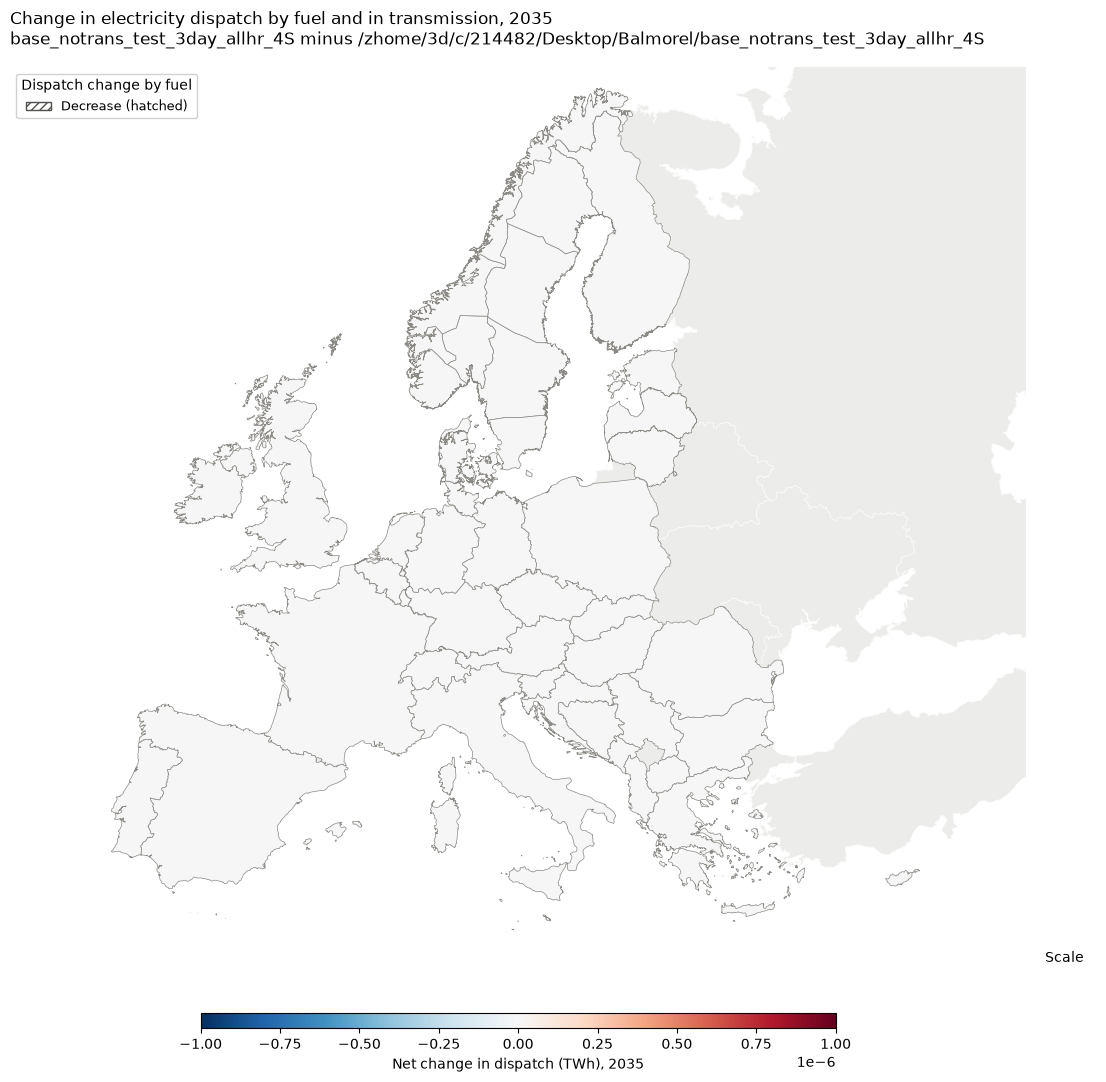

Fuel,WIND,SUN,WATER,NATGAS,NUCLEAR,ELECTRIC,WOODCHIPS,Other,Net,Gross
Region,,,,,,,,,,
AL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BA,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BE,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BG,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CH,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CY,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CZ,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DE4-E,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [55]:
# 11.2 Map of the changes (scenario - base) in annual dispatch by fuel and in the transmission net flow
# Uses MAP_YEAR, MAP_COMMODITY, the fuel folding/colours (keep, fuel_colors) and pie_change_map of 11.1
MIN_DISPATCH_CHANGE = 0.1            # TWh of gross change below which a region gets no pie

def region_dispatch(results, scenario):
    t = scenario_result(results, scenario, "PRO_YCRAGF")
    t = t.loc[t["Year"].astype(str).eq(MAP_YEAR) & t["Commodity"].eq(MAP_COMMODITY)]
    return t.groupby(["Region", "Fuel"])["Value"].sum().unstack("Fuel", fill_value=0)

pro_change = region_dispatch(res, SCENARIO).sub(region_dispatch(base_res, BASE_SCENARIO), fill_value=0)
pro_change = pro_change.reindex(columns=pro_change.columns.union(keep), fill_value=0)
pro_change = pro_change[keep].assign(Other=pro_change.drop(columns=keep).sum(axis=1)) if "Other" in fuel_colors else pro_change[keep]

# Lines: always the change in annual net flow, which is what moves with the dispatch
flow_change = pair_change(X_SYMBOLS[1], net=True)
flow_change = flow_change[flow_change.abs() >= MIN_LINE_SHARE * flow_change.abs().max()] if (flow_change.abs() > 1e-3).any() else flow_change.iloc[:0]

pie_change_map(pro_change, "TWh", MIN_DISPATCH_CHANGE, flow_change, "Flow", "TWh", "dispatch")

# The regions with the largest gross change in dispatch, for reference
pro_gross = pro_change.abs().sum(axis=1)
display(pro_change.loc[pro_gross.sort_values(ascending=False).head(10).index].assign(Net=pro_change.sum(axis=1), Gross=pro_gross).round(2))

### 11.3 Change in CO2 emissions per country (%)
Map of the change per country (scenario - base) in the CO2 emissions (`EMI_YCRAG`, % of the base emissions of the country) in `FOCUS_YEAR`, with the table in kton.

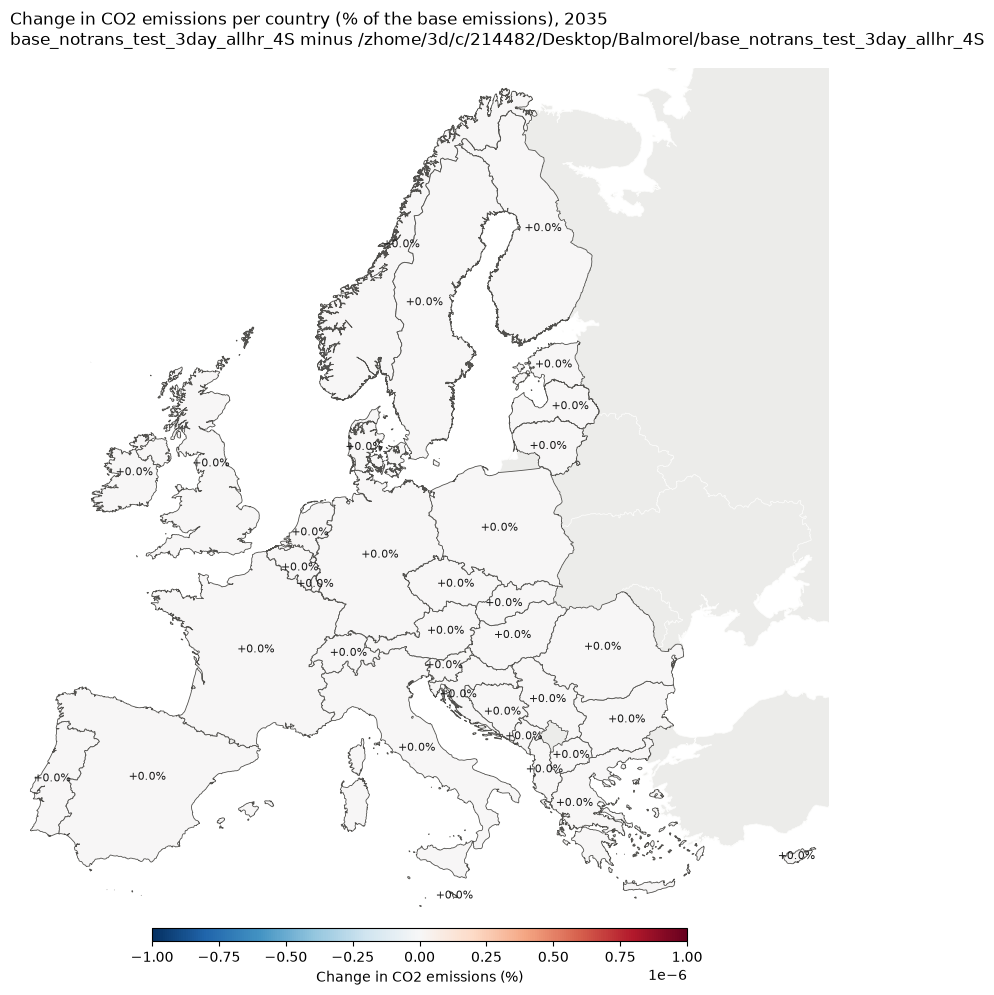

CO2 emissions per country, 2035 (kton), largest relative increase first


,/zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S,base_notrans_test_3day_allhr_4S,Change (kton),Change (%)
Country,,,,
ALBANIA,146.91,146.91,0.0,0.0
AUSTRIA,1968.64,1968.64,0.0,0.0
BELGIUM,4162.65,4162.65,0.0,0.0
BOSNIA_AND_HERZEGOVINA,330.54,330.54,0.0,0.0
BULGARIA,1278.10,1278.10,0.0,0.0
CROATIA,788.31,788.31,0.0,0.0
CYPRUS,126.78,126.78,0.0,0.0
CZECH_REPUBLIC,1545.33,1545.33,0.0,0.0
DENMARK,1613.24,1613.24,0.0,0.0


In [56]:
# 11.3 Map of the change (scenario - base) in CO2 emissions per country in FOCUS_YEAR (% of the base emissions)
# The setup (country polygons, country_change_table, change_map) is reused by the cost map of 11.4
import geopandas as gpd
import pybalmorel
from matplotlib.colors import TwoSlopeNorm

def country_total(results, scenario, symbol):
    t = scenario_result(results, scenario, symbol)
    return t.loc[t["Year"].astype(str).eq(FOCUS_YEAR)].groupby("Country")["Value"].sum()

def country_change_table(symbol, unit):
    t = pd.DataFrame({BASE_SCENARIO: country_total(base_res, BASE_SCENARIO, symbol),
                      SCENARIO: country_total(res, SCENARIO, symbol)}).fillna(0)
    t[f"Change ({unit})"] = t[SCENARIO] - t[BASE_SCENARIO]
    t["Change (%)"] = t[f"Change ({unit})"] / t[BASE_SCENARIO].replace(0, np.nan) * 100
    return t

emi_focus = country_change_table("EMI_YCRAG", "kton")

# Country polygons = the region polygons of pybalmorel's geofile, merged per country (region -> country from the results)
region_country_focus = pd.concat([scenario_result(r, s, "OBJ_YCR") for r, s in [(base_res, BASE_SCENARIO), (res, SCENARIO)]]) \
                         .drop_duplicates("Region").set_index("Region")["Country"]
geo_focus = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
geo_focus["Country"] = geo_focus["id"].map(region_country_focus)
country_shapes = geo_focus.dropna(subset=["Country"]).dissolve(by="Country")
mainland = lambda g: max(getattr(g, "geoms", [g]), key=lambda p: p.area)

def change_map(values, title, label, fmt):
    """Country map of `values` (change, scenario - base) on a diverging scale centred on 0, red = higher in the scenario."""
    shapes = country_shapes.join(values.rename("Change"))
    fig, ax = plt.subplots(figsize=(11, 11))
    geo_focus[geo_focus["Country"].isna()].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)     # outside the model
    lim = max(values.abs().max(), 1e-6)
    norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    shapes.plot(ax=ax, column="Change", cmap="RdBu_r", norm=norm, edgecolor="#52514e", linewidth=0.6,
                missing_kwds={"color": "#ececea", "edgecolor": "#52514e", "linewidth": 0.6})
    # Label every country with its change; the label sits on the largest part of the country (mainland, not islands)
    for name, row in shapes.iterrows():
        if pd.isna(row["Change"]):
            continue
        p = mainland(row.geometry).representative_point()
        ax.annotate(fmt.format(row["Change"]), (p.x, p.y), ha="center", va="center", fontsize=8,
                    color="white" if abs(row["Change"]) > 0.6 * lim else "#1a1a1a")
    minx, miny, maxx, maxy = shapes.geometry.apply(mainland).total_bounds
    ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
    ax.set_axis_off()
    ax.set_title(f"{title}, {FOCUS_YEAR}\n{SCENARIO} minus {BASE_SCENARIO}", loc="left")
    fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=ax, orientation="horizontal", shrink=0.5, pad=0.01, aspect=40, label=label)
    plt.tight_layout(); plt.show()

change_map(emi_focus["Change (%)"], "Change in CO2 emissions per country (% of the base emissions)",
           "Change in CO2 emissions (%)", "{:+.1f}%")
print(f"CO2 emissions per country, {FOCUS_YEAR} (kton), largest relative increase first")
display(emi_focus.sort_values("Change (%)", ascending=False).round(2))

### 11.4 Change in total system cost per country (%)
Map of the change per country (scenario - base) in the total system cost (`OBJ_YCR`, % of the base cost of the country) in `FOCUS_YEAR`, with the table in Mmoney. The marginal electricity cost follows in 11.4.1 - 11.4.3.

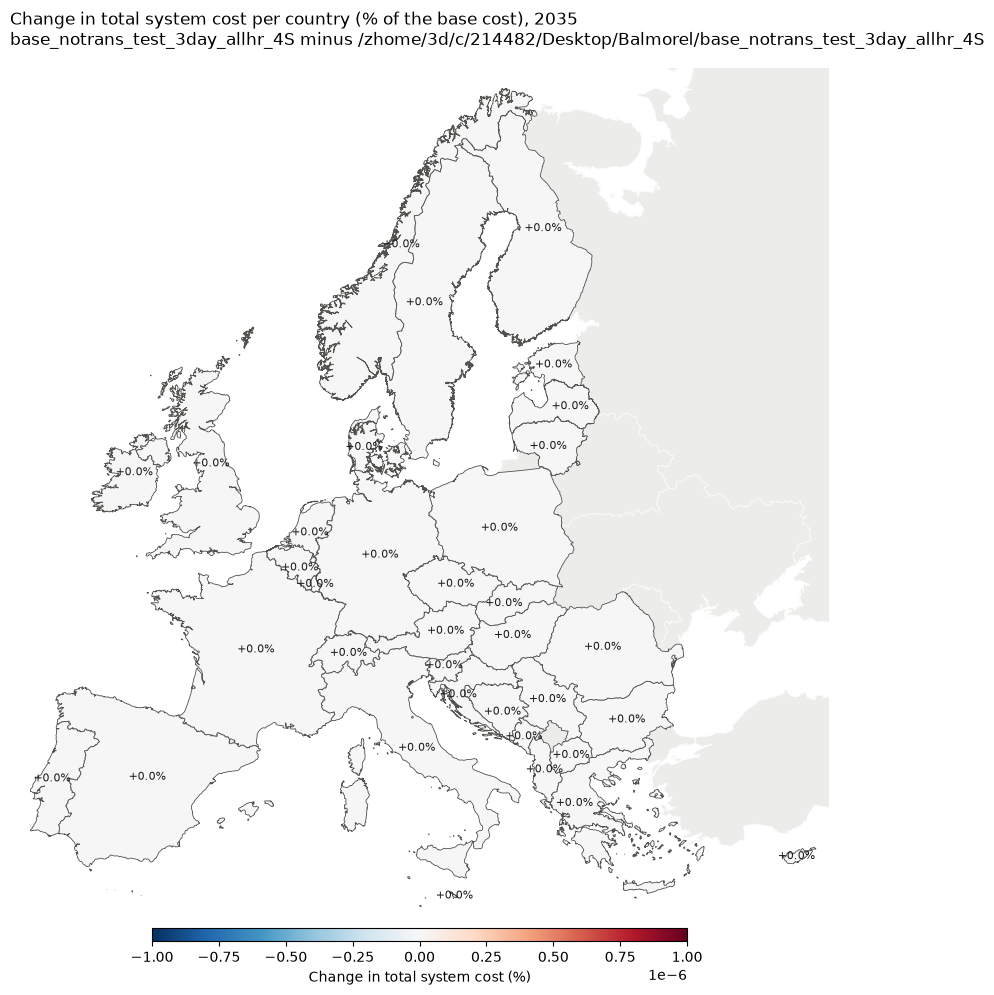

Total system cost per country, 2035 (Mmoney), largest relative increase first


,/zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S,base_notrans_test_3day_allhr_4S,Change (Mmoney),Change (%)
Country,,,,
ALBANIA,345.23,345.23,0.0,0.0
AUSTRIA,7248.08,7248.08,0.0,0.0
BELGIUM,8337.98,8337.98,0.0,0.0
BOSNIA_AND_HERZEGOVINA,743.35,743.35,0.0,0.0
BULGARIA,3000.95,3000.95,0.0,0.0
CROATIA,1714.03,1714.03,0.0,0.0
CYPRUS,268.76,268.76,0.0,0.0
CZECH_REPUBLIC,6206.37,6206.37,0.0,0.0
DENMARK,5241.93,5241.93,0.0,0.0


In [57]:
# 11.4 Map of the change (scenario - base) in total system cost per country in FOCUS_YEAR (% of the base cost)
# Uses country_change_table and change_map of 11.3
cost_focus = country_change_table("OBJ_YCR", "Mmoney")

change_map(cost_focus["Change (%)"], "Change in total system cost per country (% of the base cost)",
           "Change in total system cost (%)", "{:+.1f}%")
print(f"Total system cost per country, {FOCUS_YEAR} (Mmoney), largest relative increase first")
display(cost_focus.sort_values("Change (%)", ascending=False).round(2))

#### 11.4.1 Map of the change in marginal electricity cost per country
Change (scenario - base) in the demand-weighted average marginal cost of electricity per country in `PRICE_MAP_YEAR` (default: last common year), from `EL_PRICE_YCR` (time-averaged marginal cost of the electricity balance per region, Money/MWh). Regions of the same country are combined, weighted by their annual electricity demand. Red = more expensive in the scenario.

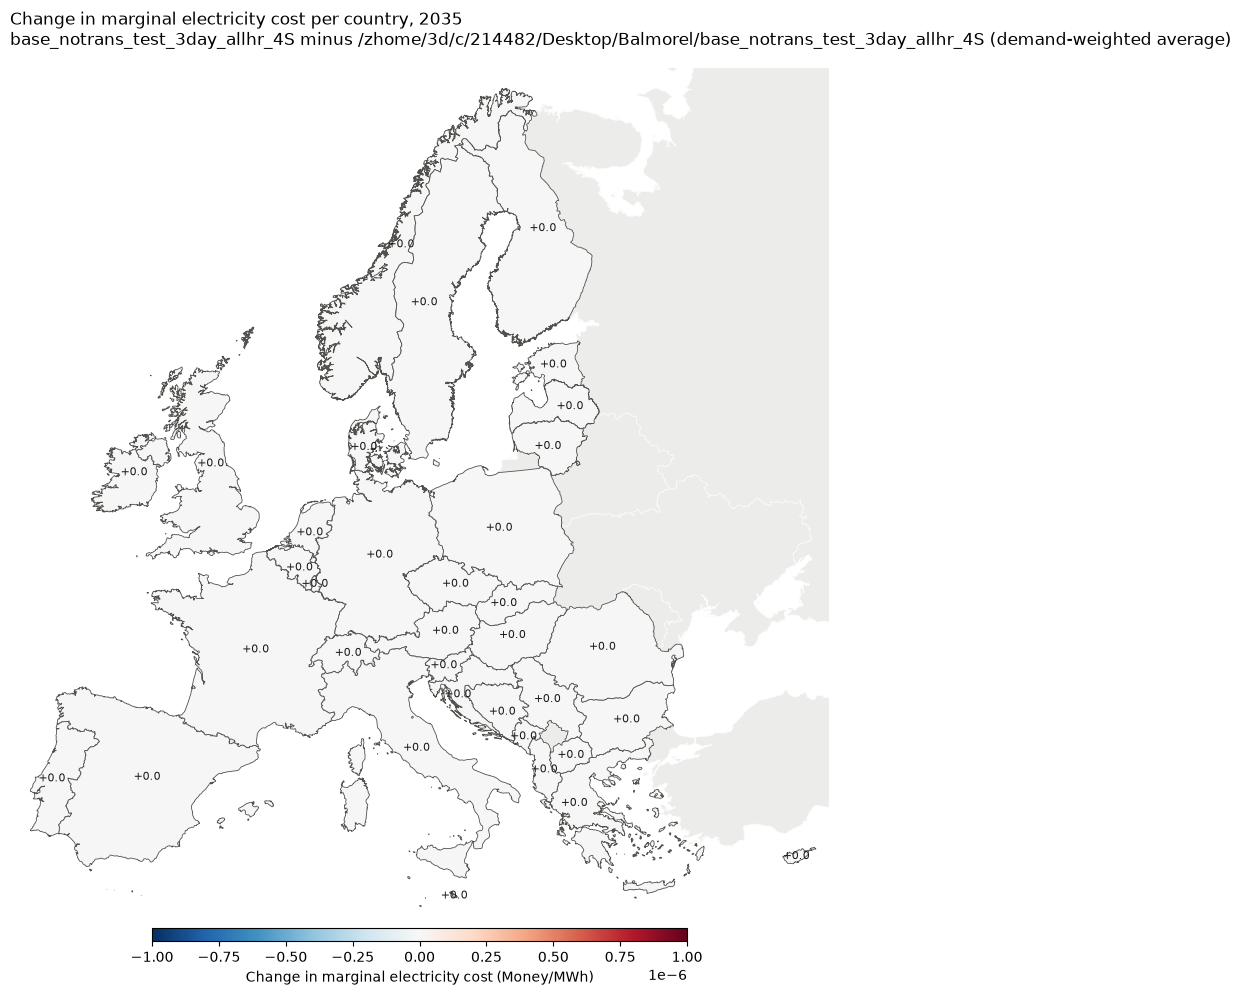

,/zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S,base_notrans_test_3day_allhr_4S,Change,Change (%)
Country,,,,
ALBANIA,44.52,44.52,0.0,0.0
AUSTRIA,42.06,42.06,0.0,0.0
BELGIUM,42.19,42.19,0.0,0.0
BOSNIA_AND_HERZEGOVINA,47.41,47.41,0.0,0.0
BULGARIA,44.95,44.95,0.0,0.0
CROATIA,47.51,47.51,0.0,0.0
CYPRUS,44.26,44.26,0.0,0.0
CZECH_REPUBLIC,46.85,46.85,0.0,0.0
DENMARK,34.53,34.53,0.0,0.0


In [58]:
# 11.4.1 Change in the demand-weighted marginal electricity cost per country (Money/MWh)
import geopandas as gpd
import pybalmorel
from matplotlib.colors import TwoSlopeNorm

PRICE_MAP_YEAR = COMPARISON_YEARS[-1]        # any of COMPARISON_YEARS, as a string

price_country = pd.DataFrame({BASE_SCENARIO: price_by(base_res, BASE_SCENARIO, "Country").xs(PRICE_MAP_YEAR, level="Year"),
                              SCENARIO: price_by(res, SCENARIO, "Country").xs(PRICE_MAP_YEAR, level="Year")})
price_country["Change"] = price_country[SCENARIO] - price_country[BASE_SCENARIO]
price_country["Change (%)"] = price_country["Change"] / price_country[BASE_SCENARIO] * 100

# Country polygons = the region polygons of pybalmorel's geofile, merged per country (region -> country from the results)
region_country = scenario_result(res, SCENARIO, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
geo = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
geo["Country"] = geo["id"].map(region_country)
countries = geo.dropna(subset=["Country"]).dissolve(by="Country").join(price_country)

fig, ax = plt.subplots(figsize=(11, 11))
geo[geo["Country"].isna()].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)       # outside the model
lim = max(price_country["Change"].abs().max(), 1e-6)
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
countries.plot(ax=ax, column="Change", cmap="RdBu_r", norm=norm, edgecolor="#52514e", linewidth=0.6)
# Label every country with its change; the label sits on the largest part of the country (mainland, not islands)
for name, row in countries.iterrows():
    part = max(getattr(row.geometry, "geoms", [row.geometry]), key=lambda g: g.area)
    p = part.representative_point()
    ax.annotate(f"{row['Change']:+.1f}", (p.x, p.y), ha="center", va="center", fontsize=8,
                color="white" if abs(row["Change"]) > 0.6 * lim else "#1a1a1a")
minx, miny, maxx, maxy = countries.geometry.apply(lambda g: max(getattr(g, "geoms", [g]), key=lambda x: x.area)).total_bounds
ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
ax.set_axis_off()
ax.set_title(f"Change in marginal electricity cost per country, {PRICE_MAP_YEAR}\n{SCENARIO} minus {BASE_SCENARIO} (demand-weighted average)", loc="left")
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm), ax=ax, orientation="horizontal", shrink=0.5, pad=0.01, aspect=40,
             label="Change in marginal electricity cost (Money/MWh)")
plt.tight_layout(); plt.show()

display(price_country.sort_values("Change", ascending=False).round(2))


#### 11.4.2 Marginal electricity cost per country: base, scenario and change
The demand-weighted average marginal cost of electricity per country of 11.4.1 (`EL_PRICE_YCR`, regions weighted by their annual electricity demand) in `PRICE_MAP_YEAR`, for the base (left) and the scenario (middle) on a common colour scale, and the change (right, red = more expensive in the scenario). The labels give the value per country; the numbers are those of the table in 11.4.1.

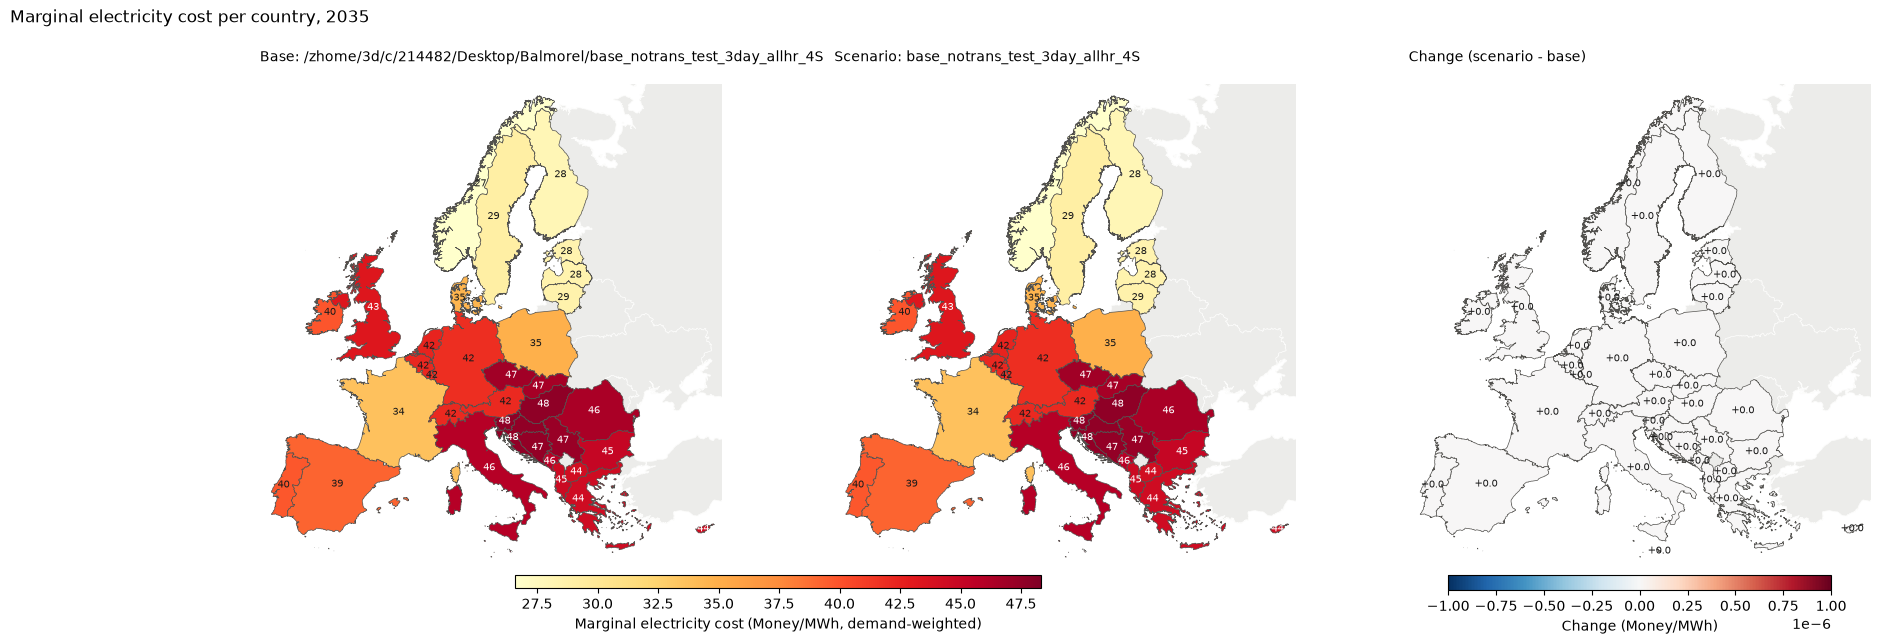

In [59]:
# 11.4.2 Marginal electricity cost per country: base, scenario and change (Money/MWh, demand-weighted), three maps
from matplotlib.colors import Normalize, TwoSlopeNorm

region_country_px = scenario_result(res, SCENARIO, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
geo_px = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
geo_px["Country"] = geo_px["id"].map(region_country_px)
country_px = geo_px.dropna(subset=["Country"]).dissolve(by="Country").join(price_country)
mainland = lambda g: max(getattr(g, "geoms", [g]), key=lambda p: p.area)

level_norm = Normalize(vmin=price_country[[BASE_SCENARIO, SCENARIO]].min().min(), vmax=price_country[[BASE_SCENARIO, SCENARIO]].max().max())
lim = max(price_country["Change"].abs().max(), 1e-6)
change_norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
panels = [(BASE_SCENARIO, f"Base: {BASE_SCENARIO}", "YlOrRd", level_norm, "{:.0f}"),
          (SCENARIO, f"Scenario: {SCENARIO}", "YlOrRd", level_norm, "{:.0f}"),
          ("Change", "Change (scenario - base)", "RdBu_r", change_norm, "{:+.1f}")]

fig, axes = plt.subplots(1, 3, figsize=(21, 7.5))
minx, miny, maxx, maxy = country_px.geometry.apply(mainland).total_bounds
for ax, (col, title, cmap, norm, fmt_) in zip(axes, panels):
    geo_px[geo_px["Country"].isna()].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)     # outside the model
    country_px.plot(ax=ax, column=col, cmap=cmap, norm=norm, edgecolor="#52514e", linewidth=0.5)
    for name, row in country_px.iterrows():
        if pd.isna(row[col]):
            continue
        p = mainland(row.geometry).representative_point()
        dark = (norm(row[col]) > 0.75) if col != "Change" else abs(row[col]) > 0.6 * lim
        ax.annotate(fmt_.format(row[col]), (p.x, p.y), ha="center", va="center", fontsize=7, color="white" if dark else "#1a1a1a")
    ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
    ax.set_axis_off()
    ax.set_title(title, loc="left", fontsize=10)
fig.colorbar(plt.cm.ScalarMappable(cmap="YlOrRd", norm=level_norm), ax=axes[:2], orientation="horizontal", shrink=0.5, pad=0.02, aspect=40,
             label="Marginal electricity cost (Money/MWh, demand-weighted)")
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=change_norm), ax=axes[2], orientation="horizontal", shrink=0.8, pad=0.02, aspect=25,
             label="Change (Money/MWh)")
fig.suptitle(f"Marginal electricity cost per country, {PRICE_MAP_YEAR}", x=0.01, ha="left")
plt.show()


#### 11.4.3 Where does the change in marginal electricity cost come from? (2035)
The country change in 11.4.1 is $\Delta P_c = \sum_r w_r^{S} P_r^{S} - \sum_r w_r^{B} P_r^{B}$, where $P_r$ is the time-averaged hourly marginal cost of region $r$ and $w_r$ its share of the country's annual electricity demand. It is split exactly into
- **Hours priced with neighbours**: $\sum_r w_r^{B}\,\overline{\Delta p_{rt}}$ over the hours in which, in the scenario, region $r$ has (within `COUPLING_TOL`, to allow for transmission losses) the same price as a connected region in another country, i.e. the interconnector is not congested and the price is formed in a wider multi-country market;
- **Hours priced domestically**: the same term over the remaining hours, in which the borders are congested and the price is set by the country's own supply and demand;
- **Regional demand weights**: $\sum_r (w_r^{S} - w_r^{B}) P_r^{S}$, the shift of demand between the regions of a country.

The physical drivers next to it (scenario - base, annual) show what moved: demand and the part from data centres (`DE_DATACENTER.inc` of both runs), domestic generation, of which fuel-fired thermal (condensing and CHP, nuclear excluded), net imports from other countries and installed capacity.

In [60]:
# 11.4.3 Decomposition of the change in marginal electricity cost per country (2035) and its physical drivers
PRICE_DRIVER_YEAR = "2035" if "2035" in COMPARISON_YEARS else COMPARISON_YEARS[-1]
COUPLING_TOL = 0.05                  # relative price difference still counted as "same price" (transmission losses)
THERMAL_TECH = ["CONDENSING", "CHP-BACK-PRESSURE", "CHP-EXTRACTION"]   # fuel-fired plants, nuclear excluded below

def year_table(results, scenario, symbol):
    t = scenario_result(results, scenario, symbol)
    return t.loc[t["Year"].astype(str).eq(PRICE_DRIVER_YEAR)]

def region_weights(results, scenario):
    """Share of each region in its country's annual electricity demand (all categories), as in price_by."""
    d = year_table(results, scenario, "EL_DEMAND_YCR").groupby(["Country", "Region"])["Value"].sum()
    return d / d.groupby(level="Country").transform("sum").replace(0, np.nan)

def hourly_price(results, scenario):
    return year_table(results, scenario, "EL_PRICE_YCRST").set_index(["Region", "Season", "Time"])["Value"]

def coupled_hours(results, scenario, price):
    """True where a region has the same price (within COUPLING_TOL) as a connected region in another country."""
    region_country = year_table(results, scenario, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
    x = year_table(results, scenario, "X_CAP_YCR").groupby(["From", "To"])["Value"].sum()
    links = pd.DataFrame([(a, b) for (a, b), v in x.items() if v > 1e-6], columns=["Region", "Neighbour"])
    links = pd.concat([links, links.rename(columns={"Region": "Neighbour", "Neighbour": "Region"})]).drop_duplicates()
    links = links.loc[links["Region"].map(region_country).ne(links["Neighbour"].map(region_country))]
    p = price.rename("P").reset_index()
    pairs = links.merge(p, on="Region").merge(p.rename(columns={"Region": "Neighbour", "P": "PN"}), on=["Neighbour", "Season", "Time"])
    pairs["Same"] = (pairs["P"] - pairs["PN"]).abs() <= COUPLING_TOL * pairs[["P", "PN"]].abs().max(axis=1) + 0.01
    return pairs.groupby(["Region", "Season", "Time"])["Same"].any().reindex(price.index, fill_value=False)

def by_country(results, scenario, symbol, mask=None):
    t = year_table(results, scenario, symbol)
    return (t if mask is None else t.loc[mask(t)]).groupby("Country")["Value"].sum()

def net_imports(results, scenario):
    """Annual imports minus exports across the country's borders (TWh)."""
    rc = year_table(results, scenario, "EL_PRICE_YCR").drop_duplicates("Region").set_index("Region")["Country"]
    f = year_table(results, scenario, "X_FLOW_YCR").assign(CFrom=lambda d: d["From"].map(rc), CTo=lambda d: d["To"].map(rc))
    f = f.loc[f["CFrom"].ne(f["CTo"])]
    return f.groupby("CTo")["Value"].sum().sub(f.groupby("CFrom")["Value"].sum(), fill_value=0)

# --- Price decomposition (Money/MWh); the three parts add up to the change of 11.4.1 --------------------------------
p_base, p_scen = hourly_price(base_res, BASE_SCENARIO), hourly_price(res, SCENARIO)
dp = p_scen.sub(p_base, fill_value=0)
coupled = coupled_hours(res, SCENARIO, p_scen).reindex(dp.index, fill_value=False)
n_hours = dp.groupby(level="Region").size()
w_base, w_scen = region_weights(base_res, BASE_SCENARIO), region_weights(res, SCENARIO)
regions = w_base.index.union(w_scen.index)
w_base, w_scen = w_base.reindex(regions).fillna(0), w_scen.reindex(regions).fillna(0)
country_of = pd.Series(regions.get_level_values("Country"), index=regions.get_level_values("Region"))

def weighted(per_region):                       # sum over the regions of a country with the base demand weights
    v = per_region.reindex(regions.get_level_values("Region")).fillna(0).to_numpy()
    return pd.Series(w_base.to_numpy() * v, index=regions).groupby(level="Country").sum()

mean_dp_coupled = dp.where(coupled, 0).groupby(level="Region").sum() / n_hours
mean_dp_domestic = dp.where(~coupled, 0).groupby(level="Region").sum() / n_hours
P_scen = p_scen.groupby(level="Region").mean()
shift = pd.Series((w_scen - w_base).to_numpy() * P_scen.reindex(regions.get_level_values("Region")).fillna(0).to_numpy(),
                  index=regions).groupby(level="Country").sum()
share_coupled = lambda c: pd.Series(c.to_numpy(), index=c.index).groupby(country_of.reindex(c.index.get_level_values("Region")).to_numpy()).mean() * 100

reference = pd.DataFrame({"Base": price_by(base_res, BASE_SCENARIO, "Country").xs(PRICE_DRIVER_YEAR, level="Year"),
                          "Scenario": price_by(res, SCENARIO, "Country").xs(PRICE_DRIVER_YEAR, level="Year")})
price_part = pd.DataFrame({
    "Base": reference["Base"],
    "Scenario": reference["Scenario"],
    "Change": reference["Scenario"] - reference["Base"],
    "Hours priced with neighbours": weighted(mean_dp_coupled),
    "Hours priced domestically": weighted(mean_dp_domestic),
    "Regional demand weights": shift,
    "Hours priced with neighbours (% base)": share_coupled(coupled_hours(base_res, BASE_SCENARIO, p_base)),
    "Hours priced with neighbours (% scen.)": share_coupled(coupled),
})
residual = price_part["Change"] - price_part[["Hours priced with neighbours", "Hours priced domestically", "Regional demand weights"]].sum(axis=1)
if residual.abs().max() > 1e-6:
    print(f"Warning: decomposition does not close, largest residual {residual.abs().max():.3g} Money/MWh")

# --- Physical drivers (scenario - base, TWh or GW) ----------------------------------------------------------------
region_country = country_of[~country_of.index.duplicated()]
thermal = lambda t: t["Commodity"].eq("ELECTRICITY") & t["Technology"].isin(THERMAL_TECH) & t["Fuel"].ne("NUCLEAR")
electricity = lambda t: t["Commodity"].eq("ELECTRICITY")
diff = lambda f: f(res, SCENARIO).sub(f(base_res, BASE_SCENARIO), fill_value=0)
drivers = pd.DataFrame({
    "Demand (TWh)": diff(lambda r, s: by_country(r, s, "EL_DEMAND_YCR")),
    "of which data centres (TWh)": datacenter_demand(SCENARIO_DIR, PRICE_DRIVER_YEAR, region_country).sub(datacenter_demand(BASE_DIR, PRICE_DRIVER_YEAR, region_country), fill_value=0),
    "Domestic generation (TWh)": diff(lambda r, s: by_country(r, s, "PRO_YCRAGF", electricity)),
    "of which fuel-fired thermal (TWh)": diff(lambda r, s: by_country(r, s, "PRO_YCRAGF", thermal)),
    "Net imports (TWh)": diff(net_imports),
    "Installed capacity (GW)": diff(lambda r, s: by_country(r, s, "G_CAP_YCRAF", electricity)),
})

price_drivers = pd.concat({f"Marginal cost (Money/MWh), {PRICE_DRIVER_YEAR}": price_part,
                           "Drivers (scenario - base)": drivers.reindex(price_part.index).fillna(0)}, axis=1)
price_drivers = price_drivers.sort_values((f"Marginal cost (Money/MWh), {PRICE_DRIVER_YEAR}", "Change"), ascending=False)
price_drivers.index = [clean_name(c) for c in price_drivers.index]
print(f"{SCENARIO} minus {BASE_SCENARIO}, {PRICE_DRIVER_YEAR}. Change = hours priced with neighbours + hours priced domestically + regional demand weights")
display(price_drivers.round(2))


base_notrans_test_3day_allhr_4S minus /zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S, 2035. Change = hours priced with neighbours + hours priced domestically + regional demand weights


Marginal cost (Money/MWh), 2035                  \
                                                  Base Scenario Change   
Albania                                          44.52    44.52    0.0   
Austria                                          42.06    42.06    0.0   
Belgium                                          42.19    42.19    0.0   
Bosnia And Herzegovina                           47.41    47.41    0.0   
Bulgaria                                         44.95    44.95    0.0   
Croatia                                          47.51    47.51    0.0   
Cyprus                                           44.26    44.26    0.0   
Czech Republic                                   46.85    46.85    0.0   
Denmark                                          34.53    34.53    0.0   
Estonia                                          28.40    28.40    0.0   
Finland                                          28.01    28.01    0.0   
France                                           33.65    33.65    0.0   
Germany                                          41.87    41.87    0.0   
Greece                                           44.41    44.41    0.0   
Hungary                                          47.64    47.64    0.0   
Ireland                                          39.86    39.86    0.0   
Italy                                            45.88    45.88    0.0   
Latvia                                           28.46    28.46    0.0   
Lithuania                                        28.54    28.54    0.0   
Luxembourg                                       41.71    41.71    0.0   
Malta                                            48.34    48.34    0.0   
Montenegro                                       45.78    45.78    0.0   
Netherlands                                      42.43    42.43    0.0   
North Macedonia                                  44.14    44.14    0.0   
Norway                                           26.58    26.58    0.0   
Poland                                           34.83    34.83    0.0   
Portugal                                         39.83    39.83    0.0   
Romania                                          46.44    46.44    0.0   
Serbia                                           47.19    47.19    0.0   
Slovakia                                         46.58    46.58    0.0   
Slovenia                                         47.62    47.62    0.0   
Spain                                            39.24    39.24    0.0   
Sweden                                           29.05    29.05    0.0   
Switzerland                                      42.11    42.11    0.0   
United Kingdom                                   43.25    43.25    0.0   

                                                                               \
                       Hours priced with neighbours Hours priced domestically   
Albania                                         0.0                       0.0   
Austria                                         0.0                       0.0   
Belgium                                         0.0                       0.0   
Bosnia And Herzegovina                          0.0                       0.0   
Bulgaria                                        0.0                       0.0   
Croatia                                         0.0                       0.0   
Cyprus                                          0.0                       0.0   
Czech Republic                                  0.0                       0.0   
Denmark                                         0.0                       0.0   
Estonia                                         0.0                       0.0   
Finland                                         0.0                       0.0   
France                                          0.0                       0.0   
Germany                                         0.0                       0.0   
Greece                                          0.0                  

## 12. Bottleneck screening with the shadow prices of the full model
Which constraints make the scenario more expensive? Balmorel writes the complete model, with the shadow price (dual) of every equation and variable bound, to `all_endofmodel.gdx`. A binding constraint with a non-zero shadow price is a bottleneck: its shadow price is the reduction in system cost that one more unit of the limit would give. This section compares these shadow prices between the scenario and the base in `BOTTLENECK_YEAR`.

**Units.** The model is solved for all years at once with the years weighted in the objective, so each dual is converted to annual money with `OMONEY / (IDISCOUNTFACTOR(Y) * IWEIGHTY(Y))`, the conversion Balmorel uses for `EL_PRICE_YCRST` (which in addition divides by `IHOURSINST` to obtain Money/MWh). Step 0 checks that the converted electricity-balance dual reproduces `EL_PRICE_YCRST`.

**Scarcity rent** (Mmoney/yr) is the shadow price times the quantity that the constraint limits, so that constraints of different kinds can be compared:
1. **Screening of all equation families**: number of binding rows, and the rent on the right-hand side (shadow price x the exogenous limit, e.g. a potential or an existing capacity). Families whose limit is endogenous have no right-hand-side rent and are covered by the detailed tables.
2. **Investment potentials** (`QKSUBTECHGROUPR`, `QKTECHGROUPR`): value of one more MW of potential (Money/MW/yr) x potential, per region, technology group and resource grade.
3. **Fuel use limits** (`QGMAXCF`, `QGMAXRFS`): value of one more GJ x limit, per country and fuel.
4. **Cross-border congestion**: dual of the fixed transmission capacity (bound on `VX_T`) x flow, checked against the price spreads between the regions.
5. **Generation capacity** (`QGKE_UP`): dual of the capacity constraint x electricity output in the slices where it binds, per technology and fuel.
6. **Totals** per category and per technology group, and 7. a **ranking** of the largest changes.

These rents are a screening, not an exact decomposition of the cost change: shadow prices are marginal values (valid for small changes of a limit), and they need not be unique when the LP is degenerate. The candidates found here should be confirmed with relaxation runs (step 3 of the proposed methodology). Reading the two GDX files takes about a minute and some 2 GB of memory.

Unit check /zhome/3d/c/214482/Desktop/Balmorel/base_notrans_test_3day_allhr_4S: largest difference to EL_PRICE_YCRST 1.34e+02 Money/MWh
Unit check base_notrans_test_3day_allhr_4S: largest difference to EL_PRICE_YCRST 1.34e+02 Money/MWh
1. Equation families with binding rows in 2035, largest change in RHS rent first


Description  \
                                                                            
Equation                                                                    
QEEQ                            Electricity generation equals demand (MW)   
QHEQ                                   Heat generation equals demand (MW)   
QGFEQ                                     Calculate fuel consumption (MW)   
QGCBGBPR                CHP generation (back pressure) limited by Cb-l...   
QGCBGBPRBYPASS1         CHP generation (back pressure) with bypass lim...   
QGCBGBPRBYPASS2         CHP generation (back pressure) with bypass lim...   
QGCBGEXT                CHP generation (extraction) limited by Cb-line...   
QGCVGEXT                CHP generation (extraction) limited by Cv-line...   
QGCVGEXTBYPASS1         CHP generation (extraction) with bypass limite...   
QGFEQEXTBYPASS1         Lower bound 1 for fuel consumption of CHP extr...   
QGFEQEXTBYPASS2         Lower bound 2 for fuel consumption of CHP extr...   
QGGETOH                                     Electric heat generation (MW)   
QHYRSSEQ                Hydropower with reservoir seasonal energy cons...   
QHYRSMINVOL                    Hydropower reservoir - minimum level (MWh)   
QHYRSMAXVOL                    Hydropower reservoir - maximum level (MWh)   
QHYMAXG                 Regulated plus unregulated hydropower producti...   
QESTOVOLT               Intra-seasonal electricty storage dynamic equa...   
QHSTOVOLT               Intra-seasonal heat storage dynamic equation (...   
QHSTOVOLTS              Inter-seasonal heat storage dynamic equation (...   
QHSTOLOADTLIM           Intra-seasonal Upper limit to heat storage loa...   
QESTOLOADTLIM           Intra-seasonal Upper limit to electricity stor...   
QHSTOVOLTLIM             Intra-seasonal Heat storage capacity limit (MWh)   
QESTOVOLTLIM            Intra-seasonal Electricity storage capacity li...   
QHSTOVGHTLIM                Intra-seasonal Heat storage output limit (MW)   
QESTOVGETLIM            Intra-seasonal Electricity storage output limi...   
QHSTOLOADTLIMS          Inter-seasonal Upper limit to heat storage loa...   
QHSTOVOLTLIMS            Inter-seasonal Heat storage capacity limit (MWh)   
QHSTOVGHTLIMS               Inter-seasonal Heat storage output limit (MW)   
QKTECHGROUPR            Maximum capacity by year, region and technolog...   
QKSUBTECHGROUPR         Maximum capacity by year, region and subtechno...   
QGMAXCF                   Maximum fuel use by year, country and fuel (GJ)   
QGMAXRFS                Maximum fuel use by year, season, region and f...   
QGKNACCUMNET            Accumulated new investments minus decommission...   
QGKE_UP                 Capacity constraint on electricity generation ...   
QGKH_UP                       Capacity constraint on heat generation (MW)   
QWNDDISPATCH                        Wind power can not be dispatched (MW)   
QSOLEDISPATCH           Solar electricity generation can not be dispat...   
QSOLHDISPATCH            Solar heat generation can not be dispatched (MW)   
QTRANSPEAKDEMAND                                         Peak demand (MW)   
QTRANSDEMAND_YR         Annual transport demand has to be met in each ...   
QTRANSPEAKDEMANDLIMIT                             Peak demand limited(MW)   
QHYDROGEN_HGETOHH2      Link heat and electricity demand in hydrogen p...   
QHYDROGEN_GCH4KT_UP     Hydrogen production of steam reforming plants ...   
QHYDROGEN_STOVOL                        Dynamic equation hydrogen storage   
QHYDROGEN_STOMAXCON                     Maximum hydrogen storage capacity   
QHYDROGEN_STOMAXLOAD         Maximum loading capacity of hydrogen storage   
QHYDROGEN_STOMAXUNLD       Maximum unloading capacity of hydrogen storage   
QHYDROGEN_EQ                             Hydrogen production equal demand   
QXH2K_UP                         H2 transmission capacity constraint (MW)   
QXH2KNACCUMNET          NOT FINISHED, TODO, Accumulated ne

2. Investment potentials that bind (QKSUBTECHGROUPR, QKTECHGROUPR): rent = value of one more MW x potential, Mmoney/yr, 2035


Base  Scenario  Change  \
Region Technology group    Resource grade                             
AL     SOLARPV             RG2                0.3       0.3     0.0   
       WINDTURBINE_ONSHORE RG1                5.2       5.2     0.0   
                           RG2               15.7      15.7     0.0   
AT     SOLARPV             RG1               16.4      16.4     0.0   
       WINDTURBINE_ONSHORE RG1                3.7       3.7     0.0   
                           RG2             1786.8    1786.8     0.0   
BA     SOLARPV             RG1                5.4       5.4     0.0   
                           RG2                2.3       2.3     0.0   
                           RG3                1.2       1.2     0.0   
       WINDTURBINE_ONSHORE RG1                4.7       4.7     0.0   
                           RG2               82.7      82.7     0.0   
BE     WINDTURBINE_ONSHORE RG2              248.6     248.6     0.0   
                           RG3              555.8     555.8     0.0   
BG     SOLARPV             RG2               16.5      16.5     0.0   
                           RG3              190.4     190.4     0.0   

                                           Value per MW, base (Money/MW/yr)  \
Region Technology group    Resource grade                                     
AL     SOLARPV             RG2                                        797.7   
       WINDTURBINE_ONSHORE RG1                                      87408.6   
                           RG2                                      65514.8   
AT     SOLARPV             RG1                                       8421.8   
       WINDTURBINE_ONSHORE RG1                                      57056.9   
                           RG2                                     108951.1   
BA     SOLARPV             RG1                                      32024.0   
                           RG2                                       2916.9   
                           RG3                                       1236.7   
       WINDTURBINE_ONSHORE RG1                                      85289.4   
                           RG2                                     103402.2   
BE     WINDTURBINE_ONSHORE RG2                                     136388.6   
                           RG3                                     111167.1   
BG     SOLARPV             RG2                                      37147.3   
                           RG3                                      42315.5   

                                           Value per MW, scen. (Money/MW/yr)  \
Region Technology group    Resource grade                                      
AL     SOLARPV             RG2                                         797.7   
       WINDTURBINE_ONSHORE RG1                                       87408.6   
                           RG2                                       65514.8   
AT     SOLARPV             RG1                                        8421.8   
       WINDTURBINE_ONSHORE RG1                                       57056.9   
                           RG2                                      108951.1   
BA     SOLARPV             RG1                                       32024.0   
                           RG2                                        2916.9   
                           RG3                                        1236.7   
       WINDTURBINE_ONSHORE RG1                                       85289.4   
                           RG2                                      103402.2   
BE     WINDTURBINE_ONSHORE RG2                                      136388.6   
                           RG3                                      111167.1   
BG     SOLARPV             RG2                                       37147.3   
                           RG3                                       42315.5   

                                           Potential (MW)  
Region Technology group    Resource grade                  
AL     SOLAR

3. Fuel use limits that bind (QGMAXCF per country, QGMAXRFS per region and season, summed per country), Mmoney/yr, 2035


...

   Check base_notrans_test_3day_allhr_4S: congestion rent from duals 10,056 Mmoney/yr, from price spreads 11,616 Mmoney/yr (same order of magnitude; the duals exclude the part of the spread due to transmission losses and costs)
5. Scarcity rent of electricity generation capacity (QGKE_UP binding), per technology and fuel, Mmoney/yr, 2035


Base  Scenario  Change
Technology        Fuel                                  
?                 ?               29.7      29.7     0.0
CHP-BACK-PRESSURE BIOGAS           5.3       5.3     0.0
                  HEAT            13.8      13.8     0.0
                  MUNIWASTE      246.1     246.1     0.0
                  NATGAS        1481.0    1481.0     0.0
                  STRAW           23.2      23.2     0.0
                  WOODCHIPS     1231.4    1231.4     0.0
                  WOODPELLETS     13.0      13.0     0.0
                  WOODWASTE      133.3     133.3     0.0
CHP-EXTRACTION    WOOD             0.5       0.5     0.0
CONDENSING        BIOGAS          64.6      64.6     0.0
                  DUMMY           48.9      48.9     0.0
                  MUNIWASTE      340.5     340.5     0.0
                  NATGAS        1749.7    1749.7     0.0
                  NUCLEAR      15252.4   15252.4     0.0

6. Total scarcity rent per category and of the investment potentials per technology group, Mmoney/yr, 2035


,Base,Scenario,Change
Investment potentials,30266.7,30266.7,0.0
Fuel limits,3948.8,3948.8,0.0
Cross-border congestion,8640.1,8640.1,0.0
Generation capacity,21930.3,21930.3,0.0


,Base,Scenario,Change,"Binding regions/grades, base","Binding regions/grades, scen."
Technology group,,,,,
SOLARPV,1470.7,1470.7,0.0,45,45
WINDTURBINE_ONSHORE,28796.0,28796.0,0.0,105,105


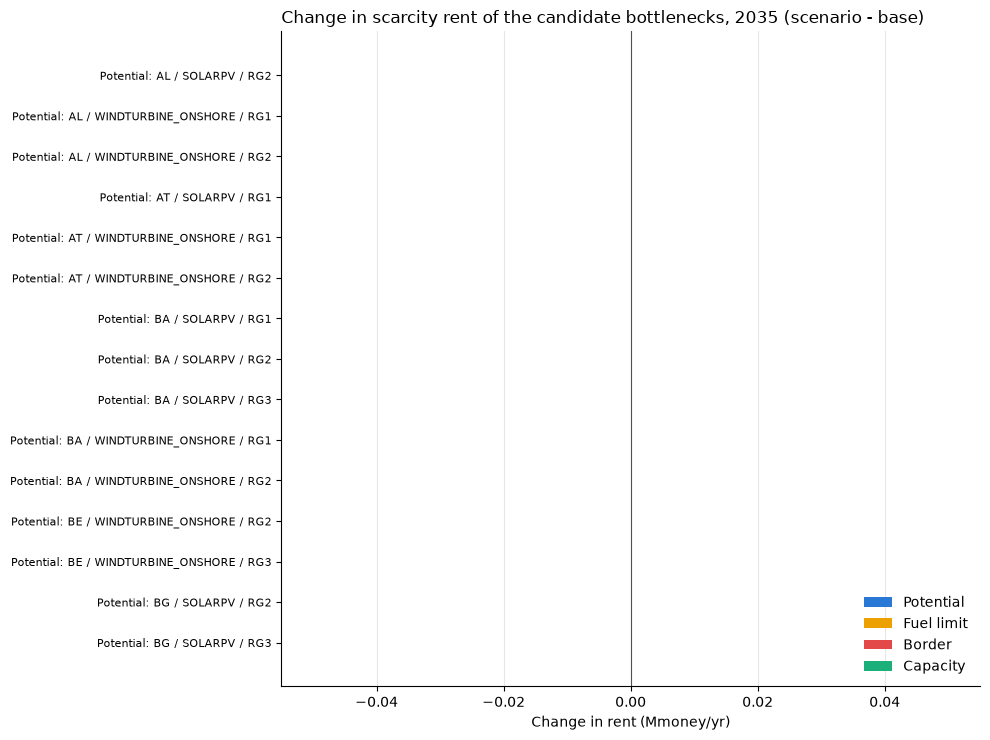

In [61]:
# 12.0 Bottleneck screening: shadow prices of the full model (all_endofmodel.gdx), scenario vs base
import gams.transfer as gt
from matplotlib.patches import Patch

BOTTLENECK_YEAR = "2035" if "2035" in COMPARISON_YEARS else COMPARISON_YEARS[-1]
ENDOFMODEL = "all_endofmodel.gdx"     # written by Balmorel next to MainResults.gdx
TOP_N = 15                            # rows shown in the detailed tables and in the ranking

def load_endofmodel(run_dir, year):
    """Shadow prices of one run for `year`, converted to annual money: marginal * OMONEY / (IDISCOUNTFACTOR * IWEIGHTY),
    the same conversion Balmorel uses for EL_PRICE_YCRST (which additionally divides by IHOURSINST to get Money/MWh).
    Returns the screening of all equation families and the records needed for the detailed tables."""
    c = gt.Container(str(run_dir / ENDOFMODEL))
    scalar = lambda n: float(c[n].records["value"].iloc[0])
    by_y = lambda n: c[n].records.assign(Y=lambda d: d["Y"].astype(str)).set_index("Y")["value"]
    conv = scalar("OMONEY") / (by_y("IDISCOUNTFACTOR")[year] * by_y("IWEIGHTY")[year])
    hours = c["IHOURSINST"].records.astype({"SSS": str, "TTT": str}).set_index(["SSS", "TTT"])["value"]

    def records(name, kind="marginal"):
        r = c[name].records
        r = r.loc[r["Y"].astype(str).eq(year)].copy()
        for col in r.columns[:len(c[name].domain_names)]:
            r[col] = r[col].astype(str)
        r["value"] = r["marginal"] * conv                         # annual money per unit of the constraint
        return r

    # Screening of every equation family that has a year index
    rows = []
    for s in c.data.values():
        if not isinstance(s, gt.Equation) or s.records is None or "Y" not in s.domain_names or s.name == "QOBJ":
            continue
        r = s.records.loc[s.records["Y"].astype(str).eq(year)]
        if r.empty:
            continue
        m = r["marginal"].to_numpy() * conv
        b = (r["lower"] if s.type == "geq" else r["upper"]).to_numpy()
        rhs = np.isfinite(b) & (np.abs(b) > 1e-9)
        rows.append({"Equation": s.name, "Description": (s.description or "")[:70], "Rows": len(r),
                     "Binding": int((np.abs(m) > 1e-9).sum()),
                     "RHS rent (Mmoney)": np.abs(m[rhs] * b[rhs]).sum() / 1e6})
    screen = pd.DataFrame(rows).set_index("Equation")

    out = {"screen": screen, "conv": conv, "hours": hours}
    out["QEEQ"] = records("QEEQ")
    for n in ["QKSUBTECHGROUPR", "QKTECHGROUPR", "QGMAXCF", "QGMAXRFS", "QGKE_UP", "QWNDDISPATCH", "QSOLEDISPATCH", "QESTOVGETLIM"]:
        out[n] = records(n)
    out["VX_T"] = records("VX_T")
    vge = c["VGE_T"].records
    vge = vge.loc[vge["Y"].astype(str).eq(year)]
    out["VGE_T"] = vge.astype({col: str for col in ["Y", "AAA", "G", "SSS", "TTT"] if col in vge}).rename(columns={"SSS": "S", "TTT": "T"})
    del c
    return out

duals = {BASE_SCENARIO: load_endofmodel(BASE_RESULTS_DIR, BOTTLENECK_YEAR), SCENARIO: load_endofmodel(RUN_DIR, BOTTLENECK_YEAR)}

# --- 0. Unit check: the converted electricity-balance dual must reproduce EL_PRICE_YCRST ------------------------------
for scen, r in [(BASE_SCENARIO, base_res), (SCENARIO, res)]:
    q = duals[scen]["QEEQ"].rename(columns={"RRR": "Region", "S": "Season", "T": "Time"})
    q["Price"] = q["value"] / q.set_index(["Season", "Time"]).index.map(duals[scen]["hours"]).to_numpy()
    p = scenario_result(r, scen, "EL_PRICE_YCRST").assign(Year=lambda d: d["Year"].astype(str))
    p = p.loc[p["Year"].eq(BOTTLENECK_YEAR)].set_index(["Region", "Season", "Time"])["Value"]
    err = (q.set_index(["Region", "Season", "Time"])["Price"] - p).abs().max()
    print(f"Unit check {scen}: largest difference to EL_PRICE_YCRST {err:.2e} Money/MWh")

# --- 1. Screening of all equation families ------------------------------------------------------------------------
sb, ss = duals[BASE_SCENARIO]["screen"], duals[SCENARIO]["screen"]
screen = pd.concat({"Binding rows": pd.DataFrame({"Base": sb["Binding"], "Scenario": ss["Binding"]}),
                    "RHS rent (Mmoney/yr)": pd.DataFrame({"Base": sb["RHS rent (Mmoney)"], "Scenario": ss["RHS rent (Mmoney)"]})}, axis=1).fillna(0)
screen[("Binding rows", "Change")] = screen[("Binding rows", "Scenario")] - screen[("Binding rows", "Base")]
screen[("RHS rent (Mmoney/yr)", "Change")] = screen[("RHS rent (Mmoney/yr)", "Scenario")] - screen[("RHS rent (Mmoney/yr)", "Base")]
screen = screen.reindex(columns=[(a, b) for a in ("Binding rows", "RHS rent (Mmoney/yr)") for b in ("Base", "Scenario", "Change")])
screen.insert(0, "Description", ss["Description"].reindex(screen.index).fillna(sb["Description"]))
screen = screen.loc[screen[[("Binding rows", "Base"), ("Binding rows", "Scenario")]].max(axis=1) > 0]
screen = screen.reindex(screen[("RHS rent (Mmoney/yr)", "Change")].abs().sort_values(ascending=False).index)
print(f"1. Equation families with binding rows in {BOTTLENECK_YEAR}, largest change in RHS rent first")
display(screen.round(1))

# --- Maps from the results: area -> country, generator -> technology and fuel, region -> country -------------------
gmap = pd.concat([scenario_result(r, s, "G_CAP_YCRAF")[["Country", "Area", "Generation", "Technology", "Fuel"]]
                  for r, s in [(base_res, BASE_SCENARIO), (res, SCENARIO)]]).drop_duplicates(["Area", "Generation"])
area_country = gmap.drop_duplicates("Area").set_index("Area")["Country"]
region_country = pd.concat([scenario_result(r, s, "EL_PRICE_YCR") for r, s in [(base_res, BASE_SCENARIO), (res, SCENARIO)]]) \
                   .drop_duplicates("Region").set_index("Region")["Country"]

def compare(f, keys):
    """Base and scenario rent (Mmoney/yr) of a detailed family, with the change, largest change first."""
    t = pd.DataFrame({"Base": f(duals[BASE_SCENARIO]), "Scenario": f(duals[SCENARIO])}).fillna(0)
    t["Change"] = t["Scenario"] - t["Base"]
    t = t.loc[t[["Base", "Scenario"]].abs().max(axis=1) > 1e-3]
    t.index.names = keys
    return t.reindex(t["Change"].abs().sort_values(ascending=False).index)

# --- 2. Investment potentials (Mmoney/yr = value of one more MW x potential) ---------------------------------------
def potential_rent(d):
    parts = []
    for n, keys in [("QKSUBTECHGROUPR", ["RRR", "TECH_GROUP", "SUBTECH_GROUP"]), ("QKTECHGROUPR", ["RRR", "TECH_GROUP"])]:
        r = d[n].copy()
        if "SUBTECH_GROUP" not in r:
            r["SUBTECH_GROUP"] = "(all)"
        r["Rent"] = (-r["value"]).clip(lower=0) * r["upper"] / 1e6
        parts.append(r.groupby(["RRR", "TECH_GROUP", "SUBTECH_GROUP"])["Rent"].sum())
    return pd.concat(parts)
potentials = compare(potential_rent, ["Region", "Technology group", "Resource grade"])
def potential_value(d):
    r = d["QKSUBTECHGROUPR"]
    return r.set_index(["RRR", "TECH_GROUP", "SUBTECH_GROUP"])["value"].mul(-1)
pv = pd.DataFrame({"Value per MW, base (Money/MW/yr)": potential_value(duals[BASE_SCENARIO]),
                   "Value per MW, scen. (Money/MW/yr)": potential_value(duals[SCENARIO]),
                   "Potential (MW)": duals[SCENARIO]["QKSUBTECHGROUPR"].set_index(["RRR", "TECH_GROUP", "SUBTECH_GROUP"])["upper"]})
pv.index.names = potentials.index.names
print(f"2. Investment potentials that bind (QKSUBTECHGROUPR, QKTECHGROUPR): rent = value of one more MW x potential, Mmoney/yr, {BOTTLENECK_YEAR}")
display(potentials.join(pv).head(TOP_N).round(1))

# --- 3. Fuel and resource limits (Mmoney/yr = value of one more GJ x limit) -----------------------------------------
def fuel_rent(d):
    a = d["QGMAXCF"].assign(Rent=lambda r: (-r["value"]).clip(lower=0) * r["upper"] / 1e6).groupby(["C", "FFF"])["Rent"].sum()
    b = d["QGMAXRFS"].assign(C=lambda r: r["RRR"].map(region_country),
                             Rent=lambda r: (-r["value"]).clip(lower=0) * r["upper"] / 1e6).groupby(["C", "FFF"])["Rent"].sum()
    return a.add(b, fill_value=0)
fuels = compare(fuel_rent, ["Country", "Fuel"])
print(f"3. Fuel use limits that bind (QGMAXCF per country, QGMAXRFS per region and season, summed per country), Mmoney/yr, {BOTTLENECK_YEAR}")
display(fuels.head(TOP_N).round(1))

# --- 4. Transmission congestion (fixed line capacities: bound on VX_T), Mmoney/yr -------------------------------------
def congestion_rent(d, by_country=True):
    x = d["VX_T"].copy()
    x["Rent"] = x["value"].abs() * x["level"] / 1e6               # value of one more MW in the slice x flow (MW)
    if by_country:
        x["From"], x["To"] = x["IRRRE"].map(region_country), x["IRRRI"].map(region_country)
        x = x.loc[x["From"].ne(x["To"])]
    else:
        x["From"], x["To"] = x["IRRRE"], x["IRRRI"]
    pair = [tuple(sorted(p)) for p in zip(x["From"], x["To"])]
    return x.assign(Pair=[f"{a} - {b}" for a, b in pair]).groupby("Pair")["Rent"].sum()
lines = compare(congestion_rent, ["Border"])
hours_congested = lambda d: (d["VX_T"].assign(B=lambda r: r["value"].abs() > 1e-9)
                             .assign(Pair=lambda r: [" - ".join(sorted((region_country.get(a, a), region_country.get(b, b)))) for a, b in zip(r["IRRRE"], r["IRRRI"])])
                             .groupby("Pair")["B"].mean() * 100)
lines = lines.join(pd.DataFrame({"Congested slices, base (%)": hours_congested(duals[BASE_SCENARIO]),
                                 "Congested slices, scen. (%)": hours_congested(duals[SCENARIO])}))
print(f"4. Congestion rent on cross-border lines (|dual of the capacity bound| x flow, both directions), Mmoney/yr, {BOTTLENECK_YEAR}")
display(lines.head(TOP_N).round(1))

# Check of 4 against prices: congestion rent should be close to sum |price difference| x flow x hours (losses aside)
d = duals[SCENARIO]
p = d["QEEQ"].assign(P=lambda r: r["value"] / r.set_index(["S", "T"]).index.map(d["hours"]).to_numpy()).set_index(["RRR", "S", "T"])["P"]
x = d["VX_T"]
spread = (x.set_index(["IRRRI", "S", "T"]).index.map(p).to_numpy() - x.set_index(["IRRRE", "S", "T"]).index.map(p).to_numpy())
from_prices = np.nansum(np.abs(spread) * x["level"].to_numpy() * x.set_index(["S", "T"]).index.map(d["hours"]).to_numpy()) / 1e6
print(f"   Check {SCENARIO}: congestion rent from duals {x['value'].abs().mul(x['level']).sum() / 1e6:,.0f} Mmoney/yr, "
      f"from price spreads {from_prices:,.0f} Mmoney/yr (same order of magnitude; the duals exclude the part of the spread due to transmission losses and costs)")

# --- 5. Generation capacity scarcity (QGKE_UP: dual x electricity output in the binding slices), Mmoney/yr -----------
def capacity_rent(d):
    q = d["QGKE_UP"].loc[lambda r: r["value"].abs() > 1e-9, ["AAA", "G", "S", "T", "value"]]
    v = d["VGE_T"][["AAA", "G", "S", "T", "level"]]
    q = q.merge(v, on=["AAA", "G", "S", "T"], how="left")
    q["Rent"] = q["value"].abs() * q["level"].fillna(0) / 1e6
    q = q.merge(gmap[["Area", "Generation", "Technology", "Fuel"]], left_on=["AAA", "G"], right_on=["Area", "Generation"], how="left")
    return q.groupby([q["Technology"].fillna("?"), q["Fuel"].fillna("?")])["Rent"].sum()
capacity = compare(capacity_rent, ["Technology", "Fuel"])
print(f"5. Scarcity rent of electricity generation capacity (QGKE_UP binding), per technology and fuel, Mmoney/yr, {BOTTLENECK_YEAR}")
display(capacity.head(TOP_N).round(1))

# --- 6. Totals per category, and the potentials per technology group -------------------------------------------------
totals = pd.DataFrame({cat: t[["Base", "Scenario", "Change"]].sum() for cat, t in
                       [("Investment potentials", potentials), ("Fuel limits", fuels), ("Cross-border congestion", lines), ("Generation capacity", capacity)]}).T
pot_groups = potentials.groupby(level="Technology group")[["Base", "Scenario", "Change"]].sum().sort_values("Change", ascending=False)
pot_groups["Binding regions/grades, base"] = duals[BASE_SCENARIO]["QKSUBTECHGROUPR"].loc[lambda r: r["value"].abs() > 1e-9].groupby("TECH_GROUP").size()
pot_groups["Binding regions/grades, scen."] = duals[SCENARIO]["QKSUBTECHGROUPR"].loc[lambda r: r["value"].abs() > 1e-9].groupby("TECH_GROUP").size()
print(f"6. Total scarcity rent per category and of the investment potentials per technology group, Mmoney/yr, {BOTTLENECK_YEAR}")
display(totals.round(1))
display(pot_groups.fillna(0).round(1))

# --- 7. Ranking of the candidate bottlenecks ---------------------------------------------------------------------------
def fmt(t, cat):
    label = lambda i: " / ".join(clean_name(v) if cat == "Capacity" else str(v) for v in (i if isinstance(i, tuple) else (i,)))
    return pd.Series(t["Change"].to_numpy(), index=[f"{cat}: {label(i)}" for i in t.index])
ranking = pd.concat([fmt(potentials, "Potential"), fmt(fuels, "Fuel limit"), fmt(lines, "Border"), fmt(capacity, "Capacity")])
ranking = ranking.reindex(ranking.abs().sort_values(ascending=False).index).head(TOP_N)
cat_colors = {"Potential": "#2a78d6", "Fuel limit": "#eda100", "Border": "#e34948", "Capacity": "#1baf7a"}
fig, ax = plt.subplots(figsize=(10, 0.4 * len(ranking) + 1.5))
ax.barh(range(len(ranking))[::-1], ranking.values, color=[cat_colors[i.split(":")[0]] for i in ranking.index], height=0.7)
ax.set_yticks(range(len(ranking))[::-1]); ax.set_yticklabels(ranking.index, fontsize=8)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.legend(handles=[Patch(facecolor=c, label=k) for k, c in cat_colors.items()], frameon=False, loc="lower right")
ax.set_title(f"Change in scarcity rent of the candidate bottlenecks, {BOTTLENECK_YEAR} (scenario - base)", loc="left")
ax.set_xlabel("Change in rent (Mmoney/yr)")
ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()


### 12.1 Shadow price of the electricity generation capacity
The value of one more MW of installed electricity capacity for every generator, including wind, solar, hydro and storage, in `BOTTLENECK_YEAR` (kMoney/MW/yr, the annual system cost saving). For each generator and time slice it takes the dual of the constraint that ties the output to the capacity: `QGKE_UP` for dispatchable plants with investment or decommissioning options, `QWNDDISPATCH` and `QSOLEDISPATCH` for wind and solar, `QESTOVGETLIM` for electricity storage, and the upper or fixed bound of `VGE_T` for generators whose capacity is purely exogenous. In a slice where that constraint holds, output = capacity x availability (or x the wind/solar profile), so -dual x output / installed capacity, summed over the slices, is the saving from one more installed MW. For a dispatchable plant at full output this is the electricity price minus its variable cost, for wind and solar the market value of the energy one more MW would produce.

The values are averaged per technology and fuel weighted by installed capacity; the labels give the share of time slices in which the output is at its capacity limit (non-zero dual with positive output), and the table also gives the maximum over the generators. All generators share the same unit and can be compared directly; for technologies the model invests in, the value should be close to their annualised investment and fixed cost (zero profit at the optimum), and clearly above it where an investment potential binds. Hydro reservoirs are additionally limited by their water (`QHYRSSEQ`), which is not included here.

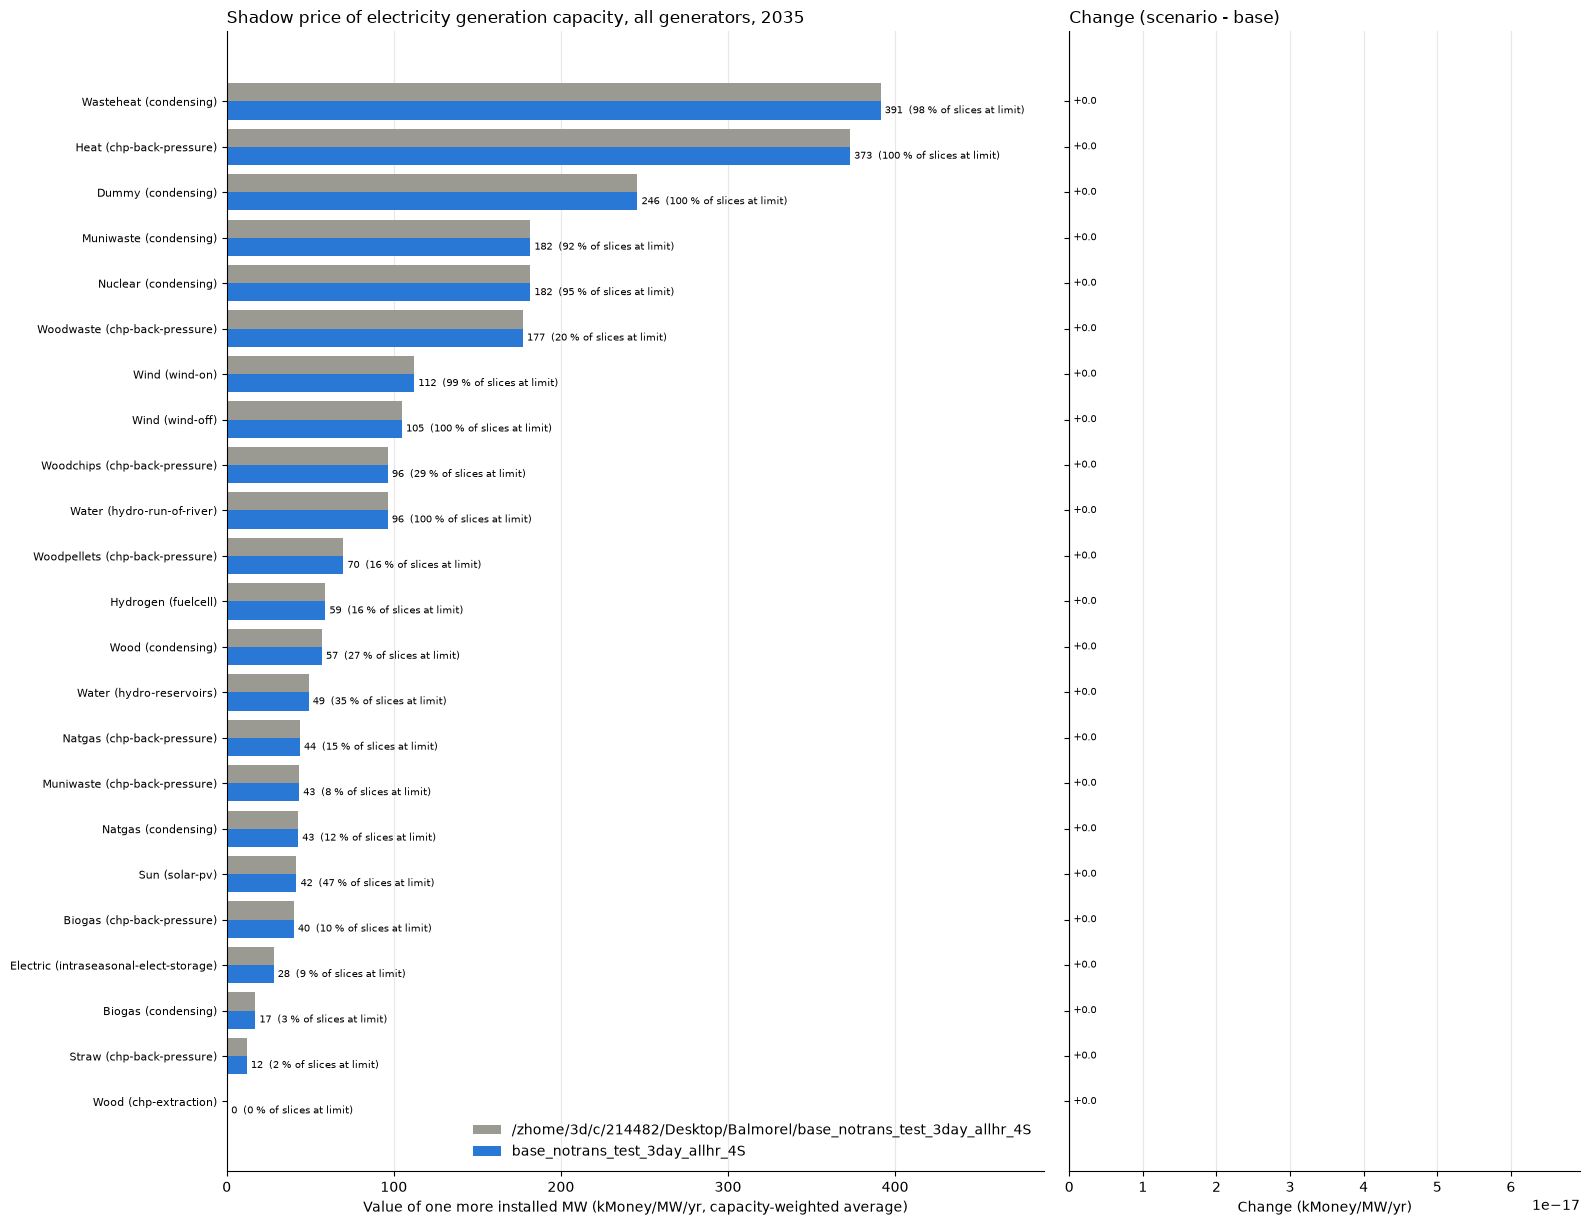

Value of one more MW of electricity generation capacity per technology and fuel (kMoney/MW/yr; capacity-weighted average and maximum over the generators), share of time slices in which the output is at its capacity limit, installed capacity, 2035


Base                     \
                                        Value    Max Binding (%)   
Wasteheat (condensing)                  391.3  391.7        97.7   
Heat (chp-back-pressure)                373.0  373.0       100.0   
Dummy (condensing)                      245.8  245.8       100.0   
Muniwaste (condensing)                  181.6  441.6        91.7   
Nuclear (condensing)                    181.6  284.6        95.0   
Woodwaste (chp-back-pressure)           177.2  533.3        20.2   
Wind (wind-on)                          112.2  243.7        99.3   
Wind (wind-off)                         104.8  135.6        99.9   
Woodchips (chp-back-pressure)            96.4  377.7        28.7   
Water (hydro-run-of-river)               96.3  143.2        99.6   
Woodpellets (chp-back-pressure)          69.8   69.8        16.3   
Hydrogen (fuelcell)                      59.0   59.0        15.6   
Wood (condensing)                        56.9   69.2        27.1   
Water (hydro-reservoirs)                 49.0  153.5        35.1   
Natgas (chp-back-pressure)               43.7  251.3        14.5   
Muniwaste (chp-back-pressure)            43.3  759.5         8.0   
Natgas (condensing)                      42.7  203.8        12.1   
Sun (solar-pv)                           41.7  109.1        46.5   
Biogas (chp-back-pressure)               40.1   40.1         9.7   
Electric (intraseasonal-elect-storage)   28.1   44.5         9.4   
Biogas (condensing)                      17.1   24.6         2.8   
Straw (chp-back-pressure)                12.0  115.2         2.0   
Wood (chp-extraction)                     0.2    0.2         0.3   

                                                     Scenario         \
                                       Capacity (GW)    Value    Max   
Wasteheat (condensing)                           0.5    391.3  391.7   
Heat (chp-back-pressure)                         0.0    373.0  373.0   
Dummy (condensing)                               0.2    245.8  245.8   
Muniwaste (condensing)                           1.8    181.6  441.6   
Nuclear (condensing)                            84.0    181.6  284.6   
Woodwaste (chp-back-pressure)                    0.8    177.2  533.3   
Wind (wind-on)                                 627.4    112.2  243.7   
Wind (wind-off)                                 44.2    104.8  135.6   
Woodchips (chp-back-pressure)                   12.7     96.4  377.7   
Water (hydro-run-of-river)                      73.5     96.3  143.2   
Woodpellets (chp-back-pressure)                  0.2     69.8   69.8   
Hydrogen (fuelcell)                              0.0     59.0   59.0   
Wood (condensing)                                1.3     56.9   69.2   
Water (hydro-reservoirs)                       102.7     49.0  153.5   
Natgas (chp-back-pressure)                      33.8     43.7  251.3   
Muniwaste (chp-back-pressure)                    4.7     43.3  759.5   
Natgas (condensing)                             41.0     42.7  203.8   
Sun (solar-pv)                                 546.1     41.7  109.1   
Biogas (chp-back-pressure)                       0.1     40.1   40.1   
Electric (intraseasonal-elect-storage)          19.5     28.1   44.5   
Biogas (condensing)                              3.8     17.1   24.6   
Straw (chp-back-pressure)                        1.9     12.0  115.2   
Wood (chp-extraction)                            3.1      0.2    0.2   

                                                                 Change  
                                       Binding (%) Capacity (GW)  Value  
Wasteheat (condensing)                        97.7           0.5    0.0  
Heat (chp-back-pressure)                     100.0           0.0    0.0  
Dummy (condensing)                           100.0           0.2    0.0  
Muniwaste (condensing)                        91.7           1.8    0.0  
Nuclear (condensing)                          95.0          84.0    0.0  
Woodwaste (chp-back-p

In [62]:
# 12.1 Shadow price of the electricity generation capacity of all generators: value of one more installed MW, base vs scenario
MIN_GEN_CAPACITY = 0.01              # GW; generators with less installed capacity are left out

OUTPUT_LIMITS = ["QGKE_UP", "QWNDDISPATCH", "QSOLEDISPATCH", "QESTOVGETLIM"]   # equations that tie a generator's output to its capacity

def generator_value(d, results, scenario):
    """Per generator: value of one more MW of installed electricity capacity (Money/MW/yr) = -sum over the time slices of
    (dual of the constraint that limits its output) x output / installed capacity. The limiting constraint is QGKE_UP for
    dispatchable plants, QWNDDISPATCH / QSOLEDISPATCH for wind and solar, QESTOVGETLIM for storage, and the bound on VGE_T
    for generators without investment or decommissioning options (their capacity enters as VGE_T.UP or VGE_T.FX).
    In a slice where the constraint holds, output = capacity x availability (or profile), so this is the dual times the
    capacity coefficient, i.e. the cost saving of one more MW. Also returns the share of slices in which the output is at its limit."""
    keys = ["AAA", "G", "S", "T"]
    v = d["VGE_T"][keys + ["level", "marginal"]].copy()
    v["Dual"] = v["marginal"] * d["conv"]                                  # bound on VGE_T, annual money
    for n in OUTPUT_LIMITS:
        q = d[n][keys + ["value"]].groupby(keys)["value"].sum().rename(n)
        v = v.join(q, on=keys)
        v["Dual"] += v[n].fillna(0)
    v["Saving"] = -v["Dual"] * v["level"]                                  # Money/yr per generator and slice
    v["B"] = (v["Dual"].abs() > 1e-9) & (v["level"] > 1e-6)              # output limited (a dual at zero output is a lower bound)
    g = v.groupby(["AAA", "G"]).agg(Saving=("Saving", "sum"), Binding=("B", "mean"))
    cap = scenario_result(results, scenario, "G_CAP_YCRAF")
    cap = cap.loc[cap["Year"].astype(str).eq(BOTTLENECK_YEAR) & cap["Commodity"].eq("ELECTRICITY")].groupby(["Area", "Generation"])["Value"].sum()
    cap.index.names = ["AAA", "G"]
    g = g.join(cap.rename("Capacity (GW)"), how="inner")
    g = g.loc[g["Capacity (GW)"] >= MIN_GEN_CAPACITY]
    g["Value"] = g["Saving"] / (g["Capacity (GW)"] * 1e3)                  # Money per installed MW per year
    g = g.reset_index()
    return g.merge(gmap[["Area", "Generation", "Technology", "Fuel", "Country"]], left_on=["AAA", "G"], right_on=["Area", "Generation"], how="left")

def by_tech(g):
    """Capacity-weighted average per technology and fuel (kMoney/MW/yr and % of slices binding), plus the maximum."""
    w = g["Capacity (GW)"]
    g = g.assign(VW=g["Value"] * w, BW=g["Binding"] * w)
    t = g.groupby(["Technology", "Fuel"]).agg(VW=("VW", "sum"), BW=("BW", "sum"), W=("Capacity (GW)", "sum"), Max=("Value", "max"))
    return pd.DataFrame({"Value": t["VW"] / t["W"] / 1e3, "Max": t["Max"] / 1e3, "Binding (%)": t["BW"] / t["W"] * 100, "Capacity (GW)": t["W"]})

gen_value = {s: generator_value(duals[s], r, s) for s, r in [(BASE_SCENARIO, base_res), (SCENARIO, res)]}
gen_tech = pd.concat({"Base": by_tech(gen_value[BASE_SCENARIO]), "Scenario": by_tech(gen_value[SCENARIO])}, axis=1)
gen_tech[("Change", "Value")] = gen_tech[("Scenario", "Value")].fillna(0) - gen_tech[("Base", "Value")].fillna(0)
gen_tech = gen_tech.loc[gen_tech[[("Base", "Value"), ("Scenario", "Value")]].abs().max(axis=1) > 0.05]
gen_tech = gen_tech.sort_values(("Scenario", "Value"))
labels = [f"{clean_name(f)} ({t.lower()})" for t, f in gen_tech.index]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 0.45 * len(gen_tech) + 2), sharey=True, gridspec_kw={"width_ratios": [1.6, 1]})
y = np.arange(len(gen_tech))
ax.barh(y + 0.2, gen_tech[("Base", "Value")].fillna(0), height=0.4, color="#9a9992", label=BASE_SCENARIO)
ax.barh(y - 0.2, gen_tech[("Scenario", "Value")].fillna(0), height=0.4, color="#2a78d6", label=SCENARIO)
for i, (v, b) in enumerate(zip(gen_tech[("Scenario", "Value")].fillna(0), gen_tech[("Scenario", "Binding (%)")].fillna(0))):
    ax.annotate(f"{v:,.0f}  ({b:.0f} % of slices at limit)", (v, i - 0.2), va="center", fontsize=7, xytext=(3, 0), textcoords="offset points")
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("Value of one more installed MW (kMoney/MW/yr, capacity-weighted average)")
ax.set_title(f"Shadow price of electricity generation capacity, all generators, {BOTTLENECK_YEAR}", loc="left")
ax.legend(frameon=False, loc="lower right")
ch = gen_tech[("Change", "Value")]
ax2.barh(y, ch, height=0.6, color=np.where(ch >= 0, "#e34948", "#1baf7a"))
for i, v in enumerate(ch):
    ax2.annotate(f"{v:+,.1f}", (v, i), va="center", ha="left" if v >= 0 else "right", fontsize=7, xytext=(3 if v >= 0 else -3, 0), textcoords="offset points")
ax2.axvline(0, color="#52514e", linewidth=0.8)
ax2.set_xlabel("Change (kMoney/MW/yr)"); ax2.set_title("Change (scenario - base)", loc="left")
for a in (ax, ax2):
    a.grid(axis="x", alpha=0.3); a.set_axisbelow(True)
    for side in ("top", "right"): a.spines[side].set_visible(False)
ax.margins(x=0.25); ax2.margins(x=0.25)
plt.tight_layout(); plt.show()

print(f"Value of one more MW of electricity generation capacity per technology and fuel (kMoney/MW/yr; capacity-weighted average "
      f"and maximum over the generators), share of time slices in which the output is at its capacity limit, installed capacity, {BOTTLENECK_YEAR}")
t = gen_tech.iloc[::-1].copy()
t.index = labels[::-1]
display(t.round(1))


### 12.2 Map of the binding investment potentials
Where the investment potential of `POTENTIAL_GROUP` (default: onshore wind) binds in `BOTTLENECK_YEAR`, from the shadow prices of `QKSUBTECHGROUPR` loaded in 12. 
- **Colour and label**: the value of one more MW of potential (kMoney/MW/yr, the annual system cost saving, on top of the cost of the turbine), averaged over the region's resource grades with non-binding grades counted as zero; in brackets the number of binding grades (non-zero shadow price). Both panels share the colour scale; the table also gives the value in the most valuable grade.
- **Light grey**: no grade of the region binds. **Black outline**: the region binds only in the scenario (all other coloured regions bind in both runs).

The average is not weighted by potential, because the right-hand side of `QKSUBTECHGROUPR` is the remaining potential (potential minus existing capacity): grades already filled by existing turbines have zero remaining potential but can have a high shadow price (e.g. Malta, Cyprus, Norway). For the same reason their scarcity rent in 12.0 (shadow price x remaining potential) is zero.

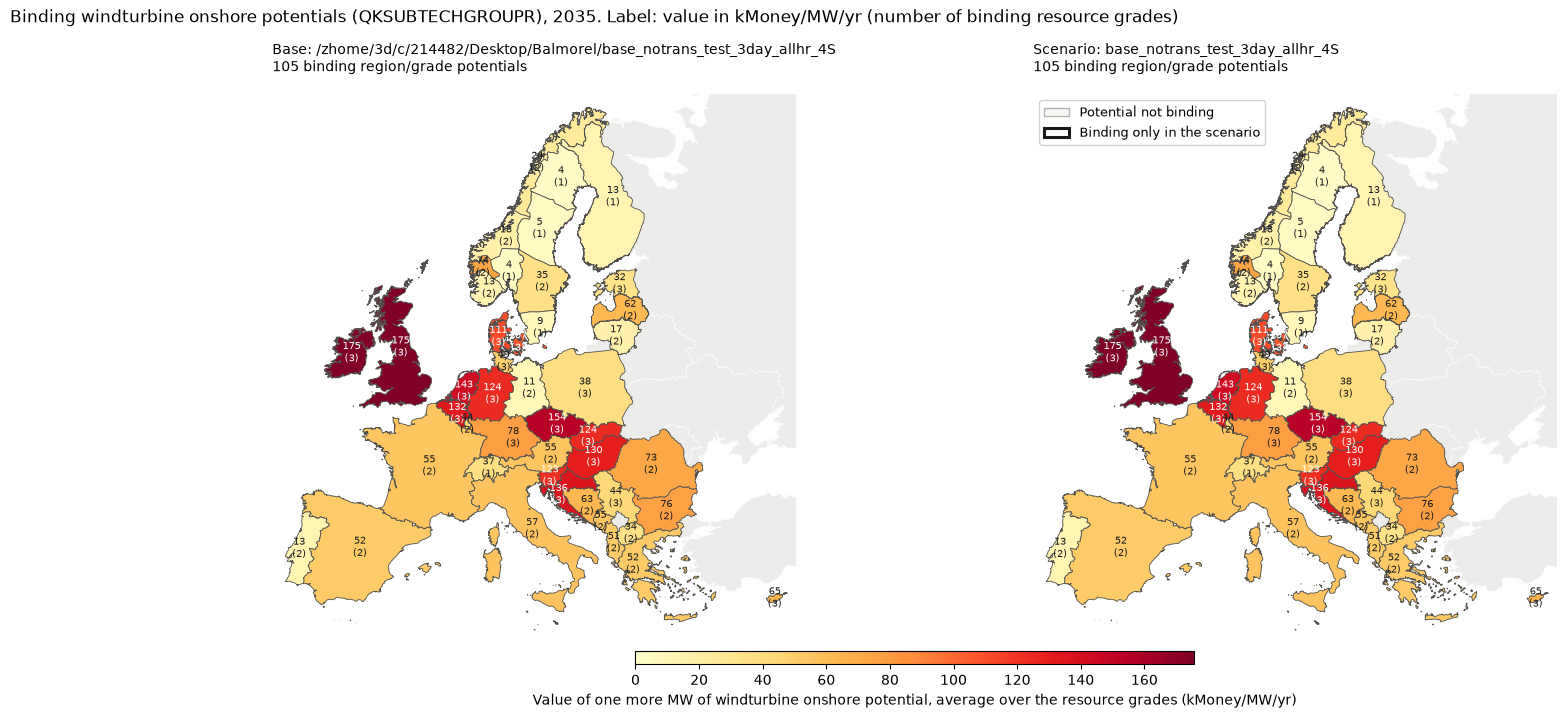

Value of one more MW of windturbine onshore potential (kMoney/MW/yr: average over the grades and most valuable grade) and number of binding grades per region


Base                   Scenario            \
                             Value Max grade Binding    Value Max grade   
AL (Albania)                  51.0      87.4       2     51.0      87.4   
AT (Austria)                  55.3     109.0       2     55.3     109.0   
BA (Bosnia And Herzegovina)   62.9     103.4       2     62.9     103.4   
BE (Belgium)                 131.8     147.7       3    131.8     147.7   
BG (Bulgaria)                 75.6     136.0       2     75.6     136.0   
CH (Switzerland)              36.8     110.5       1     36.8     110.5   
CY (Cyprus)                   65.0      74.7       3     65.0      74.7   
CZ (Czech Republic)          154.4     187.7       3    154.4     187.7   
DE4-E (Germany)               10.7      28.0       2     10.7      28.0   
DE4-N (Germany)               48.7     106.7       3     48.7     106.7   
DE4-S (Germany)               77.6     100.8       3     77.6     100.8   
DE4-W (Germany)              124.5     143.8       3    124.5     143.8   
DK1 (Denmark)                111.0     120.5       3    111.0     120.5   
DK2 (Denmark)                107.4     119.3       3    107.4     119.3   
EE (Estonia)                  32.4      72.0       3     32.4      72.0   
ES (Spain)                    51.6     117.2       2     51.6     117.2   
FIN (Finland)                 13.5      40.5       1     13.5      40.5   
FR (France)                   55.2     122.9       2     55.2     122.9   
GR (Greece)                   51.8     119.8       2     51.8     119.8   
HR (Croatia)                 135.7     179.1       3    135.7     179.1   
HU (Hungary)                 129.7     144.0       3    129.7     144.0   
IE (Ireland)                 175.4     186.7       3    175.4     186.7   
IT (Italy)                    56.7     124.5       2     56.7     124.5   
LT (Lithuania)                16.6      40.7       2     16.6      40.7   
LU (Luxembourg)               43.9      92.5       2     43.9      92.5   
LV (Latvia)                   62.3      96.2       2     62.3      96.2   
ME (Montenegro)               54.8      91.0       2     54.8      91.0   
MK (North Macedonia)          33.6      62.2       2     33.6      62.2   
MT (Malta)                   142.0     144.3       3    142.0     144.3   
NL (Netherlands)             143.4     162.3       3    143.4     162.3   
NO1 (Norway)                   4.4      13.3       1      4.4      13.3   
NO2 (Norway)                  13.5      34.0       2     13.5      34.0   
NO3 (Norway)                  17.6      41.2       2     17.6      41.2   
NO4 (Norway)                  24.2      45.2       2     24.2      45.2   
NO5 (Norway)                  73.8     120.1       2     73.8     120.1   
PL (Poland)                   37.7      77.9       3     37.7      77.9   
PT (Portugal)                 12.9      30.3       2     12.9      30.3   
RO (Romania)                  72.5     152.7       2     72.5     152.7   
RS (Serbia)                   43.8      69.1       3     43.8      69.1   
SE1 (Sweden)                   3.7      11.2       1      3.7      11.2   
SE2 (Sweden)                   5.5      16.5       1      5.5      16.5   
SE3 (Sweden)                  35.3      72.6       2     35.3      72.6   
SE4 (Sweden)                   9.1      27.4       1      9.1      27.4   
SI (Slovenia)                122.7     160.1       3    122.7     160.1   
SK (Slovakia)                124.1     144.0       3    124.1     144.0   
UK (United Kingdom)          175.0     200.2       3    175.0     200.2   

                                    Change  
                            Binding  Value  
AL (Albania)                      2    0.0  
AT (Austria)                      2    0.0  
BA (Bosnia And Herzegovina)       2    0.0  
BE (Belgium)                      3    0.0  
BG (Bulgaria)                     2    0.0  
CH (Switzerland)                  1    0.0  
CY (Cyprus)                       3    0.0  
CZ (Czech Republic)     

In [63]:
# 12.2 Map of the binding investment potentials of one technology group: value of one more MW, base vs scenario
import geopandas as gpd
import pybalmorel
from matplotlib.colors import Normalize

POTENTIAL_GROUP = "WINDTURBINE_ONSHORE"      # any TECH_GROUP of QKSUBTECHGROUPR, e.g. "SOLARPV"

def potential_by_region(d):
    """Per region: value of one more MW of potential averaged over the resource grades (non-binding grades count as 0,
    kMoney/MW/yr), the value in the most valuable grade, and the number of binding grades (non-zero shadow price).
    A simple average is used because the right-hand side of QKSUBTECHGROUPR is the remaining potential (potential minus
    existing capacity), which is zero or negative for grades already filled by existing turbines although their shadow
    price can be high, so it cannot serve as a weight."""
    r = d["QKSUBTECHGROUPR"].loc[lambda t: t["TECH_GROUP"].eq(POTENTIAL_GROUP)].assign(V=lambda t: (-t["value"]).clip(lower=0))
    g = r.groupby("RRR")["V"]
    return pd.DataFrame({"Value": g.mean() / 1e3, "Max grade": g.max() / 1e3,
                         "Binding": r.loc[r["V"] > 1e-6].groupby("RRR").size()}).fillna({"Binding": 0})

pot_map = {s: potential_by_region(duals[s]) for s in (BASE_SCENARIO, SCENARIO)}
geo = gpd.read_file(Path(pybalmorel.__file__).parent / "geofiles" / "2024 BalmorelMap.geojson").dropna(subset=["id"]).to_crs("EPSG:3035")
modelled = geo["id"].isin(region_country.index)
vmax = max(t["Value"].max() for t in pot_map.values()) or 1
norm = Normalize(vmin=0, vmax=vmax)
newly = pot_map[SCENARIO].index[(pot_map[SCENARIO]["Binding"] > 0) & (pot_map[BASE_SCENARIO]["Binding"].reindex(pot_map[SCENARIO].index, fill_value=0) == 0)]

fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
for ax, scen in zip(axes, (BASE_SCENARIO, SCENARIO)):
    t = pot_map[scen]
    g = geo[modelled].assign(Value=lambda d: d["id"].map(t["Value"]).fillna(0), Binding=lambda d: d["id"].map(t["Binding"]).fillna(0))
    geo[~modelled].plot(ax=ax, color="#ececea", edgecolor="#fcfcfb", linewidth=0.5)
    g.loc[g["Binding"].eq(0)].plot(ax=ax, color="#f6f6f4", edgecolor="#b5b4ae", linewidth=0.5)              # potential not binding
    g.loc[g["Binding"].gt(0)].plot(ax=ax, column="Value", cmap="YlOrRd", norm=norm, edgecolor="#52514e", linewidth=0.6)
    if scen == SCENARIO and len(newly):
        g.loc[g["id"].isin(newly)].boundary.plot(ax=ax, color="#1a1a1a", linewidth=2.2)                     # binding only in the scenario
    for _, row in g.loc[g["Binding"].gt(0)].iterrows():
        part = max(getattr(row.geometry, "geoms", [row.geometry]), key=lambda p: p.area)
        pt = part.representative_point()
        ax.annotate(f"{row['Value']:.0f}\n({int(row['Binding'])})", (pt.x, pt.y), ha="center", va="center", fontsize=7,
                    color="white" if row["Value"] > 0.6 * vmax else "#1a1a1a")
    minx, miny, maxx, maxy = g.geometry.apply(lambda x: max(getattr(x, "geoms", [x]), key=lambda p: p.area)).total_bounds
    ax.set_xlim(minx - 1e5, maxx + 1e5); ax.set_ylim(miny - 1e5, maxy + 1e5)
    ax.set_axis_off()
    n_bind = int(t["Binding"].sum())
    ax.set_title(f"{'Base' if scen == BASE_SCENARIO else 'Scenario'}: {scen}\n{n_bind} binding region/grade potentials", loc="left", fontsize=10)
fig.colorbar(plt.cm.ScalarMappable(cmap="YlOrRd", norm=norm), ax=axes, orientation="horizontal", shrink=0.4, pad=0.02, aspect=40,
             label=f"Value of one more MW of {clean_name(POTENTIAL_GROUP).lower()} potential, average over the resource grades (kMoney/MW/yr)")
axes[1].legend(handles=[Patch(facecolor="#f6f6f4", edgecolor="#b5b4ae", label="Potential not binding"),
                        Patch(facecolor="white", edgecolor="#1a1a1a", linewidth=2.2, label="Binding only in the scenario")],
               loc="upper left", frameon=True, framealpha=0.9, fontsize=9)
fig.suptitle(f"Binding {clean_name(POTENTIAL_GROUP).lower()} potentials (QKSUBTECHGROUPR), {BOTTLENECK_YEAR}. "
             "Label: value in kMoney/MW/yr (number of binding resource grades)", x=0.01, ha="left")
plt.show()

table = pd.concat({"Base": pot_map[BASE_SCENARIO], "Scenario": pot_map[SCENARIO]}, axis=1).fillna(0)
table = table.loc[table[[("Base", "Binding"), ("Scenario", "Binding")]].max(axis=1) > 0]
table[("Change", "Value")] = table[("Scenario", "Value")] - table[("Base", "Value")]
table = table.sort_values(("Change", "Value"), ascending=False)
table.index = [f"{r} ({clean_name(region_country.get(r, ''))})" for r in table.index]
print(f"Value of one more MW of {clean_name(POTENTIAL_GROUP).lower()} potential (kMoney/MW/yr: average over the grades and most valuable grade) and number of binding grades per region")
display(table.round(1))


### 12.3 Renewable investment potentials: potential vs installed capacity
For onshore wind, offshore wind and solar PV, the investment potential of each country (`SUBTECHGROUPKPOT`, summed over its regions and resource grades) next to the capacity installed in the base and in the scenario in `BOTTLENECK_YEAR` (GW). The installed capacity is existing plus new capacity counted against the potential, taken from `QKSUBTECHGROUPR` (installed = potential - remaining room). "Regions full" counts the regions in which every resource grade is fully used in the scenario (less than 0.1 % or 1 MW left). **Highlighted**: the whole national potential of that technology is installed in the scenario, in orange if it was already fully installed in the base and in red if it becomes full only in the scenario. Countries with at least one fully used technology are listed first.

In [64]:
# 12.3 Renewable investment potentials: potential vs installed capacity per country, base and scenario (GW)
POTENTIAL_GROUPS = {"WINDTURBINE_ONSHORE": "Onshore wind", "WINDTURBINE_OFFSHORE": "Offshore wind", "SOLARPV": "Solar PV"}
FULL_TOLERANCE = 0.001               # a region/grade counts as full when less than 0.1 % (or 1 MW) of its potential is left

kpot = gt.Container()
kpot.read(str(RUN_DIR / ENDOFMODEL), symbols=["SUBTECHGROUPKPOT"])
kpot = kpot["SUBTECHGROUPKPOT"].records.astype({"CCCRRRAAA": str, "TECH_GROUP": str, "SUBTECH_GROUP": str}) \
           .rename(columns={"CCCRRRAAA": "RRR", "value": "Potential"}).set_index(["RRR", "TECH_GROUP", "SUBTECH_GROUP"])["Potential"]

def installed_by_grade(d):
    """Installed capacity per region, technology group and grade (MW), from QKSUBTECHGROUPR:
    existing + new capacity <= potential, where GAMS moves the existing capacity to the right-hand side, so
    installed = potential - (right-hand side - level) = potential - remaining room."""
    q = d["QKSUBTECHGROUPR"].set_index(["RRR", "TECH_GROUP", "SUBTECH_GROUP"])
    return (kpot.reindex(q.index) - (q["upper"] - q["level"])).rename("Installed")

grades = pd.concat({"Potential": kpot, "Base": installed_by_grade(duals[BASE_SCENARIO]),
                    "Scenario": installed_by_grade(duals[SCENARIO])}, axis=1).dropna(subset=["Potential"])
grades = grades.loc[grades.index.get_level_values("TECH_GROUP").isin(POTENTIAL_GROUPS)].fillna(0)
is_full = lambda col: (grades["Potential"] - grades[col]) <= np.maximum(1.0, FULL_TOLERANCE * grades["Potential"])
grades["Full"], grades["FullBase"] = is_full("Scenario"), is_full("Base")

# Per region (summed over the grades): full when every grade with potential is full
regions = grades.groupby(level=["RRR", "TECH_GROUP"]).agg(Potential=("Potential", "sum"), Base=("Base", "sum"),
                                                           Scenario=("Scenario", "sum"), Full=("Full", "all"), FullBase=("FullBase", "all"))
regions = regions.loc[regions["Potential"] > 1e-6]
regions["Country"] = regions.index.get_level_values("RRR").map(region_country)

# Per country: GW, share of the potential installed, number of regions that are full in the scenario
country = regions.groupby(["Country", regions.index.get_level_values("TECH_GROUP")]).agg(
    Potential=("Potential", "sum"), Base=("Base", "sum"), Scenario=("Scenario", "sum"),
    Full_regions=("Full", "sum"), Full_regions_base=("FullBase", "sum"), Regions=("Full", "size"))
country[["Potential", "Base", "Scenario"]] /= 1e3                                   # GW
country["Scenario (% of potential)"] = country["Scenario"] / country["Potential"] * 100
country["Full in scenario"] = country["Full_regions"] == country["Regions"]
country["Full in base"] = country["Full_regions_base"] == country["Regions"]
country["Regions full (scen.)"] = country["Full_regions"].astype(int).astype(str) + "/" + country["Regions"].astype(str)

cols = ["Potential", "Base", "Scenario", "Scenario (% of potential)", "Regions full (scen.)"]
pot_table = country[cols].unstack("TECH_GROUP")
pot_table.columns = pot_table.columns.swaplevel(0, 1)
pot_table = pot_table.reindex(columns=[(g, c) for g in POTENTIAL_GROUPS if g in country.index.get_level_values(1) for c in cols])
pot_table = pot_table.rename(columns=POTENTIAL_GROUPS, level=0)
flag = lambda col: country[col].unstack("TECH_GROUP").reindex(columns=list(POTENTIAL_GROUPS)).rename(columns=POTENTIAL_GROUPS).fillna(False).astype(bool)
full, full_base = flag("Full in scenario"), flag("Full in base")
pot_table.index = [clean_name(c) for c in pot_table.index]
full.index = [clean_name(c) for c in full.index]
full_base.index = [clean_name(c) for c in full_base.index]
pot_table = pot_table.loc[full.any(axis=1).sort_values(ascending=False).index]          # countries with a full technology first

def highlight_full(df):
    """Technology block of a country where the whole potential is installed in the scenario: orange if it was already
    full in the base, red if it becomes full only in the scenario."""
    style = pd.DataFrame("", index=df.index, columns=df.columns)
    for tech in full.columns:
        if tech in df.columns.get_level_values(0):
            both = full.index[full[tech] & full_base[tech].reindex(full.index, fill_value=False)].intersection(df.index)
            new = full.index[full[tech] & ~full_base[tech].reindex(full.index, fill_value=False)].intersection(df.index)
            style.loc[both, tech] = "background-color: #f9c8a7; font-weight: bold"
            style.loc[new, tech] = "background-color: #e34948; color: white; font-weight: bold"
    return style

n_full, n_new = full.sum(), (full & ~full_base.reindex_like(full).fillna(False)).sum()
print(f"Renewable potentials and installed capacity (GW), {BOTTLENECK_YEAR}. Highlighted: the whole national potential of the technology is "
      f"installed in the scenario; orange = already full in the base, red = full only in the scenario. "
      + "; ".join(f"{t}: {n} countries full, of which {n_new[t]} new" for t, n in n_full.items()))
fmt = {c: ("{:.0f} %" if c[1].startswith("Scenario (%") else "{}" if c[1].startswith("Regions") else "{:,.1f}") for c in pot_table.columns}
display(pot_table.style.apply(highlight_full, axis=None).format(fmt, na_rep="-"))


Renewable potentials and installed capacity (GW), 2035. Highlighted: the whole national potential of the technology is installed in the scenario; orange = already full in the base, red = full only in the scenario. Onshore wind: 14 countries full, of which 0 new; Offshore wind: 0 countries full, of which 0 new; Solar PV: 6 countries full, of which 0 new


/tmp/ipykernel_563832/1355188707.py:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  flag = lambda col: country[col].unstack("TECH_GROUP").reindex(columns=list(POTENTIAL_GROUPS)).rename(columns=POTENTIAL_GROUPS).fillna(False).astype(bool)
/tmp/ipykernel_563832/1355188707.py:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  flag = lambda col: country[col].unstack("TECH_GROUP").reindex(columns=list(POTENTIAL_GROUPS)).rename(columns=POTENTIAL_GROUPS).fillna(False).astype(bool)


### 12.4 Scale of the potential bottlenecks per type of constraint
Shadow prices have different units for different constraints (Money/MW of potential, Money/GJ of fuel, Money/MW in a time slice, ...), so they are compared through the **scarcity rent**: |shadow price| x the exogenous limit of the constraint (Mmoney/yr), i.e. the right-hand-side rent of 12.0 part 1, with the equation families grouped into types of bottleneck (`BOTTLENECK_TYPE`). For transmission the limit is the fixed line capacity (upper bound of `VX_T`, all lines). Energy balances, wind/solar dispatch definitions and transport balances are left out, because their duals value demand or existing output rather than a limit.

The rent measures how valuable the limit is at the margin, summed over the whole limit; it is not a cost paid by the system, and the rents of different types should be read as orders of magnitude, not added up.

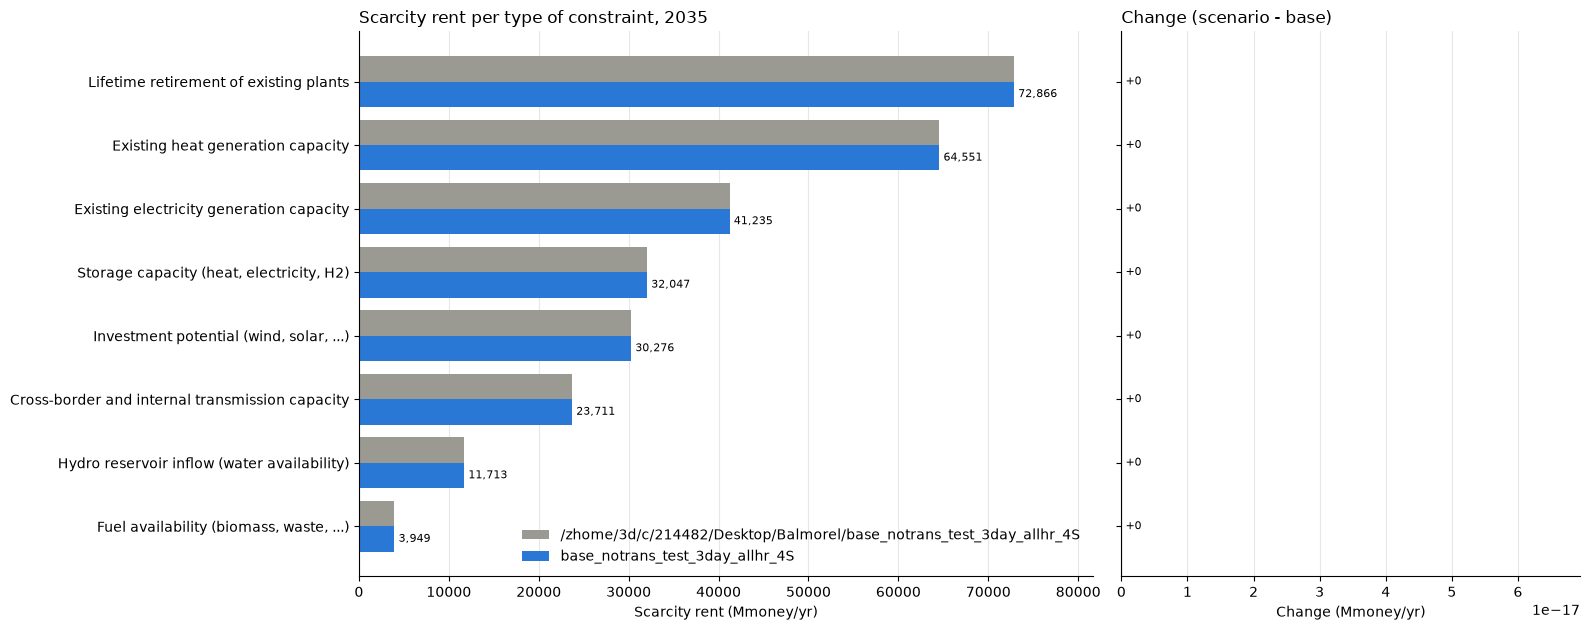

Scarcity rent (Mmoney/yr) and number of binding rows per type of constraint, 2035


,Base,Scenario,Change,"Binding rows, base","Binding rows, scen."
Type of constraint,,,,,
Lifetime retirement of existing plants,72866.0,72866.0,0.0,1162,1162
Existing heat generation capacity,64550.9,64550.9,0.0,504863,504863
Existing electricity generation capacity,41235.3,41235.3,0.0,286090,286090
"Storage capacity (heat, electricity, H2)",32046.6,32046.6,0.0,75248,75248
"Investment potential (wind, solar, ...)",30275.9,30275.9,0.0,236,236
Cross-border and internal transmission capacity,23710.6,23710.6,0.0,46627,46627
Hydro reservoir inflow (water availability),11713.5,11713.5,0.0,120,120
"Fuel availability (biomass, waste, ...)",3948.8,3948.8,0.0,148,148


In [65]:
# 12.4 Scale of the potential bottlenecks: scarcity rent per type of constraint (Mmoney/yr), base vs scenario
# Equation families grouped into bottleneck types. Rent = |shadow price| x exogenous limit (right-hand side), as in 12.0 part 1;
# for transmission the limit is the fixed line capacity (upper bound of VX_T).
BOTTLENECK_TYPE = {
    "QKSUBTECHGROUPR": "Investment potential (wind, solar, ...)", "QKTECHGROUPR": "Investment potential (wind, solar, ...)",
    "QGMAXCF": "Fuel availability (biomass, waste, ...)", "QGMAXRFS": "Fuel availability (biomass, waste, ...)",
    "QGKE_UP": "Existing electricity generation capacity", "QGKH_UP": "Existing heat generation capacity",
    "QGCVGEXT": "Existing heat generation capacity", "QGCBGBPRBYPASS2": "Existing heat generation capacity",
    "QDECOM_EXO_ACCUM_REST": "Lifetime retirement of existing plants", "QDECOM_ENDO_ACCUM_REST": "Lifetime retirement of existing plants",
    "QHYRSSEQ": "Hydro reservoir inflow (water availability)",
    "QHSTOVGHTLIM": "Storage capacity (heat, electricity, H2)", "QHSTOVOLTLIM": "Storage capacity (heat, electricity, H2)",
    "QHSTOLOADTLIM": "Storage capacity (heat, electricity, H2)", "QESTOVGETLIM": "Storage capacity (heat, electricity, H2)",
    "QESTOVOLTLIM": "Storage capacity (heat, electricity, H2)", "QESTOLOADTLIM": "Storage capacity (heat, electricity, H2)",
    "QHYDROGEN_STOMAXCON": "Storage capacity (heat, electricity, H2)", "QHYDROGEN_STOMAXUNLD": "Storage capacity (heat, electricity, H2)",
    "QXH2K_UP": "H2 transmission capacity",
}
# Not bottlenecks, left out: energy balances (QEEQ, QHEQ, QHYDROGEN_EQ value the demand), wind/solar dispatch definitions
# (QWNDDISPATCH, QSOLEDISPATCH, QSOLHDISPATCH value the output of existing VRE), transport and EV balances, and the
# upper limit on retiring existing plants (QDECOM_EXO_LIM: the model would retire more capacity than exists).

def rent_by_type(d):
    s = d["screen"]
    t = s.loc[s.index.isin(BOTTLENECK_TYPE.keys()), "RHS rent (Mmoney)"].groupby(lambda n: BOTTLENECK_TYPE[n]).sum()
    x = d["VX_T"]
    t["Cross-border and internal transmission capacity"] = (x["value"].abs() * x["upper"].where(np.isfinite(x["upper"]), 0)).sum() / 1e6
    n = s.loc[s.index.isin(BOTTLENECK_TYPE.keys()), "Binding"].groupby(lambda e: BOTTLENECK_TYPE[e]).sum()
    n["Cross-border and internal transmission capacity"] = int((x["value"].abs() > 1e-9).sum())
    return t, n

(rb, nb_), (rs, ns) = rent_by_type(duals[BASE_SCENARIO]), rent_by_type(duals[SCENARIO])
types = pd.DataFrame({"Base": rb, "Scenario": rs}).fillna(0)
types["Change"] = types["Scenario"] - types["Base"]
types["Binding rows, base"], types["Binding rows, scen."] = nb_, ns
types = types.loc[types[["Base", "Scenario"]].max(axis=1) > 0.5].sort_values("Scenario")
types.index.name = "Type of constraint"

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 0.55 * len(types) + 2), sharey=True, gridspec_kw={"width_ratios": [1.6, 1]})
y = np.arange(len(types))
ax.barh(y + 0.2, types["Base"], height=0.4, color="#9a9992", label=BASE_SCENARIO)
ax.barh(y - 0.2, types["Scenario"], height=0.4, color="#2a78d6", label=SCENARIO)
for i, (b, s) in enumerate(zip(types["Base"], types["Scenario"])):
    ax.annotate(f"{s:,.0f}", (s, i - 0.2), va="center", fontsize=8, xytext=(3, 0), textcoords="offset points")
ax.set_yticks(y); ax.set_yticklabels(types.index)
ax.set_xlabel("Scarcity rent (Mmoney/yr)")
ax.set_title(f"Scarcity rent per type of constraint, {BOTTLENECK_YEAR}", loc="left")
ax.legend(frameon=False, loc="lower right")
ch = types["Change"]
ax2.barh(y, ch, height=0.6, color=np.where(ch >= 0, "#e34948", "#1baf7a"))
for i, v in enumerate(ch):
    ax2.annotate(f"{v:+,.0f}", (v, i), va="center", ha="left" if v >= 0 else "right", fontsize=8, xytext=(3 if v >= 0 else -3, 0), textcoords="offset points")
ax2.axvline(0, color="#52514e", linewidth=0.8)
ax2.set_xlabel("Change (Mmoney/yr)")
ax2.set_title("Change (scenario - base)", loc="left")
for a in (ax, ax2):
    a.grid(axis="x", alpha=0.3); a.set_axisbelow(True)
    for side in ("top", "right"): a.spines[side].set_visible(False)
ax.margins(x=0.12); ax2.margins(x=0.25)
plt.tight_layout(); plt.show()

print(f"Scarcity rent (Mmoney/yr) and number of binding rows per type of constraint, {BOTTLENECK_YEAR}")
display(types.iloc[::-1].round(1))


## 13. Sensitivity study: the length of a time step (`CHRONOHOUR`)

This section compares two runs that differ **only** in how long one time step is assumed to last. Both runs use the same data and the same time selection: 4 seasons (`S10, S24, S40, S50`) × 72 **consecutive hourly** time steps (`T073-T144`, Thursday-Saturday). The two runs are:

| Run | Label | `CHRONOHOUR(S,T)` | `SSIZE(S)` |
|---|---|---|---|
| Base | `BASE_SCENARIO` (`BASE_RESULTS`) | base default `168/card(T)` = 168/72 = **2.33 h** | base default `52/card(S)` = **13** |
| Scenario | `SCENARIO` (`RESULTS`) | `data/CHRONOHOUR.inc`: **1 h** | `data/SSIZE.inc`: `52/card(S)·168/Σ_T CHRONOHOUR` = **30.33** |

The base default assumes that the selected time steps are spread evenly over the whole 168-hour week, e.g. every 3rd hour with `CHRONOHOUR = 3`. That does not hold for this selection of consecutive hours, so the scenario sets one step to one real hour. It moves the week scaling of inter-seasonal storage into `SSIZE`, which keeps `CHRONOHOUR × SSIZE` the same in both runs.

#### Where `CHRONOHOUR` enters the model
`CHRONOHOUR` is **not** a weight in the objective or in the annual sums: these use `IHOURSINST(S,T) = 8760·WEIGHT_S·WEIGHT_T/(ΣWEIGHT_S·ΣWEIGHT_T)`, which is 8760/288 = 30.42 h per step in both runs. With unit commitment switched off, `CHRONOHOUR` only appears in the **state-of-charge equations** that link one time step to the next:

| Equation | Storage | Form |
|---|---|---|
| `QESTOVOLT`, `QHSTOVOLT` | intra-seasonal electricity (pumped hydro) and heat storage | `V(t+1) = V(t) + CHRONOHOUR·(load(t) − unload(t)/η)`, cyclic within the season |
| `QESTOVOLTS`, `QHSTOVOLTS`, `QHYDROGEN_STOVOL` | inter-seasonal electricity, heat and H₂ storage | as above, plus at the last step the net change of the season × (`SSIZE` − 1) |
| `QEV_BEV_BEBALANCE`, `QEV_PHEV_BEBALANCE` | EV batteries | `SOC(t) = SOC(t−1) + CHRONOHOUR·(G2V·η − V2G/η + energy of returning − leaving EVs)` |

All other constraints (energy balances, capacity limits, demand profiles, wind and solar profiles) are written per step in MW and are therefore **identical** in the two runs.

#### What should change, and why
In the base run one MW of charging for one step raises the state of charge by 2.33 MWh, although the profiles it responds to (demand, wind, solar) only advance by one hour. The base therefore models every storage as if it had **1/2.33 = 43 % of its real duration** (energy-to-power ratio). A daily cycle of 24 steps behaves like a 56-hour cycle for the storage. With `CHRONOHOUR = 1` the storage behaves physically. The expected effects are:

1. **Invariants**: exogenous demand, the annual weights and the driving energy of the EVs do not change. Any change in endogenous demand comes from storage, V2G and conversion losses.
2. **More storage use**: the same storage volume supports 2.33× more hours of full-power operation, so intra-seasonal storage and V2G cycle more.
3. **Shorter-duration storage**: technologies with a small energy-to-power ratio become useful. In the base, a 0.5-h H₂ tank empties in 0.2 steps and is therefore nearly useless. Investment should shift from long-duration storage (H₂ caverns, 180 h) to short-duration storage (tanks).
4. **Inter-seasonal storage almost unchanged**: the seasonal transfer term `CHRONOHOUR·SSIZE` is 30.33 in both runs, so only the swings within the 72-hour block change.
5. **System response**: more flexibility means less curtailment, less firm back-up capacity (boilers, condensing, CHP) and lower or flatter prices.
6. **Lower total cost**: for intra-seasonal storage and EVs the scenario is a relaxation of the base. Every base solution remains feasible with the state of charge divided by 2.33. The objective should therefore not increase.

Sections 13.1-13.6 test these expectations one by one, and 13.7 collects them in one table. The section only uses the settings of 0.1 (`RUN_DIR`, `RESULTS`, `BASE_RESULTS_DIR`, `BASE_RESULTS`) and reads both result files itself.

In [ ]:
# 13.0 Data of the two runs for the CHRONOHOUR study, read directly from the two MainResults files
import gams.transfer as gt

CH_SYMBOLS = ["OBJ_YCR", "G_CAP_YCRAF", "G_STO_YCRAF", "PRO_YCRAGF", "PRO_YCRAGFST", "STORAGE_LEVEL", "CURT_YCRAGF",
              "EL_DEMAND_YCR", "EL_DEMAND_YCRST", "H_DEMAND_YCRA", "H_DEMAND_YCRAST", "H2_DEMAND_YCR",
              "EL_PRICE_YCRST", "EMI_YCRAG", "EV_G2V_Y", "EV_V2G_Y", "EV_NET_Y"]
CH_RUNS = {BASE_SCENARIO: BASE_RESULTS_DIR / BASE_RESULTS,    # old default CHRONOHOUR = 168/card(T)
           SCENARIO: RUN_DIR / RESULTS}                       # CHRONOHOUR = 1: one step is one real hour
CH_COLORS = {BASE_SCENARIO: "#9a9992", SCENARIO: "#2a78d6"}   # base = grey, scenario = blue (as in 9.2)
CH_RENAME = {**RENAME, "SSS": "Season", "TTT": "Time", "VARIABLE_CATEGORY": "Category", "value": "Value"}
STORAGE_TYPES = ["INTRASEASONAL-ELECT-STORAGE", "INTRASEASONAL-HEAT-STORAGE", "INTERSEASONAL-HEAT-STORAGE", "H2-STORAGE"]
FIRM_TYPES = ["BOILERS", "CONDENSING", "CHP-BACK-PRESSURE", "CHP-EXTRACTION"]
STORAGE_SHORT = {"INTRASEASONAL-ELECT-STORAGE": "pumped hydro", "INTRASEASONAL-HEAT-STORAGE": "heat (intra-s.)",
                 "INTERSEASONAL-HEAT-STORAGE": "heat (inter-s.)", "H2-STORAGE": "H2"}

def read_run(path):
    """The CH_SYMBOLS of one MainResults file as DataFrames with string labels and the column names of 0.2."""
    c = gt.Container()
    try:
        c.read(str(path), symbols=CH_SYMBOLS)
    except Exception:              # a symbol is missing in this run (e.g. no EV add-on): read the whole file
        c.read(str(path))
    out = {}
    for s in CH_SYMBOLS:
        if s not in c or c[s].records is None:
            continue
        r = c[s].records.copy()
        for col in r.columns[:-1]:
            r[col] = r[col].astype(str)
        out[s] = r.rename(columns=CH_RENAME)
    del c
    return out

ch = {run: read_run(path) for run, path in CH_RUNS.items()}
CH_YEARS = sorted(set(ch[BASE_SCENARIO]["OBJ_YCR"]["Year"]) & set(ch[SCENARIO]["OBJ_YCR"]["Year"]), key=int)
CH_YEAR = CH_YEARS[-1]                     # year of the single-year charts

def ch_table(symbol, by, where=None):
    """Sum of Value by `by` for both runs, with the change (scenario - base) in absolute terms and in %."""
    cols = {}
    for run, data in ch.items():
        d = data[symbol]
        d = d.loc[where(d)] if where is not None else d
        cols[run] = d.groupby(by)["Value"].sum()
    t = pd.DataFrame(cols).fillna(0)
    t["Change"] = t[SCENARIO] - t[BASE_SCENARIO]
    t["Change (%)"] = 100 * t["Change"] / t[BASE_SCENARIO].where(t[BASE_SCENARIO].abs() > 1e-9)
    return t

def ch_style(ax, title, ylabel, axis="y"):
    """Axis styling of the comparison charts (as `style` in 9.2), defined here so that section 13 runs on its own."""
    ax.set_title(title, loc="left"); ax.set_ylabel(ylabel); ax.set_xlabel("")
    ax.grid(axis=axis, alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)

def is_tech(*types):
    return lambda d: d["Technology"].isin(types)

def is_cat(*cats):
    return lambda d: d["Category"].isin(cats)

print(f"Base     : {BASE_SCENARIO}  <- {CH_RUNS[BASE_SCENARIO].name}")
print(f"Scenario : {SCENARIO}  <- {CH_RUNS[SCENARIO].name}")
print(f"Common years: {', '.join(CH_YEARS)}; single-year charts use {CH_YEAR}")

### 13.1 Time-step parameters of the two runs
The parameters are derived from the time selection in the results (`card(S)`, `card(T)`), using the formulas of `base/data` for the base and of `data/CHRONOHOUR.inc` / `data/SSIZE.inc` for the scenario. The CHRONOHOUR values assumed here are checked against the solution itself in 13.2.

In [ ]:
# 13.1 CHRONOHOUR, SSIZE and the annual weight of a time step in both runs
slices = ch[SCENARIO]["EL_PRICE_YCRST"][["Season", "Time"]].drop_duplicates()
N_S, N_T = slices["Season"].nunique(), slices["Time"].nunique()
CH_TIMES = sorted(slices["Time"].unique())
CH_STEP = {BASE_SCENARIO: 168 / N_T, SCENARIO: 1.0}                   # CHRONOHOUR of each run (h per step)
CH_SSIZE = {BASE_SCENARIO: 52 / N_S, SCENARIO: 52 / N_S * 168 / (N_T * CH_STEP[SCENARIO])}

params = pd.DataFrame({run: {
    "Time steps per season, card(T)": N_T,
    "Seasons, card(S)": N_S,
    "CHRONOHOUR (h per step, storage equations)": CH_STEP[run],
    "Hours covered by one season block (card(T) x CHRONOHOUR)": N_T * CH_STEP[run],
    "SSIZE (repetitions of the block per season)": CH_SSIZE[run],
    "CHRONOHOUR x SSIZE (seasonal weight of one step's storage flow, h)": CH_STEP[run] * CH_SSIZE[run],
    "IHOURSINST = 8760 / (card(S) card(T)) (annual weight of one step, h)": 8760 / (N_S * N_T),
    "Storage-duration factor (real duration / modelled duration)": 1 / CH_STEP[run],
} for run in CH_RUNS})
display(params.round(3))
print("CHRONOHOUR x SSIZE is the same in both runs, so the seasonal (inter-seasonal) storage balance is scaled identically;\n"
      "it differs from IHOURSINST by 52 weeks vs 365 days (-0.27 %) in both runs. Only the within-block storage dynamics change.")

### 13.2 Is the time step really 2.33 h in the base and 1 h in the scenario? An empirical check
The storage equations imply `V(t+1) − V(t) = CHRONOHOUR·load(t) − (CHRONOHOUR/η)·unload(t)`. A least-squares fit of the reported level change on the reported loading and unloading (all regions, seasons and years, without the season wrap) therefore returns CHRONOHOUR as the loading coefficient, and η as the ratio of the two coefficients. This shows directly that the runs used the intended setting. The chart shows the storage level and the net loading in the region and season with the largest pumped-hydro throughput.

In [ ]:
# 13.2 Fit of the storage dynamics: level change = a * loading - b * unloading  ->  a = CHRONOHOUR, a / b = efficiency
DYNAMICS = {   # storage type: (key of the storage group, loading symbol and category, output commodity)
    "INTRASEASONAL-ELECT-STORAGE": ("Region", "EL_DEMAND_YCRST", "ENDO_INTRASTO", "ELECTRICITY"),
    "INTRASEASONAL-HEAT-STORAGE": ("Area", "H_DEMAND_YCRAST", "ENDO_INTRASTO", "HEAT"),
}

def storage_flows(run, tech):
    """Level, loading and unloading (MW) per storage group and time step, with the level change to the next step."""
    key, load_symbol, load_cat, commodity = DYNAMICS[tech]
    idx = ["Year", key, "Season", "Time"]
    data = ch[run]
    level = data["STORAGE_LEVEL"].loc[lambda d: d["Technology"].eq(tech)].groupby(idx)["Value"].sum()
    load = data[load_symbol].loc[lambda d: d["Category"].eq(load_cat)].groupby(idx)["Value"].sum()
    unload = data["PRO_YCRAGFST"].loc[lambda d: d["Technology"].eq(tech) & d["Commodity"].eq(commodity)].groupby(idx)["Value"].sum()
    f = pd.DataFrame({"Level": level, "Load": load, "Unload": unload})
    groups = f.index.droplevel("Time").unique()                      # zeros are not written to the GDX: rebuild all steps
    full = pd.MultiIndex.from_tuples([(*g[:2], g[2], t) for g in groups for t in CH_TIMES], names=idx)
    f = f.reindex(full).fillna(0).sort_index().reset_index()
    f["dLevel"] = f.groupby(["Year", key, "Season"])["Level"].shift(-1) - f["Level"]   # NaN at the last step (season wrap)
    return f

fits = []
for tech in DYNAMICS:
    for run in CH_RUNS:
        f = storage_flows(run, tech).dropna(subset=["dLevel"])
        A, b = f[["Load", "Unload"]].to_numpy(), f["dLevel"].to_numpy()
        (a_load, a_unload), *_ = np.linalg.lstsq(A, b, rcond=None)
        r2 = 1 - ((b - A @ np.array([a_load, a_unload])) ** 2).sum() / ((b - b.mean()) ** 2).sum()
        fits.append({"Storage": tech, "Run": run, "Assumed CHRONOHOUR": CH_STEP[run], "Fitted CHRONOHOUR (a)": a_load,
                     "Implied efficiency (a/b)": -a_load / a_unload, "R2": r2, "Observations": len(f)})
fits = pd.DataFrame(fits).set_index(["Storage", "Run"])
display(fits.round(4))

# Level and net loading in the region/season with the largest pumped-hydro output in CH_YEAR
tech = "INTRASEASONAL-ELECT-STORAGE"
flows = {run: storage_flows(run, tech).loc[lambda d: d["Year"].eq(CH_YEAR)] for run in CH_RUNS}
region, season = flows[SCENARIO].groupby(["Region", "Season"])["Unload"].sum().idxmax()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
for i, (run, f) in enumerate(flows.items()):
    f = f.loc[f["Region"].eq(region) & f["Season"].eq(season)].set_index("Time").reindex(CH_TIMES, fill_value=0)
    x = np.arange(len(f))
    ax1.plot(x, f["Level"] / 1e3, color=CH_COLORS[run], linewidth=2, label=f"{run} (CHRONOHOUR = {CH_STEP[run]:.2f})")
    ax2.bar(x + (i - 0.5) * 0.4, (f["Load"] - f["Unload"]) / 1e3, width=0.4, color=CH_COLORS[run], label=run)
ch_style(ax1, f"Pumped-hydro storage level, {region}, season {season}, {CH_YEAR}", "GWh")
ax1.legend(frameon=False, loc="upper left")
ch_style(ax2, "Net loading = loading - unloading", "GW")
ax2.axhline(0, color="#52514e", linewidth=0.8)
ax2.set_xlabel("Time step (consecutive hours T073-T144: Thursday-Saturday)")
ax2.set_xticks(np.arange(0, N_T, 12)); ax2.set_xticklabels(CH_TIMES[::12])
plt.tight_layout(); plt.show()

### 13.3 Invariants: demand and EV driving energy
Exogenous demand must be **identical**. The endogenous demands (storage loading, heat pumps, electrolysis, EV charging) may change as the system re-optimises. For the EVs the driving energy is exogenous, and the two runs scale it by CHRONOHOUR in the same way as charging. The net EV demand (G2V − V2G) may therefore only change by the round-trip losses of the extra V2G energy: `ΔNET = ΔV2G·(1/(η_G2V·η_V2G) − 1)`.

In [ ]:
# 13.3 Annual demand per carrier and category (TWh) and the EV energy check
demand = pd.concat({"Electricity": ch_table("EL_DEMAND_YCR", ["Year", "Category"]),
                    "Heat": ch_table("H_DEMAND_YCRA", ["Year", "Category"]),
                    "Hydrogen": ch_table("H2_DEMAND_YCR", ["Year", "Category"])}, names=["Carrier"])
demand = demand.loc[demand[[BASE_SCENARIO, SCENARIO]].abs().max(axis=1) > 1e-6]
print("Annual demand per carrier and category (TWh)")
display(demand.round(3))
exo_change = demand.xs("EXOGENOUS", level="Category")["Change"].abs().max()
print(f"Largest change in exogenous demand: {exo_change:.2e} TWh")

# EV round-trip efficiencies from the scenario's all_endofmodel.gdx (same EV data in both runs)
eta = {"EV_BEV_G2V_EFF": 0.93, "EV_BEV_V2G_EFF": 0.90}
endofmodel = RUN_DIR / "all_endofmodel.gdx"
if endofmodel.exists():
    c = gt.Container()
    c.read(str(endofmodel), symbols=list(eta))
    eta = {n: float(c[n].records["value"].iloc[-1]) for n in eta}
    del c
loss_factor = 1 / (eta["EV_BEV_G2V_EFF"] * eta["EV_BEV_V2G_EFF"]) - 1
ev = pd.concat({n: ch_table(n, "Year")[[BASE_SCENARIO, SCENARIO, "Change"]] for n in ["EV_G2V_Y", "EV_V2G_Y", "EV_NET_Y"]}, axis=1)
if not ev.empty:
    ev[("Check", "Predicted change in NET")] = ev[("EV_V2G_Y", "Change")] * loss_factor
    ev[("Check", "Unexplained change in NET")] = ev[("EV_NET_Y", "Change")] - ev[("Check", "Predicted change in NET")]
    print(f"EV energy (TWh); efficiencies G2V {eta['EV_BEV_G2V_EFF']:.2f}, V2G {eta['EV_BEV_V2G_EFF']:.2f} "
          f"-> losses = {loss_factor:.3f} x extra V2G energy")
    display(ev.round(3))

### 13.4 Storage: use, volume and duration
Balmorel invests in storage **volume** (GWh). The power reported in `G_CAP_YCRAF` is the volume divided by the fixed unloading time `GDSTOHUNLD` of each technology, so a change in the aggregate energy-to-power ratio (E/P) means a change in the mix of storage technologies. Equivalent full cycles = output / volume.

In [ ]:
# 13.4 Storage per type: power (GW), volume (GWh), duration E/P (h), output (TWh) and equivalent full cycles
sto = {}
for run in CH_RUNS:
    t = pd.DataFrame({
        "Power (GW)": ch[run]["G_CAP_YCRAF"].loc[is_tech(*STORAGE_TYPES)].groupby(["Technology", "Year"])["Value"].sum(),
        "Volume (GWh)": ch[run]["G_STO_YCRAF"].loc[is_tech(*STORAGE_TYPES)].groupby(["Technology", "Year"])["Value"].sum(),
        "Output (TWh)": ch[run]["PRO_YCRAGF"].loc[is_tech(*STORAGE_TYPES)].groupby(["Technology", "Year"])["Value"].sum()})
    t["E/P (h)"] = t["Volume (GWh)"] / t["Power (GW)"]
    t["Full cycles"] = 1e3 * t["Output (TWh)"] / t["Volume (GWh)"]
    sto[run] = t
sto = pd.concat(sto, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
display(sto.reindex(columns=[(m, r) for m in ["Power (GW)", "Volume (GWh)", "E/P (h)", "Output (TWh)", "Full cycles"] for r in CH_RUNS]).round(2))

# Storage volume per technology in CH_YEAR, with the unloading time GDSTOHUNLD (h) of the technology
unload_h = pd.Series(dtype=float)
if endofmodel.exists():
    c = gt.Container()
    c.read(str(endofmodel), symbols=["GDATA"])
    g = c["GDATA"].records
    g = g.loc[g.iloc[:, 1].astype(str).eq("GDSTOHUNLD")]
    unload_h = pd.Series(g["value"].to_numpy(), index=g.iloc[:, 0].astype(str))
    del c
vol = ch_table("G_STO_YCRAF", ["Technology", "Generation"],
               where=lambda d: d["Year"].eq(CH_YEAR) & d["Technology"].isin(STORAGE_TYPES))
vol.insert(0, "Unloading time (h)", vol.index.get_level_values("Generation").map(unload_h))
vol = vol.loc[vol[[BASE_SCENARIO, SCENARIO]].max(axis=1) > 1]
print(f"Storage volume per technology in {CH_YEAR} (GWh)")
display(vol.round(2))

fig = plt.figure(figsize=(15, 8.5))
grid = fig.add_gridspec(2, len(STORAGE_TYPES), height_ratios=[1, 1.3])
out = ch_table("PRO_YCRAGF", ["Technology", "Year"], where=is_tech(*STORAGE_TYPES))[[BASE_SCENARIO, SCENARIO]]
for j, tech in enumerate(STORAGE_TYPES):
    ax = fig.add_subplot(grid[0, j])
    o = out.xs(tech, level="Technology").reindex(CH_YEARS, fill_value=0)
    x = np.arange(len(o))
    for i, run in enumerate(CH_RUNS):
        ax.bar(x + (i - 0.5) * 0.4, o[run], width=0.4, color=CH_COLORS[run], label=run)
    ax.set_xticks(x); ax.set_xticklabels(o.index)
    ch_style(ax, f"Output: {STORAGE_SHORT[tech]}", "TWh" if j == 0 else "")
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
axes = [None, fig.add_subplot(grid[1, :])]
v = vol[[BASE_SCENARIO, SCENARIO]].copy()
v.index = [f"{gen} ({h:g} h)" for (_, gen), h in zip(v.index, vol["Unloading time (h)"])]
y = np.arange(len(v))
for i, run in enumerate(CH_RUNS):
    axes[1].barh(y + (i - 0.5) * 0.4, v[run], height=0.4, color=CH_COLORS[run], label=run)
axes[1].set_yticks(y); axes[1].set_yticklabels(v.index, fontsize=8); axes[1].set_xscale("log")
ch_style(axes[1], f"Storage volume per technology (unloading time), {CH_YEAR}", "", axis="x"); axes[1].set_xlabel("GWh (log scale)")
plt.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()

### 13.5 System response: capacity, dispatch and curtailment
Changes (scenario − base) in installed capacity and dispatch per technology type. Storage is excluded from the capacity chart because its reported GW are an artefact of the unloading time (see 13.4).

In [ ]:
# 13.5 Change in capacity (GW) and dispatch (TWh) per technology type, and wind/solar/hydro curtailment
cap = ch_table("G_CAP_YCRAF", ["Technology", "Year"], where=lambda d: ~d["Technology"].isin(STORAGE_TYPES))["Change"].unstack("Year")
cap = cap.loc[cap.abs().max(axis=1) > 0.5]
pro = ch_table("PRO_YCRAGF", ["Commodity", "Technology", "Year"])["Change"].unstack("Year")
pro = pro.loc[pro.abs().max(axis=1) > 0.5]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cap.sort_values(CH_YEAR).plot.barh(ax=axes[0], color=year_colors(len(CH_YEARS)), width=0.8)
axes[0].axvline(0, color="#52514e", linewidth=0.8)
ch_style(axes[0], "Change in installed capacity (storage excluded)", "", axis="x"); axes[0].set_xlabel("GW (scenario - base)")
axes[0].set_yticklabels([clean_name(t) for t in cap.sort_values(CH_YEAR).index]); axes[0].legend(title="Year", frameon=False)
p = pro.sort_values(CH_YEAR)
p.plot.barh(ax=axes[1], color=year_colors(len(CH_YEARS)), width=0.8)
axes[1].axvline(0, color="#52514e", linewidth=0.8)
axes[1].set_yticklabels([f"{clean_name(t)} ({ {'ELECTRICITY': 'el.', 'HEAT': 'heat', 'HYDROGEN': 'H2'}.get(c, c)})" for c, t in p.index], fontsize=8)
ch_style(axes[1], "Change in annual dispatch per commodity and technology", "", axis="x"); axes[1].set_xlabel("TWh (scenario - base)")
axes[1].legend(title="Year", frameon=False)
plt.tight_layout(); plt.show()

print("Change in installed capacity (GW, scenario - base), storage excluded")
display(cap.round(2))
curt = ch_table("CURT_YCRAGF", ["Year", "Technology"])
curt = curt.loc[curt[[BASE_SCENARIO, SCENARIO]].abs().max(axis=1) > 0.01]
print("Curtailment (TWh)")
display(curt.round(2))
print("Total curtailment per year (TWh)")
display(ch_table("CURT_YCRAGF", "Year").round(2))

### 13.6 Cost, emissions and electricity prices
The cost decomposition shows where the saving from cheaper flexibility comes from. The prices are demand-weighted over all regions and time steps. The *daily spread* is the mean over regions, seasons and days of (max − min) price within a day. The table "price paid" is the price weighted by each demand category, which shows which consumers move to cheaper hours.

In [ ]:
# 13.6 Total system cost per cost group (Mmoney), CO2 emissions (kton) and electricity price statistics (Money/MWh)
cost = ch_table("OBJ_YCR", ["Year", "Subcategory"])
cost = cost.loc[cost[[BASE_SCENARIO, SCENARIO]].abs().max(axis=1) > 0.5]
print("Total system cost per cost group (Mmoney)")
display(cost.round(1))
print("Total system cost per year (Mmoney)")
display(ch_table("OBJ_YCR", "Year").round(1))
print("CO2 emissions per year (kton)")
display(ch_table("EMI_YCRAG", "Year").round(1))

def price_frame(run):
    """Hourly price with the total electricity demand of the region and step as weight."""
    idx = ["Year", "Region", "Season", "Time"]
    p = ch[run]["EL_PRICE_YCRST"].groupby(idx)["Value"].mean()
    d = ch[run]["EL_DEMAND_YCRST"].groupby(idx)["Value"].sum()
    f = pd.DataFrame({"Price": p, "Demand": d}).dropna().reset_index()
    f["Hour of day"] = (f["Time"].str[1:].astype(int) - 1) % 24
    f["Day"] = (f["Time"].str[1:].astype(int) - 1) // 24
    return f

def weighted(f, w="Demand"):
    return np.average(f["Price"], weights=f[w]) if f[w].sum() > 0 else np.nan

stats = {}
pf = {run: price_frame(run) for run in CH_RUNS}
for run, f in pf.items():
    g = f.groupby("Year")
    stats[run] = pd.DataFrame({
        "Mean price (demand-weighted)": g[["Price", "Demand"]].apply(weighted),
        "Mean daily spread (max - min)": f.groupby(["Year", "Region", "Season", "Day"])["Price"].agg(lambda s: s.max() - s.min()).groupby("Year").mean(),
        "Std within a season": f.groupby(["Year", "Region", "Season"])["Price"].std().groupby("Year").mean(),
        "Share of steps with price < 1 (%)": g["Price"].apply(lambda s: 100 * (s < 1).mean()),
        "Share of steps with price > 200 (%)": g["Price"].apply(lambda s: 100 * (s > 200).mean())}).T
stats = pd.concat(stats, axis=1)
print("Electricity price statistics (Money/MWh)")
display(stats.round(2))

# Price paid by each electricity demand category (demand-weighted, Money/MWh)
paid = {}
for run in CH_RUNS:
    idx = ["Year", "Region", "Season", "Time"]
    p = ch[run]["EL_PRICE_YCRST"].groupby(idx)["Value"].mean()
    d = ch[run]["EL_DEMAND_YCRST"].groupby(idx + ["Category"])["Value"].sum().unstack("Category")
    f = d.join(p.rename("Price"))
    paid[run] = pd.DataFrame({cat: f.groupby("Year").apply(lambda z: np.average(z["Price"], weights=z[cat].fillna(0)) if z[cat].fillna(0).sum() > 0 else np.nan)
                              for cat in d.columns if cat in ["EXOGENOUS", "ENDOGENOUS_ELECT2HEAT", "ENDO_H2", "ENDO_INTRASTO", "ENDO_EV"]}).T
paid = pd.concat(paid, axis=1)
print("Electricity price paid per demand category (Money/MWh)")
display(paid.round(2))

# Average daily price profile in CH_YEAR (demand-weighted over regions, averaged over seasons and days)
fig, ax = plt.subplots(figsize=(10, 4.2))
for run, f in pf.items():
    prof = f.loc[f["Year"].eq(CH_YEAR)].groupby("Hour of day")[["Price", "Demand"]].apply(weighted)
    ax.plot(prof.index, prof.values, color=CH_COLORS[run], linewidth=2, marker="o", markersize=3, label=run)
ch_style(ax, f"Average daily electricity price profile, {CH_YEAR} (demand-weighted, all regions)", "Money/MWh")
ax.set_xlabel("Hour of day"); ax.set_xticks(range(0, 24, 3)); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 13.7 Expected vs observed
Every expectation of the introduction, with the measure used to test it. `As expected` means the observed sign and size agree with the mechanism. `Partly` means the direction is right in some years only.

In [ ]:
# 13.7 Expectations of the CHRONOHOUR change vs the results
years_all = lambda s: bool(np.all(s))
obj = ch_table("OBJ_YCR", "Year")
curt_y = ch_table("CURT_YCRAGF", "Year")
firm = ch_table("G_CAP_YCRAF", "Year", where=is_tech(*FIRM_TYPES))
intra_out = ch_table("PRO_YCRAGF", ["Technology", "Year"], where=is_tech("INTRASEASONAL-ELECT-STORAGE", "INTRASEASONAL-HEAT-STORAGE"))
inter_out = ch_table("PRO_YCRAGF", "Year", where=is_tech("INTERSEASONAL-HEAT-STORAGE"))
ep = sto.xs("E/P (h)", axis=1, level=0).xs(CH_YEAR, level="Year")
spread = stats.loc["Mean daily spread (max - min)"]
fit = fits["Fitted CHRONOHOUR (a)"]
fmt = lambda s: ", ".join(f"{y}: {v:+.1f}" for y, v in s.items())

rows = [
    ("Exogenous demand unchanged", "CHRONOHOUR is not an annual weight",
     f"max |change| = {exo_change:.1e} TWh", exo_change < 1e-6),
    ("Storage moves CHRONOHOUR MWh per MW and step", "storage equations",
     "fitted step: " + ", ".join(f"{r.split('_')[-1]} {fit.xs(r, level='Run').mean():.3f} h" for r in CH_RUNS),
     all(abs(fit.xs(r, level="Run") - CH_STEP[r]).max() < 0.01 for r in CH_RUNS)),
    ("EV driving energy unchanged (net change = V2G losses only)", "driving and charging scaled alike",
     "unexplained change in NET: " + (fmt(ev[("Check", "Unexplained change in NET")]) + " TWh" if not ev.empty else "n/a"),
     (not ev.empty) and bool((ev[("Check", "Unexplained change in NET")].abs() <= 0.05 * ev[("EV_NET_Y", "Change")].abs().clip(lower=0.1)).all())),
    ("More intra-seasonal storage use", "2.33x more full-power hours per GWh",
     "output change (%): " + "; ".join(f"{STORAGE_SHORT[t]} " + "/".join(f"{v:+.0f}" for v in s) + f" ({'/'.join(CH_YEARS)})"
                                       for t, s in intra_out["Change (%)"].groupby(level="Technology")),
     years_all(intra_out["Change"] > 0)),
    ("More V2G", "EV batteries 2.33x 'larger' per step",
     "V2G change: " + (fmt(ev[("EV_V2G_Y", "Change")]) + " TWh" if not ev.empty else "n/a"),
     (not ev.empty) and years_all(ev[("EV_V2G_Y", "Change")] > 0)),
    ("Shift to shorter-duration storage", "short E/P useless when a step drains 2.33 h",
     f"E/P {CH_YEAR} (h): " + ", ".join(f"{STORAGE_SHORT[t]} {ep.loc[t, BASE_SCENARIO]:.1f} -> {ep.loc[t, SCENARIO]:.1f}"
                                          for t in ["H2-STORAGE", "INTRASEASONAL-HEAT-STORAGE"] if t in ep.index),
     all(ep.loc[t, SCENARIO] < ep.loc[t, BASE_SCENARIO] for t in ["H2-STORAGE", "INTRASEASONAL-HEAT-STORAGE"] if t in ep.index)),
    ("Inter-seasonal heat storage nearly unchanged", "CHRONOHOUR x SSIZE identical",
     "output change: " + fmt(inter_out["Change"]) + " TWh", bool((inter_out["Change"].abs() < 1).all())),
    ("Less curtailment", "more flexibility",
     "change: " + fmt(curt_y["Change"]) + " TWh", years_all(curt_y["Change"] < 0)),
    ("Less firm back-up capacity (boilers, condensing, CHP)", "storage covers peaks",
     "change: " + fmt(firm["Change"]) + " GW", years_all(firm["Change"] < 0)),
    ("Lower total system cost", "scenario ~ relaxation of the base",
     "change (%): " + fmt(obj["Change (%)"]), years_all(obj["Change"] < 0)),
    ("Flatter prices (smaller daily spread)", "storage arbitrages the daily cycle",
     "spread change: " + fmt(spread.xs(SCENARIO) - spread.xs(BASE_SCENARIO)) + " Money/MWh",
     years_all((spread.xs(SCENARIO) - spread.xs(BASE_SCENARIO)) < 0)),
]
expect = pd.DataFrame(rows, columns=["Expectation", "Reason", "Observed", "ok"])
partly = expect["Expectation"].eq("Flatter prices (smaller daily spread)") & ~expect["ok"] & \
         bool(((spread.xs(SCENARIO) - spread.xs(BASE_SCENARIO)) < 0).any())
expect["Verdict"] = np.where(expect["ok"], "As expected", np.where(partly, "Partly", "Not as expected"))
display(expect.drop(columns="ok").style.hide(axis="index")
        .map(lambda v: {"As expected": "color: #1baf7a; font-weight: bold", "Partly": "color: #eda100; font-weight: bold",
                        "Not as expected": "color: #e34948; font-weight: bold"}.get(v, ""), subset=["Verdict"])
        .set_properties(**{"text-align": "left"}))

### 13.8 Conclusions
The numbers quoted here are for `base_notrans_test_3day_allhr_4S` (base `MainResults_refchrono.gdx`, scenario `MainResults_chrono.gdx`). They are reproduced by the cells above.

**1. The setting took effect, and only where it should.** The fit in 13.2 recovers a step length of **2.333 h** in the base (= 168/72) and **1.000 h** in the scenario, with R² ≈ 0.9999 for both pumped hydro and heat storage. Exogenous demand is identical to machine precision. The EV net demand changes by exactly the round-trip losses of the extra V2G energy (1/(0.93·0.90) − 1 = 19.5 %), so the driving energy is unchanged. The differences between the runs are therefore entirely due to the storage dynamics, as the model formulation predicts.

**2. The base undervalued every storage by a factor 2.33.** With `CHRONOHOUR = 168/72` each consecutive hour drained 2.33 h of storage. Every storage, EV battery included, behaved as if it had only 43 % of its real duration. Correcting this:
- raises pumped-hydro output by about 50-70 % (same exogenous volume, about 1.5-1.7× more full cycles), intra-seasonal heat-storage output by 4-14 %, and V2G by 37-41 %. EV charging moves to cheaper hours (the price paid falls from about 20-23 to about 13-14 Money/MWh);
- shifts investment to **short-duration storage**. H₂ tanks (0.5 h) grow from 16 to 42 GWh and the H₂ cavern volume (180 h) falls by 23 % (2609 → 2011 GWh in 2035), so the total H₂ storage volume falls from 2625 to 2053 GWh. Small heat tanks (0.15 h) grow, and less existing heat storage is decommissioned. The aggregate E/P of H₂ storage falls from 57 h to 22 h. In this run the reported storage GW (H₂ +50 GW, heat +70-300 GW) mainly reflects these short unloading times, not a real increase in power capacity;
- leaves inter-seasonal heat storage almost unchanged (+0.07 to +0.15 TWh), as expected because `CHRONOHOUR × SSIZE` is the same in both runs.

**3. The system response follows from the extra flexibility.** Curtailment falls by 1.1-3.4 TWh per year (−10 to −17 %). Firm capacity falls by 41-46 GW per year, mostly boilers (−29 to −40 GW), with some condensing and CHP. Condensing generation falls, solar PV and onshore wind rise, and CO₂ emissions fall by 1.1-2.7 %. Total system cost falls by **0.7 % (2025), 1.0 % (2030) and 1.3 % (2035)**. The saving is spread over capital, fixed and fuel costs. A lower cost is the expected sign, because for intra-seasonal storage and EVs the scenario is a relaxation of the base.

**4. Two secondary effects need care when interpreting the results.**
- *Prices*: the demand-weighted mean price falls by 0.7-2.5 % and the daily spread narrows in 2025 and 2030, but not in 2035 (+1 %). The share of steps with prices above 200 Money/MWh rises slightly (from 0.3-0.7 % to 0.4-0.8 %), because less firm back-up capacity is built and storage is relied on in the peak hours. The daily profile (13.6) shows the same pattern: night and morning prices fall, while the evening peak rises slightly. Both effects are small. They are plausible outcomes of the re-optimised capacity mix, not errors.
- *Hydrogen supply*: in 2035, electrolysis falls by about 14 TWh H₂ and steam reforming rises by about 14 TWh, with offshore wind −5.8 GW (−26 TWh). The electricity price paid by electrolysers barely changes, so this is not a direct effect of CHRONOHOUR. It is an indirect effect: storage and V2G now absorb the surplus wind energy that electrolysers and extra offshore wind provided in the base. It deserves a check before hydrogen results are reported.

**5. Implications.**
- The base run (default `CHRONOHOUR`) is **not a valid reference** for selections of consecutive hours. It biases the results against storage, short-duration storage and V2G, and towards firm capacity and curtailment.
- All scenarios that use the 72 consecutive hours must use `CHRONOHOUR = 1` together with the matching `SSIZE`. This includes the data-centre and flexibility variants (`base_notrans_dc_test_3day_allhr_4S`, `Flex_1`). Otherwise their differences with this scenario mix the effect under study with this 1-2 % cost and storage artefact.
- The comparison in sections 9-12 of this notebook now shows this CHRONOHOUR effect. Section 12 (shadow prices) still reads `all_endofmodel.gdx` of the scenario for both runs, until the base run is repeated and its `all_endofmodel.gdx` is kept.